# Delivery Timing and Customer Dissatisfaction in E-Commerce
### An Asymmetry Analysis Across Product Categories — analysis code

Master Thesis, Data Science and Marketing Analytics, Erasmus School of Economics, Erasmus University Rotterdam
Sinem Kırcalı · Supervisor: Hans Ligtenberg · Second assessor: Nuno Camacho

This notebook contains the complete analysis behind the thesis, from the raw Olist tables to every table,
figure and appendix result. It follows the structure of the thesis:

| Notebook part | Thesis section | Main tables / figures |
|---|---|---|
| **Part 0** Setup | – | – |
| **Part 1** Data and sample construction | §3, §4.1 | Table 1, Table 2, Appendix J.1, J.7, K |
| **Part 2** Phase 1 — Machine-learning classification (H1) | §4.2, §5.1 | Tables 3–6, Figure 1, Appendix A, C, G |
| **Part 3** Phase 2 — Asymmetry test (H2a) | §4.3, §5.2.1–5.2.3 | Tables 7–8, Appendix B, D, H.1–H.3, H.5, H.6, J.2 |
| **Part 4** Product-category moderation (H2b) | §4.4, §5.2.4 | Table 9, Appendix H.4, J.3 |
| **Part 5** Phase 3 — Text analysis (H3) | §4.5, §5.3 | Tables 10–11, Figure 2, Appendix E, F, I, J.4–J.6 |

**How to run.** Put the eight Olist CSV files in the same folder as this notebook and run all cells
from top to bottom (*Restart & Run All*). Every result is written to `output/`. The global seed is
`RANDOM_STATE = 42`; the LDA seeds are derived from the master seed `2026`.

**Runtime.** The full pipeline is slow: hyperparameter grids (H1), 2,000 seller-cluster bootstrap
replications (H2a), and 550 LDA fits for the topic-count search (H3) each take a long time. Parts 1–4
do not depend on Part 5, and Part 5 only needs Part 0, Part 1 and the pre-H3 audit cells.

**Reproducibility.** The results in the thesis were produced with Python 3.9.6 and the package versions in
`requirements.txt`. Use these exact versions: in Phase 1, Random Forest and XGBoost are almost tied
(training-CV ROC-AUC 0.737385 vs 0.737368), so other library versions can change which model is selected
as the explanation model, and with it the downstream H1 tables.


---
## Part 0 — Setup

Imports, paths and a check that all eight Olist source tables are present (§3.1).
Uncomment the `pip install` line once if a library is missing.

In [1]:
# Run once if a library is missing:
# !pip install --quiet numpy pandas matplotlib scikit-learn statsmodels xgboost shap gensim nltk scipy patsy tqdm joblib

In [2]:
# ============================================================
# IMPORTS — all libraries used across the full pipeline
# ============================================================
import os
import re
import warnings


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# scikit-learn
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    f1_score,
    recall_score,
    average_precision_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedGroupKFold,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
import patsy
from statsmodels.stats.outliers_influence import variance_inflation_factor

# XGBoost
import xgboost as xgb

# SHAP
import shap

# Gensim / NLP
import gensim
from gensim import corpora
from gensim.models import CoherenceModel
import nltk
from nltk.corpus import stopwords
from nltk.stem import RSLPStemmer

# Parallel jobs
import joblib
from joblib import Parallel, delayed

In [3]:
# ============================================================
# CONFIGURATION — paths and global constants
# ============================================================

# Works both in a .py script and in Jupyter
try:
    PROJECT_ROOT = os.path.dirname(
        os.path.abspath(__file__)
    )
except NameError:
    PROJECT_ROOT = os.getcwd()

# Your CSV files are directly inside the project folder
DATA_DIR = PROJECT_ROOT

OUT_DIR = os.path.join(
    PROJECT_ROOT,
    "output"
)

RANDOM_STATE = 42

os.makedirs(
    OUT_DIR,
    exist_ok=True
)

print(f"PROJECT_ROOT: {PROJECT_ROOT}")
print(f"DATA_DIR:     {DATA_DIR}")
print(f"OUT_DIR:      {OUT_DIR}")

PROJECT_ROOT: .
DATA_DIR:     .
OUT_DIR:      output


In [4]:
required_files = [
    "olist_orders_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_products_dataset.csv",
    "olist_sellers_dataset.csv",
    "olist_customers_dataset.csv",
    "product_category_name_translation.csv",
]

print("\nFILE CHECK")

all_found = True

for filename in required_files:
    path = os.path.join(DATA_DIR, filename)
    exists = os.path.exists(path)

    print(
        f"{filename:45s} "
        f"{'FOUND' if exists else 'MISSING'}"
    )

    all_found = all_found and exists

print(
    f"\nAll required files found: {all_found}"
)


FILE CHECK
olist_orders_dataset.csv                      FOUND
olist_order_items_dataset.csv                 FOUND
olist_order_payments_dataset.csv              FOUND
olist_order_reviews_dataset.csv               FOUND
olist_products_dataset.csv                    FOUND
olist_sellers_dataset.csv                     FOUND
olist_customers_dataset.csv                   FOUND
product_category_name_translation.csv         FOUND

All required files found: True


---
## Part 1 — Data and sample construction (Thesis §3 and §4.1)

### 1.1 Load and merge the eight Olist tables (§3.1–3.2)

The tables are merged at the **order level**, because the review score and the promised delivery date
are recorded per order:
- **order_items**: price and freight are summed over all items; the item with `order_item_id = 1`
  supplies the primary product, seller and product category.
- **order_payments**: total payment value, maximum number of installments, and the dominant payment
  type (the payment row with the highest value).
- **order_reviews**: for the 547 orders with more than one review record, the most recent review
  (by `review_creation_date`) is kept, so star rating and text always come from the same record.
- The two categories missing from the translation table (`pc_gamer`,
  `portateis_cozinha_e_preparadores_de_alimentos`; 19 orders) receive manual English names.

In [5]:
# ============================================================
# DATA PREPARATION
# ============================================================
# Section 1 of 5: loads raw Olist tables, merges them at the order
# level, applies completeness filters, and derives all features
# needed by H1–H3.  Two CSV artefacts are produced:
#   orders_merged.csv   — merged raw dataset
#   orders_features.csv — feature-engineered dataset
# (both written to the project folder, next to the raw tables)
# ============================================================

print("\n" + "=" * 60)
print("DATA PREPARATION — Step 1: Load & Merge")
print("=" * 60)

# -------------------------------------------------------------------
# 1. Read raw tables
# -------------------------------------------------------------------
orders              = pd.read_csv(f"{DATA_DIR}/olist_orders_dataset.csv")
order_items         = pd.read_csv(f"{DATA_DIR}/olist_order_items_dataset.csv")
order_payments      = pd.read_csv(f"{DATA_DIR}/olist_order_payments_dataset.csv")
order_reviews       = pd.read_csv(f"{DATA_DIR}/olist_order_reviews_dataset.csv")
products            = pd.read_csv(f"{DATA_DIR}/olist_products_dataset.csv")
sellers             = pd.read_csv(f"{DATA_DIR}/olist_sellers_dataset.csv")
customers           = pd.read_csv(f"{DATA_DIR}/olist_customers_dataset.csv")
category_translation = pd.read_csv(f"{DATA_DIR}/product_category_name_translation.csv")

# Two categories are absent from the translation table — add them manually
missing_translations = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "kitchen_portables_and_food_preparers"],
})
category_translation = pd.concat([category_translation, missing_translations], ignore_index=True)

print("Raw table shapes:")
for name, df_tmp in [
    ("orders", orders),
    ("order_items", order_items),
    ("order_payments", order_payments),
    ("order_reviews", order_reviews),
    ("products", products),
    ("sellers", sellers),
    ("customers", customers),
]:
    print(f"  {name:15s}: {df_tmp.shape}")

# -------------------------------------------------------------------
# 2. order_items: aggregate to order level
#    Most orders contain a single item; for multi-item orders we sum
#    price/freight and use the first item as the "main" product.
# -------------------------------------------------------------------
order_items_agg = (
    order_items.groupby("order_id")
    .agg(
        n_items=("order_item_id", "count"),
        total_price=("price", "sum"),
        total_freight=("freight_value", "sum"),
    )
    .reset_index()
)

# Keep product_id / seller_id of the primary item (order_item_id == 1)
main_item = order_items[order_items["order_item_id"] == 1][
    ["order_id", "product_id", "seller_id"]
]
order_items_merged = order_items_agg.merge(main_item, on="order_id", how="left")


DATA PREPARATION — Step 1: Load & Merge


Raw table shapes:
  orders         : (99441, 8)
  order_items    : (112650, 7)
  order_payments : (103886, 5)
  order_reviews  : (99224, 7)
  products       : (32951, 9)
  sellers        : (3095, 4)
  customers      : (99441, 5)


In [6]:
# -------------------------------------------------------------------
# 3. order_payments: aggregate to order level
#    An order may have multiple payment rows (e.g. instalment + voucher);
#    take the total value and the dominant payment type.
# -------------------------------------------------------------------
payments_total = (
    order_payments.groupby("order_id")
    .agg(
        payment_value=("payment_value", "sum"),
        installment_count=("payment_installments", "max"),
    )
    .reset_index()
)

# Dominant type = row with the highest payment_value
dominant_payment = (
    order_payments.sort_values("payment_value", ascending=False)
    .groupby("order_id")
    .first()
    .reset_index()[["order_id", "payment_type"]]
)
payments_merged = payments_total.merge(dominant_payment, on="order_id", how="left")

# -------------------------------------------------------------------
# 4. order_reviews: keep only the most recent review per order
#    (theoretically multiple reviews are possible)
# -------------------------------------------------------------------
reviews_dedup = (
    order_reviews
    .sort_values("review_creation_date")
    .drop_duplicates(subset="order_id", keep="last")
)
# How many orders have multiple review records?
review_counts = (
    order_reviews.groupby("order_id")
    .size()
    .sort_values(ascending=False)
)

print("Orders with >1 review:", (review_counts > 1).sum())
print("Share of reviewed orders:", (review_counts > 1).mean())
print("Maximum reviews for one order:", review_counts.max())

print("\nDistribution:")
print(review_counts.value_counts().sort_index())

Orders with >1 review: 547
Share of reviewed orders: 0.00554356308209946
Maximum reviews for one order: 3

Distribution:
1    98126
2      543
3        4
Name: count, dtype: int64


In [7]:
# -------------------------------------------------------------------
# 5. Attach English category name to products
# -------------------------------------------------------------------
products_with_category = products.merge(
    category_translation, on="product_category_name", how="left"
)


# -------------------------------------------------------------------
# 6. Merge everything around the orders table
# -------------------------------------------------------------------
df = orders.merge(order_items_merged, on="order_id", how="left")
df = df.merge(payments_merged,        on="order_id", how="left")
df = df.merge(reviews_dedup,          on="order_id", how="left")
df = df.merge(products_with_category, on="product_id", how="left")
df = df.merge(sellers,                on="seller_id",  how="left")
df = df.merge(customers,              on="customer_id", how="left")

n_post_merge_before_filters = df.shape[0]
print(f"\nPost-merge order count: {n_post_merge_before_filters}")


Post-merge order count: 99441


### 1.2 Completeness filters and outcome (§3.2–3.3, Table 1)

Two filters define the sample: orders without `order_delivered_customer_date` are removed (2,965),
then orders without a review score (646). The final sample has **95,830 orders**.
The outcome `dissatisfied` is 1 for 1–2-star reviews and 0 for 3–5 stars (12,276 orders, 12.81%).

In [8]:
# -------------------------------------------------------------------
# 7. Completeness filters
#    We need a delivery date to compute timing features (H1/H2) and a
#    review score as the outcome variable.
#    Counts are stored programmatically for later missing-data bounds.
# -------------------------------------------------------------------
n_missing_delivery_date = int(df["order_delivered_customer_date"].isna().sum())
df = df[df["order_delivered_customer_date"].notna()].copy()
n_after_delivery_filter = df.shape[0]
print(
    f"After delivery-date filter: {n_after_delivery_filter}  "
    f"(dropped: {n_missing_delivery_date})"
)

n_missing_review_after_delivery = int(df["review_score"].isna().sum())
df = df[df["review_score"].notna()].copy()
print(
    f"After review-score filter:  {df.shape[0]}  "
    f"(dropped: {n_missing_review_after_delivery})"
)

After delivery-date filter: 96476  (dropped: 2965)
After review-score filter:  95830  (dropped: 646)


In [9]:
# -------------------------------------------------------------------
# 8. Category count check
# -------------------------------------------------------------------
n_categories = df["product_category_name_english"].nunique()
print(f"\nUnique product categories: {n_categories}")
print(f"Missing category (NaN):    {df['product_category_name_english'].isna().sum()}")

# -------------------------------------------------------------------
# 9. Binary outcome: dissatisfied = 1 if review_score ≤ 2
# -------------------------------------------------------------------
df["dissatisfied"] = (df["review_score"] <= 2).astype(int)

n_final_analytical = int(len(df))
n_dissatisfied_final = int(df["dissatisfied"].sum())
dissat_rate = df["dissatisfied"].mean()

print(f"\nDissatisfaction rate: {dissat_rate:.4f} ({dissat_rate * 100:.2f}%)")
print(df["dissatisfied"].value_counts())

sample_flow_df = pd.DataFrame([{
    "post_merge_before_filters": n_post_merge_before_filters,
    "missing_delivery_date": n_missing_delivery_date,
    "after_delivery_filter": n_after_delivery_filter,
    "missing_review_after_delivery_filter": n_missing_review_after_delivery,
    "final_analytical_sample": n_final_analytical,
    "final_dissatisfied": n_dissatisfied_final,
    "final_dissatisfaction_rate": dissat_rate,
}])
sample_flow_df.to_csv(f"{OUT_DIR}/h1_sample_flow.csv", index=False)

# -------------------------------------------------------------------
# 10. Save merged dataset
# -------------------------------------------------------------------
out_path = f"{DATA_DIR}/orders_merged.csv"
df.to_csv(out_path, index=False)
print(f"\nSaved: {out_path}")
print(f"Final shape: {df.shape}")


Unique product categories: 73
Missing category (NaN):    1350

Dissatisfaction rate: 0.1281 (12.81%)
dissatisfied
0    83554
1    12276
Name: count, dtype: int64



Saved: orders_merged.csv
Final shape: (95830, 39)


### 1.3 Feature engineering (§3.4, §4.1, Table K2)

- **Promised-date deviation** (`delivery_delay_days`) is measured in **calendar days**, because the
  promised date is stored at midnight: positive = late, 0 = on the promised day, negative = early.
- **Promised delivery window** (`estimated_delivery_days`): calendar days from purchase to promised date.
- **Days late / days early** (`delay_positive`, `delay_negative`) split the deviation for H2a.
- Commercial, product and geographic predictors; missing catalogue information is set to 0 and
  flagged with `has_missing_product_info`.
- The 73 source categories are mapped to **six category groups** (`category_group_map`, Appendix J.7).

In [10]:
# ============================================================
# DATA PREPARATION — Step 2: Feature Engineering
# ============================================================

print("\n" + "=" * 60)
print("DATA PREPARATION — Step 2: Feature Engineering")
print("=" * 60)

df = pd.read_csv(f"{DATA_DIR}/orders_merged.csv")
print(f"Starting shape: {df.shape}")

# -------------------------------------------------------------------
# 1. Parse date columns
# -------------------------------------------------------------------
date_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for c in date_cols:
    df[c] = pd.to_datetime(df[c])

# -------------------------------------------------------------------
# 2. Delivery timing variables
# -------------------------------------------------------------------

# Actual end-to-end delivery duration.
# Both purchase and actual delivery contain genuine timestamps,
# so fractional days are meaningful here.
df["delivery_time_days"] = (
    df["order_delivered_customer_date"]
    - df["order_purchase_timestamp"]
).dt.total_seconds() / 86400


# Promised delivery window.
# The estimated delivery field represents a promised calendar date
# rather than a meaningful time-of-day, so use calendar-day differences.
df["estimated_delivery_days"] = (
    df["order_estimated_delivery_date"].dt.normalize()
    - df["order_purchase_timestamp"].dt.normalize()
).dt.days


# Signed deviation from the promised delivery DATE.
# positive = delivered on a later calendar day
# zero     = delivered on the promised calendar day
# negative = delivered on an earlier calendar day
df["delivery_delay_days"] = (
    df["order_delivered_customer_date"].dt.normalize()
    - df["order_estimated_delivery_date"].dt.normalize()
).dt.days


# Binary late indicator
df["is_late"] = (
    df["delivery_delay_days"] > 0
).astype(int)


# Piecewise decomposition used later for H2 asymmetry analysis
df["delay_positive"] = (
    df["delivery_delay_days"].clip(lower=0)
)

df["delay_negative"] = (
    -df["delivery_delay_days"]
).clip(lower=0)
# -------------------------------------------------------------------
# 3. Price / payment variables
# -------------------------------------------------------------------
df = df.rename(columns={"total_price": "order_price", "total_freight": "freight_value"})

# Freight-to-price ratio captures the relative shipping cost burden;
# for zero-price orders we set the ratio to 0 rather than infinity
df["freight_ratio"] = df["freight_value"] / df["order_price"].replace(0, np.nan)
df["freight_ratio"] = df["freight_ratio"].fillna(0)

# -------------------------------------------------------------------
# 4. Product category grouping → 6 coarse groups
# -------------------------------------------------------------------
category_group_map = {
    # electronics
    "electronics": "electronics", "computers": "electronics",
    "computers_accessories": "electronics", "audio": "electronics",
    "tablets_printing_image": "electronics", "telephony": "electronics",
    "fixed_telephony": "electronics", "consoles_games": "electronics",
    "cine_photo": "electronics", "pc_gamer": "electronics",
    "dvds_blu_ray": "electronics", "cds_dvds_musicals": "electronics",
    "small_appliances": "electronics", "small_appliances_home_oven_and_coffee": "electronics",
    "home_appliances": "electronics", "home_appliances_2": "electronics",
    # health & beauty
    "health_beauty": "health_beauty", "perfumery": "health_beauty",
    "diapers_and_hygiene": "health_beauty", "baby": "health_beauty",
    # furniture & home
    "furniture_bedroom": "furniture_home", "furniture_decor": "furniture_home",
    "furniture_living_room": "furniture_home", "furniture_mattress_and_upholstery": "furniture_home",
    "office_furniture": "furniture_home", "bed_bath_table": "furniture_home",
    "housewares": "furniture_home", "home_comfort_2": "furniture_home",
    "home_confort": "furniture_home", "home_construction": "furniture_home",
    "kitchen_dining_laundry_garden_furniture": "furniture_home",
    "kitchen_portables_and_food_preparers": "furniture_home", "la_cuisine": "furniture_home",
    "garden_tools": "furniture_home", "costruction_tools_garden": "furniture_home",
    "costruction_tools_tools": "furniture_home", "construction_tools_construction": "furniture_home",
    "construction_tools_lights": "furniture_home", "construction_tools_safety": "furniture_home",
    "air_conditioning": "furniture_home", "flowers": "furniture_home",
    # clothing & fashion
    "fashio_female_clothing": "clothing_fashion", "fashion_bags_accessories": "clothing_fashion",
    "fashion_childrens_clothes": "clothing_fashion", "fashion_male_clothing": "clothing_fashion",
    "fashion_shoes": "clothing_fashion", "fashion_sport": "clothing_fashion",
    "fashion_underwear_beach": "clothing_fashion", "luggage_accessories": "clothing_fashion",
    "watches_gifts": "clothing_fashion",
    # sports & leisure
    "sports_leisure": "sports_leisure", "toys": "sports_leisure", "music": "sports_leisure",
    "musical_instruments": "sports_leisure", "party_supplies": "sports_leisure",
    "christmas_supplies": "sports_leisure", "art": "sports_leisure",
    "arts_and_craftmanship": "sports_leisure", "pet_shop": "sports_leisure",
    "cool_stuff": "sports_leisure",
    # other
    "agro_industry_and_commerce": "other", "auto": "other",
    "books_general_interest": "other", "books_imported": "other", "books_technical": "other",
    "drinks": "other", "food": "other", "food_drink": "other",
    "industry_commerce_and_business": "other", "market_place": "other",
    "security_and_services": "other", "signaling_and_security": "other", "stationery": "other",
}

df["category_group"] = df["product_category_name_english"].map(category_group_map)
df["category_group"] = df["category_group"].fillna("other")  # unmapped → other

print("\nCategory group distribution:")
print(df["category_group"].value_counts())

# Label-encode the group for models that require numeric inputs
le_category = LabelEncoder()
df["category_group_encoded"] = le_category.fit_transform(df["category_group"])
print("\nCategory group encoding:")
for code, label in enumerate(le_category.classes_):
    print(f"  {code}: {label}")

# -------------------------------------------------------------------
# 5. Product description length and photo count
#    ~1,350 orders lack product metadata entirely; this missingness
#    itself correlates with higher dissatisfaction (~16.8% vs 12.8%),
#    so we flag it rather than imputing with the median.
# -------------------------------------------------------------------
df["has_missing_product_info"] = df["product_description_lenght"].isna().astype(int)
df["product_description_lenght"] = df["product_description_lenght"].fillna(0)
df["product_photos_qty"]         = df["product_photos_qty"].fillna(0)

# -------------------------------------------------------------------
# 6. Geography: same-state indicator
# -------------------------------------------------------------------
df["same_state"] = (df["customer_state"] == df["seller_state"]).astype(int)

# -------------------------------------------------------------------
# 7. Select final feature columns and save
# -------------------------------------------------------------------
feature_cols = [
    "order_id", "seller_id", "dissatisfied", "review_score",
    "order_purchase_timestamp",
    "delivery_time_days", "estimated_delivery_days", "delivery_delay_days",
    "is_late", "delay_positive", "delay_negative",
    "order_price", "freight_value", "freight_ratio",
    "payment_type", "installment_count", "payment_value",
    "category_group", "category_group_encoded",
    "product_description_lenght", "product_photos_qty", "has_missing_product_info",
    "customer_state", "seller_state", "same_state",
]

df_features = df[feature_cols].copy()

# Fill the single order with no payment record
df_features["payment_type"]     = df_features["payment_type"].fillna("not_defined")
df_features["installment_count"] = df_features["installment_count"].fillna(0)
df_features["payment_value"]     = df_features["payment_value"].fillna(0)

print("\nDelivery variable summary statistics:")
print(df_features[["delivery_time_days", "estimated_delivery_days",
                    "delivery_delay_days", "delay_positive", "delay_negative"]].describe())

print(f"\nLate delivery rate (is_late): {df_features['is_late'].mean():.4f}")

print("\nMissing value check:")
print(df_features.isna().sum()[df_features.isna().sum() > 0])

out_path = f"{DATA_DIR}/orders_features.csv"
df_features.to_csv(out_path, index=False)
print(f"\nSaved: {out_path}")
print(f"Final shape: {df_features.shape}")


DATA PREPARATION — Step 2: Feature Engineering


Starting shape: (95830, 39)

Category group distribution:
category_group
furniture_home      28819
sports_leisure      17382
electronics         16591
health_beauty       14394
other                9890
clothing_fashion     8754
Name: count, dtype: int64

Category group encoding:
  0: clothing_fashion
  1: electronics
  2: furniture_home
  3: health_beauty
  4: other
  5: sports_leisure

Delivery variable summary statistics:
       delivery_time_days  estimated_delivery_days  delivery_delay_days  \
count        95830.000000             95830.000000         95830.000000   
mean            12.517256                24.369905           -11.914067   
std              9.460892                 8.758864            10.113511   
min              0.533414                 3.000000          -147.000000   
25%              6.757920                19.000000           -17.000000   
50%             10.206227                24.000000           -12.000000   
75%             15.664106                29.00


Saved: orders_features.csv
Final shape: (95830, 25)


### 1.4 Sample composition (§3.2)

Share of orders with more than one item, product, seller or category group. Category groups are
assigned with the same mapping as above (a missing category counts as "other"), so the 453
multi-category orders are those whose items fall into more than one of the six groups.

In [11]:
# ============================================================
# SAMPLE COMPOSITION OF MULTI-ITEM ORDERS (Section 3.2)
# ============================================================
sample_order_ids = set(df["order_id"])

items_in_sample = (
    order_items[order_items["order_id"].isin(sample_order_ids)]
    .merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
    .merge(category_translation, on="product_category_name", how="left")
)
items_in_sample["category_group"] = (
    items_in_sample["product_category_name_english"]
    .map(category_group_map)
    .fillna("other")          # same rule as the order-level category group
)

items_by_order = items_in_sample.groupby("order_id")
composition = pd.DataFrame([
    {"order_type": "more than one item",
     "n_orders": int((items_by_order.size() > 1).sum())},
    {"order_type": "more than one distinct product",
     "n_orders": int((items_by_order["product_id"].nunique() > 1).sum())},
    {"order_type": "more than one seller",
     "n_orders": int((items_by_order["seller_id"].nunique() > 1).sum())},
    {"order_type": "more than one category group",
     "n_orders": int((items_by_order["category_group"].nunique() > 1).sum())},
])
composition["share_of_sample_pct"] = (100 * composition["n_orders"] / len(sample_order_ids)).round(2)

print(f"Orders in sample: {len(sample_order_ids):,}")
print(composition.to_string(index=False))
composition.to_csv(f"{OUT_DIR}/data_sample_composition.csv", index=False)

Orders in sample: 95,830
                    order_type  n_orders  share_of_sample_pct
            more than one item      9529                 9.94
more than one distinct product      3160                 3.30
          more than one seller      1261                 1.32
  more than one category group       453                 0.47


### 1.5 Review-record and exclusion diagnostics (§3.2)

- **Shared reviews:** some customers review several orders at once, so the same review is linked to
  more than one order. These 1,008 orders are kept (each has its own delivery timing); their
  dissatisfaction rate is compared with the full sample (22.3% vs 12.8%).
- **Excluded orders:** among the 2,843 orders removed for a missing delivery date that still have a
  review score, 78.05% are dissatisfied, and most are shipped, canceled or unavailable. The sample is
  therefore one of *fulfilled* orders.

In [12]:
# ============================================================
# REVIEW-RECORD AND EXCLUSION DIAGNOSTICS (Section 3.2)
# ============================================================
latest_review = (
    order_reviews.sort_values("review_creation_date")
    .drop_duplicates("order_id", keep="last")
)

# 1. Orders whose (most recent) review is shared with at least one other order
review_link = latest_review[["order_id", "review_id"]].copy()
review_link["shared_review"] = review_link["review_id"].duplicated(keep=False)

shared_check = df[["order_id", "dissatisfied"]].merge(
    review_link, on="order_id", how="left", validate="one_to_one"
)
n_shared = int(shared_check["shared_review"].sum())
print(f"Orders in sample sharing their review with another order: {n_shared:,} "
      f"({n_shared / len(shared_check):.2%})")
print(f"Dissatisfaction rate, shared-review orders: "
      f"{shared_check.loc[shared_check['shared_review'], 'dissatisfied'].mean():.1%}")
print(f"Dissatisfaction rate, full sample:          {shared_check['dissatisfied'].mean():.1%}")

# 2. Orders excluded because the delivery date is missing, but with an observed review
excluded = orders.merge(latest_review[["order_id", "review_score"]], on="order_id", how="left")
excluded = excluded[
    excluded["order_delivered_customer_date"].isna() & excluded["review_score"].notna()
]
print(f"\nExcluded orders (no delivery date) with a review score: {len(excluded):,}")
print(f"  of which dissatisfied (1-2 stars): {(excluded['review_score'] <= 2).sum():,} "
      f"({(excluded['review_score'] <= 2).mean():.2%})")
print("\nOrder status of these excluded orders:")
print(excluded["order_status"].value_counts().to_string())

Orders in sample sharing their review with another order: 1,008 (1.05%)
Dissatisfaction rate, shared-review orders: 22.3%
Dissatisfaction rate, full sample:          12.8%

Excluded orders (no delivery date) with a review score: 2,843
  of which dissatisfied (1-2 stars): 2,219 (78.05%)

Order status of these excluded orders:
order_status
shipped        1032
canceled        599
unavailable     595
invoiced        309
processing      295
delivered         8
created           3
approved          2


### 1.6 Calendar-day timing definition check (Appendix J.1, Table J1)

Rebuilds the timing variables independently and shows the effect of using calendar days: 1,280 orders
delivered on the promised day would be counted as late under a timestamp definition.

In [13]:
# ============================================================
# DELIVERY-TIMING DEFINITION — FINAL SANITY CHECK
# ============================================================

print("\n" + "=" * 72)
print("FINAL DELIVERY-TIMING DEFINITION CHECK")
print("=" * 72)

raw_check = pd.read_csv(
    f"{DATA_DIR}/orders_merged.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ],
)

# Keep exactly the analytical sample
check = df_features[
    [
        "order_id",
        "delivery_time_days",
        "estimated_delivery_days",
        "delivery_delay_days",
        "is_late",
        "delay_positive",
        "delay_negative",
    ]
].merge(
    raw_check[
        [
            "order_id",
            "order_purchase_timestamp",
            "order_delivered_customer_date",
            "order_estimated_delivery_date",
        ]
    ],
    on="order_id",
    how="left",
)


# ------------------------------------------------------------
# 1. Does estimated delivery contain meaningful time-of-day?
# ------------------------------------------------------------
estimated_non_midnight = (
    (
        check["order_estimated_delivery_date"].dt.hour != 0
    )
    |
    (
        check["order_estimated_delivery_date"].dt.minute != 0
    )
    |
    (
        check["order_estimated_delivery_date"].dt.second != 0
    )
).sum()

print(
    f"Estimated-delivery timestamps not at midnight: "
    f"{estimated_non_midnight:,}"
)


# ------------------------------------------------------------
# 2. Recompute calendar-day variables independently
# ------------------------------------------------------------
calendar_delay_check = (
    check["order_delivered_customer_date"].dt.normalize()
    - check["order_estimated_delivery_date"].dt.normalize()
).dt.days

calendar_window_check = (
    check["order_estimated_delivery_date"].dt.normalize()
    - check["order_purchase_timestamp"].dt.normalize()
).dt.days

print(
    "Max stored-vs-recomputed delay difference:",
    np.abs(
        check["delivery_delay_days"]
        - calendar_delay_check
    ).max(),
)

print(
    "Max stored-vs-recomputed promised-window difference:",
    np.abs(
        check["estimated_delivery_days"]
        - calendar_window_check
    ).max(),
)


# ------------------------------------------------------------
# 3. Piecewise H2 decomposition
# ------------------------------------------------------------
reconstructed = (
    check["delay_positive"]
    - check["delay_negative"]
)

print(
    "Max delay reconstruction error:",
    np.abs(
        reconstructed
        - check["delivery_delay_days"]
    ).max(),
)

print(
    "Orders with both positive and negative components > 0:",
    (
        (check["delay_positive"] > 0)
        &
        (check["delay_negative"] > 0)
    ).sum(),
)


# ------------------------------------------------------------
# 4. Late indicator consistency
# ------------------------------------------------------------
print(
    "is_late mismatches:",
    (
        check["is_late"]
        != (
            check["delivery_delay_days"] > 0
        ).astype(int)
    ).sum(),
)


# ------------------------------------------------------------
# 5. Early / on-time / late distribution
# ------------------------------------------------------------
status = np.select(
    [
        check["delivery_delay_days"] < 0,
        check["delivery_delay_days"] == 0,
        check["delivery_delay_days"] > 0,
    ],
    [
        "early",
        "on_time",
        "late",
    ],
    default="unknown",
)

print("\nCalendar-day delivery status:")
print(
    pd.Series(status)
    .value_counts()
    .to_string()
)


# ------------------------------------------------------------
# 6. Compare old timestamp definition with final definition
# ------------------------------------------------------------
old_timestamp_delay = (
    check["order_delivered_customer_date"]
    - check["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

old_late = (
    old_timestamp_delay > 0
)

new_late = (
    check["delivery_delay_days"] > 0
)

print(
    "\nOrders whose late/not-late classification changed:",
    (old_late != new_late).sum(),
)

print(
    "Correlation old vs new delay:",
    np.corrcoef(
        old_timestamp_delay,
        check["delivery_delay_days"],
    )[0, 1],
)


# ------------------------------------------------------------
# 7. Basic impossible-value checks
# ------------------------------------------------------------
print(
    "\nNegative actual delivery durations:",
    (check["delivery_time_days"] < 0).sum(),
)

print(
    "Negative promised delivery windows:",
    (check["estimated_delivery_days"] < 0).sum(),
)

print(
    "Missing values in timing variables:",
    check[
        [
            "delivery_time_days",
            "estimated_delivery_days",
            "delivery_delay_days",
            "delay_positive",
            "delay_negative",
        ]
    ].isna().sum().sum(),
)


FINAL DELIVERY-TIMING DEFINITION CHECK


Estimated-delivery timestamps not at midnight: 0
Max stored-vs-recomputed delay difference: 0
Max stored-vs-recomputed promised-window difference: 0
Max delay reconstruction error: 0
Orders with both positive and negative components > 0: 0
is_late mismatches: 0

Calendar-day delivery status:
early      88168
late        6382
on_time     1280

Orders whose late/not-late classification changed: 1280
Correlation old vs new delay: 0.999768214995842

Negative actual delivery durations: 0
Negative promised delivery windows: 0
Missing values in timing variables: 0


### 1.7 Descriptive statistics (§3.4, Table K1)

In [14]:
# ============================================================
# DESCRIPTIVE STATISTICS (Table K1)
# ============================================================
late_only = df_features.loc[df_features["delay_positive"] > 0, "delay_positive"]
early_only = df_features.loc[df_features["delay_negative"] > 0, "delay_negative"]

k1_sources = {
    "Actual delivery time": df_features["delivery_time_days"],
    "Promised delivery window": df_features["estimated_delivery_days"],
    "Promised-date deviation": df_features["delivery_delay_days"],
    "Days late (all orders)": df_features["delay_positive"],
    f"Days late (late only, n = {len(late_only):,})": late_only,
    "Days early (all orders)": df_features["delay_negative"],
    f"Days early (early only, n = {len(early_only):,})": early_only,
    "Order value (BRL)": df_features["order_price"],
    "Freight cost (BRL)": df_features["freight_value"],
    "Late-delivery indicator (proportion)": df_features["is_late"],
    "Dissatisfaction (proportion)": df_features["dissatisfied"],
}
table_k1 = pd.DataFrame({
    name: {"Mean": s.mean(), "Std Dev": s.std(), "Median": s.median(), "Max": s.max()}
    for name, s in k1_sources.items()
}).T.round(4)
print(table_k1.to_string())
table_k1.to_csv(f"{OUT_DIR}/table_k1_descriptives.csv")

# Table 2: orders and dissatisfaction by category group
table_2 = (
    df_features.groupby("category_group")["dissatisfied"]
    .agg(n_orders="size", n_dissatisfied="sum", dissatisfaction_rate_pct="mean")
    .sort_values("n_orders", ascending=False)
)
table_2["dissatisfaction_rate_pct"] = (100 * table_2["dissatisfaction_rate_pct"]).round(2)
print("\nTable 2 — orders and dissatisfaction by category group")
print(table_2.to_string())

                                          Mean   Std Dev   Median         Max
Actual delivery time                   12.5173    9.4609  10.2062    208.3518
Promised delivery window               24.3699    8.7589  24.0000    156.0000
Promised-date deviation               -11.9141   10.1135 -12.0000    188.0000
Days late (all orders)                  0.7005    4.5611   0.0000    188.0000
Days late (late only, n = 6,382)       10.5186   14.4615   7.0000    188.0000
Days early (all orders)                12.6146    7.9879  12.0000    147.0000
Days early (early only, n = 88,168)    13.7108    7.3702  13.0000    147.0000
Order value (BRL)                     136.7984  207.7828  86.2500  13440.0000
Freight cost (BRL)                     22.7625   21.5221  17.1600   1794.9600
Late-delivery indicator (proportion)    0.0666    0.2493   0.0000      1.0000
Dissatisfaction (proportion)            0.1281    0.3342   0.0000      1.0000

Table 2 — orders and dissatisfaction by category group
        

### 1.8 Category grouping and composition of "Other" (Appendix J.7, Table J7)

Verifies that every non-missing source category is mapped to one of the five named groups or
deliberately assigned to "other" (8,540 explicit + 1,350 missing-category orders).

In [15]:
# ============================================================
# CATEGORY-GROUP "OTHER" COMPOSITION DIAGNOSTIC
# ============================================================

print("\n" + "=" * 72)
print('CATEGORY-GROUP "OTHER" COMPOSITION DIAGNOSTIC')
print("=" * 72)

# Reload the correct dataset independently.
# Do NOT use the current notebook's df object.
category_audit = pd.read_csv(
    f"{DATA_DIR}/orders_merged.csv"
)

category_col = "product_category_name_english"

# Safety check
if category_col not in category_audit.columns:
    raise RuntimeError(
        f"{category_col} is not present in orders_merged.csv. "
        f"Available columns: {category_audit.columns.tolist()}"
    )


# ------------------------------------------------------------
# 1. IDENTIFY HOW EACH ORIGINAL CATEGORY IS HANDLED
# ------------------------------------------------------------

# Categories deliberately assigned to "other"
explicit_other_categories = {
    category
    for category, group in category_group_map.items()
    if group == "other"
}

# All categories explicitly represented in the mapping
mapped_categories = set(
    category_group_map.keys()
)


def classify_category_source(value):

    if pd.isna(value):
        return "missing_category"

    if value in explicit_other_categories:
        return "explicit_other"

    if value not in mapped_categories:
        return "unmapped_nonmissing"

    return "mapped_to_named_group"


category_audit["category_source_type"] = (
    category_audit[category_col]
    .apply(classify_category_source)
)


# ------------------------------------------------------------
# 2. OVERALL COMPOSITION
# ------------------------------------------------------------

composition = (
    category_audit["category_source_type"]
    .value_counts(dropna=False)
    .rename_axis("category_source_type")
    .reset_index(name="n_orders")
)

composition["share"] = (
    composition["n_orders"]
    / len(category_audit)
)

print(
    "\n=== Overall category-source composition ==="
)

print(
    composition.to_string(index=False)
)


# ------------------------------------------------------------
# 3. WHAT ENDS UP IN FINAL "OTHER"?
# ------------------------------------------------------------

other_types = [
    "explicit_other",
    "missing_category",
    "unmapped_nonmissing",
]

other_mask = (
    category_audit["category_source_type"]
    .isin(other_types)
)

other_composition = (
    category_audit.loc[
        other_mask,
        "category_source_type"
    ]
    .value_counts()
    .rename_axis("source")
    .reset_index(name="n_orders")
)

other_composition["share_of_other"] = (
    other_composition["n_orders"]
    / other_composition["n_orders"].sum()
)

print(
    '\n=== Composition of final "other" group ==='
)

print(
    other_composition.to_string(index=False)
)


# ------------------------------------------------------------
# 4. EXPLICIT CATEGORIES DELIBERATELY MAPPED TO OTHER
# ------------------------------------------------------------

explicit_other_detail = (
    category_audit.loc[
        category_audit["category_source_type"]
        == "explicit_other",
        category_col,
    ]
    .value_counts()
    .rename_axis("product_category")
    .reset_index(name="n_orders")
)

print(
    "\n=== Explicit categories deliberately mapped to other ==="
)

print(
    explicit_other_detail.to_string(index=False)
)


# ------------------------------------------------------------
# 5. UNMAPPED NON-MISSING CATEGORIES
# ------------------------------------------------------------

unmapped_detail = (
    category_audit.loc[
        category_audit["category_source_type"]
        == "unmapped_nonmissing",
        category_col,
    ]
    .value_counts()
    .rename_axis("product_category")
    .reset_index(name="n_orders")
)

print(
    "\n=== Non-missing categories absent from category_group_map ==="
)

if len(unmapped_detail) == 0:
    print("NONE")
else:
    print(
        unmapped_detail.to_string(index=False)
    )


# ------------------------------------------------------------
# 6. SIMPLE COUNTS
# ------------------------------------------------------------

n_other_expected = int(
    other_mask.sum()
)

n_missing = int(
    category_audit[category_col]
    .isna()
    .sum()
)

n_unmapped = int(
    (
        category_audit["category_source_type"]
        == "unmapped_nonmissing"
    ).sum()
)

print(
    '\nOrders that should become category_group="other": '
    f'{n_other_expected:,}'
)

print(
    f"Missing original category: {n_missing:,}"
)

print(
    f"Unmapped non-missing categories: {n_unmapped:,}"
)


CATEGORY-GROUP "OTHER" COMPOSITION DIAGNOSTIC



=== Overall category-source composition ===
 category_source_type  n_orders    share
mapped_to_named_group     85940 0.896796
       explicit_other      8540 0.089116
     missing_category      1350 0.014087

=== Composition of final "other" group ===
          source  n_orders  share_of_other
  explicit_other      8540        0.863498
missing_category      1350        0.136502

=== Explicit categories deliberately mapped to other ===
              product_category  n_orders
                          auto      3774
                    stationery      2234
        books_general_interest       488
                          food       431
                        drinks       284
                  market_place       266
               books_technical       254
industry_commerce_and_business       226
                    food_drink       218
    agro_industry_and_commerce       177
        signaling_and_security       137
                books_imported        49
         security_and_servi

---
## Part 2 — Phase 1: Machine-learning classification (H1)
*Thesis §4.2 and §5.1. H1: delivery timing is the strongest structured predictor of dissatisfaction,
and this holds across product categories.*

**Design.** The promised-date deviation is the timing predictor and the promised delivery window is
a control; other timing variables (actual delivery time, late indicator, days late/early) are
excluded because they duplicate the same information. After one-hot encoding the model has 67
predictors. The data are split once into a stratified 80% training sample (76,664) and a 20% holdout
(19,166). All tuning uses five-fold stratified CV on the training sample only (ROC-AUC); the holdout
is used once, for final evaluation.

In [16]:
# ============================================================
# H1: PREDICTIVE IMPORTANCE OF DELIVERY TIMING
# ============================================================
# Research goal:
#   Test whether realised delivery delay is the strongest predictor
#   of customer dissatisfaction among the included order-level
#   predictors, and whether this pattern is consistent across
#   product-category groups.
#
# Delivery-timing operationalisation:
#   - delivery_delay_days:
#       focal H1 predictor. Calendar-day deviation between actual
#       and promised delivery date:
#         positive = delivered after the promised date
#         zero     = delivered on the promised date
#         negative = delivered before the promised date
#
#   - estimated_delivery_days:
#       promised delivery-window length, included as an ex-ante
#       delivery-expectation control.
#
#   Deterministic / overlapping timing representations
#   (delivery_time_days, is_late, delay_positive, delay_negative)
#   are excluded from H1 to avoid representing the same underlying
#   timing information multiple times.
#
#   delay_positive and delay_negative are reserved for H2, where
#   asymmetry between lateness and earliness is explicitly tested.
#
# Methodological structure:
#   1. Create a stratified 80/20 primary holdout split.
#   2. Tune LR, RF, and XGBoost only inside the 80% training sample
#      using 5-fold stratified CV and ROC-AUC.
#   3. Freeze the selected specifications and evaluate them on the
#      20% holdout sample.
#   4. Select the better-performing tree ensemble (RF vs XGBoost)
#      using training-CV ROC-AUC for TreeSHAP explanation.
#   5. Evaluate H1 using:
#        a) global TreeSHAP,
#        b) category-specific TreeSHAP,
#        c) comparative predictor-level drop-column ablation,
#        d) category-specific predictor ablation.
#   6. Robustness:
#        seller-grouped CV,
#        alternative random split ratios,
#        temporal holdout,
#        temporal predictor ablation,
#        and missing-delivery-date sample sensitivity.
#
# Important:
#   - Hyperparameter selection is based only on training-sample CV.
#   - H1 concerns predictive importance, not late-vs-early asymmetry.
#   - "Strongest" is assessed primarily through comparative
#     predictor ablation, with SHAP as complementary evidence.
# ============================================================

print("\n" + "=" * 72)
print("H1: PREDICTIVE IMPORTANCE OF DELIVERY TIMING")
print("=" * 72)

df = pd.read_csv(
    f"{DATA_DIR}/orders_features.csv",
    parse_dates=["order_purchase_timestamp"],
)

print(f"Data shape: {df.shape}")

target = "dissatisfied"

categorical_cols = [
    "payment_type",
    "customer_state",
    "seller_state",
    "category_group",
]

# ------------------------------------------------------------
# H1 feature specification
# ------------------------------------------------------------
# Delivery timing is deliberately represented parsimoniously:
#   delivery_delay_days     = realised deviation from promise
#   estimated_delivery_days = promised delivery window
#
# The following engineered timing variables are NOT included in H1:
#   delivery_time_days
#   is_late
#   delay_positive
#   delay_negative
#
# They contain deterministic or strongly overlapping representations
# of the timing information above and are unnecessary for testing H1.
# delay_positive and delay_negative remain available in the dataset
# for the separate H2 asymmetry analysis.
# ------------------------------------------------------------

numeric_cols = [
    # Delivery timing
    "delivery_delay_days",
    "estimated_delivery_days",

    # Commercial / order characteristics
    "order_price",
    "freight_value",
    "freight_ratio",

    # Payment characteristics
    "installment_count",
    "payment_value",

    # Product characteristics
    "product_description_lenght",
    "product_photos_qty",
    "has_missing_product_info",

    # Geography
    "same_state",
]

if "seller_id" not in df.columns:
    raise ValueError(
        "seller_id is missing from orders_features.csv. "
        "Add seller_id to feature_cols in the feature-engineering section "
        "and regenerate orders_features.csv before running H1."
    )

X = df[categorical_cols + numeric_cols].copy()
y = df[target].astype(int).copy()
seller_groups = df["seller_id"].copy()

X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True,
)

print(f"Feature count after one-hot encoding: {X.shape[1]}")
print(f"Dissatisfaction rate: {y.mean():.4f}")

print("\nH1 timing variables:")
print("  delivery_delay_days")
print("  estimated_delivery_days")


H1: PREDICTIVE IMPORTANCE OF DELIVERY TIMING
Data shape: (95830, 25)


Feature count after one-hot encoding: 67
Dissatisfaction rate: 0.1281

H1 timing variables:
  delivery_delay_days
  estimated_delivery_days


### 2.1 Holdout split and Logistic Regression tuning (Appendix G.1)

Logistic Regression is tuned over `C` and class weighting, with standardization fitted inside each fold.

In [17]:
# ------------------------------------------------------------
# 1. PRIMARY STRATIFIED 80/20 HOLDOUT
# ------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("\nPrimary holdout:")
print(f"  Train n={len(y_train):,}, dissatisfied={y_train.mean():.4f}")
print(f"  Test  n={len(y_test):,}, dissatisfied={y_test.mean():.4f}")

# Hyperparameter tuning occurs ONLY within X_train / y_train.
cv_tune = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)


# ------------------------------------------------------------
# 2. LOGISTIC REGRESSION — TRAINING-ONLY CV TUNING
# ------------------------------------------------------------
# Numeric variables are standardized INSIDE each CV fold.
# Dummy variables are passed through unchanged.
#
# L2 regularization is used as the conventional predictive LR
# specification. C controls inverse regularization strength and is
# searched over logarithmically spaced orders of magnitude.
#
# Class weighting is not imposed a priori; both unweighted and
# balanced specifications are evaluated by training-only CV.
# ------------------------------------------------------------

lr_preprocess = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_cols),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

lr_pipeline = Pipeline(
    steps=[
        ("preprocess", lr_preprocess),
        (
            "model",
            LogisticRegression(
                penalty="l2",
                solver="lbfgs",
                max_iter=2000,
            ),
        ),
    ]
)

lr_param_grid = {
    "model__C": np.logspace(-3, 3, 7),
    "model__class_weight": [None, "balanced"],
}

print("\nTuning Logistic Regression on training data only...")

lr_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring="roc_auc",
    cv=cv_tune,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
)

lr_search.fit(X_train, y_train)

best_lr = lr_search.best_estimator_

lr_stage1_best_cv_auc = lr_search.best_score_
lr_stage1_best_params = lr_search.best_params_

print(f"  Best CV AUC: {lr_stage1_best_cv_auc:.6f}")
print(f"  Best params: {lr_stage1_best_params}")


# ------------------------------------------------------------
# SAVE COMPLETE LR TUNING RESULTS
# ------------------------------------------------------------
lr_tuning_df = (
    pd.DataFrame(lr_search.cv_results_)[
        [
            "param_model__C",
            "param_model__class_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]
    ]
    .sort_values(
        ["rank_test_score", "mean_test_score"],
        ascending=[True, False],
    )
)

lr_tuning_df.to_csv(
    f"{OUT_DIR}/h1_tuning_logistic.csv",
    index=False,
)

print("\nTop LR specifications:")
print(lr_tuning_df.head(10).to_string(index=False))


# ------------------------------------------------------------
# BOUNDARY DIAGNOSTIC
# ------------------------------------------------------------
tested_C = np.array(lr_param_grid["model__C"], dtype=float)
best_C = float(lr_stage1_best_params["model__C"])

if np.isclose(best_C, tested_C.min()) or np.isclose(best_C, tested_C.max()):
    print(
        "\n[CHECK] Best LR C lies on the boundary of the tested grid. "
        "Consider a targeted expansion before freezing the LR specification."
    )
else:
    print(
        "\nLR C optimum is interior to the tested grid; "
        "no boundary-driven expansion is required."
    )


Primary holdout:
  Train n=76,664, dissatisfied=0.1281
  Test  n=19,166, dissatisfied=0.1281

Tuning Logistic Regression on training data only...


  Best CV AUC: 0.713517
  Best params: {'model__C': np.float64(1.0), 'model__class_weight': 'balanced'}

Top LR specifications:
 param_model__C param_model__class_weight  mean_test_score  std_test_score  rank_test_score
          1.000                  balanced         0.713517        0.005291                1
        100.000                  balanced         0.713512        0.005289                2
         10.000                  balanced         0.713491        0.005335                3
       1000.000                  balanced         0.713459        0.005260                4
          0.100                  balanced         0.713419        0.005304                5
          0.010                  balanced         0.712409        0.005209                6
          0.001                  balanced         0.708721        0.004316                7
        100.000                      None         0.707353        0.005606                8
          1.000                      None   

In [18]:
# ------------------------------------------------------------
# 2B. FREEZE FINAL LOGISTIC REGRESSION SPECIFICATION
# ------------------------------------------------------------
# The Stage-1 optimum is interior to the prespecified C grid,
# so no boundary-driven grid expansion is required.

FINAL_LR_C = float(
    lr_stage1_best_params["model__C"]
)

FINAL_LR_CLASS_WEIGHT = (
    lr_stage1_best_params["model__class_weight"]
)

FINAL_LR_CV_AUC = (
    lr_stage1_best_cv_auc
)

FINAL_LR_PARAMS = {
    "C": FINAL_LR_C,
    "class_weight": FINAL_LR_CLASS_WEIGHT,
    "penalty": "l2",
    "solver": "lbfgs",
}

# GridSearchCV already refit the winning specification
# on the full training sample because refit=True.
final_lr = lr_search.best_estimator_

print("\nFinal Logistic Regression specification frozen:")
print(f"  Training CV AUC: {FINAL_LR_CV_AUC:.6f}")
print(f"  Parameters: {FINAL_LR_PARAMS}")


Final Logistic Regression specification frozen:
  Training CV AUC: 0.713517
  Parameters: {'C': 1.0, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'lbfgs'}


### 2.2 Random Forest tuning (Appendix G.1, Tables G1a–G1b)

Initial grid, then a targeted boundary check because the first optimum was on the edge of the grid.
Final: 1,000 trees, no maximum depth, `min_samples_leaf = 8`, balanced class weights.

In [19]:
# ------------------------------------------------------------
# 3. RANDOM FOREST — TRAINING-ONLY CV TUNING
# ------------------------------------------------------------

rf_base = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=1,
)

rf_param_grid = {
    "n_estimators": [200, 500],
    "max_depth": [10, 15, None],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": [None, "balanced"],
}

print("\nTuning Random Forest on training data only...")

rf_search = GridSearchCV(
    estimator=rf_base,
    param_grid=rf_param_grid,
    scoring="roc_auc",
    cv=cv_tune,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
)

rf_search.fit(X_train, y_train)

rf_stage1_best_cv_auc = rf_search.best_score_
rf_stage1_best_params = rf_search.best_params_

best_rf = rf_search.best_estimator_

print(
    f"  Best CV AUC: "
    f"{rf_stage1_best_cv_auc:.6f}"
)
print(
    f"  Best params: "
    f"{rf_stage1_best_params}"
)

rf_stage1_df = (
    pd.DataFrame(rf_search.cv_results_)[
        [
            "param_n_estimators",
            "param_max_depth",
            "param_min_samples_leaf",
            "param_class_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]
    ]
    .sort_values(
        ["rank_test_score", "mean_test_score"],
        ascending=[True, False],
    )
)

rf_stage1_df.to_csv(
    f"{OUT_DIR}/h1_tuning_random_forest_stage1.csv",
    index=False,
)

print("\nTop RF specifications:")
print(
    rf_stage1_df.head(10).to_string(index=False)
)


Tuning Random Forest on training data only...


  Best CV AUC: 0.735532
  Best params: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 4, 'n_estimators': 500}

Top RF specifications:
 param_n_estimators param_max_depth  param_min_samples_leaf param_class_weight  mean_test_score  std_test_score  rank_test_score
                500            None                       4           balanced         0.735532        0.005665                1
                500            None                       4               None         0.735287        0.002852                2
                500              15                       4               None         0.734906        0.001298                3
                500              15                       2               None         0.734056        0.002483                4
                200            None                       4           balanced         0.733960        0.005707                5
                500              15                       1            

In [20]:
# ------------------------------------------------------------
# 3B. RANDOM FOREST — TARGETED BOUNDARY CHECK
# ------------------------------------------------------------

rf_stage2_param_grid = {
    "n_estimators": [500, 750, 1000],
    "max_depth": [None],
    "min_samples_leaf": [4, 6, 8],
    "class_weight": ["balanced"],
}

print("\nRF Stage 2: targeted boundary check...")

rf_stage2_search = GridSearchCV(
    estimator=rf_base,
    param_grid=rf_stage2_param_grid,
    scoring="roc_auc",
    cv=cv_tune,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
)

rf_stage2_search.fit(X_train, y_train)

rf_stage2_df = (
    pd.DataFrame(rf_stage2_search.cv_results_)[
        [
            "param_n_estimators",
            "param_max_depth",
            "param_min_samples_leaf",
            "param_class_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]
    ]
    .sort_values(
        ["rank_test_score", "mean_test_score"],
        ascending=[True, False],
    )
)

print("\nRF Stage 2 results:")
print(rf_stage2_df.to_string(index=False))

rf_stage2_df.to_csv(
    f"{OUT_DIR}/h1_tuning_random_forest_stage2.csv",
    index=False,
)

print(
    f"\nBest Stage 2 CV AUC: "
    f"{rf_stage2_search.best_score_:.6f}"
)
print(
    f"Best Stage 2 params: "
    f"{rf_stage2_search.best_params_}"
)


RF Stage 2: targeted boundary check...



RF Stage 2 results:
 param_n_estimators param_max_depth  param_min_samples_leaf param_class_weight  mean_test_score  std_test_score  rank_test_score
               1000            None                       8           balanced         0.737385        0.004686                1
                750            None                       8           balanced         0.737306        0.004802                2
               1000            None                       6           balanced         0.737065        0.004681                3
                750            None                       6           balanced         0.736853        0.004678                4
                500            None                       8           balanced         0.736684        0.004431                5
                500            None                       6           balanced         0.736580        0.004676                6
               1000            None                       4           balanc

In [21]:
# ------------------------------------------------------------
# 3C. FREEZE FINAL RANDOM FOREST SPECIFICATION
# ------------------------------------------------------------

FINAL_RF_CV_AUC = rf_stage2_search.best_score_

FINAL_RF_PARAMS = {
    "n_estimators": int(
        rf_stage2_search.best_params_["n_estimators"]
    ),
    "max_depth": rf_stage2_search.best_params_["max_depth"],
    "min_samples_leaf": int(
        rf_stage2_search.best_params_["min_samples_leaf"]
    ),
    "class_weight": rf_stage2_search.best_params_["class_weight"],
}

final_rf = rf_stage2_search.best_estimator_
final_rf.set_params(n_jobs=-1)

print("\nFinal Random Forest specification frozen:")
print(f"  Training CV AUC: {FINAL_RF_CV_AUC:.6f}")
print(f"  Parameters: {FINAL_RF_PARAMS}")


Final Random Forest specification frozen:
  Training CV AUC: 0.737385
  Parameters: {'n_estimators': 1000, 'max_depth': None, 'min_samples_leaf': 8, 'class_weight': 'balanced'}


### 2.3 XGBoost tuning (Appendix G.1)

Class weighting is a tuning choice (none, √ratio, full ratio). Final: 200 trees, depth 6,
learning rate 0.05, `scale_pos_weight = 1`.

In [22]:
# ------------------------------------------------------------
# 4. XGBOOST — TRAINING-ONLY CV TUNING
# ------------------------------------------------------------
# XGBoost is tuned exclusively within the 80% training sample.
#
# ROC-AUC is used as the tuning criterion, consistent with H1's
# predictive-discrimination objective.
#
# Class weighting is not imposed a priori. We compare:
#   1. no weighting,
#   2. intermediate sqrt(class-ratio) weighting,
#   3. full class-ratio weighting.
# ------------------------------------------------------------

class_ratio_train = (
    (y_train == 0).sum()
    / (y_train == 1).sum()
)

sqrt_class_ratio = np.sqrt(
    class_ratio_train
)

xgb_base = xgb.XGBClassifier(
    objective="binary:logistic",
    eval_metric="auc",
    random_state=RANDOM_STATE,
    n_jobs=1,       # avoid nested parallelism inside GridSearchCV
    verbosity=0,
)

xgb_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 6],
    "learning_rate": [0.05, 0.10],
    "scale_pos_weight": [
        1.0,
        sqrt_class_ratio,
        class_ratio_train,
    ],
}

print("\nTuning XGBoost on training data only...")

xgb_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=xgb_param_grid,
    scoring="roc_auc",
    cv=cv_tune,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
)

xgb_search.fit(
    X_train,
    y_train,
)

xgb_stage1_best_cv_auc = (
    xgb_search.best_score_
)

xgb_stage1_best_params = (
    xgb_search.best_params_
)

print(
    f"  Training class ratio: "
    f"{class_ratio_train:.6f}"
)

print(
    f"  sqrt(class ratio):    "
    f"{sqrt_class_ratio:.6f}"
)

print(
    f"  Best CV AUC:          "
    f"{xgb_stage1_best_cv_auc:.6f}"
)

print(
    f"  Best params:          "
    f"{xgb_stage1_best_params}"
)


# ------------------------------------------------------------
# SAVE COMPLETE STAGE-1 TUNING RESULTS
# ------------------------------------------------------------

xgb_stage1_df = (
    pd.DataFrame(
        xgb_search.cv_results_
    )[
        [
            "param_n_estimators",
            "param_max_depth",
            "param_learning_rate",
            "param_scale_pos_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]
    ]
    .sort_values(
        [
            "rank_test_score",
            "mean_test_score",
        ],
        ascending=[
            True,
            False,
        ],
    )
)

xgb_stage1_df.to_csv(
    f"{OUT_DIR}/h1_tuning_xgboost_stage1.csv",
    index=False,
)

print(
    "\nTop XGBoost specifications:"
)

print(
    xgb_stage1_df.head(10)
    .to_string(index=False)
)


# ------------------------------------------------------------
# BOUNDARY DIAGNOSTIC
# ------------------------------------------------------------

best_n_estimators = int(
    xgb_stage1_best_params[
        "n_estimators"
    ]
)

best_max_depth = int(
    xgb_stage1_best_params[
        "max_depth"
    ]
)

best_learning_rate = float(
    xgb_stage1_best_params[
        "learning_rate"
    ]
)

n_estimators_boundary = (
    best_n_estimators
    == max(
        xgb_param_grid[
            "n_estimators"
        ]
    )
)

max_depth_boundary = (
    best_max_depth
    == max(
        xgb_param_grid[
            "max_depth"
        ]
    )
)

learning_rate_boundary = (
    np.isclose(
        best_learning_rate,
        min(
            xgb_param_grid[
                "learning_rate"
            ]
        ),
    )
    or
    np.isclose(
        best_learning_rate,
        max(
            xgb_param_grid[
                "learning_rate"
            ]
        ),
    )
)

print("\nXGBoost boundary diagnostic:")

print(
    f"  n_estimators upper boundary: "
    f"{n_estimators_boundary}"
)

print(
    f"  max_depth upper boundary:    "
    f"{max_depth_boundary}"
)

print(
    f"  learning_rate boundary:      "
    f"{learning_rate_boundary}"
)


Tuning XGBoost on training data only...


  Training class ratio: 6.806130
  sqrt(class ratio):    2.608856
  Best CV AUC:          0.737368
  Best params:          {'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 200, 'scale_pos_weight': 1.0}

Top XGBoost specifications:
 param_n_estimators  param_max_depth  param_learning_rate  param_scale_pos_weight  mean_test_score  std_test_score  rank_test_score
                200                6                 0.05                1.000000         0.737368        0.002684                1
                100                6                 0.05                1.000000         0.737109        0.002300                2
                200                6                 0.05                2.608856         0.736730        0.002776                3
                300                6                 0.05                1.000000         0.736721        0.003269                4
                100                6                 0.05                2.608856         0.736388    

In [23]:
# ------------------------------------------------------------
# 4B. XGBOOST — TARGETED BOUNDARY CHECK
# ------------------------------------------------------------

xgb_stage2_param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [6, 8],
    "learning_rate": [0.025, 0.05],
    "scale_pos_weight": [1.0],
}

print("\nXGBoost Stage 2: targeted boundary check...")

xgb_stage2_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=xgb_stage2_param_grid,
    scoring="roc_auc",
    cv=cv_tune,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
)

xgb_stage2_search.fit(
    X_train,
    y_train,
)

xgb_stage2_df = (
    pd.DataFrame(xgb_stage2_search.cv_results_)[
        [
            "param_n_estimators",
            "param_max_depth",
            "param_learning_rate",
            "param_scale_pos_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]
    ]
    .sort_values(
        ["rank_test_score", "mean_test_score"],
        ascending=[True, False],
    )
)

print("\nXGBoost Stage 2 results:")
print(xgb_stage2_df.to_string(index=False))

xgb_stage2_df.to_csv(
    f"{OUT_DIR}/h1_tuning_xgboost_stage2.csv",
    index=False,
)

print(
    f"\nBest Stage 2 CV AUC: "
    f"{xgb_stage2_search.best_score_:.6f}"
)

print(
    f"Best Stage 2 params: "
    f"{xgb_stage2_search.best_params_}"
)


XGBoost Stage 2: targeted boundary check...



XGBoost Stage 2 results:
 param_n_estimators  param_max_depth  param_learning_rate  param_scale_pos_weight  mean_test_score  std_test_score  rank_test_score
                200                6                0.050                     1.0         0.737368        0.002684                1
                300                6                0.025                     1.0         0.737337        0.002789                2
                200                6                0.025                     1.0         0.737326        0.002550                3
                200                8                0.025                     1.0         0.737098        0.004250                4
                500                6                0.025                     1.0         0.737021        0.003055                5
                300                6                0.050                     1.0         0.736721        0.003269                6
                300                8              

In [24]:
# ------------------------------------------------------------
# 4C. FREEZE FINAL XGBOOST SPECIFICATION
# ------------------------------------------------------------

FINAL_XGB_CV_AUC = xgb_stage2_search.best_score_

FINAL_XGB_PARAMS = {
    "n_estimators": int(
        xgb_stage2_search.best_params_["n_estimators"]
    ),
    "max_depth": int(
        xgb_stage2_search.best_params_["max_depth"]
    ),
    "learning_rate": float(
        xgb_stage2_search.best_params_["learning_rate"]
    ),
    "scale_pos_weight": float(
        xgb_stage2_search.best_params_["scale_pos_weight"]
    ),
}

final_xgb = xgb_stage2_search.best_estimator_
final_xgb.set_params(n_jobs=-1)

xgb_uses_class_ratio = (
    FINAL_XGB_PARAMS["scale_pos_weight"] != 1.0
)

xgb_weighting_strategy = (
    "no class reweighting (scale_pos_weight=1.0)"
)

print("\nFinal XGBoost specification frozen:")
print(f"  Training CV AUC: {FINAL_XGB_CV_AUC:.6f}")
print(f"  Parameters: {FINAL_XGB_PARAMS}")


Final XGBoost specification frozen:
  Training CV AUC: 0.737368
  Parameters: {'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.05, 'scale_pos_weight': 1.0}


### 2.4 Holdout evaluation and choice of explanation model (§5.1.1, Table 3)

ROC-AUC and PR-AUC on the 20% holdout. Random Forest is the explanation model because it has the
highest **training-CV** ROC-AUC (0.737385 vs 0.737368 for XGBoost); the holdout is not used for this choice.

In [25]:
# ------------------------------------------------------------
# 5. FINAL OUT-OF-SAMPLE EVALUATION ON THE 20% HOLDOUT
# ------------------------------------------------------------
# All model specifications were selected using training-only CV.
# The holdout is used only once for final out-of-sample evaluation.
#
# ROC-AUC is the primary performance metric for H1.
# PR-AUC is reported as a complementary metric because
# dissatisfaction is the minority class.
#
# No model selection or retuning is performed using holdout results.
# ------------------------------------------------------------

final_models = {
    "Logistic Regression": final_lr,
    "Random Forest": final_rf,
    "XGBoost": final_xgb,
}

model_rows = []
test_probabilities = {}

print("\n" + "=" * 72)
print("FINAL HOLDOUT PERFORMANCE")
print("=" * 72)

for name, model in final_models.items():

    probs = model.predict_proba(
        X_test
    )[:, 1]

    roc_auc = roc_auc_score(
        y_test,
        probs,
    )

    pr_auc = average_precision_score(
        y_test,
        probs,
    )

    test_probabilities[name] = probs

    model_rows.append({
        "model": name,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
    })

    print(
        f"{name:22s} | "
        f"ROC-AUC={roc_auc:.4f} | "
        f"PR-AUC={pr_auc:.4f}"
    )


# Holdout results are kept in the original model order.
model_comparison_df = pd.DataFrame(
    model_rows
)

model_comparison_df.to_csv(
    f"{OUT_DIR}/h1_model_comparison.csv",
    index=False,
)


# ------------------------------------------------------------
# SAVE TRAINING-CV MODEL-SELECTION INFORMATION
# ------------------------------------------------------------

selection_summary = pd.DataFrame([
    {
        "model": "Logistic Regression",
        "final_training_cv_auc": FINAL_LR_CV_AUC,
        "final_params": str(FINAL_LR_PARAMS),
    },
    {
        "model": "Random Forest",
        "final_training_cv_auc": FINAL_RF_CV_AUC,
        "final_params": str(FINAL_RF_PARAMS),
    },
    {
        "model": "XGBoost",
        "final_training_cv_auc": FINAL_XGB_CV_AUC,
        "final_params": str(FINAL_XGB_PARAMS),
    },
])

selection_summary.to_csv(
    f"{OUT_DIR}/h1_training_cv_model_selection.csv",
    index=False,
)

print("\nTraining-CV model selection summary:")
print(
    selection_summary.to_string(
        index=False
    )
)


FINAL HOLDOUT PERFORMANCE
Logistic Regression    | ROC-AUC=0.7177 | PR-AUC=0.3769


Random Forest          | ROC-AUC=0.7505 | PR-AUC=0.4538
XGBoost                | ROC-AUC=0.7501 | PR-AUC=0.4541

Training-CV model selection summary:
              model  final_training_cv_auc                                                                                 final_params
Logistic Regression               0.713517                   {'C': 1.0, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'lbfgs'}
      Random Forest               0.737385 {'n_estimators': 1000, 'max_depth': None, 'min_samples_leaf': 8, 'class_weight': 'balanced'}
            XGBoost               0.737368        {'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.05, 'scale_pos_weight': 1.0}


In [26]:
# ------------------------------------------------------------
# 6. PRIMARY EXPLANATION MODEL
# ------------------------------------------------------------
# The primary TreeSHAP model is selected using training-only
# CV ROC-AUC among the two tree ensembles.
# Holdout performance is not used for this decision.

if FINAL_RF_CV_AUC >= FINAL_XGB_CV_AUC:
    primary_explanation_model_name = "Random Forest"
    primary_explanation_model = final_rf
    primary_explanation_cv_auc = FINAL_RF_CV_AUC
else:
    primary_explanation_model_name = "XGBoost"
    primary_explanation_model = final_xgb
    primary_explanation_cv_auc = FINAL_XGB_CV_AUC

print("\nPrimary explanation model:")
print(
    f"  {primary_explanation_model_name} "
    f"(training-CV ROC-AUC={primary_explanation_cv_auc:.6f})"
)


def _positive_class_shap_values(model, X_eval):
    explainer = shap.TreeExplainer(model)
    values = explainer.shap_values(X_eval)

    # Compatibility with SHAP versions returning
    # one array per class.
    if isinstance(values, list):
        values = values[1]

    values = np.asarray(values)

    # Compatibility with SHAP versions returning
    # shape: (n_samples, n_features, n_classes)
    if values.ndim == 3:
        values = values[:, :, 1]

    if values.ndim != 2:
        raise ValueError(
            f"Unexpected SHAP output shape: {values.shape}"
        )

    return explainer, values


Primary explanation model:
  Random Forest (training-CV ROC-AUC=0.737385)


### 2.5 Global TreeSHAP importance (§5.1.2, Figure 1, Table 4)

Mean |SHAP| on the holdout, in units of predicted probability. Saves the beeswarm plot used as Figure 1.

In [27]:
# ------------------------------------------------------------
# 7. GLOBAL TREE-SHAP — PRIMARY EXPLANATION MODEL
# ------------------------------------------------------------
print("\nComputing global TreeSHAP values on the holdout sample...")

primary_explainer, primary_shap_values = (
    _positive_class_shap_values(
        primary_explanation_model,
        X_test,
    )
)

primary_shap_importance = pd.DataFrame({
    "feature": X_test.columns,
    "mean_abs_shap": np.abs(primary_shap_values).mean(axis=0),
}).sort_values(
    "mean_abs_shap",
    ascending=False,
).reset_index(drop=True)

primary_shap_importance["rank"] = (
    np.arange(1, len(primary_shap_importance) + 1)
)

primary_shap_importance["explanation_model"] = (
    primary_explanation_model_name
)

print(
    f"\n=== Global SHAP importance "
    f"({primary_explanation_model_name}): top 15 ==="
)

print(
    primary_shap_importance[
        ["rank", "feature", "mean_abs_shap"]
    ]
    .head(15)
    .to_string(index=False)
)

primary_shap_importance.to_csv(
    f"{OUT_DIR}/h1_shap_global_primary.csv",
    index=False,
)


# ------------------------------------------------------------
# SHAP SUMMARY PLOT
# ------------------------------------------------------------
plt.figure()

shap.summary_plot(
    primary_shap_values,
    X_test,
    show=False,
    max_display=15,
)

plt.tight_layout()

plt.savefig(
    f"{OUT_DIR}/phase1_shap_summary_global_primary.png",
    dpi=150,
    bbox_inches="tight",
)

plt.close()


# ------------------------------------------------------------
# FOCAL H1 PREDICTOR + PROMISED-WINDOW CONTROL
# ------------------------------------------------------------

h1_delivery_variables = [
    "delivery_delay_days",
    "estimated_delivery_days",
]

h1_delivery_shap_ranks = (
    primary_shap_importance[
        primary_shap_importance["feature"].isin(
            h1_delivery_variables
        )
    ][
        ["rank", "feature", "mean_abs_shap"]
    ]
)

print(
    "\n=== Focal delivery predictor and promised-window "
    "control in global SHAP ranking ==="
)

print(
    h1_delivery_shap_ranks.to_string(
        index=False
    )
)

h1_delivery_shap_ranks.to_csv(
    f"{OUT_DIR}/h1_shap_global_delivery_ranks.csv",
    index=False,
)


Computing global TreeSHAP values on the holdout sample...



=== Global SHAP importance (Random Forest): top 15 ===
 rank                       feature  mean_abs_shap
    1           delivery_delay_days       0.105653
    2                 freight_value       0.040352
    3                 payment_value       0.017770
    4       estimated_delivery_days       0.015308
    5                   order_price       0.014872
    6    product_description_lenght       0.014767
    7                 freight_ratio       0.013513
    8             customer_state_RJ       0.011174
    9               seller_state_SP       0.008627
   10            product_photos_qty       0.007947
   11             installment_count       0.006989
   12    category_group_electronics       0.006929
   13 category_group_furniture_home       0.006777
   14 category_group_sports_leisure       0.004148
   15                    same_state       0.003944



=== Focal delivery predictor and promised-window control in global SHAP ranking ===
 rank                 feature  mean_abs_shap
    1     delivery_delay_days       0.105653
    4 estimated_delivery_days       0.015308


### 2.6 Category-specific TreeSHAP (§5.1.4, Table 6, Appendix C)

The same frozen Random Forest specification is refitted within each category group (no re-tuning).

In [28]:
# ------------------------------------------------------------
# 8. CATEGORY-SPECIFIC TREE-SHAP
# ------------------------------------------------------------
# The globally selected primary explanation model is refit separately
# within each product-category group using the SAME frozen
# hyperparameter specification.
#
# Hyperparameters are NOT retuned within categories.
#
# Category-specific AUC is evaluated on the full category holdout.
# SHAP then evaluates whether delivery_delay_days remains the
# top-ranked predictor within each category.
#
# category_group dummy variables are removed because they have no
# within-category variation.
# ------------------------------------------------------------

print("\n" + "=" * 72)
print(
    f"CATEGORY-SPECIFIC TREE-SHAP — "
    f"{primary_explanation_model_name}"
)
print("=" * 72)

categories = sorted(
    df["category_group"]
    .dropna()
    .unique()
)

category_dummy_cols = [
    c for c in X.columns
    if c.startswith("category_group_")
]

category_shap_results = []

for cat in categories:

    # --------------------------------------------------------
    # Preserve membership from the original global 80/20 split
    # --------------------------------------------------------
    train_idx_cat = X_train.index[
        df.loc[
            X_train.index,
            "category_group",
        ] == cat
    ]

    test_idx_cat = X_test.index[
        df.loc[
            X_test.index,
            "category_group",
        ] == cat
    ]

    X_cat_train = (
        X.loc[train_idx_cat]
        .drop(
            columns=category_dummy_cols,
            errors="ignore",
        )
        .copy()
    )

    X_cat_test = (
        X.loc[test_idx_cat]
        .drop(
            columns=category_dummy_cols,
            errors="ignore",
        )
        .copy()
    )

    y_cat_train = (
        y.loc[train_idx_cat]
        .copy()
    )

    y_cat_test = (
        y.loc[test_idx_cat]
        .copy()
    )

    if (
        len(X_cat_train) == 0
        or len(X_cat_test) == 0
        or y_cat_train.nunique() < 2
        or y_cat_test.nunique() < 2
    ):
        print(
            f"{cat}: skipped because "
            f"a split lacks both classes."
        )
        continue

    # --------------------------------------------------------
    # Refit SAME frozen primary tree specification
    # within this category.
    # --------------------------------------------------------
    cat_model = clone(
        primary_explanation_model
    )

    if "n_jobs" in cat_model.get_params(
        deep=False
    ):
        cat_model.set_params(
            n_jobs=-1
        )

    cat_model.fit(
        X_cat_train,
        y_cat_train,
    )

    # Full category holdout AUC
    cat_probs = (
        cat_model.predict_proba(
            X_cat_test
        )[:, 1]
    )

    cat_auc = roc_auc_score(
        y_cat_test,
        cat_probs,
    )

    # --------------------------------------------------------
    # CATEGORY-SPECIFIC SHAP
    # --------------------------------------------------------
    _, cat_shap_values = (
        _positive_class_shap_values(
            cat_model,
            X_cat_test,
        )
    )

    cat_shap_importance = (
        pd.DataFrame({
            "feature":
                X_cat_test.columns,

            "mean_abs_shap":
                np.abs(
                    cat_shap_values
                ).mean(axis=0),
        })
        .sort_values(
            "mean_abs_shap",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    cat_shap_importance[
        "rank"
    ] = np.arange(
        1,
        len(cat_shap_importance) + 1,
    )

    cat_shap_importance[
        "category_group"
    ] = cat

    cat_shap_importance[
        "explanation_model"
    ] = primary_explanation_model_name

    cat_shap_importance.to_csv(
        f"{OUT_DIR}/h1_shap_{cat}.csv",
        index=False,
    )

    # --------------------------------------------------------
    # FOCAL H1 PREDICTOR RANK
    # --------------------------------------------------------
    delay_row = (
        cat_shap_importance[
            cat_shap_importance["feature"]
            == "delivery_delay_days"
        ]
    )

    if len(delay_row) != 1:
        raise RuntimeError(
            f"delivery_delay_days missing or duplicated "
            f"in SHAP results for {cat}."
        )

    delivery_delay_rank = int(
        delay_row["rank"].iloc[0]
    )

    delivery_delay_mean_abs_shap = float(
        delay_row[
            "mean_abs_shap"
        ].iloc[0]
    )

    # Promised-window control reported separately
    estimated_row = (
        cat_shap_importance[
            cat_shap_importance["feature"]
            == "estimated_delivery_days"
        ]
    )

    estimated_delivery_rank = int(
        estimated_row["rank"].iloc[0]
    )

    estimated_delivery_mean_abs_shap = float(
        estimated_row[
            "mean_abs_shap"
        ].iloc[0]
    )

    # --------------------------------------------------------
    # SAVE CATEGORY SUMMARY
    # --------------------------------------------------------
    category_shap_results.append({
        "category_group":
            cat,

        "n_train":
            len(y_cat_train),

        "n_test":
            len(y_cat_test),

        "n_orders_total":
            int(
                (
                    df["category_group"]
                    == cat
                ).sum()
            ),

        "n_dissatisfied_total":
            int(
                df.loc[
                    df["category_group"] == cat,
                    target,
                ].sum()
            ),

        "auc_roc":
            cat_auc,

        "top1_feature":
            cat_shap_importance.iloc[0][
                "feature"
            ],

        "top2_feature":
            cat_shap_importance.iloc[1][
                "feature"
            ],

        "top3_feature":
            cat_shap_importance.iloc[2][
                "feature"
            ],

        "delivery_delay_rank":
            delivery_delay_rank,

        "delivery_delay_mean_abs_shap":
            delivery_delay_mean_abs_shap,

        "delivery_delay_is_top1":
            delivery_delay_rank == 1,

        "estimated_delivery_rank":
            estimated_delivery_rank,

        "estimated_delivery_mean_abs_shap":
            estimated_delivery_mean_abs_shap,

        "explanation_model":
            primary_explanation_model_name,
    })

    print(
        f"{cat:20s} | "
        f"AUC={cat_auc:.4f} | "
        f"top1="
        f"{cat_shap_importance.iloc[0]['feature']} | "
        f"delivery_delay rank="
        f"{delivery_delay_rank}"
    )


# ------------------------------------------------------------
# CATEGORY SUMMARY
# ------------------------------------------------------------

category_summary_df = pd.DataFrame(
    category_shap_results
)

category_summary_df.to_csv(
    f"{OUT_DIR}/h1_category_shap_summary.csv",
    index=False,
)

print(
    "\n=== Category-specific SHAP summary ==="
)

print(
    category_summary_df.to_string(
        index=False
    )
)

n_delay_top1 = int(
    category_summary_df[
        "delivery_delay_is_top1"
    ].sum()
)

print(
    f"\ndelivery_delay_days is SHAP rank #1 in "
    f"{n_delay_top1}/"
    f"{len(category_summary_df)} categories."
)


CATEGORY-SPECIFIC TREE-SHAP — Random Forest


clothing_fashion     | AUC=0.7276 | top1=delivery_delay_days | delivery_delay rank=1


electronics          | AUC=0.6980 | top1=delivery_delay_days | delivery_delay rank=1


furniture_home       | AUC=0.7416 | top1=delivery_delay_days | delivery_delay rank=1


health_beauty        | AUC=0.7485 | top1=delivery_delay_days | delivery_delay rank=1


other                | AUC=0.7520 | top1=delivery_delay_days | delivery_delay rank=1


sports_leisure       | AUC=0.7893 | top1=delivery_delay_days | delivery_delay rank=1

=== Category-specific SHAP summary ===
  category_group  n_train  n_test  n_orders_total  n_dissatisfied_total  auc_roc        top1_feature  top2_feature               top3_feature  delivery_delay_rank  delivery_delay_mean_abs_shap  delivery_delay_is_top1  estimated_delivery_rank  estimated_delivery_mean_abs_shap explanation_model
clothing_fashion     6967    1787            8754                  1072 0.727631 delivery_delay_days freight_value                order_price                    1                      0.092993                    True                        8                          0.012837     Random Forest
     electronics    13317    3274           16591                  2273 0.697976 delivery_delay_days freight_value              payment_value                    1                      0.082176                    True                        8                          0.010405     Random 

### 2.7 Drop-column ablation — primary H1 test (§5.1.3, Table 5, Appendix A)

Each predictor (or the full block of one-hot columns of a categorical variable) is removed, the
Random Forest is refitted, and the loss in holdout ROC-AUC is recorded. Removing the promised-date
deviation costs 0.113, about 19 times the next-largest loss.

In [29]:
# ------------------------------------------------------------
# 9. PRIMARY H1 CONFIRMATION:
#    DROP-COLUMN ABLATION ACROSS CONCEPTUAL PREDICTORS
# ------------------------------------------------------------
print("\n" + "=" * 72)
print("H1 PRIMARY TEST — DROP-COLUMN PREDICTOR ABLATION")
print("=" * 72)

# Each conceptual predictor is removed separately.
# Categorical predictors are treated as one conceptual variable:
# all corresponding dummy columns are removed together.

predictor_blocks = {
    # Focal H1 predictor
    "delivery_delay_days": [
        "delivery_delay_days",
    ],

    # Promised-window / expectation control
    "estimated_delivery_days": [
        "estimated_delivery_days",
    ],

    # Commercial characteristics
    "order_price": [
        "order_price",
    ],
    "freight_value": [
        "freight_value",
    ],
    "freight_ratio": [
        "freight_ratio",
    ],

    # Payment characteristics
    "installment_count": [
        "installment_count",
    ],
    "payment_value": [
        "payment_value",
    ],
    "payment_type": [
        c for c in X.columns
        if c.startswith("payment_type_")
    ],

    # Product characteristics
    "product_description_lenght": [
        "product_description_lenght",
    ],
    "product_photos_qty": [
        "product_photos_qty",
    ],
    "has_missing_product_info": [
        "has_missing_product_info",
    ],

    # Geography
    "same_state": [
        "same_state",
    ],
    "customer_state": [
        c for c in X.columns
        if c.startswith("customer_state_")
    ],
    "seller_state": [
        c for c in X.columns
        if c.startswith("seller_state_")
    ],

    # Product category
    "category_group": [
        c for c in X.columns
        if c.startswith("category_group_")
    ],
}

# Keep only columns actually present in X.
predictor_blocks = {
    predictor: [
        c for c in cols
        if c in X.columns
    ]
    for predictor, cols in predictor_blocks.items()
}

print("\nPredictor blocks:")
for predictor, cols in predictor_blocks.items():
    print(
        f"  {predictor:30s}: "
        f"{len(cols)} column(s)"
    )


# ------------------------------------------------------------
# FULL PRIMARY EXPLANATION MODEL PERFORMANCE
# ------------------------------------------------------------
# Use the tree ensemble selected by training-only CV.
# In the current run this is Random Forest, but we do not hardcode it.

full_probs_primary = (
    primary_explanation_model.predict_proba(
        X_test
    )[:, 1]
)

full_auc_primary = roc_auc_score(
    y_test,
    full_probs_primary,
)

print(
    f"\nPrimary explanation model: "
    f"{primary_explanation_model_name}"
)

print(
    f"Full holdout ROC-AUC: "
    f"{full_auc_primary:.6f}"
)


# ------------------------------------------------------------
# DROP-COLUMN ABLATION
# ------------------------------------------------------------

ablation_rows = []

for predictor, cols_to_drop in predictor_blocks.items():

    if len(cols_to_drop) == 0:
        continue

    X_train_reduced = X_train.drop(
        columns=cols_to_drop
    )

    X_test_reduced = X_test.drop(
        columns=cols_to_drop
    )

    # Refit the SAME frozen model specification after removing
    # only the focal conceptual predictor.
    reduced_model = clone(
        primary_explanation_model
    )

    reduced_model.fit(
        X_train_reduced,
        y_train,
    )

    reduced_probs = (
        reduced_model.predict_proba(
            X_test_reduced
        )[:, 1]
    )

    reduced_auc = roc_auc_score(
        y_test,
        reduced_probs,
    )

    auc_drop = (
        full_auc_primary
        - reduced_auc
    )

    ablation_rows.append({
        "predictor": predictor,
        "n_columns_removed": len(cols_to_drop),
        "full_auc": full_auc_primary,
        "ablated_auc": reduced_auc,
        "auc_drop": auc_drop,
        "explanation_model": primary_explanation_model_name,
    })

    print(
        f"{predictor:30s} | "
        f"removed={len(cols_to_drop):2d} | "
        f"AUC={reduced_auc:.4f} | "
        f"drop={auc_drop:.4f}"
    )


# ------------------------------------------------------------
# RANK PREDICTORS BY LOSS IN OUT-OF-SAMPLE AUC
# ------------------------------------------------------------

ablation_df = (
    pd.DataFrame(ablation_rows)
    .sort_values(
        "auc_drop",
        ascending=False,
    )
    .reset_index(drop=True)
)

ablation_df[
    "rank_by_auc_drop"
] = np.arange(
    1,
    len(ablation_df) + 1,
)

print(
    "\n=== Global predictor-ablation ranking ==="
)

print(
    ablation_df.to_string(
        index=False
    )
)

ablation_df.to_csv(
    f"{OUT_DIR}/h1_predictor_ablation.csv",
    index=False,
)


# ------------------------------------------------------------
# FOCAL H1 RESULT
# ------------------------------------------------------------

delay_ablation_row = (
    ablation_df[
        ablation_df["predictor"]
        == "delivery_delay_days"
    ]
)

if len(delay_ablation_row) != 1:
    raise RuntimeError(
        "delivery_delay_days missing or duplicated "
        "in global ablation results."
    )

delay_ablation_rank = int(
    delay_ablation_row[
        "rank_by_auc_drop"
    ].iloc[0]
)

delay_ablation_drop = float(
    delay_ablation_row[
        "auc_drop"
    ].iloc[0]
)

delay_largest_auc_drop = (
    delay_ablation_rank == 1
)

print(
    f"\nGlobal delivery_delay_days "
    f"ablation rank = {delay_ablation_rank}"
)

print(
    f"Global delivery_delay_days "
    f"AUC drop = {delay_ablation_drop:.6f}"
)

print(
    f"delivery_delay_days has largest "
    f"AUC drop: {delay_largest_auc_drop}"
)


H1 PRIMARY TEST — DROP-COLUMN PREDICTOR ABLATION

Predictor blocks:
  delivery_delay_days           : 1 column(s)
  estimated_delivery_days       : 1 column(s)
  order_price                   : 1 column(s)
  freight_value                 : 1 column(s)
  freight_ratio                 : 1 column(s)
  installment_count             : 1 column(s)
  payment_value                 : 1 column(s)
  payment_type                  : 4 column(s)
  product_description_lenght    : 1 column(s)
  product_photos_qty            : 1 column(s)
  has_missing_product_info      : 1 column(s)
  same_state                    : 1 column(s)
  customer_state                : 26 column(s)
  seller_state                  : 21 column(s)
  category_group                : 5 column(s)



Primary explanation model: Random Forest
Full holdout ROC-AUC: 0.750495


delivery_delay_days            | removed= 1 | AUC=0.6372 | drop=0.1133


estimated_delivery_days        | removed= 1 | AUC=0.7463 | drop=0.0042


order_price                    | removed= 1 | AUC=0.7496 | drop=0.0009


...

has_missing_product_info       | removed= 1 | AUC=0.7498 | drop=0.0007


same_state                     | removed= 1 | AUC=0.7502 | drop=0.0003


customer_state                 | removed=26 | AUC=0.7518 | drop=-0.0013


seller_state                   | removed=21 | AUC=0.7477 | drop=0.0028


category_group                 | removed= 5 | AUC=0.7447 | drop=0.0058

=== Global predictor-ablation ranking ===
                 predictor  n_columns_removed  full_auc  ablated_auc  auc_drop explanation_model  rank_by_auc_drop
       delivery_delay_days                  1  0.750495     0.637207  0.113288     Random Forest                 1
             freight_value                  1  0.750495     0.744545  0.005950     Random Forest                 2
            category_group                  5  0.750495     0.744701  0.005795     Random Forest                 3
product_description_lenght                  1  0.750495     0.745852  0.004643     Random Forest                 4
   estimated_delivery_days                  1  0.750495     0.746324  0.004171     Random Forest                 5
        product_photos_qty                  1  0.750495     0.747525  0.002970     Random Forest                 6
              seller_state                 21  0.750495     0.747659  0.002837   

### 2.8 Category-specific ablation (§5.1.4, Table 6, Appendix C)

In [30]:
# ------------------------------------------------------------
# 9B. CATEGORY-SPECIFIC PREDICTOR ABLATION
#
# Tests whether delivery_delay_days remains the strongest
# predictive contributor within each product-category group.
#
# The SAME frozen primary tree specification is used in every
# category. Hyperparameters are not retuned by category.
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("H1 — CATEGORY-SPECIFIC PREDICTOR ABLATION")
print("=" * 72)

categories = sorted(
    df["category_group"]
    .dropna()
    .unique()
)

# category_group dummies are constant within a given category,
# so they are excluded from within-category models.
category_dummy_cols = [
    c for c in X.columns
    if c.startswith("category_group_")
]

category_ablation_rows = []

for cat in categories:

    # Preserve membership from the original global 80/20 split
    train_idx_cat = X_train.index[
        df.loc[
            X_train.index,
            "category_group"
        ] == cat
    ]

    test_idx_cat = X_test.index[
        df.loc[
            X_test.index,
            "category_group"
        ] == cat
    ]

    X_cat_train = (
        X.loc[train_idx_cat]
        .drop(
            columns=category_dummy_cols,
            errors="ignore",
        )
        .copy()
    )

    X_cat_test = (
        X.loc[test_idx_cat]
        .drop(
            columns=category_dummy_cols,
            errors="ignore",
        )
        .copy()
    )

    y_cat_train = y.loc[
        train_idx_cat
    ].copy()

    y_cat_test = y.loc[
        test_idx_cat
    ].copy()

    if (
        len(X_cat_train) == 0
        or len(X_cat_test) == 0
        or y_cat_train.nunique() < 2
        or y_cat_test.nunique() < 2
    ):
        print(
            f"{cat}: skipped because "
            f"a split lacks both classes."
        )
        continue

    # --------------------------------------------------------
    # Full model within category
    # --------------------------------------------------------
    cat_full_model = clone(
        primary_explanation_model
    )

    if "n_jobs" in cat_full_model.get_params(
        deep=False
    ):
        cat_full_model.set_params(
            n_jobs=-1
        )

    cat_full_model.fit(
        X_cat_train,
        y_cat_train,
    )

    cat_full_probs = (
        cat_full_model.predict_proba(
            X_cat_test
        )[:, 1]
    )

    cat_full_auc = roc_auc_score(
        y_cat_test,
        cat_full_probs,
    )

    cat_temp_rows = []

    # --------------------------------------------------------
    # Remove each conceptual predictor separately
    # --------------------------------------------------------
    for predictor, cols_to_drop in predictor_blocks.items():

        # Product category itself is constant within category,
        # so it cannot be evaluated here.
        if predictor == "category_group":
            continue

        valid_cols = [
            c for c in cols_to_drop
            if c in X_cat_train.columns
        ]

        if len(valid_cols) == 0:
            continue

        reduced_model = clone(
            primary_explanation_model
        )

        if "n_jobs" in reduced_model.get_params(
            deep=False
        ):
            reduced_model.set_params(
                n_jobs=-1
            )

        reduced_model.fit(
            X_cat_train.drop(
                columns=valid_cols
            ),
            y_cat_train,
        )

        reduced_probs = (
            reduced_model.predict_proba(
                X_cat_test.drop(
                    columns=valid_cols
                )
            )[:, 1]
        )

        reduced_auc = roc_auc_score(
            y_cat_test,
            reduced_probs,
        )

        auc_drop = (
            cat_full_auc
            - reduced_auc
        )

        cat_temp_rows.append({
            "category_group": cat,
            "predictor": predictor,
            "n_columns_removed": len(valid_cols),
            "full_auc": cat_full_auc,
            "ablated_auc": reduced_auc,
            "auc_drop": auc_drop,
            "explanation_model":
                primary_explanation_model_name,
        })

    # --------------------------------------------------------
    # Rank predictors within category
    # --------------------------------------------------------
    cat_temp_df = (
        pd.DataFrame(cat_temp_rows)
        .sort_values(
            "auc_drop",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    cat_temp_df[
        "rank_by_auc_drop"
    ] = np.arange(
        1,
        len(cat_temp_df) + 1,
    )

    category_ablation_rows.extend(
        cat_temp_df.to_dict(
            "records"
        )
    )

    delay_row_cat = (
        cat_temp_df[
            cat_temp_df["predictor"]
            == "delivery_delay_days"
        ]
    )

    if len(delay_row_cat) != 1:
        raise RuntimeError(
            f"delivery_delay_days missing or duplicated "
            f"in ablation results for {cat}."
        )

    delay_rank_cat = int(
        delay_row_cat[
            "rank_by_auc_drop"
        ].iloc[0]
    )

    delay_drop_cat = float(
        delay_row_cat[
            "auc_drop"
        ].iloc[0]
    )

    print(
        f"{cat:20s} | "
        f"full AUC={cat_full_auc:.4f} | "
        f"delay rank={delay_rank_cat} | "
        f"delay drop={delay_drop_cat:.4f}"
    )


# ------------------------------------------------------------
# SAVE ALL CATEGORY × PREDICTOR ABLATION RESULTS
# ------------------------------------------------------------

category_ablation_df = pd.DataFrame(
    category_ablation_rows
)

category_ablation_df.to_csv(
    f"{OUT_DIR}/h1_category_predictor_ablation.csv",
    index=False,
)


# ------------------------------------------------------------
# COMPACT SUMMARY FOR THE FOCAL H1 PREDICTOR
# ------------------------------------------------------------

category_delay_summary = (
    category_ablation_df[
        category_ablation_df[
            "predictor"
        ] == "delivery_delay_days"
    ][
        [
            "category_group",
            "full_auc",
            "ablated_auc",
            "auc_drop",
            "rank_by_auc_drop",
        ]
    ]
    .sort_values(
        "category_group"
    )
    .reset_index(drop=True)
)

category_delay_summary[
    "delivery_delay_is_strongest"
] = (
    category_delay_summary[
        "rank_by_auc_drop"
    ] == 1
)

category_delay_summary.to_csv(
    f"{OUT_DIR}/h1_category_delivery_delay_ablation_summary.csv",
    index=False,
)

print(
    "\n=== Category delivery-delay ablation summary ==="
)

print(
    category_delay_summary.to_string(
        index=False
    )
)

n_delay_top1_ablation = int(
    category_delay_summary[
        "delivery_delay_is_strongest"
    ].sum()
)

print(
    f"\ndelivery_delay_days has the largest AUC drop in "
    f"{n_delay_top1_ablation}/"
    f"{len(category_delay_summary)} categories."
)


H1 — CATEGORY-SPECIFIC PREDICTOR ABLATION


clothing_fashion     | full AUC=0.7276 | delay rank=1 | delay drop=0.1075


electronics          | full AUC=0.6980 | delay rank=1 | delay drop=0.0936


furniture_home       | full AUC=0.7416 | delay rank=1 | delay drop=0.0968


health_beauty        | full AUC=0.7485 | delay rank=1 | delay drop=0.1336


other                | full AUC=0.7520 | delay rank=1 | delay drop=0.1306


sports_leisure       | full AUC=0.7893 | delay rank=1 | delay drop=0.1209

=== Category delivery-delay ablation summary ===
  category_group  full_auc  ablated_auc  auc_drop  rank_by_auc_drop  delivery_delay_is_strongest
clothing_fashion  0.727631     0.620083  0.107548                 1                         True
     electronics  0.697976     0.604386  0.093589                 1                         True
  furniture_home  0.741629     0.644875  0.096754                 1                         True
   health_beauty  0.748483     0.614899  0.133584                 1                         True
           other  0.751974     0.621394  0.130580                 1                         True
  sports_leisure  0.789256     0.668335  0.120922                 1                         True

delivery_delay_days has the largest AUC drop in 6/6 categories.


### 2.9 Robustness (§5.4, Appendix G.2–G.5)

- **A. Seller-grouped five-fold CV** (G.2): all orders of a seller stay in the same fold.
- **B. Repeated random splits** at 70/30, 80/20 and 90/10 with five seeds (G.3).
- **C. Chronological holdout** (G.4): train on the earliest 80%, test on the latest 20%, and repeat
  the ablation. This cell also computes the sample-selection bounds for orders without a delivery date.
- **D. Shared reviews** (G.5): repeat the ablation without the 1,008 orders whose review is shared.

In [31]:
# ------------------------------------------------------------
# 10. ROBUSTNESS A: SELLER-GROUPED CV
#
# Tests whether predictive performance persists when orders
# associated with the same seller are kept within the same fold.
#
# Model specifications remain frozen; no tuning is performed here.
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("H1 ROBUSTNESS A — SELLER-GROUPED CV")
print("=" * 72)

# Align seller groups explicitly with the modelling sample
seller_groups_cv = (
    seller_groups
    .loc[X.index]
    .astype("object")
    .copy()
)

n_missing_sellers = int(
    seller_groups_cv.isna().sum()
)

# If seller_id is missing, do not treat unrelated missing observations
# as belonging to one common seller. Give each its own pseudo-group.
if n_missing_sellers > 0:

    missing_idx = seller_groups_cv.index[
        seller_groups_cv.isna()
    ]

    seller_groups_cv.loc[missing_idx] = [
        f"__missing_seller_{i}__"
        for i in range(len(missing_idx))
    ]

print(
    f"Missing seller IDs: "
    f"{n_missing_sellers}"
)


# ------------------------------------------------------------
# SELLER STRUCTURE
# ------------------------------------------------------------

seller_counts = (
    seller_groups_cv
    .value_counts()
)

seller_structure_df = pd.DataFrame([{
    "n_unique_sellers":
        seller_groups_cv.nunique(),

    "n_missing_seller_ids":
        n_missing_sellers,

    "orders_per_seller_mean":
        seller_counts.mean(),

    "orders_per_seller_median":
        seller_counts.median(),

    "orders_per_seller_p90":
        seller_counts.quantile(0.90),

    "orders_per_seller_p95":
        seller_counts.quantile(0.95),

    "orders_per_seller_max":
        seller_counts.max(),
}])

print("\nSeller structure:")
print(
    seller_structure_df.to_string(
        index=False
    )
)

seller_structure_df.to_csv(
    f"{OUT_DIR}/h1_seller_group_structure.csv",
    index=False,
)


# ------------------------------------------------------------
# 5-FOLD STRATIFIED GROUP CV
# ------------------------------------------------------------

seller_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

seller_cv_rows = []

for name, model in final_models.items():

    m = clone(model)

    # Avoid nested parallelism:
    # outer CV runs folds in parallel.
    if "n_jobs" in m.get_params(
        deep=False
    ):
        m.set_params(
            n_jobs=1
        )

    scores = cross_val_score(
        m,
        X,
        y,
        groups=seller_groups_cv,
        cv=seller_cv,
        scoring="roc_auc",
        n_jobs=-1,
    )

    seller_cv_rows.append({
        "model": name,
        "seller_grouped_cv_auc_mean":
            scores.mean(),
        "seller_grouped_cv_auc_std":
            scores.std(),
    })

    print(
        f"{name:22s}: "
        f"{scores.mean():.4f} "
        f"+/- {scores.std():.4f}"
    )


seller_cv_df = pd.DataFrame(
    seller_cv_rows
)

seller_cv_df.to_csv(
    f"{OUT_DIR}/h1_seller_grouped_cv_auc.csv",
    index=False,
)


H1 ROBUSTNESS A — SELLER-GROUPED CV
Missing seller IDs: 0

Seller structure:
 n_unique_sellers  n_missing_seller_ids  orders_per_seller_mean  orders_per_seller_median  orders_per_seller_p90  orders_per_seller_p95  orders_per_seller_max
             2956                     0               32.418809                       7.0                   70.5                 128.25                   1795


Logistic Regression   : 0.7124 +/- 0.0091


Random Forest         : 0.7242 +/- 0.0138


XGBoost               : 0.7282 +/- 0.0140


In [32]:
# ------------------------------------------------------------
# 11. ROBUSTNESS B:
#     ALTERNATIVE STRATIFIED RANDOM SPLIT RATIOS
# ------------------------------------------------------------
# Tests whether out-of-sample performance is stable across
# alternative train/test proportions and random partitions.
#
# Model specifications remain frozen. No tuning is performed.
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("H1 ROBUSTNESS B — SPLIT-RATIO SENSITIVITY")
print("=" * 72)

test_fractions = [0.10, 0.20, 0.30]

# Fixed, prespecified seeds used only for robustness assessment.
split_seeds = [42, 123, 2026, 7, 99]

split_rows = []

for test_fraction in test_fractions:

    for seed in split_seeds:

        Xtr_s, Xte_s, ytr_s, yte_s = train_test_split(
            X,
            y,
            test_size=test_fraction,
            stratify=y,
            random_state=seed,
        )

        row = {
            "split":
                f"{int((1-test_fraction)*100)}/"
                f"{int(test_fraction*100)}",
            "test_fraction": test_fraction,
            "random_seed": seed,
            "n_train": len(ytr_s),
            "n_test": len(yte_s),
        }

        for name, model in final_models.items():

            m = clone(model)

            # Fits are sequential here, so allow each model
            # to use available cores where supported.
            if "n_jobs" in m.get_params(deep=False):
                m.set_params(n_jobs=-1)

            m.fit(
                Xtr_s,
                ytr_s,
            )

            probs = m.predict_proba(
                Xte_s
            )[:, 1]

            row[f"{name}_auc"] = roc_auc_score(
                yte_s,
                probs,
            )

        split_rows.append(row)


# ------------------------------------------------------------
# SAVE ALL INDIVIDUAL RUNS
# ------------------------------------------------------------

split_sensitivity_runs_df = pd.DataFrame(
    split_rows
)

split_sensitivity_runs_df.to_csv(
    f"{OUT_DIR}/h1_split_ratio_sensitivity_all_runs.csv",
    index=False,
)


# ------------------------------------------------------------
# SUMMARISE ACROSS RANDOM PARTITIONS
# ------------------------------------------------------------

auc_cols = [
    f"{name}_auc"
    for name in final_models.keys()
]

summary_rows = []

for split_name, group in split_sensitivity_runs_df.groupby(
    "split",
    sort=False,
):

    row = {
        "split": split_name,
        "n_repetitions": len(group),
        "n_train": int(group["n_train"].iloc[0]),
        "n_test": int(group["n_test"].iloc[0]),
    }

    for col in auc_cols:
        model_name = col.replace("_auc", "")

        row[f"{model_name}_auc_mean"] = (
            group[col].mean()
        )

        row[f"{model_name}_auc_std"] = (
            group[col].std()
        )

        row[f"{model_name}_auc_min"] = (
            group[col].min()
        )

        row[f"{model_name}_auc_max"] = (
            group[col].max()
        )

    summary_rows.append(row)


split_sensitivity_df = pd.DataFrame(
    summary_rows
)

print("\n=== Split-ratio robustness summary ===")
print(
    split_sensitivity_df.to_string(
        index=False
    )
)

split_sensitivity_df.to_csv(
    f"{OUT_DIR}/h1_split_ratio_sensitivity.csv",
    index=False,
)


H1 ROBUSTNESS B — SPLIT-RATIO SENSITIVITY



=== Split-ratio robustness summary ===
split  n_repetitions  n_train  n_test  Logistic Regression_auc_mean  Logistic Regression_auc_std  Logistic Regression_auc_min  Logistic Regression_auc_max  Random Forest_auc_mean  Random Forest_auc_std  Random Forest_auc_min  Random Forest_auc_max  XGBoost_auc_mean  XGBoost_auc_std  XGBoost_auc_min  XGBoost_auc_max
90/10              5    86247    9583                      0.722430                     0.005350                     0.714452                     0.727616                0.748949               0.004709               0.741544               0.753436          0.751133         0.004083         0.746747         0.756963
80/20              5    76664   19166                      0.719626                     0.004583                     0.714444                     0.725885                0.748029               0.002060               0.744944               0.750495          0.749557         0.002645         0.746456         0.752332
70/30    

In [33]:
# ------------------------------------------------------------
# 12. ROBUSTNESS C: TEMPORAL HOLDOUT
#
# Models are trained on the earliest 80% of orders and evaluated
# on the latest 20%, preserving chronological ordering.
# ------------------------------------------------------------
print("\n" + "=" * 72)
print("H1 ROBUSTNESS C — TEMPORAL HOLDOUT")
print("=" * 72)

temporal_cutoff = (
    df[
        "order_purchase_timestamp"
    ]
    .quantile(0.80)
)

temporal_train_mask = (
    df[
        "order_purchase_timestamp"
    ] <= temporal_cutoff
)

temporal_test_mask = (
    df[
        "order_purchase_timestamp"
    ] > temporal_cutoff
)

X_train_t = X.loc[
    temporal_train_mask
].copy()

X_test_t = X.loc[
    temporal_test_mask
].copy()

y_train_t = y.loc[
    temporal_train_mask
].copy()

y_test_t = y.loc[
    temporal_test_mask
].copy()

print(
    f"Temporal cutoff: "
    f"{temporal_cutoff}"
)

print(
    f"  Train n={len(y_train_t):,}, "
    f"dissatisfied="
    f"{y_train_t.mean():.4f}"
)

print(
    f"  Test  n={len(y_test_t):,}, "
    f"dissatisfied="
    f"{y_test_t.mean():.4f}"
)

temporal_rows = []

for name, model in final_models.items():

    m = clone(model)

    m.fit(
        X_train_t,
        y_train_t,
    )

    probs = (
        m.predict_proba(
            X_test_t
        )[:, 1]
    )

    temporal_rows.append({
        "model":
            name,

        "split":
            "temporal_80_20",

        "cutoff":
            str(temporal_cutoff),

        "train_n":
            len(y_train_t),

        "test_n":
            len(y_test_t),

        "train_dissatisfaction_rate":
            y_train_t.mean(),

        "test_dissatisfaction_rate":
            y_test_t.mean(),

        "roc_auc":
            roc_auc_score(
                y_test_t,
                probs,
            ),

        "pr_auc":
            average_precision_score(
                y_test_t,
                probs,
            ),
    })


temporal_df = pd.DataFrame(
    temporal_rows
)

print(
    temporal_df[
        [
            "model",
            "roc_auc",
            "pr_auc",
        ]
    ].to_string(
        index=False
    )
)

temporal_df.to_csv(
    f"{OUT_DIR}/h1_temporal_model_comparison.csv",
    index=False,
)
# ------------------------------------------------------------
# 12B. ROBUSTNESS C2:
#      TEMPORAL PREDICTOR ABLATION
# ------------------------------------------------------------
print("\n" + "=" * 72)
print("H1 ROBUSTNESS C2 — TEMPORAL PREDICTOR ABLATION")
print("=" * 72)

# Full frozen primary explanation-model specification
temporal_full_model = clone(
    primary_explanation_model
)

if "n_jobs" in temporal_full_model.get_params(deep=False):
    temporal_full_model.set_params(n_jobs=-1)

temporal_full_model.fit(
    X_train_t,
    y_train_t,
)

temporal_full_probs = (
    temporal_full_model.predict_proba(
        X_test_t
    )[:, 1]
)

temporal_full_auc = roc_auc_score(
    y_test_t,
    temporal_full_probs,
)

temporal_ablation_rows = []

for predictor, cols_to_drop in predictor_blocks.items():

    valid_cols = [
        c for c in cols_to_drop
        if c in X_train_t.columns
    ]

    if len(valid_cols) == 0:
        continue

    reduced_model = clone(
        primary_explanation_model
    )

    if "n_jobs" in reduced_model.get_params(deep=False):
        reduced_model.set_params(n_jobs=-1)

    reduced_model.fit(
        X_train_t.drop(columns=valid_cols),
        y_train_t,
    )

    reduced_probs = (
        reduced_model.predict_proba(
            X_test_t.drop(columns=valid_cols)
        )[:, 1]
    )

    reduced_auc = roc_auc_score(
        y_test_t,
        reduced_probs,
    )

    temporal_ablation_rows.append({
        "predictor": predictor,
        "full_temporal_auc": temporal_full_auc,
        "ablated_temporal_auc": reduced_auc,
        "auc_drop": temporal_full_auc - reduced_auc,
        "explanation_model": primary_explanation_model_name,
    })


temporal_ablation_df = (
    pd.DataFrame(temporal_ablation_rows)
    .sort_values(
        "auc_drop",
        ascending=False,
    )
    .reset_index(drop=True)
)

temporal_ablation_df[
    "rank_by_auc_drop"
] = np.arange(
    1,
    len(temporal_ablation_df) + 1,
)

print(
    "\n=== Temporal predictor-ablation ranking ==="
)

print(
    temporal_ablation_df.to_string(
        index=False
    )
)

temporal_ablation_df.to_csv(
    f"{OUT_DIR}/h1_temporal_predictor_ablation.csv",
    index=False,
)

temporal_delay_row = (
    temporal_ablation_df[
        temporal_ablation_df["predictor"]
        == "delivery_delay_days"
    ]
)

temporal_delay_rank = int(
    temporal_delay_row[
        "rank_by_auc_drop"
    ].iloc[0]
)

temporal_delay_auc_drop = float(
    temporal_delay_row[
        "auc_drop"
    ].iloc[0]
)

temporal_delay_is_strongest = (
    temporal_delay_rank == 1
)

print(
    f"\nTemporal delivery_delay_days rank: "
    f"{temporal_delay_rank}"
)

print(
    f"Temporal delivery_delay_days AUC drop: "
    f"{temporal_delay_auc_drop:.6f}"
)

# ------------------------------------------------------------
# 13. SAMPLE-SELECTION SENSITIVITY:
#     MISSING DELIVERY-DATE BOUNDS
#
# This is not a model-performance test.
# It documents the possible dissatisfaction prevalence among
# orders excluded because realized delivery timing is unavailable.
# ------------------------------------------------------------
print("\n" + "=" * 72)
print("H1 SAMPLE SENSITIVITY — MISSING DELIVERY-DATE BOUNDS")
print("=" * 72)

orders_bounds = pd.read_csv(
    f"{DATA_DIR}/olist_orders_dataset.csv"
)

reviews_bounds = pd.read_csv(
    f"{DATA_DIR}/olist_order_reviews_dataset.csv"
)

reviews_bounds[
    "review_creation_date"
] = pd.to_datetime(
    reviews_bounds[
        "review_creation_date"
    ]
)

reviews_bounds_latest = (
    reviews_bounds
    .sort_values(
        "review_creation_date"
    )
    .drop_duplicates(
        subset="order_id",
        keep="last",
    )[
        [
            "order_id",
            "review_score",
        ]
    ]
)

bounds_raw = (
    orders_bounds
    .merge(
        reviews_bounds_latest,
        on="order_id",
        how="left",
    )
)

missing_delivery_observed_review = (
    bounds_raw[
        bounds_raw[
            "order_delivered_customer_date"
        ].isna()
        &
        bounds_raw[
            "review_score"
        ].notna()
    ]
)

n_missing_delivery_observed_review = (
    len(
        missing_delivery_observed_review
    )
)

n_observed_sample = len(df)

n_observed_dissatisfied = int(
    y.sum()
)

n_bounds_total = (
    n_observed_sample
    + n_missing_delivery_observed_review
)

lower_dissatisfied = (
    n_observed_dissatisfied
)

upper_dissatisfied = (
    n_observed_dissatisfied
    + n_missing_delivery_observed_review
)

observed_rate = (
    n_observed_dissatisfied
    / n_observed_sample
)

lower_rate = (
    lower_dissatisfied
    / n_bounds_total
)

upper_rate = (
    upper_dissatisfied
    / n_bounds_total
)


bounds_df = pd.DataFrame([
    {
        "scenario":
            "Observed analytical sample",

        "n_orders":
            n_observed_sample,

        "n_dissatisfied":
            n_observed_dissatisfied,

        "dissatisfaction_rate":
            observed_rate,
    },

    {
        "scenario":
            "Lower bound: excluded orders all satisfied",

        "n_orders":
            n_bounds_total,

        "n_dissatisfied":
            lower_dissatisfied,

        "dissatisfaction_rate":
            lower_rate,
    },

    {
        "scenario":
            "Upper bound: excluded orders all dissatisfied",

        "n_orders":
            n_bounds_total,

        "n_dissatisfied":
            upper_dissatisfied,

        "dissatisfaction_rate":
            upper_rate,
    },
])

print(
    f"Missing delivery date with "
    f"observed review: "
    f"{n_missing_delivery_observed_review:,}"
)

print(
    bounds_df.to_string(
        index=False
    )
)

bounds_df.to_csv(
    f"{OUT_DIR}/h1_missing_delivery_date_bounds.csv",
    index=False,
)


H1 ROBUSTNESS C — TEMPORAL HOLDOUT
Temporal cutoff: 2018-05-27 11:08:40
  Train n=76,664, dissatisfied=0.1359
  Test  n=19,166, dissatisfied=0.0968


              model  roc_auc   pr_auc
Logistic Regression 0.638786 0.200284
      Random Forest 0.655980 0.266922
            XGBoost 0.663004 0.270937

H1 ROBUSTNESS C2 — TEMPORAL PREDICTOR ABLATION



=== Temporal predictor-ablation ranking ===
                 predictor  full_temporal_auc  ablated_temporal_auc  auc_drop explanation_model  rank_by_auc_drop
       delivery_delay_days            0.65598              0.572484  0.083496     Random Forest                 1
            category_group            0.65598              0.650701  0.005279     Random Forest                 2
product_description_lenght            0.65598              0.651889  0.004092     Random Forest                 3
        product_photos_qty            0.65598              0.652750  0.003230     Random Forest                 4
             freight_value            0.65598              0.652783  0.003197     Random Forest                 5
   estimated_delivery_days            0.65598              0.653892  0.002088     Random Forest                 6
             payment_value            0.65598              0.655026  0.000954     Random Forest                 7
              seller_state            0.655

Missing delivery date with observed review: 2,843
                                     scenario  n_orders  n_dissatisfied  dissatisfaction_rate
                   Observed analytical sample     95830           12276              0.128102
   Lower bound: excluded orders all satisfied     98673           12276              0.124411
Upper bound: excluded orders all dissatisfied     98673           15119              0.153223


In [34]:
# ------------------------------------------------------------
# ROBUSTNESS D: H1 ablation without the 1,008 shared-review orders (Appendix G.5)
# ------------------------------------------------------------
rl = (order_reviews.sort_values("review_creation_date")
      .drop_duplicates("order_id", keep="last")[["order_id", "review_id"]])
shared_order_ids = set(rl.loc[rl["review_id"].duplicated(keep=False), "order_id"])
print(f"Shared-review orders in the H1 sample: {df['order_id'].isin(shared_order_ids).sum():,}")

train_keep = X_train.index[~df.loc[X_train.index, "order_id"].isin(shared_order_ids)]
test_keep  = X_test.index[~df.loc[X_test.index, "order_id"].isin(shared_order_ids)]

X_train_excl, y_train_excl = X_train.loc[train_keep], y_train.loc[train_keep]
X_test_excl,  y_test_excl  = X_test.loc[test_keep],  y_test.loc[test_keep]

print(f"Training sample: {len(X_train):,} -> {len(X_train_excl):,}")
print(f"Holdout sample:  {len(X_test):,} -> {len(X_test_excl):,}")

# Refit the SAME frozen primary explanation model (no retuning)
excl_model = clone(primary_explanation_model)
excl_model.fit(X_train_excl, y_train_excl)

full_probs_excl = excl_model.predict_proba(X_test_excl)[:, 1]
full_auc_excl = roc_auc_score(y_test_excl, full_probs_excl)
print(f"\n{primary_explanation_model_name} full holdout ROC-AUC (excl. shared-review orders): {full_auc_excl:.6f}")
print(f"(Compare with the primary-sample value: {full_auc_primary:.6f})")

# Re-run the drop-column ablation on the reduced sample
excl_ablation_rows = []
for predictor, cols_to_drop in predictor_blocks.items():
    if len(cols_to_drop) == 0:
        continue
    reduced_model = clone(primary_explanation_model)
    reduced_model.fit(X_train_excl.drop(columns=cols_to_drop), y_train_excl)
    reduced_probs = reduced_model.predict_proba(X_test_excl.drop(columns=cols_to_drop))[:, 1]
    reduced_auc = roc_auc_score(y_test_excl, reduced_probs)
    excl_ablation_rows.append({
        "predictor": predictor,
        "ablated_auc": reduced_auc,
        "auc_drop": full_auc_excl - reduced_auc,
    })

excl_ablation_df = (pd.DataFrame(excl_ablation_rows)
                     .sort_values("auc_drop", ascending=False)
                     .reset_index(drop=True))
excl_ablation_df["rank_by_auc_drop"] = np.arange(1, len(excl_ablation_df) + 1)
print("\n=== Predictor-ablation ranking, excluding shared-review orders ===")
print(excl_ablation_df.to_string(index=False))

excl_ablation_df.to_csv(f"{OUT_DIR}/h1_ablation_without_shared_reviews.csv", index=False)

Shared-review orders in the H1 sample: 1,008
Training sample: 76,664 -> 75,857
Holdout sample:  19,166 -> 18,965



Random Forest full holdout ROC-AUC (excl. shared-review orders): 0.750881
(Compare with the primary-sample value: 0.750495)



=== Predictor-ablation ranking, excluding shared-review orders ===
                 predictor  ablated_auc  auc_drop  rank_by_auc_drop
       delivery_delay_days     0.636279  0.114602                 1
            category_group     0.743207  0.007675                 2
             freight_value     0.743827  0.007055                 3
product_description_lenght     0.746501  0.004381                 4
   estimated_delivery_days     0.746658  0.004223                 5
        product_photos_qty     0.747956  0.002925                 6
              seller_state     0.748846  0.002036                 7
             payment_value     0.749752  0.001130                 8
                same_state     0.749907  0.000975                 9
              payment_type     0.750834  0.000047                10
               order_price     0.750872  0.000010                11
  has_missing_product_info     0.751438 -0.000557                12
             freight_ratio     0.751910 -0.00102

### 2.10 H1 summary

In [35]:
# ------------------------------------------------------------
# 14. FINAL H1 SUMMARY
# ------------------------------------------------------------

# Category-specific SHAP
category_shap_all_delay_top1 = bool(
    category_summary_df[
        "delivery_delay_is_top1"
    ].all()
)

n_categories_shap_delay_top1 = int(
    category_summary_df[
        "delivery_delay_is_top1"
    ].sum()
)


# Category-specific ablation
category_ablation_all_delay_top1 = bool(
    category_delay_summary[
        "delivery_delay_is_strongest"
    ].all()
)

n_categories_ablation_delay_top1 = int(
    category_delay_summary[
        "delivery_delay_is_strongest"
    ].sum()
)


# Global SHAP rank
delay_global_shap_rank = int(
    primary_shap_importance.loc[
        primary_shap_importance["feature"]
        == "delivery_delay_days",
        "rank",
    ].iloc[0]
)


# Holdout AUC of the model selected for explanation
primary_explanation_holdout_auc = float(
    model_comparison_df.loc[
        model_comparison_df["model"]
        == primary_explanation_model_name,
        "roc_auc",
    ].iloc[0]
)


# Main H1 evidence:
# 1. global SHAP ranks delay first
# 2. global predictor ablation ranks delay first
# 3. category SHAP ranks delay first in every category
# 4. category ablation ranks delay first in every category
#
# Temporal ablation is reported as robustness rather than being
# used to define the primary H1 result.
h1_predictive_pattern_supported = bool(
    delay_global_shap_rank == 1
    and delay_largest_auc_drop
    and category_shap_all_delay_top1
    and category_ablation_all_delay_top1
)


h1_final_summary = {
    "primary_split":
        "stratified random 80/20",

    "tuning_data":
        "80% training sample only",

    "tuning_cv":
        "5-fold StratifiedKFold",

    "tuning_metric":
        "ROC-AUC",

    "lr_final_training_cv_auc":
        FINAL_LR_CV_AUC,

    "rf_final_training_cv_auc":
        FINAL_RF_CV_AUC,

    "xgb_final_training_cv_auc":
        FINAL_XGB_CV_AUC,

    "primary_explanation_model":
        primary_explanation_model_name,

    "primary_explanation_model_training_cv_auc":
        primary_explanation_cv_auc,

    "primary_explanation_model_holdout_auc":
        primary_explanation_holdout_auc,

    "global_top_shap_feature":
        primary_shap_importance.iloc[0]["feature"],

    "global_top_shap_mean_abs":
        float(
            primary_shap_importance.iloc[0]["mean_abs_shap"]
        ),

    "delivery_delay_global_shap_rank":
        delay_global_shap_rank,

    "delivery_delay_global_ablation_rank":
        delay_ablation_rank,

    "delivery_delay_global_auc_drop":
        delay_ablation_drop,

    "delivery_delay_largest_global_auc_drop":
        delay_largest_auc_drop,

    "categories_tested":
        len(category_summary_df),

    "categories_delay_top1_shap":
        n_categories_shap_delay_top1,

    "delay_top1_shap_all_categories":
        category_shap_all_delay_top1,

    "categories_delay_top1_ablation":
        n_categories_ablation_delay_top1,

    "delay_top1_ablation_all_categories":
        category_ablation_all_delay_top1,

    "temporal_delivery_delay_rank":
        temporal_delay_rank,

    "temporal_delivery_delay_auc_drop":
        temporal_delay_auc_drop,

    "temporal_delivery_delay_is_strongest":
        temporal_delay_is_strongest,

    "h1_predictive_pattern_supported":
        h1_predictive_pattern_supported,
}


pd.DataFrame([
    h1_final_summary
]).to_csv(
    f"{OUT_DIR}/h1_final_summary.csv",
    index=False,
)


print("\n" + "=" * 72)
print("H1 COMPLETE")
print("=" * 72)

print(
    f"Global delay SHAP rank: "
    f"{delay_global_shap_rank}"
)

print(
    f"Global delay ablation rank: "
    f"{delay_ablation_rank}"
)

print(
    f"Delay top SHAP feature in "
    f"{n_categories_shap_delay_top1}/"
    f"{len(category_summary_df)} categories"
)

print(
    f"Delay top ablation predictor in "
    f"{n_categories_ablation_delay_top1}/"
    f"{len(category_delay_summary)} categories"
)

print(
    f"Temporal delay ablation rank: "
    f"{temporal_delay_rank}"
)

print(
    f"H1 predictive pattern supported: "
    f"{h1_predictive_pattern_supported}"
)


H1 COMPLETE
Global delay SHAP rank: 1
Global delay ablation rank: 1
Delay top SHAP feature in 6/6 categories
Delay top ablation predictor in 6/6 categories
Temporal delay ablation rank: 1
H1 predictive pattern supported: True


---
## Part 3 — Phase 2: Asymmetry test (H2a)
*Thesis §4.3 and §5.2.1–5.2.3. H2a: lateness is more strongly associated with dissatisfaction than
earliness of the same size.*

The signed deviation $d$ is split into days late $L=\max(d,0)$ and days early $E=\max(-d,0)$.
All models are unweighted, unpenalized binomial GLMs (logit link) with **seller-clustered** standard
errors, estimated on 95,829 orders (the one order with payment type "not defined" is excluded).

### 3.1 Piecewise timing variables and descriptive comparison (§5.2.1, Table 7, Appendix J.2)

In [36]:
# ============================================================
# H2 — PART 1: PIECEWISE DELIVERY-TIMING VARIABLES
# ============================================================

print("\n" + "=" * 72)
print("H2 PART 1 — DELIVERY-TIMING VARIABLE CONSTRUCTION")
print("=" * 72)

# delivery_delay_days was already constructed during data preparation.
# Positive = late; negative = early.

if "delivery_delay_days" not in df.columns:
    raise KeyError(
        "delivery_delay_days is missing from the analytical dataset."
    )

# Piecewise decomposition around the promised delivery date
df["delay_positive"] = np.maximum(
    df["delivery_delay_days"],
    0
)

df["delay_negative"] = np.maximum(
    -df["delivery_delay_days"],
    0
)

df["delivery_status_h2"] = np.select(
    [
        df["delivery_delay_days"] > 0,
        df["delivery_delay_days"] < 0,
    ],
    [
        "late",
        "early",
    ],
    default="on_time",
)

# ------------------------------------------------------------
# SANITY CHECKS
# ------------------------------------------------------------

reconstructed_delay = (
    df["delay_positive"]
    - df["delay_negative"]
)

max_reconstruction_error = np.max(
    np.abs(
        df["delivery_delay_days"]
        - reconstructed_delay
    )
)

n_both_positive = int(
    (
        (df["delay_positive"] > 0)
        &
        (df["delay_negative"] > 0)
    ).sum()
)

print(
    f"Max reconstruction error: "
    f"{max_reconstruction_error:.12f}"
)

print(
    f"Orders with both delay components positive: "
    f"{n_both_positive}"
)

# ------------------------------------------------------------
# DELIVERY-STATUS DISTRIBUTION
# ------------------------------------------------------------

status_summary = (
    df.groupby("delivery_status_h2")
    .agg(
        n_orders=("dissatisfied", "size"),
        n_dissatisfied=("dissatisfied", "sum"),
        dissatisfaction_rate=("dissatisfied", "mean"),
        mean_signed_delay=("delivery_delay_days", "mean"),
    )
    .reset_index()
)

status_summary["share_of_sample"] = (
    status_summary["n_orders"]
    / len(df)
)

print("\n=== Delivery-status summary ===")
print(status_summary.to_string(index=False))

# ------------------------------------------------------------
# PIECEWISE DISTRIBUTIONS
# ------------------------------------------------------------

late_values = df.loc[
    df["delay_positive"] > 0,
    "delay_positive",
]

early_values = df.loc[
    df["delay_negative"] > 0,
    "delay_negative",
]

timing_distribution = pd.DataFrame([
    {
        "variable": "delay_positive",
        "n_nonzero": len(late_values),
        "share_nonzero": (df["delay_positive"] > 0).mean(),
        "full_sample_mean": df["delay_positive"].mean(),
        "full_sample_sd": df["delay_positive"].std(),
        "nonzero_mean": late_values.mean(),
        "nonzero_sd": late_values.std(),
        "nonzero_median": late_values.median(),
        "nonzero_p95": late_values.quantile(0.95),
        "nonzero_max": late_values.max(),
    },
    {
        "variable": "delay_negative",
        "n_nonzero": len(early_values),
        "share_nonzero": (df["delay_negative"] > 0).mean(),
        "full_sample_mean": df["delay_negative"].mean(),
        "full_sample_sd": df["delay_negative"].std(),
        "nonzero_mean": early_values.mean(),
        "nonzero_sd": early_values.std(),
        "nonzero_median": early_values.median(),
        "nonzero_p95": early_values.quantile(0.95),
        "nonzero_max": early_values.max(),
    },
])

print("\n=== H2 timing-variable distributions ===")
print(timing_distribution.to_string(index=False))

status_summary.to_csv(
    f"{OUT_DIR}/h2_delivery_status_summary.csv",
    index=False,
)

timing_distribution.to_csv(
    f"{OUT_DIR}/h2_timing_variable_distribution.csv",
    index=False,
)


H2 PART 1 — DELIVERY-TIMING VARIABLE CONSTRUCTION
Max reconstruction error: 0.000000000000
Orders with both delay components positive: 0

=== Delivery-status summary ===
delivery_status_h2  n_orders  n_dissatisfied  dissatisfaction_rate  mean_signed_delay  share_of_sample
             early     88168            8135              0.092267         -13.710813         0.920046
              late      6382            3982              0.623942          10.518646         0.066597
           on_time      1280             159              0.124219           0.000000         0.013357

=== H2 timing-variable distributions ===
      variable  n_nonzero  share_nonzero  full_sample_mean  full_sample_sd  nonzero_mean  nonzero_sd  nonzero_median  nonzero_p95  nonzero_max
delay_positive       6382       0.066597          0.700511        4.561097     10.518646   14.461538             7.0         31.0          188
delay_negative      88168       0.920046         12.614578        7.987866     13.710813 

In [37]:
# ============================================================
# H2 — PART 1B: SUPPORT AND FUNCTIONAL-FORM DIAGNOSTICS
# ============================================================

print("\n" + "=" * 72)
print("H2 PART 1B — SUPPORT AND FUNCTIONAL-FORM DIAGNOSTICS")
print("=" * 72)


# ------------------------------------------------------------
# 1. BASIC INTEGRITY CHECKS
# ------------------------------------------------------------

h2_required = [
    "dissatisfied",
    "delivery_delay_days",
    "delay_positive",
    "delay_negative",
    "category_group",
]

missing_h2_values = int(
    df[h2_required].isna().sum().sum()
)

# Calendar-day definition should produce integer-valued delays.
n_fractional_delay = int(
    (
        ~np.isclose(
            df["delivery_delay_days"],
            np.round(df["delivery_delay_days"]),
        )
    ).sum()
)

print(
    f"Missing values in required H2 variables: "
    f"{missing_h2_values}"
)

print(
    f"Non-integer delivery-delay values: "
    f"{n_fractional_delay}"
)


# ------------------------------------------------------------
# 2. DISTRIBUTION TAILS
#
# Important because extreme delays can exert disproportionate
# influence on a linear per-day coefficient.
# ------------------------------------------------------------

late_values = df.loc[
    df["delay_positive"] > 0,
    "delay_positive",
]

early_values = df.loc[
    df["delay_negative"] > 0,
    "delay_negative",
]

tail_summary = pd.DataFrame([
    {
        "side": "late",
        "n_nonzero": len(late_values),
        "p50": late_values.quantile(0.50),
        "p75": late_values.quantile(0.75),
        "p90": late_values.quantile(0.90),
        "p95": late_values.quantile(0.95),
        "p99": late_values.quantile(0.99),
        "max": late_values.max(),
    },
    {
        "side": "early",
        "n_nonzero": len(early_values),
        "p50": early_values.quantile(0.50),
        "p75": early_values.quantile(0.75),
        "p90": early_values.quantile(0.90),
        "p95": early_values.quantile(0.95),
        "p99": early_values.quantile(0.99),
        "max": early_values.max(),
    },
])

print("\n=== H2 timing-tail summary ===")
print(
    tail_summary.to_string(
        index=False
    )
)

tail_summary.to_csv(
    f"{OUT_DIR}/h2_timing_tail_summary.csv",
    index=False,
)


# ------------------------------------------------------------
# 3. CATEGORY SUPPORT
#
# Before H2b moderation later, verify how many early, on-time,
# and late observations exist within each category.
# No minimum threshold is imposed here; this is diagnostic only.
# ------------------------------------------------------------

category_status_support = (
    df.groupby(
        [
            "category_group",
            "delivery_status_h2",
        ]
    )
    .agg(
        n_orders=("dissatisfied", "size"),
        n_dissatisfied=("dissatisfied", "sum"),
        dissatisfaction_rate=("dissatisfied", "mean"),
    )
    .reset_index()
)

print("\n=== H2 category × delivery-status support ===")
print(
    category_status_support.to_string(
        index=False
    )
)

category_status_support.to_csv(
    f"{OUT_DIR}/h2_category_status_support.csv",
    index=False,
)


# ------------------------------------------------------------
# 4. EXACT-DAY OUTCOME CURVE
#
# Descriptive diagnostic only.
# This avoids imposing arbitrary bins before we have inspected
# the observed relationship.
# ------------------------------------------------------------

delay_day_outcomes = (
    df.groupby(
        "delivery_delay_days"
    )
    .agg(
        n_orders=("dissatisfied", "size"),
        n_dissatisfied=("dissatisfied", "sum"),
        dissatisfaction_rate=("dissatisfied", "mean"),
    )
    .reset_index()
    .sort_values(
        "delivery_delay_days"
    )
)

delay_day_outcomes.to_csv(
    f"{OUT_DIR}/h2_exact_day_outcome_curve.csv",
    index=False,
)

# Print the region immediately surrounding the promised date.
near_promise = delay_day_outcomes[
    delay_day_outcomes[
        "delivery_delay_days"
    ].between(-7, 7)
]

print(
    "\n=== Dissatisfaction around the promised date "
    "(descriptive only) ==="
)

print(
    near_promise.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 5. MATCHED EARLY/LATE MAGNITUDES
#
# For the same absolute number of days, show the raw outcome rate
# on the early and late sides. This is descriptive evidence of
# asymmetry and does not replace the adjusted inferential model.
# ------------------------------------------------------------

daily_lookup = (
    delay_day_outcomes
    .set_index("delivery_delay_days")
)

max_common_magnitude = int(
    min(
        df["delay_positive"].max(),
        df["delay_negative"].max(),
    )
)

matched_rows = []

for days in range(
    1,
    max_common_magnitude + 1,
):

    early_day = -days
    late_day = days

    early_exists = (
        early_day in daily_lookup.index
    )

    late_exists = (
        late_day in daily_lookup.index
    )

    matched_rows.append({
        "absolute_days": days,

        "early_n":
            int(
                daily_lookup.loc[
                    early_day,
                    "n_orders",
                ]
            )
            if early_exists else 0,

        "early_dissatisfaction_rate":
            float(
                daily_lookup.loc[
                    early_day,
                    "dissatisfaction_rate",
                ]
            )
            if early_exists else np.nan,

        "late_n":
            int(
                daily_lookup.loc[
                    late_day,
                    "n_orders",
                ]
            )
            if late_exists else 0,

        "late_dissatisfaction_rate":
            float(
                daily_lookup.loc[
                    late_day,
                    "dissatisfaction_rate",
                ]
            )
            if late_exists else np.nan,
    })

matched_magnitude_df = pd.DataFrame(
    matched_rows
)

matched_magnitude_df.to_csv(
    f"{OUT_DIR}/h2_matched_early_late_descriptives.csv",
    index=False,
)

print(
    "\nSaved exact-day and matched-magnitude "
    "descriptive diagnostics."
)


H2 PART 1B — SUPPORT AND FUNCTIONAL-FORM DIAGNOSTICS
Missing values in required H2 variables: 0
Non-integer delivery-delay values: 0

=== H2 timing-tail summary ===
 side  n_nonzero  p50  p75  p90  p95  p99  max
 late       6382  7.0 13.0 22.0 31.0 70.0  188
early      88168 13.0 18.0 22.0 27.0 36.0  147

=== H2 category × delivery-status support ===
  category_group delivery_status_h2  n_orders  n_dissatisfied  dissatisfaction_rate
clothing_fashion              early      8088             697              0.086177
clothing_fashion               late       565             356              0.630088
clothing_fashion            on_time       101              19              0.188119
     electronics              early     15244            1579              0.103582
     electronics               late      1090             659              0.604587
     electronics            on_time       257              35              0.136187
  furniture_home              early     26479            2

**Descriptive chi-square test (§5.2.1).** Early versus late orders only (on-time orders excluded),
Pearson chi-square with Yates continuity correction, no controls. This is descriptive and does not
test H2a.

In [38]:
# ============================================================
# DESCRIPTIVE CHI-SQUARE: EARLY vs LATE (Section 5.2.1)
# ============================================================
from scipy.stats import chi2_contingency

early_late = df[df["delivery_status_h2"].isin(["early", "late"])]
early_late_table = pd.crosstab(early_late["delivery_status_h2"], early_late["dissatisfied"])
chi2_el, p_el, dof_el, _ = chi2_contingency(early_late_table, correction=True)  # Yates correction

print(early_late_table)
print(f"\nChi-square (Yates) = {chi2_el:,.1f}, df = {dof_el}, p = {p_el:.3g}")

dissatisfied            0     1
delivery_status_h2             
early               80033  8135
late                 2400  3982

Chi-square (Yates) = 15,051.8, df = 1, p = 0


### 3.2 Linear benchmark: Equation (1) (§5.2.2, Table 8, Appendix B)

$$\text{logit}\,P(Y_i=1)=\alpha+\beta_L L_i+\beta_E E_i+\gamma' X_i$$

Controls: promised window, order value, freight cost, installments, description length, photos,
missing-product-info flag, same-state flag, payment type, customer state, category group and
purchase-period fixed effects (65 design columns, max VIF 2.58). Symmetry is
$H_0:\beta_L+\beta_E=0$ (Wald test); the ratio $|\beta_L|/|\beta_E|$ is descriptive.

In [39]:
# ============================================================
# H2 — PART 2A:
# PRIMARY INFERENTIAL SPECIFICATION + DESIGN DIAGNOSTICS
# ============================================================

print("\n" + "=" * 72)
print("H2 PART 2A — PRIMARY INFERENTIAL DESIGN")
print("=" * 72)

import statsmodels.api as sm
from patsy import dmatrices
from statsmodels.stats.outliers_influence import variance_inflation_factor


# ------------------------------------------------------------
# 1. DEFINE H2 INFERENTIAL SAMPLE
# ------------------------------------------------------------
# One order has no payment record and was labelled "not_defined"
# during predictive feature engineering.
# For inferential H2, payment type is a control, so this observation
# is excluded rather than treating missingness as a genuine category.

n_not_defined_payment = int(
    (df["payment_type"] == "not_defined").sum()
)

df_h2 = (
    df.loc[
        df["payment_type"] != "not_defined"
    ]
    .copy()
)

print(
    f"Orders excluded for missing payment record: "
    f"{n_not_defined_payment}"
)

print(
    f"H2 inferential sample size: "
    f"{len(df_h2):,}"
)


# ------------------------------------------------------------
# 2. CALENDAR-TIME CONTROL
# ------------------------------------------------------------
# 2016 is extremely sparse:
# two individual months contain only one observation.
# Pool all 2016 observations into one early-period category,
# while retaining month-specific controls thereafter.

df_h2["purchase_period_h2"] = (
    df_h2["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

df_h2.loc[
    df_h2["order_purchase_timestamp"].dt.year == 2016,
    "purchase_period_h2"
] = "2016_all"

print("\nPurchase-period support:")
print(
    df_h2["purchase_period_h2"]
    .value_counts()
    .sort_index()
    .to_string()
)


# ------------------------------------------------------------
# 3. PRIMARY H2 SPECIFICATION
# ------------------------------------------------------------
# Focal timing variables remain in raw calendar days.
#
# Primary inference:
#   - unweighted
#   - unpenalized logistic regression
#   - seller-clustered robust standard errors
#
# seller_state fixed effects are omitted from the primary
# specification because sparse seller-state cells produce
# separation risk. Seller dependence will instead be handled
# through seller-clustered covariance.
#
# Seller-state adjustment will be examined later as robustness.

h2_primary_formula = """
dissatisfied ~
    delay_positive
    + delay_negative
    + estimated_delivery_days
    + order_price
    + freight_value
    + installment_count
    + product_description_lenght
    + product_photos_qty
    + has_missing_product_info
    + same_state
    + C(payment_type)
    + C(customer_state)
    + C(category_group)
    + C(purchase_period_h2)
"""

print("\nPrimary H2 formula:")
print(h2_primary_formula)


# ------------------------------------------------------------
# 4. MISSING-VALUE CHECK
# ------------------------------------------------------------

h2_primary_vars = [
    "dissatisfied",
    "delay_positive",
    "delay_negative",
    "estimated_delivery_days",
    "order_price",
    "freight_value",
    "installment_count",
    "product_description_lenght",
    "product_photos_qty",
    "has_missing_product_info",
    "same_state",
    "payment_type",
    "customer_state",
    "category_group",
    "purchase_period_h2",
    "seller_id",
]

missing_primary = (
    df_h2[h2_primary_vars]
    .isna()
    .sum()
)

print("\nMissing values in primary H2 variables:")

print(
    missing_primary[
        missing_primary > 0
    ].to_string()
    if (missing_primary > 0).any()
    else "None"
)

if (missing_primary > 0).any():
    raise RuntimeError(
        "Primary H2 variables contain missing values."
    )


# ------------------------------------------------------------
# 5. CATEGORICAL SUPPORT / SEPARATION DIAGNOSTIC
# ------------------------------------------------------------

categorical_support_vars = [
    "payment_type",
    "customer_state",
    "category_group",
    "purchase_period_h2",
]

support_problems = []

for col in categorical_support_vars:

    tmp = (
        df_h2.groupby(col)["dissatisfied"]
        .agg(
            n_orders="size",
            n_dissatisfied="sum",
        )
        .reset_index()
    )

    tmp["n_non_dissatisfied"] = (
        tmp["n_orders"]
        - tmp["n_dissatisfied"]
    )

    bad = tmp[
        (tmp["n_dissatisfied"] == 0)
        |
        (tmp["n_non_dissatisfied"] == 0)
    ]

    if len(bad) > 0:
        support_problems.append(
            (col, bad)
        )

print("\nCategorical complete-separation check:")

if len(support_problems) == 0:
    print("  No categorical level has only one outcome class.")
else:
    for col, bad in support_problems:
        print(f"\n{col}:")
        print(bad.to_string(index=False))


# ------------------------------------------------------------
# 6. DESIGN-MATRIX RANK CHECK
# ------------------------------------------------------------

y_h2_design, X_h2_design = dmatrices(
    h2_primary_formula,
    data=df_h2,
    return_type="dataframe",
)

design_rank = np.linalg.matrix_rank(
    X_h2_design.to_numpy()
)

design_ncols = X_h2_design.shape[1]

print("\nDesign-matrix diagnostics:")

print(
    f"  Observations: "
    f"{X_h2_design.shape[0]:,}"
)

print(
    f"  Design columns: "
    f"{design_ncols}"
)

print(
    f"  Matrix rank: "
    f"{design_rank}"
)

print(
    f"  Full column rank: "
    f"{design_rank == design_ncols}"
)

if design_rank != design_ncols:
    raise RuntimeError(
        "Revised primary H2 design is still rank deficient."
    )


# ------------------------------------------------------------
# 7. FOCAL TIMING CORRELATIONS
# ------------------------------------------------------------

timing_corr_h2 = df_h2[
    [
        "delay_positive",
        "delay_negative",
        "estimated_delivery_days",
    ]
].corr()

print("\nTiming-variable correlation matrix:")

print(
    timing_corr_h2
    .round(4)
    .to_string()
)

timing_corr_h2.to_csv(
    f"{OUT_DIR}/h2_timing_correlation.csv"
)


# ------------------------------------------------------------
# 8. NUMERIC-CONTROL VIF
# ------------------------------------------------------------

h2_numeric_vif_cols = [
    "delay_positive",
    "delay_negative",
    "estimated_delivery_days",
    "order_price",
    "freight_value",
    "installment_count",
    "product_description_lenght",
    "product_photos_qty",
    "has_missing_product_info",
    "same_state",
]

vif_X = (
    df_h2[h2_numeric_vif_cols]
    .astype(float)
    .copy()
)

vif_X = sm.add_constant(
    vif_X,
    has_constant="add",
)

vif_rows = []

for i, col in enumerate(
    vif_X.columns
):

    if col == "const":
        continue

    vif_rows.append({
        "variable": col,
        "vif":
            variance_inflation_factor(
                vif_X.to_numpy(),
                i,
            ),
    })

h2_vif_df = (
    pd.DataFrame(vif_rows)
    .sort_values(
        "vif",
        ascending=False,
    )
    .reset_index(drop=True)
)

print("\n=== H2 numeric-variable VIF ===")

print(
    h2_vif_df.to_string(
        index=False
    )
)

h2_vif_df.to_csv(
    f"{OUT_DIR}/h2_primary_numeric_vif.csv",
    index=False,
)


H2 PART 2A — PRIMARY INFERENTIAL DESIGN


Orders excluded for missing payment record: 1
H2 inferential sample size: 95,829

Purchase-period support:
purchase_period_h2
2016_all     268
2017-01      741
2017-02     1643
2017-03     2527
2017-04     2290
2017-05     3517
2017-06     3111
2017-07     3842
2017-08     4165
2017-09     4118
2017-10     4446
2017-11     7237
2017-12     5461
2018-01     7013
2018-02     6508
2018-03     6948
2018-04     6752
2018-05     6722
2018-06     6072
2018-07     6118
2018-08     6330

Primary H2 formula:

dissatisfied ~
    delay_positive
    + delay_negative
    + estimated_delivery_days
    + order_price
    + freight_value
    + installment_count
    + product_description_lenght
    + product_photos_qty
    + has_missing_product_info
    + same_state
    + C(payment_type)
    + C(customer_state)
    + C(category_group)
    + C(purchase_period_h2)


Missing values in primary H2 variables:
None

Categorical complete-separation check:
  No categorical level has only one outcome class.



Design-matrix diagnostics:
  Observations: 95,829
  Design columns: 65
  Matrix rank: 65
  Full column rank: True

Timing-variable correlation matrix:
                         delay_positive  delay_negative  estimated_delivery_days
delay_positive                   1.0000         -0.2425                   0.0083
delay_negative                  -0.2425          1.0000                   0.6431
estimated_delivery_days          0.0083          0.6431                   1.0000

=== H2 numeric-variable VIF ===
                  variable      vif
   estimated_delivery_days 2.583502
            delay_negative 2.028170
                same_state 1.505589
               order_price 1.335158
             freight_value 1.312397
         installment_count 1.121799
            delay_positive 1.117840
product_description_lenght 1.073869
        product_photos_qty 1.041509
  has_missing_product_info 1.040710


In [40]:
# ============================================================
# H2 — PART 2B:
# PRIMARY LOGISTIC REGRESSION + ASYMMETRY TEST
# ============================================================

print("\n" + "=" * 72)
print("H2 PART 2B — PRIMARY ASYMMETRY MODEL")
print("=" * 72)

from scipy import stats


# ------------------------------------------------------------
# 1. FIT PRIMARY MODEL
# ------------------------------------------------------------
# Unweighted, unpenalized binomial logistic regression.
# Standard errors are clustered by seller.
#
# Focal coefficients:
#   beta_late  = coefficient on delay_positive
#   beta_early = coefficient on delay_negative
#
# Symmetry implies:
#   beta_late = -beta_early
# equivalently:
#   beta_late + beta_early = 0
# ------------------------------------------------------------

h2_primary_model = smf.glm(
    formula=h2_primary_formula,
    data=df_h2,
    family=sm.families.Binomial(),
)

h2_primary_result = h2_primary_model.fit(
    cov_type="cluster",
    cov_kwds={
        "groups": df_h2["seller_id"]
    },
    maxiter=200,
)

print(
    f"Converged: "
    f"{h2_primary_result.converged}"
)

if not h2_primary_result.converged:
    raise RuntimeError(
        "Primary H2 model did not converge."
    )


# ------------------------------------------------------------
# 2. FOCAL COEFFICIENTS
# ------------------------------------------------------------

beta_late = float(
    h2_primary_result.params[
        "delay_positive"
    ]
)

beta_early = float(
    h2_primary_result.params[
        "delay_negative"
    ]
)

se_late = float(
    h2_primary_result.bse[
        "delay_positive"
    ]
)

se_early = float(
    h2_primary_result.bse[
        "delay_negative"
    ]
)

p_late = float(
    h2_primary_result.pvalues[
        "delay_positive"
    ]
)

p_early = float(
    h2_primary_result.pvalues[
        "delay_negative"
    ]
)


# 95% clustered confidence intervals
conf_int = (
    h2_primary_result
    .conf_int()
)

late_ci_low = float(
    conf_int.loc[
        "delay_positive", 0
    ]
)

late_ci_high = float(
    conf_int.loc[
        "delay_positive", 1
    ]
)

early_ci_low = float(
    conf_int.loc[
        "delay_negative", 0
    ]
)

early_ci_high = float(
    conf_int.loc[
        "delay_negative", 1
    ]
)


# ------------------------------------------------------------
# 3. DIRECT SYMMETRY TEST
# ------------------------------------------------------------
# H0: beta_late + beta_early = 0
#
# We calculate the clustered variance of the coefficient sum
# directly from the fitted covariance matrix.
# ------------------------------------------------------------

cov_params = (
    h2_primary_result
    .cov_params()
)

var_sum = (
    cov_params.loc[
        "delay_positive",
        "delay_positive"
    ]
    +
    cov_params.loc[
        "delay_negative",
        "delay_negative"
    ]
    +
    2
    * cov_params.loc[
        "delay_positive",
        "delay_negative"
    ]
)

beta_sum = (
    beta_late
    + beta_early
)

se_sum = float(
    np.sqrt(var_sum)
)

z_symmetry = (
    beta_sum
    / se_sum
)

p_symmetry = float(
    2
    * stats.norm.sf(
        abs(z_symmetry)
    )
)

wald_chi2 = float(
    z_symmetry ** 2
)


# ------------------------------------------------------------
# 4. EFFECT-SIZE RATIO
# ------------------------------------------------------------
# Since both coefficients are measured per calendar day,
# their magnitudes are directly comparable.
#
# Ratio > 1 means one additional late day has a larger
# log-odds association than one additional early day.

if (
    beta_late > 0
    and beta_early < 0
):
    asymmetry_ratio_raw = (
        beta_late
        / abs(beta_early)
    )
else:
    asymmetry_ratio_raw = np.nan


# ------------------------------------------------------------
# 5. ODDS RATIOS
# ------------------------------------------------------------

or_late = float(
    np.exp(beta_late)
)

or_early = float(
    np.exp(beta_early)
)


# ------------------------------------------------------------
# 6. PRINT PRIMARY H2 RESULTS
# ------------------------------------------------------------

print("\n=== Primary focal coefficients ===")

print(
    f"Late days:  "
    f"beta={beta_late:.6f}, "
    f"SE={se_late:.6f}, "
    f"95% CI=[{late_ci_low:.6f}, "
    f"{late_ci_high:.6f}], "
    f"p={p_late:.3e}, "
    f"OR={or_late:.4f}"
)

print(
    f"Early days: "
    f"beta={beta_early:.6f}, "
    f"SE={se_early:.6f}, "
    f"95% CI=[{early_ci_low:.6f}, "
    f"{early_ci_high:.6f}], "
    f"p={p_early:.3e}, "
    f"OR={or_early:.4f}"
)

print("\n=== Direct symmetry test ===")

print(
    f"H0: beta_late + beta_early = 0"
)

print(
    f"beta_late + beta_early = "
    f"{beta_sum:.6f}"
)

print(
    f"Wald chi2(1) = "
    f"{wald_chi2:.4f}"
)

print(
    f"p = "
    f"{p_symmetry:.3e}"
)

print(
    f"Raw coefficient-magnitude ratio "
    f"(late / |early|) = "
    f"{asymmetry_ratio_raw:.4f}"
)


# ------------------------------------------------------------
# 7. SAVE FOCAL RESULTS
# ------------------------------------------------------------

h2_primary_focal_df = pd.DataFrame([
    {
        "term":
            "delay_positive",

        "interpretation":
            "additional calendar day late",

        "coefficient":
            beta_late,

        "clustered_se":
            se_late,

        "ci95_low":
            late_ci_low,

        "ci95_high":
            late_ci_high,

        "p_value":
            p_late,

        "odds_ratio":
            or_late,
    },
    {
        "term":
            "delay_negative",

        "interpretation":
            "additional calendar day early",

        "coefficient":
            beta_early,

        "clustered_se":
            se_early,

        "ci95_low":
            early_ci_low,

        "ci95_high":
            early_ci_high,

        "p_value":
            p_early,

        "odds_ratio":
            or_early,
    },
])

h2_primary_focal_df.to_csv(
    f"{OUT_DIR}/h2_primary_focal_coefficients.csv",
    index=False,
)


h2_primary_asymmetry_df = pd.DataFrame([{
    "beta_late":
        beta_late,

    "beta_early":
        beta_early,

    "beta_sum_symmetry_contrast":
        beta_sum,

    "se_symmetry_contrast":
        se_sum,

    "wald_chi2_1df":
        wald_chi2,

    "p_symmetry":
        p_symmetry,

    "raw_coefficient_magnitude_ratio":
        asymmetry_ratio_raw,

    "symmetry_rejected_5pct":
        p_symmetry < 0.05,

    "late_effect_larger_in_magnitude":
        (
            abs(beta_late)
            > abs(beta_early)
        ),
}])

h2_primary_asymmetry_df.to_csv(
    f"{OUT_DIR}/h2_primary_asymmetry_test.csv",
    index=False,
)


H2 PART 2B — PRIMARY ASYMMETRY MODEL


Converged: True

=== Primary focal coefficients ===
Late days:  beta=0.131011, SE=0.010095, 95% CI=[0.111224, 0.150798], p=1.649e-38, OR=1.1400
Early days: beta=-0.076408, SE=0.003158, 95% CI=[-0.082597, -0.070219], p=2.386e-129, OR=0.9264

=== Direct symmetry test ===
H0: beta_late + beta_early = 0
beta_late + beta_early = 0.054603
Wald chi2(1) = 19.5134
p = 9.990e-06
Raw coefficient-magnitude ratio (late / |early|) = 1.7146


### 3.3 Seller-cluster bootstrap (§5.2.2, Appendix D)

2,000 requested replications resampling the 2,956 sellers as clusters; percentile intervals for
$\beta_L$, $\beta_E$, their sum and their ratio (1,919 valid replications).

In [41]:
# ============================================================
# H2 — PART 3A:
# SELLER-CLUSTER BOOTSTRAP FOR ASYMMETRY
# ============================================================
#
# Purpose:
#   Assess uncertainty in the H2 asymmetry estimand while
#   respecting dependence among orders belonging to the same seller.
#
# Procedure:
#   - Resample sellers with replacement.
#   - All orders belonging to a sampled seller move together.
#   - Refit the SAME unweighted, unpenalized H2 specification.
#   - Do not calculate cluster-robust SE inside each bootstrap draw:
#     cluster resampling itself provides the sampling distribution.
#   - Use percentile bootstrap confidence intervals.
#
# Numerical safeguards:
#   - non-converged fits are rejected;
#   - non-finite parameter estimates are rejected;
#   - fits with coefficients beyond the representable log-odds
#     scale are classified as numerically degenerate.
#
# No substantive observations are deleted from df_h2.
# Invalid bootstrap fits are treated as failed replications.
# ============================================================

print("\n" + "=" * 72)
print("H2 PART 3A — SELLER-CLUSTER BOOTSTRAP")
print("=" * 72)

import warnings
from tqdm.auto import tqdm


# ------------------------------------------------------------
# 1. BOOTSTRAP SETTINGS
# ------------------------------------------------------------

H2_BOOTSTRAP_ITER = 2000
H2_BOOTSTRAP_SEED = 42

rng_h2_boot = np.random.default_rng(
    H2_BOOTSTRAP_SEED
)


# ------------------------------------------------------------
# 2. FIX THE PRIMARY DESIGN MATRIX
# ------------------------------------------------------------
# The primary model contains no missing observations, so the
# model matrix corresponds directly to df_h2.
#
# Keeping this matrix fixed avoids rebuilding the Patsy design
# matrix thousands of times and guarantees exactly the same
# primary specification in every bootstrap replication.
# ------------------------------------------------------------

h2_y_boot = np.asarray(
    h2_primary_model.endog,
    dtype=float,
)

h2_X_boot = np.asarray(
    h2_primary_model.exog,
    dtype=float,
)

h2_param_names = list(
    h2_primary_model.exog_names
)

if len(h2_y_boot) != len(df_h2):
    raise RuntimeError(
        "Primary model rows do not match df_h2. "
        "Check missing-data handling before bootstrap."
    )


late_idx = h2_param_names.index(
    "delay_positive"
)

early_idx = h2_param_names.index(
    "delay_negative"
)


# ------------------------------------------------------------
# 3. SELLER CLUSTER INDEX
# ------------------------------------------------------------

seller_codes, seller_levels = pd.factorize(
    df_h2["seller_id"],
    sort=False,
)

n_sellers_h2 = len(
    seller_levels
)

print(
    f"Orders in H2 sample: "
    f"{len(df_h2):,}"
)

print(
    f"Unique sellers: "
    f"{n_sellers_h2:,}"
)

print(
    f"Requested bootstrap replications: "
    f"{H2_BOOTSTRAP_ITER:,}"
)


# ------------------------------------------------------------
# 4. PRIMARY COEFFICIENTS AS STARTING VALUES
# ------------------------------------------------------------
# This is purely computational.
# It does not change the likelihood or estimand.
# ------------------------------------------------------------

primary_start_params = np.asarray(
    h2_primary_result.params,
    dtype=float,
)


# ------------------------------------------------------------
# 5. NUMERICAL VALIDITY RULE
# ------------------------------------------------------------
# A logit coefficient larger than log(max_float) cannot even be
# exponentiated into a finite odds ratio in double precision.
#
# This is therefore a computational guardrail rather than an
# effect-size trimming rule.
# ------------------------------------------------------------

LOG_ODDS_NUMERICAL_LIMIT = float(
    np.log(
        np.finfo(float).max
    )
)

print(
    f"Numerical log-odds limit: "
    f"{LOG_ODDS_NUMERICAL_LIMIT:.2f}"
)


# ------------------------------------------------------------
# 6. SELLER-CLUSTER BOOTSTRAP
# ------------------------------------------------------------
#
# Instead of physically duplicating each seller's rows, seller
# resampling is represented using frequency weights.
#
# If seller j is drawn k times, every order for seller j receives
# frequency weight k. For maximum-likelihood estimation this is
# equivalent to replicating those observations k times, but is
# considerably more computationally efficient.
# ------------------------------------------------------------

bootstrap_valid_rows = []
bootstrap_failure_rows = []


for b in tqdm(
    range(H2_BOOTSTRAP_ITER),
    desc="H2 seller bootstrap",
):

    # Draw n_sellers clusters with replacement
    sampled_seller_codes = rng_h2_boot.integers(
        low=0,
        high=n_sellers_h2,
        size=n_sellers_h2,
    )

    # Number of times each seller was selected
    seller_multiplicity = np.bincount(
        sampled_seller_codes,
        minlength=n_sellers_h2,
    )

    # Give every order its seller's bootstrap multiplicity
    row_frequency_weights = (
        seller_multiplicity[
            seller_codes
        ]
        .astype(float)
    )


    try:

        with warnings.catch_warnings(
            record=True
        ) as caught_warnings:

            warnings.simplefilter(
                "always"
            )

            boot_model = sm.GLM(
                h2_y_boot,
                h2_X_boot,
                family=sm.families.Binomial(),
                freq_weights=row_frequency_weights,
            )

            boot_result = boot_model.fit(
                start_params=primary_start_params,
                maxiter=500,
                tol=1e-8,
                disp=0,
            )


        # ----------------------------------------------------
        # Convergence check
        # ----------------------------------------------------

        if not boot_result.converged:

            bootstrap_failure_rows.append({
                "iteration":
                    b + 1,

                "reason":
                    "not_converged",
            })

            continue


        boot_params = np.asarray(
            boot_result.params,
            dtype=float,
        )


        # ----------------------------------------------------
        # Finite-parameter check
        # ----------------------------------------------------

        if not np.all(
            np.isfinite(
                boot_params
            )
        ):

            bootstrap_failure_rows.append({
                "iteration":
                    b + 1,

                "reason":
                    "non_finite_parameter",
            })

            continue


        # ----------------------------------------------------
        # Catastrophic-divergence check
        # ----------------------------------------------------
        # This catches separation/boundary-type numerical
        # solutions such as the ~10^13 coefficients observed
        # during bootstrap development.
        # ----------------------------------------------------

        max_abs_param = float(
            np.max(
                np.abs(
                    boot_params
                )
            )
        )

        if (
            max_abs_param
            > LOG_ODDS_NUMERICAL_LIMIT
        ):

            bootstrap_failure_rows.append({
                "iteration":
                    b + 1,

                "reason":
                    "numerically_degenerate",

                "max_abs_parameter":
                    max_abs_param,
            })

            continue


        # ----------------------------------------------------
        # FOCAL H2 ESTIMATES
        # ----------------------------------------------------

        b_late = float(
            boot_params[
                late_idx
            ]
        )

        b_early = float(
            boot_params[
                early_idx
            ]
        )

        b_sum = (
            b_late
            + b_early
        )


        if (
            b_late > 0
            and b_early < 0
        ):

            b_ratio = (
                b_late
                / abs(
                    b_early
                )
            )

        else:

            b_ratio = np.nan


        bootstrap_valid_rows.append({
            "iteration":
                b + 1,

            "beta_late":
                b_late,

            "beta_early":
                b_early,

            "beta_sum":
                b_sum,

            "magnitude_ratio":
                b_ratio,
        })


    except Exception as e:

        bootstrap_failure_rows.append({
            "iteration":
                b + 1,

            "reason":
                (
                    f"{type(e).__name__}: "
                    f"{str(e)}"
                ),
        })


# ------------------------------------------------------------
# 7. COLLECT VALID AND FAILED REPLICATIONS
# ------------------------------------------------------------

h2_bootstrap_valid_df = pd.DataFrame(
    bootstrap_valid_rows
)

h2_bootstrap_failures_df = pd.DataFrame(
    bootstrap_failure_rows
)

n_valid_boot = len(
    h2_bootstrap_valid_df
)

n_failed_boot = len(
    h2_bootstrap_failures_df
)

valid_boot_rate = (
    n_valid_boot
    / H2_BOOTSTRAP_ITER
)


print(
    f"\nValid bootstrap replications: "
    f"{n_valid_boot:,}/"
    f"{H2_BOOTSTRAP_ITER:,} "
    f"({valid_boot_rate:.2%})"
)

print(
    f"Failed / numerically invalid replications: "
    f"{n_failed_boot:,}"
)


if n_valid_boot == 0:
    raise RuntimeError(
        "No valid H2 bootstrap replications."
    )


# ------------------------------------------------------------
# 8. PERCENTILE BOOTSTRAP CONFIDENCE INTERVALS
# ------------------------------------------------------------

def h2_bootstrap_ci(series):

    clean = (
        pd.Series(series)
        .replace(
            [np.inf, -np.inf],
            np.nan,
        )
        .dropna()
    )

    return (
        float(
            clean.quantile(
                0.025
            )
        ),
        float(
            clean.quantile(
                0.975
            )
        ),
    )


late_boot_ci = h2_bootstrap_ci(
    h2_bootstrap_valid_df[
        "beta_late"
    ]
)

early_boot_ci = h2_bootstrap_ci(
    h2_bootstrap_valid_df[
        "beta_early"
    ]
)

sum_boot_ci = h2_bootstrap_ci(
    h2_bootstrap_valid_df[
        "beta_sum"
    ]
)

ratio_boot_ci = h2_bootstrap_ci(
    h2_bootstrap_valid_df[
        "magnitude_ratio"
    ]
)


# ------------------------------------------------------------
# 9. FINAL BOOTSTRAP SUMMARY
# ------------------------------------------------------------
#
# Primary estimates come from the full-sample primary model.
#
# Bootstrap medians are reported as descriptive location
# summaries. We do NOT use bootstrap means because they can be
# highly sensitive to rare near-separation solutions.
# ------------------------------------------------------------

h2_bootstrap_summary = pd.DataFrame([
    {
        "quantity":
            "beta_late",

        "primary_estimate":
            beta_late,

        "bootstrap_median":
            h2_bootstrap_valid_df[
                "beta_late"
            ].median(),

        "ci95_low":
            late_boot_ci[0],

        "ci95_high":
            late_boot_ci[1],
    },

    {
        "quantity":
            "beta_early",

        "primary_estimate":
            beta_early,

        "bootstrap_median":
            h2_bootstrap_valid_df[
                "beta_early"
            ].median(),

        "ci95_low":
            early_boot_ci[0],

        "ci95_high":
            early_boot_ci[1],
    },

    {
        "quantity":
            "beta_sum",

        "primary_estimate":
            beta_sum,

        "bootstrap_median":
            h2_bootstrap_valid_df[
                "beta_sum"
            ].median(),

        "ci95_low":
            sum_boot_ci[0],

        "ci95_high":
            sum_boot_ci[1],
    },

    {
        "quantity":
            "magnitude_ratio",

        "primary_estimate":
            asymmetry_ratio_raw,

        "bootstrap_median":
            h2_bootstrap_valid_df[
                "magnitude_ratio"
            ].median(),

        "ci95_low":
            ratio_boot_ci[0],

        "ci95_high":
            ratio_boot_ci[1],
    },
])


print(
    "\n=== H2 seller-cluster bootstrap summary ==="
)

print(
    h2_bootstrap_summary.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 10. DIRECTIONAL STABILITY
# ------------------------------------------------------------

share_positive_sum = float(
    (
        h2_bootstrap_valid_df[
            "beta_sum"
        ] > 0
    ).mean()
)

valid_ratio_values = (
    h2_bootstrap_valid_df[
        "magnitude_ratio"
    ]
    .dropna()
)

share_ratio_above_one = float(
    (
        valid_ratio_values > 1
    ).mean()
)


print(
    "\nShare of valid replications with "
    "beta_late + beta_early > 0: "
    f"{share_positive_sum:.4f}"
)

print(
    "Share of valid replications with "
    "late / |early| > 1: "
    f"{share_ratio_above_one:.4f}"
)


# ------------------------------------------------------------
# 11. FAILURE SUMMARY
# ------------------------------------------------------------

if len(
    h2_bootstrap_failures_df
) > 0:

    print(
        "\n=== Bootstrap failure reasons ==="
    )

    print(
        h2_bootstrap_failures_df[
            "reason"
        ]
        .value_counts()
        .to_string()
    )


# ------------------------------------------------------------
# 12. SAVE FINAL OUTPUTS
# ------------------------------------------------------------

h2_bootstrap_valid_df.to_csv(
    f"{OUT_DIR}/h2_seller_cluster_bootstrap_2000_valid.csv",
    index=False,
)

h2_bootstrap_failures_df.to_csv(
    f"{OUT_DIR}/h2_seller_cluster_bootstrap_2000_failures.csv",
    index=False,
)

h2_bootstrap_summary.to_csv(
    f"{OUT_DIR}/h2_seller_cluster_bootstrap_summary.csv",
    index=False,
)


H2 PART 3A — SELLER-CLUSTER BOOTSTRAP
Orders in H2 sample: 95,829
Unique sellers: 2,956
Requested bootstrap replications: 2,000
Numerical log-odds limit: 709.78



Valid bootstrap replications: 1,919/2,000 (95.95%)
Failed / numerically invalid replications: 81

=== H2 seller-cluster bootstrap summary ===
       quantity  primary_estimate  bootstrap_median  ci95_low  ci95_high
      beta_late          0.131011          0.130506  0.112889   0.150669
     beta_early         -0.076408         -0.076619 -0.082708  -0.070282
       beta_sum          0.054603          0.053869  0.031288   0.078771
magnitude_ratio          1.714624          1.703497  1.383855   2.105021

Share of valid replications with beta_late + beta_early > 0: 1.0000
Share of valid replications with late / |early| > 1: 1.0000

=== Bootstrap failure reasons ===


reason
not_converged             75
numerically_degenerate     6


### 3.4 Nonlinear hinge model: Equation (2) (§5.2.3, Appendix H.1)

Knots at the median and 90th percentile of each side (late: 7 and 22 days; early: 13 and 22 days;
Table J2). Wald tests of the hinge terms and AIC compare the hinge model with the linear benchmark.

In [42]:
# ============================================================
# H2 — PART 3B:
# FUNCTIONAL-FORM ROBUSTNESS
# ============================================================

print("\n" + "=" * 72)
print("H2 PART 3B — FUNCTIONAL-FORM ROBUSTNESS")
print("=" * 72)


# ------------------------------------------------------------
# 1. PRE-SPECIFIED HINGE TERMS
# ------------------------------------------------------------
# Knot locations come from the previously inspected timing
# DISTRIBUTION, not from dissatisfaction outcomes:
#
# Late:
#   median = 7 days
#   p90    = 22 days
#
# Early:
#   median = 13 days
#   p90    = 22 days
#
# These terms allow the log-odds slope to change after those
# points while retaining the same controls and sample.
# ------------------------------------------------------------

df_h2["late_after_7"] = np.maximum(
    df_h2["delay_positive"] - 7,
    0
)

df_h2["late_after_22"] = np.maximum(
    df_h2["delay_positive"] - 22,
    0
)

df_h2["early_after_13"] = np.maximum(
    df_h2["delay_negative"] - 13,
    0
)

df_h2["early_after_22"] = np.maximum(
    df_h2["delay_negative"] - 22,
    0
)


# ------------------------------------------------------------
# 2. AUGMENTED PIECEWISE-LINEAR MODEL
# ------------------------------------------------------------

h2_nonlinear_formula = """
dissatisfied ~
    delay_positive
    + late_after_7
    + late_after_22
    + delay_negative
    + early_after_13
    + early_after_22
    + estimated_delivery_days
    + order_price
    + freight_value
    + installment_count
    + product_description_lenght
    + product_photos_qty
    + has_missing_product_info
    + same_state
    + C(payment_type)
    + C(customer_state)
    + C(category_group)
    + C(purchase_period_h2)
"""


h2_nonlinear_model = smf.glm(
    formula=h2_nonlinear_formula,
    data=df_h2,
    family=sm.families.Binomial(),
)

h2_nonlinear_result = h2_nonlinear_model.fit(
    cov_type="cluster",
    cov_kwds={
        "groups": df_h2["seller_id"]
    },
    maxiter=300,
)

print(
    f"Converged: "
    f"{h2_nonlinear_result.converged}"
)

if not h2_nonlinear_result.converged:
    raise RuntimeError(
        "H2 nonlinear robustness model did not converge."
    )


# ------------------------------------------------------------
# 3. CLUSTER-ROBUST JOINT WALD TESTS
# ------------------------------------------------------------
# Overall null:
# all additional hinge coefficients = 0
#
# If rejected, the constant-slope assumption is too restrictive.
# ------------------------------------------------------------

param_names = list(
    h2_nonlinear_result.params.index
)

hinge_terms = [
    "late_after_7",
    "late_after_22",
    "early_after_13",
    "early_after_22",
]


def restriction_matrix(
    terms,
    all_param_names,
):

    R = np.zeros(
        (
            len(terms),
            len(all_param_names),
        )
    )

    for row_i, term in enumerate(
        terms
    ):
        col_i = all_param_names.index(
            term
        )
        R[row_i, col_i] = 1.0

    return R


# Overall functional-form test
R_all = restriction_matrix(
    hinge_terms,
    param_names,
)

wald_all = (
    h2_nonlinear_result
    .wald_test(
        R_all,
        scalar=True,
    )
)


# Late-side nonlinearity
R_late = restriction_matrix(
    [
        "late_after_7",
        "late_after_22",
    ],
    param_names,
)

wald_late = (
    h2_nonlinear_result
    .wald_test(
        R_late,
        scalar=True,
    )
)


# Early-side nonlinearity
R_early = restriction_matrix(
    [
        "early_after_13",
        "early_after_22",
    ],
    param_names,
)

wald_early = (
    h2_nonlinear_result
    .wald_test(
        R_early,
        scalar=True,
    )
)


print(
    "\n=== Cluster-robust functional-form tests ==="
)

print(
    f"Overall hinge terms: "
    f"chi2({len(hinge_terms)})="
    f"{float(wald_all.statistic):.4f}, "
    f"p={float(wald_all.pvalue):.3e}"
)

print(
    f"Late-side hinge terms: "
    f"chi2(2)="
    f"{float(wald_late.statistic):.4f}, "
    f"p={float(wald_late.pvalue):.3e}"
)

print(
    f"Early-side hinge terms: "
    f"chi2(2)="
    f"{float(wald_early.statistic):.4f}, "
    f"p={float(wald_early.pvalue):.3e}"
)


# ------------------------------------------------------------
# 4. IMPLIED SLOPES BY REGION
# ------------------------------------------------------------
#
# Late:
#   0–7 days      = beta(delay_positive)
#   7–22 days     = beta(delay_positive) + beta(late_after_7)
#   >22 days      = previous + beta(late_after_22)
#
# Early analogous.
# ------------------------------------------------------------

p = h2_nonlinear_result.params

late_slope_0_7 = float(
    p["delay_positive"]
)

late_slope_7_22 = float(
    p["delay_positive"]
    + p["late_after_7"]
)

late_slope_gt22 = float(
    p["delay_positive"]
    + p["late_after_7"]
    + p["late_after_22"]
)


early_slope_0_13 = float(
    p["delay_negative"]
)

early_slope_13_22 = float(
    p["delay_negative"]
    + p["early_after_13"]
)

early_slope_gt22 = float(
    p["delay_negative"]
    + p["early_after_13"]
    + p["early_after_22"]
)


slope_summary = pd.DataFrame([
    {
        "side": "late",
        "range": "0–7 days",
        "log_odds_slope_per_day":
            late_slope_0_7,
        "odds_ratio_per_day":
            np.exp(late_slope_0_7),
    },
    {
        "side": "late",
        "range": "7–22 days",
        "log_odds_slope_per_day":
            late_slope_7_22,
        "odds_ratio_per_day":
            np.exp(late_slope_7_22),
    },
    {
        "side": "late",
        "range": ">22 days",
        "log_odds_slope_per_day":
            late_slope_gt22,
        "odds_ratio_per_day":
            np.exp(late_slope_gt22),
    },
    {
        "side": "early",
        "range": "0–13 days",
        "log_odds_slope_per_day":
            early_slope_0_13,
        "odds_ratio_per_day":
            np.exp(early_slope_0_13),
    },
    {
        "side": "early",
        "range": "13–22 days",
        "log_odds_slope_per_day":
            early_slope_13_22,
        "odds_ratio_per_day":
            np.exp(early_slope_13_22),
    },
    {
        "side": "early",
        "range": ">22 days",
        "log_odds_slope_per_day":
            early_slope_gt22,
        "odds_ratio_per_day":
            np.exp(early_slope_gt22),
    },
])

print(
    "\n=== Implied per-day slopes by timing region ==="
)

print(
    slope_summary.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 5. FIT COMPARISON
# ------------------------------------------------------------
# AIC is descriptive here.
# The cluster-robust Wald tests above are the formal tests of
# added nonlinear terms.
# ------------------------------------------------------------

fit_comparison = pd.DataFrame([
    {
        "model":
            "Primary piecewise-linear",

        "n_parameters":
            len(
                h2_primary_result.params
            ),

        "log_likelihood":
            h2_primary_result.llf,

        "aic":
            h2_primary_result.aic,
    },

    {
        "model":
            "Hinge-augmented piecewise",

        "n_parameters":
            len(
                h2_nonlinear_result.params
            ),

        "log_likelihood":
            h2_nonlinear_result.llf,

        "aic":
            h2_nonlinear_result.aic,
    },
])


print(
    "\n=== Functional-form fit comparison ==="
)

print(
    fit_comparison.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 6. SAVE
# ------------------------------------------------------------

functional_form_tests = pd.DataFrame([
    {
        "test":
            "all_hinge_terms",

        "df":
            4,

        "wald_chi2":
            float(
                wald_all.statistic
            ),

        "p_value":
            float(
                wald_all.pvalue
            ),
    },

    {
        "test":
            "late_side_nonlinearity",

        "df":
            2,

        "wald_chi2":
            float(
                wald_late.statistic
            ),

        "p_value":
            float(
                wald_late.pvalue
            ),
    },

    {
        "test":
            "early_side_nonlinearity",

        "df":
            2,

        "wald_chi2":
            float(
                wald_early.statistic
            ),

        "p_value":
            float(
                wald_early.pvalue
            ),
    },
])


functional_form_tests.to_csv(
    f"{OUT_DIR}/h2_functional_form_tests.csv",
    index=False,
)

slope_summary.to_csv(
    f"{OUT_DIR}/h2_functional_form_slopes.csv",
    index=False,
)

fit_comparison.to_csv(
    f"{OUT_DIR}/h2_functional_form_fit_comparison.csv",
    index=False,
)


H2 PART 3B — FUNCTIONAL-FORM ROBUSTNESS


Converged: True

=== Cluster-robust functional-form tests ===
Overall hinge terms: chi2(4)=2695.4033, p=0.000e+00
Late-side hinge terms: chi2(2)=2314.4683, p=0.000e+00
Early-side hinge terms: chi2(2)=25.3316, p=3.157e-06

=== Implied per-day slopes by timing region ===
 side      range  log_odds_slope_per_day  odds_ratio_per_day
 late   0–7 days                0.466854            1.594969
 late  7–22 days               -0.008759            0.991279
 late   >22 days               -0.019460            0.980728
early  0–13 days               -0.052656            0.948706
early 13–22 days               -0.016463            0.983672
early   >22 days               -0.035258            0.965357

=== Functional-form fit comparison ===
                    model  n_parameters  log_likelihood          aic
 Primary piecewise-linear            65   -32127.285767 64384.571535
Hinge-augmented piecewise            69   -30521.481174 61180.962349


### 3.5 Matched-deviation contrasts: Equations (3)–(5) (§5.2.3, Table H2a)

$\Delta(a)=f_L(a)+f_E(a)$ at $a$ = 1, 3, 5, 7, 14, 22 days, with the rank-corrected joint symmetry
test ($\chi^2(3)$).

In [43]:
# ============================================================
# H2 — PART 3C:
# NONLINEAR ASYMMETRY AT MATCHED DELIVERY DEVIATIONS
# ============================================================

print("\n" + "=" * 72)
print("H2 PART 3C — MATCHED-DEVIATION ASYMMETRY")
print("=" * 72)

from scipy import stats


# ------------------------------------------------------------
# 1. MATCHED DEVIATIONS
# ------------------------------------------------------------
# Compare equally sized deviations from the promised date:
#
#   d days late  versus  d days early
#
# Both are evaluated relative to on-time delivery.
#
# These magnitudes were selected for substantive interpretability
# and support across the timing distribution, not by optimizing
# significance.
# ------------------------------------------------------------

matched_days = [
    1,
    3,
    5,
    7,
    14,
    22,
]


# ------------------------------------------------------------
# 2. PARAMETER / COVARIANCE OBJECTS
# ------------------------------------------------------------

params_nl = (
    h2_nonlinear_result
    .params
)

cov_nl = (
    h2_nonlinear_result
    .cov_params()
)

param_names_nl = list(
    params_nl.index
)

params_array = (
    params_nl
    .to_numpy()
)

cov_array = (
    cov_nl
    .to_numpy()
)


# ------------------------------------------------------------
# 3. CONTRAST VECTOR CONSTRUCTION
# ------------------------------------------------------------

def nonlinear_asymmetry_contrast(days):

    """
    Construct the contrast:

        late_effect(d) + early_effect(d)

    where both effects are measured relative to on-time delivery.

    Under symmetry:

        late_effect(d) = -early_effect(d)

    so:

        late_effect(d) + early_effect(d) = 0

    A positive contrast means that the adverse association of
    being d days late is larger in magnitude than the beneficial
    association of being d days early.
    """

    c = np.zeros(
        len(param_names_nl)
    )


    # --------------------------------------------------------
    # LATE-SIDE CUMULATIVE EFFECT
    # --------------------------------------------------------

    c[
        param_names_nl.index(
            "delay_positive"
        )
    ] += days

    c[
        param_names_nl.index(
            "late_after_7"
        )
    ] += max(
        days - 7,
        0,
    )

    c[
        param_names_nl.index(
            "late_after_22"
        )
    ] += max(
        days - 22,
        0,
    )


    # --------------------------------------------------------
    # EARLY-SIDE CUMULATIVE EFFECT
    # --------------------------------------------------------

    c[
        param_names_nl.index(
            "delay_negative"
        )
    ] += days

    c[
        param_names_nl.index(
            "early_after_13"
        )
    ] += max(
        days - 13,
        0,
    )

    c[
        param_names_nl.index(
            "early_after_22"
        )
    ] += max(
        days - 22,
        0,
    )

    return c


# ------------------------------------------------------------
# 4. MATCHED-DEVIATION WALD TESTS
# ------------------------------------------------------------

matched_results = []


for d in matched_days:

    c = nonlinear_asymmetry_contrast(
        d
    )


    # --------------------------------------------------------
    # ASYMMETRY CONTRAST
    # --------------------------------------------------------

    estimate = float(
        c
        @ params_array
    )

    variance = float(
        c
        @ cov_array
        @ c
    )

    se = float(
        np.sqrt(
            variance
        )
    )

    z = float(
        estimate
        / se
    )

    p_value = float(
        2
        * stats.norm.sf(
            abs(z)
        )
    )

    ci_low = float(
        estimate
        - 1.96 * se
    )

    ci_high = float(
        estimate
        + 1.96 * se
    )


    # --------------------------------------------------------
    # CUMULATIVE LATE EFFECT RELATIVE TO ON-TIME
    # --------------------------------------------------------

    late_effect = float(
        params_nl[
            "delay_positive"
        ] * d
        +
        params_nl[
            "late_after_7"
        ]
        * max(
            d - 7,
            0,
        )
        +
        params_nl[
            "late_after_22"
        ]
        * max(
            d - 22,
            0,
        )
    )


    # --------------------------------------------------------
    # CUMULATIVE EARLY EFFECT RELATIVE TO ON-TIME
    # --------------------------------------------------------

    early_effect = float(
        params_nl[
            "delay_negative"
        ] * d
        +
        params_nl[
            "early_after_13"
        ]
        * max(
            d - 13,
            0,
        )
        +
        params_nl[
            "early_after_22"
        ]
        * max(
            d - 22,
            0,
        )
    )


    # --------------------------------------------------------
    # MAGNITUDE RATIO
    # --------------------------------------------------------
    # Defined only when lateness is adverse and earliness is
    # protective, which is the hypothesized direction.
    # --------------------------------------------------------

    if (
        late_effect > 0
        and early_effect < 0
    ):

        magnitude_ratio = float(
            late_effect
            / abs(
                early_effect
            )
        )

    else:

        magnitude_ratio = np.nan


    matched_results.append({
        "absolute_days":
            d,

        "late_logodds_effect_vs_ontime":
            late_effect,

        "early_logodds_effect_vs_ontime":
            early_effect,

        "asymmetry_contrast_late_plus_early":
            estimate,

        "clustered_se":
            se,

        "ci95_low":
            ci_low,

        "ci95_high":
            ci_high,

        "wald_z":
            z,

        "p_value":
            p_value,

        "late_to_early_magnitude_ratio":
            magnitude_ratio,
    })


matched_asymmetry_df = pd.DataFrame(
    matched_results
)


print(
    "\n=== Nonlinear asymmetry at matched deviations ==="
)

print(
    matched_asymmetry_df.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 5. RANK-CORRECTED OMNIBUS SYMMETRY TEST
# ------------------------------------------------------------
#
# IMPORTANT:
#
# The six listed contrasts are NOT six independent restrictions.
#
# In particular, 1-, 3-, 5-, and 7-day contrasts all lie within
# the same first linear segment of the nonlinear model. Therefore
# they are scalar multiples of the same underlying restriction.
#
# We therefore:
#
#   1. stack all listed contrast vectors;
#   2. determine their effective rank;
#   3. compute a generalized Wald statistic using the
#      Moore-Penrose pseudoinverse.
#
# H0:
#   symmetry holds jointly across all independent restrictions
#   represented by the selected matched deviations.
# ------------------------------------------------------------

R_matched = np.vstack([
    nonlinear_asymmetry_contrast(
        d
    )
    for d in matched_days
])


# Number of genuinely independent restrictions
effective_df = int(
    np.linalg.matrix_rank(
        R_matched
    )
)


# Vector of estimated contrasts
q_matched = (
    R_matched
    @ params_array
)


# Covariance matrix of the contrast vector
V_matched = (
    R_matched
    @ cov_array
    @ R_matched.T
)


# Generalized Wald statistic
wald_stat_corrected = float(
    q_matched.T
    @ np.linalg.pinv(
        V_matched
    )
    @ q_matched
)


# Correct chi-square reference distribution
p_omnibus_corrected = float(
    stats.chi2.sf(
        wald_stat_corrected,
        df=effective_df,
    )
)


print(
    "\n=== Rank-corrected omnibus nonlinear symmetry test ==="
)

print(
    f"Matched deviations examined: "
    f"{matched_days}"
)

print(
    f"Listed contrasts: "
    f"{len(matched_days)}"
)

print(
    f"Independent restrictions: "
    f"{effective_df}"
)

print(
    f"Wald chi2({effective_df}) = "
    f"{wald_stat_corrected:.4f}"
)

print(
    f"p = "
    f"{p_omnibus_corrected:.3e}"
)


# ------------------------------------------------------------
# 6. SAVE MATCHED-DEVIATION RESULTS
# ------------------------------------------------------------

matched_asymmetry_df.to_csv(
    f"{OUT_DIR}/h2_nonlinear_matched_asymmetry.csv",
    index=False,
)


# ------------------------------------------------------------
# 7. SAVE CORRECTED OMNIBUS TEST
# ------------------------------------------------------------

h2_nonlinear_omnibus_df = pd.DataFrame([{
    "matched_deviations":
        ",".join(
            str(d)
            for d in matched_days
        ),

    "n_listed_contrasts":
        len(
            matched_days
        ),

    "effective_df":
        effective_df,

    "wald_chi2":
        wald_stat_corrected,

    "p_value":
        p_omnibus_corrected,
}])


h2_nonlinear_omnibus_df.to_csv(
    f"{OUT_DIR}/h2_nonlinear_symmetry_omnibus.csv",
    index=False,
)


H2 PART 3C — MATCHED-DEVIATION ASYMMETRY

=== Nonlinear asymmetry at matched deviations ===
 absolute_days  late_logodds_effect_vs_ontime  early_logodds_effect_vs_ontime  asymmetry_contrast_late_plus_early  clustered_se  ci95_low  ci95_high    wald_z       p_value  late_to_early_magnitude_ratio
             1                       0.466854                       -0.052656                            0.414198      0.012176  0.390333   0.438063 34.017942 1.209613e-253                       8.866041
             3                       1.400563                       -0.157969                            1.242593      0.036528  1.170999   1.314188 34.017942 1.209613e-253                       8.866041
             5                       2.334271                       -0.263282                            2.070989      0.060879  1.951666   2.190313 34.017942 1.209613e-253                       8.866041
             7                       3.267980                       -0.368595              

### 3.6 Matched-deviation contrasts on the probability scale (§5.2.3, Table H2b)

Every order is assigned the same number of days late (or early) while keeping its other observed
characteristics, and predicted probabilities are averaged. The 95% CIs come from 1,000 draws of the
coefficients from their seller-clustered sampling distribution (King et al., 2000).

In [44]:
# ============================================================
# H2a — PREDICTED-PROBABILITY CONTRASTS WITH 95% CIs (Table H2b)
# ============================================================
from scipy.special import expit
res = h2_nonlinear_result
X, names = res.model.exog, res.model.exog_names
timing = ["delay_positive", "late_after_7", "late_after_22",
          "delay_negative", "early_after_13", "early_after_22"]
ti = [names.index(t) for t in timing]
oi = [i for i in range(len(names)) if i not in ti]

def tvec(late=0, early=0):
    return np.array([late, max(late-7, 0), max(late-22, 0),
                     early, max(early-13, 0), max(early-22, 0)], float)

days = [1, 3, 5, 7, 14, 22]
scen = {"on_time": tvec()}
for a in days:
    scen[f"late_{a}"], scen[f"early_{a}"] = tvec(late=a), tvec(early=a)

rng = np.random.default_rng(2026)
B = 1000
draws = np.vstack([res.params.values,  # row 0 = point estimate
                   rng.multivariate_normal(res.params.values, res.cov_params().values, size=B)])
Xo = X[:, oi]
out = {k: np.empty(B + 1) for k in scen}
for s in range(0, B + 1, 100):          # batches keep memory low
    bd = draws[s:s+100]
    eta_other = Xo @ bd[:, oi].T         # non-timing part of the linear predictor
    for k, v in scen.items():
        out[k][s:s+len(bd)] = expit(eta_other + bd[:, ti] @ v).mean(axis=0)

ci = lambda x: f"[{np.percentile(x[1:], 2.5):.2f}, {np.percentile(x[1:], 97.5):.2f}]"
rows = []
for a in days:
    p0, pl, pe = out["on_time"], out[f"late_{a}"], out[f"early_{a}"]
    inc, dec = 100*(pl - p0), 100*(p0 - pe)
    rows.append({"days": a,
                 "p_late_pct": round(100 * pl[0], 2), "p_early_pct": round(100 * pe[0], 2),
                 "increase_if_late_pp": round(inc[0], 2), "95% CI (late)": ci(inc),
                 "decrease_if_early_pp": round(dec[0], 2), "95% CI (early)": ci(dec),
                 "ratio": round((inc/dec)[0], 2), "95% CI (ratio)": ci(inc/dec)})
print(f"Average predicted probability if every order arrived on time: {100 * out['on_time'][0]:.2f}%\n")
table_h2b = pd.DataFrame(rows)
print(table_h2b.to_string(index=False))
table_h2b.to_csv(f"{OUT_DIR}/h2_probability_scale_contrasts.csv", index=False)

Average predicted probability if every order arrived on time: 15.97%

 days  p_late_pct  p_early_pct  increase_if_late_pp  95% CI (late)  decrease_if_early_pp 95% CI (early)  ratio 95% CI (ratio)
    1       22.99        15.30                 7.02   [6.74, 7.34]                  0.67   [0.55, 0.81]  10.42  [8.86, 12.55]
    3       42.29        14.02                26.32 [25.25, 27.41]                  1.95   [1.61, 2.33]  13.49 [11.34, 16.40]
    5       64.28        12.83                48.31 [46.44, 50.11]                  3.14   [2.60, 3.73]  15.38 [12.79, 18.85]
    7       81.68        11.73                65.71 [63.74, 67.61]                  4.24   [3.53, 5.03]  15.49 [12.87, 18.88]
   14       80.77         8.76                64.80 [63.03, 66.28]                  7.21   [6.12, 8.40]   8.99  [7.62, 10.66]
   22       79.68         7.79                63.72 [60.82, 66.18]                  8.18   [7.07, 9.51]   7.79   [6.63, 9.01]


### 3.7 Tail sensitivity (Appendix H.3)

Symmetric trimming at ±36 and ±22 days and winsorisation at ±36 days for the linear benchmark.

In [45]:
# ============================================================
# H2 — PART 3D:
# TAIL-SENSITIVITY ROBUSTNESS
# ============================================================
#
# Purpose:
#   Test whether the primary linear H2 asymmetry result is driven
#   by extreme delivery-timing observations.
#
# Strategy:
#
#   1. Full primary sample                  [benchmark]
#
#   2. Symmetric p99 common-support trim
#      Remove observations whose absolute delivery deviation
#      exceeds the smaller of the early- and late-side p99.
#
#   3. Symmetric p90 common-support trim
#      More conservative central-support analysis.
#
#   4. Symmetric p99 winsorization
#      Retain all observations but cap timing deviations at the
#      same common-support p99 boundary.
#
# Thresholds are derived from the timing distribution only,
# not from dissatisfaction outcomes.
# ============================================================

print("\n" + "=" * 72)
print("H2 PART 3D — TAIL-SENSITIVITY ROBUSTNESS")
print("=" * 72)

from patsy import dmatrices
from scipy import stats


# ------------------------------------------------------------
# 1. DERIVE OUTCOME-INDEPENDENT TAIL THRESHOLDS
# ------------------------------------------------------------

late_nonzero_h2 = df_h2.loc[
    df_h2["delay_positive"] > 0,
    "delay_positive",
]

early_nonzero_h2 = df_h2.loc[
    df_h2["delay_negative"] > 0,
    "delay_negative",
]


late_p90 = float(
    late_nonzero_h2.quantile(0.90)
)

early_p90 = float(
    early_nonzero_h2.quantile(0.90)
)

late_p99 = float(
    late_nonzero_h2.quantile(0.99)
)

early_p99 = float(
    early_nonzero_h2.quantile(0.99)
)


# Use the smaller side-specific quantile to ensure a common
# symmetric support range for early and late deviations.

common_p90_cut = int(
    np.floor(
        min(
            late_p90,
            early_p90,
        )
    )
)

common_p99_cut = int(
    np.floor(
        min(
            late_p99,
            early_p99,
        )
    )
)


print("\nTiming thresholds:")

print(
    f"Late p90:  {late_p90:.1f}"
)

print(
    f"Early p90: {early_p90:.1f}"
)

print(
    f"Common p90 cutoff: "
    f"±{common_p90_cut} days"
)

print(
    f"Late p99:  {late_p99:.1f}"
)

print(
    f"Early p99: {early_p99:.1f}"
)

print(
    f"Common p99 cutoff: "
    f"±{common_p99_cut} days"
)


# ------------------------------------------------------------
# 2. HELPER: FIT SAME PRIMARY H2 SPECIFICATION
# ------------------------------------------------------------

def fit_h2_tail_model(
    analysis_df,
    label,
):

    analysis_df = (
        analysis_df
        .copy()
    )


    # --------------------------------------------------------
    # DESIGN-RANK CHECK
    # --------------------------------------------------------

    y_design, X_design = dmatrices(
        h2_primary_formula,
        data=analysis_df,
        return_type="dataframe",
    )

    n_columns = int(
        X_design.shape[1]
    )

    design_rank = int(
        np.linalg.matrix_rank(
            X_design.to_numpy()
        )
    )

    full_rank = (
        design_rank
        == n_columns
    )

    if not full_rank:

        raise RuntimeError(
            f"{label}: design matrix is rank deficient "
            f"({design_rank}/{n_columns})."
        )


    # --------------------------------------------------------
    # FIT SAME PRIMARY MODEL
    # --------------------------------------------------------

    model = smf.glm(
        formula=h2_primary_formula,
        data=analysis_df,
        family=sm.families.Binomial(),
    )

    result = model.fit(
        cov_type="cluster",
        cov_kwds={
            "groups":
                analysis_df[
                    "seller_id"
                ]
        },
        maxiter=300,
    )


    if not result.converged:

        raise RuntimeError(
            f"{label}: model did not converge."
        )


    # --------------------------------------------------------
    # FOCAL COEFFICIENTS
    # --------------------------------------------------------

    b_late = float(
        result.params[
            "delay_positive"
        ]
    )

    b_early = float(
        result.params[
            "delay_negative"
        ]
    )


    # --------------------------------------------------------
    # DIRECT SYMMETRY TEST
    #
    # H0:
    # beta_late + beta_early = 0
    # --------------------------------------------------------

    cov = (
        result
        .cov_params()
    )

    b_sum = (
        b_late
        + b_early
    )

    var_sum = float(
        cov.loc[
            "delay_positive",
            "delay_positive"
        ]
        +
        cov.loc[
            "delay_negative",
            "delay_negative"
        ]
        +
        2
        * cov.loc[
            "delay_positive",
            "delay_negative"
        ]
    )

    se_sum = float(
        np.sqrt(
            var_sum
        )
    )

    z_sum = float(
        b_sum
        / se_sum
    )

    wald_chi2 = float(
        z_sum ** 2
    )

    p_symmetry = float(
        stats.chi2.sf(
            wald_chi2,
            df=1,
        )
    )


    # --------------------------------------------------------
    # RAW MAGNITUDE RATIO
    # --------------------------------------------------------

    if (
        b_late > 0
        and b_early < 0
    ):

        ratio = float(
            b_late
            / abs(
                b_early
            )
        )

    else:

        ratio = np.nan


    # --------------------------------------------------------
    # SAMPLE SUPPORT
    # --------------------------------------------------------

    n_late = int(
        (
            analysis_df[
                "delay_positive"
            ] > 0
        ).sum()
    )

    n_early = int(
        (
            analysis_df[
                "delay_negative"
            ] > 0
        ).sum()
    )

    n_on_time = int(
        (
            (
                analysis_df[
                    "delay_positive"
                ] == 0
            )
            &
            (
                analysis_df[
                    "delay_negative"
                ] == 0
            )
        ).sum()
    )


    return {
        "specification":
            label,

        "n_orders":
            len(
                analysis_df
            ),

        "share_of_primary_sample":
            len(
                analysis_df
            )
            / len(
                df_h2
            ),

        "n_early":
            n_early,

        "n_on_time":
            n_on_time,

        "n_late":
            n_late,

        "max_early_days":
            float(
                analysis_df[
                    "delay_negative"
                ].max()
            ),

        "max_late_days":
            float(
                analysis_df[
                    "delay_positive"
                ].max()
            ),

        "beta_late":
            b_late,

        "beta_early":
            b_early,

        "odds_ratio_late":
            float(
                np.exp(
                    b_late
                )
            ),

        "odds_ratio_early":
            float(
                np.exp(
                    b_early
                )
            ),

        "beta_sum":
            b_sum,

        "symmetry_wald_chi2":
            wald_chi2,

        "symmetry_p_value":
            p_symmetry,

        "late_to_early_magnitude_ratio":
            ratio,

        "design_columns":
            n_columns,

        "design_rank":
            design_rank,

        "converged":
            result.converged,
    }


# ------------------------------------------------------------
# 3. FULL-SAMPLE PRIMARY BENCHMARK
# ------------------------------------------------------------
#
# We reuse the already-fitted primary result rather than fitting
# it again.
# ------------------------------------------------------------

primary_cov = (
    h2_primary_result
    .cov_params()
)

primary_var_sum = float(
    primary_cov.loc[
        "delay_positive",
        "delay_positive"
    ]
    +
    primary_cov.loc[
        "delay_negative",
        "delay_negative"
    ]
    +
    2
    * primary_cov.loc[
        "delay_positive",
        "delay_negative"
    ]
)

primary_se_sum = float(
    np.sqrt(
        primary_var_sum
    )
)

primary_z_sum = float(
    beta_sum
    / primary_se_sum
)

primary_wald_tail = float(
    primary_z_sum ** 2
)

primary_p_tail = float(
    stats.chi2.sf(
        primary_wald_tail,
        df=1,
    )
)


tail_results = [{
    "specification":
        "Full primary sample",

    "n_orders":
        len(
            df_h2
        ),

    "share_of_primary_sample":
        1.0,

    "n_early":
        int(
            (
                df_h2[
                    "delay_negative"
                ] > 0
            ).sum()
        ),

    "n_on_time":
        int(
            (
                (
                    df_h2[
                        "delay_positive"
                    ] == 0
                )
                &
                (
                    df_h2[
                        "delay_negative"
                    ] == 0
                )
            ).sum()
        ),

    "n_late":
        int(
            (
                df_h2[
                    "delay_positive"
                ] > 0
            ).sum()
        ),

    "max_early_days":
        float(
            df_h2[
                "delay_negative"
            ].max()
        ),

    "max_late_days":
        float(
            df_h2[
                "delay_positive"
            ].max()
        ),

    "beta_late":
        beta_late,

    "beta_early":
        beta_early,

    "odds_ratio_late":
        float(
            np.exp(
                beta_late
            )
        ),

    "odds_ratio_early":
        float(
            np.exp(
                beta_early
            )
        ),

    "beta_sum":
        beta_sum,

    "symmetry_wald_chi2":
        primary_wald_tail,

    "symmetry_p_value":
        primary_p_tail,

    "late_to_early_magnitude_ratio":
        asymmetry_ratio_raw,

    "design_columns":
        len(
            h2_primary_result.params
        ),

    "design_rank":
        len(
            h2_primary_result.params
        ),

    "converged":
        h2_primary_result.converged,
}]


# ------------------------------------------------------------
# 4. COMMON-p99 SYMMETRIC TRIM
# ------------------------------------------------------------

df_h2_trim_p99 = (
    df_h2.loc[
        df_h2[
            "delivery_delay_days"
        ]
        .abs()
        <= common_p99_cut
    ]
    .copy()
)

tail_results.append(
    fit_h2_tail_model(
        df_h2_trim_p99,
        (
            f"Symmetric trim "
            f"|delay| <= {common_p99_cut}"
        ),
    )
)


# ------------------------------------------------------------
# 5. COMMON-p90 SYMMETRIC TRIM
# ------------------------------------------------------------

df_h2_trim_p90 = (
    df_h2.loc[
        df_h2[
            "delivery_delay_days"
        ]
        .abs()
        <= common_p90_cut
    ]
    .copy()
)

tail_results.append(
    fit_h2_tail_model(
        df_h2_trim_p90,
        (
            f"Symmetric trim "
            f"|delay| <= {common_p90_cut}"
        ),
    )
)


# ------------------------------------------------------------
# 6. COMMON-p99 SYMMETRIC WINSORIZATION
# ------------------------------------------------------------
#
# Keep the entire analytical sample, but cap signed delivery
# deviations at ±common_p99_cut.
#
# Then reconstruct the two H2 timing components.
# ------------------------------------------------------------

df_h2_winsor_p99 = (
    df_h2.copy()
)

df_h2_winsor_p99[
    "delivery_delay_days"
] = (
    df_h2_winsor_p99[
        "delivery_delay_days"
    ]
    .clip(
        lower=-common_p99_cut,
        upper=common_p99_cut,
    )
)

df_h2_winsor_p99[
    "delay_positive"
] = np.maximum(
    df_h2_winsor_p99[
        "delivery_delay_days"
    ],
    0,
)

df_h2_winsor_p99[
    "delay_negative"
] = np.maximum(
    -df_h2_winsor_p99[
        "delivery_delay_days"
    ],
    0,
)


tail_results.append(
    fit_h2_tail_model(
        df_h2_winsor_p99,
        (
            f"Symmetric winsorization "
            f"at ±{common_p99_cut}"
        ),
    )
)


# ------------------------------------------------------------
# 7. COMBINE RESULTS
# ------------------------------------------------------------

h2_tail_sensitivity_df = (
    pd.DataFrame(
        tail_results
    )
)


print(
    "\n=== H2 tail-sensitivity results ==="
)

print(
    h2_tail_sensitivity_df[
        [
            "specification",
            "n_orders",
            "share_of_primary_sample",
            "n_early",
            "n_late",
            "max_early_days",
            "max_late_days",
            "beta_late",
            "beta_early",
            "late_to_early_magnitude_ratio",
            "symmetry_wald_chi2",
            "symmetry_p_value",
        ]
    ].to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 8. ROBUSTNESS FLAGS
# ------------------------------------------------------------

h2_tail_sensitivity_df[
    "ratio_above_one"
] = (
    h2_tail_sensitivity_df[
        "late_to_early_magnitude_ratio"
    ] > 1
)

h2_tail_sensitivity_df[
    "symmetry_rejected_5pct"
] = (
    h2_tail_sensitivity_df[
        "symmetry_p_value"
    ] < 0.05
)

h2_tail_sensitivity_df[
    "hypothesized_direction"
] = (
    (
        h2_tail_sensitivity_df[
            "beta_late"
        ] > 0
    )
    &
    (
        h2_tail_sensitivity_df[
            "beta_early"
        ] < 0
    )
)


print(
    "\n=== Tail robustness checks ==="
)

print(
    h2_tail_sensitivity_df[
        [
            "specification",
            "hypothesized_direction",
            "ratio_above_one",
            "symmetry_rejected_5pct",
        ]
    ].to_string(
        index=False
    )
)


all_tail_robust = bool(
    (
        h2_tail_sensitivity_df[
            "hypothesized_direction"
        ]
        &
        h2_tail_sensitivity_df[
            "ratio_above_one"
        ]
        &
        h2_tail_sensitivity_df[
            "symmetry_rejected_5pct"
        ]
    ).all()
)


print(
    "\nH2 asymmetry survives all tail-sensitivity "
    f"specifications: {all_tail_robust}"
)


# ------------------------------------------------------------
# 9. SAVE
# ------------------------------------------------------------

h2_tail_sensitivity_df.to_csv(
    f"{OUT_DIR}/h2_tail_sensitivity.csv",
    index=False,
)


H2 PART 3D — TAIL-SENSITIVITY ROBUSTNESS

Timing thresholds:
Late p90:  22.0
Early p90: 22.0
Common p90 cutoff: ±22 days
Late p99:  70.0
Early p99: 36.0
Common p99 cutoff: ±36 days



=== H2 tail-sensitivity results ===
                 specification  n_orders  share_of_primary_sample  n_early  n_late  max_early_days  max_late_days  beta_late  beta_early  late_to_early_magnitude_ratio  symmetry_wald_chi2  symmetry_p_value
           Full primary sample     95829                  1.00000    88168    6381           147.0          188.0   0.131011   -0.076408                       1.714624           19.513361      9.989848e-06
  Symmetric trim |delay| <= 36     94773                  0.98898    87330    6163            36.0           36.0   0.244299   -0.058524                       4.174319          348.796325      7.749224e-78
  Symmetric trim |delay| <= 22     86433                  0.90195    79395    5758            22.0           22.0   0.281065   -0.062684                       4.483818          464.962185     3.999876e-103
Symmetric winsorization at ±36     95829                  1.00000    88168    6381            36.0           36.0   0.183056   -0.065426   

### 3.8 Robustness to shared reviews (Appendix H.5)

Linear and hinge models re-estimated without the 1,008 orders whose review is shared.

In [46]:
# ============================================================
# H2a ROBUSTNESS: WITHOUT SHARED-REVIEW ORDERS (Appendix H.5)
# ============================================================
rl = (order_reviews.sort_values("review_creation_date")
      .drop_duplicates("order_id", keep="last")[["order_id", "review_id"]])
shared_orders = rl.loc[rl["review_id"].duplicated(keep=False), "order_id"]
d = df_h2[~df_h2["order_id"].isin(shared_orders)].copy()
print("Orders kept:", len(d), "| removed:", len(df_h2) - len(d))

def fit(formula, data):
    return smf.glm(formula, data=data, family=sm.families.Binomial()).fit(
        cov_type="cluster", cov_kwds={"groups": data["seller_id"]}, maxiter=300)

lin = fit(h2_primary_formula, d)
bL, bE = lin.params["delay_positive"], lin.params["delay_negative"]
print(f"Linear: beta_late={bL:.4f}  beta_early={bE:.4f}  ratio={abs(bL/bE):.3f}")
print(lin.wald_test("delay_positive + delay_negative = 0", scalar=True))

nl = fit(h2_nonlinear_formula, d)
b = nl.params
contrasts = {  # late effect + early effect at a days (Equation 5)
    7:  "7*delay_positive + 7*delay_negative = 0",
    14: "14*delay_positive + 7*late_after_7 + 14*delay_negative + 1*early_after_13 = 0",
    22: "22*delay_positive + 15*late_after_7 + 22*delay_negative + 9*early_after_13 = 0",
}
fL = {7: 7*b["delay_positive"], 14: 14*b["delay_positive"] + 7*b["late_after_7"],
      22: 22*b["delay_positive"] + 15*b["late_after_7"]}
fE = {7: 7*b["delay_negative"], 14: 14*b["delay_negative"] + b["early_after_13"],
      22: 22*b["delay_negative"] + 9*b["early_after_13"]}
for a, c in contrasts.items():
    w = nl.wald_test(c, scalar=True)
    print(f"{a:>2} days: late={fL[a]:.4f} early={fE[a]:.4f} "
          f"ratio={abs(fL[a]/fE[a]):.2f}  chi2={float(w.statistic):.1f}  p={float(w.pvalue):.2e}")

Orders kept: 94821 | removed: 1008


Linear: beta_late=0.1318  beta_early=-0.0770  ratio=1.711
<Wald test (chi2): statistic=19.591782370794764, p-value=9.58807087728653e-06, df_denom=1>


 7 days: late=3.2770 early=-0.3710 ratio=8.83  chi2=1135.3  p=6.91e-249
14 days: late=3.2203 early=-0.7062 ratio=4.56  chi2=806.1  p=2.54e-177
22 days: late=3.1555 early=-0.8435 ratio=3.74  chi2=397.3  p=2.12e-88


### 3.9 Robustness to seller fixed effects (Appendix H.6)

Linear probability models with and without seller fixed effects (within-seller demeaning), so that
stable seller differences cannot drive the asymmetry. The model is reparametrised so that the
coefficient on `L_sum` equals $\beta_L+\beta_E$ and its clustered p-value tests symmetry directly.

In [47]:
# ============================================================
# H2a ROBUSTNESS: SELLER FIXED EFFECTS (Appendix H.6)
# ============================================================

d = df_h2.copy()
d["dissatisfied"] = d["dissatisfied"].astype(float)
# reparametrisation: the coefficient on L_sum equals beta_late + beta_early (the symmetry contrast)
d["L_sum"] = d["delay_positive"]
d["D_diff"] = d["delay_negative"] - d["delay_positive"]
sum_version = lambda f: f.replace("delay_positive", "L_sum").replace("delay_negative", "D_diff")

def fit(formula, fe):
    y, X = patsy.dmatrices(formula, d, return_type="dataframe")
    g = d.loc[X.index, "seller_id"]
    if fe:  # within-seller transformation = seller fixed effects
        X = X.drop(columns="Intercept")
        y = y - y.groupby(g).transform("mean")
        X = X - X.groupby(g).transform("mean")
        X = X.loc[:, X.abs().sum() > 1e-10]  # drop terms fully absorbed by the seller effects
    return sm.OLS(y, X).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(g)[0]})

rows = []
for fe in (False, True):
    m = fit(h2_primary_formula, fe)
    ms = fit(sum_version(h2_primary_formula), fe)
    bL, bE = m.params["delay_positive"], m.params["delay_negative"]
    rows.append({
        "model": "LPM + seller FE" if fe else "LPM, no FE",
        "n_obs": int(m.nobs),
        "beta_late": bL, "beta_early": bE,
        "ratio_per_day": abs(bL / bE),
        "sum_late_early": ms.params["L_sum"],
        "se_sum": ms.bse["L_sum"],
        "p_sum": ms.pvalues["L_sum"],
    })
print(pd.DataFrame(rows).round(5).to_string(index=False))

# hinge model with seller FE: matched-deviation contrasts
m_nl = fit(h2_nonlinear_formula, fe=True)
b = m_nl.params
fL = {7: 7*b["delay_positive"],
      14: 14*b["delay_positive"] + 7*b["late_after_7"],
      22: 22*b["delay_positive"] + 15*b["late_after_7"]}
fE = {7: 7*b["delay_negative"],
      14: 14*b["delay_negative"] + b["early_after_13"],
      22: 22*b["delay_negative"] + 9*b["early_after_13"]}
m_nl_s = fit(sum_version(h2_nonlinear_formula), fe=True)
print("\nHinge LPM + seller FE (change in probability, percentage points):")
for a in (7, 14, 22):
    print(f"{a:>2} days: late={100*fL[a]:+.2f} pp  early={100*fE[a]:+.2f} pp  ratio={abs(fL[a]/fE[a]):.2f}")
print(f"First-week symmetry contrast (beta_late + beta_early): "
      f"{m_nl_s.params['L_sum']:.5f}, p = {m_nl_s.pvalues['L_sum']:.2e}")

          model  n_obs  beta_late  beta_early  ratio_per_day  sum_late_early  se_sum   p_sum
     LPM, no FE  95829    0.01483    -0.01078        1.37513         0.00404 0.00124 0.00108
LPM + seller FE  95829    0.01504    -0.01031        1.45870         0.00473 0.00125 0.00016



Hinge LPM + seller FE (change in probability, percentage points):
 7 days: late=+66.05 pp  early=-2.88 pp  ratio=22.96
14 days: late=+66.20 pp  early=-5.50 pp  ratio=12.04
22 days: late=+66.36 pp  early=-6.75 pp  ratio=9.82
First-week symmetry contrast (beta_late + beta_early): 0.09025, p = 0.00e+00


---
## Part 4 — Product-category moderation (H2b)
*Thesis §4.4 and §5.2.4. H2b: the asymmetry holds across categories, but its magnitude differs by category.*

Each of the six timing coefficients of Equation (2) is interacted with category group (reference:
Furniture and Home), giving 30 interactions.
- **General timing-curve heterogeneity:** joint Wald test, 30 df (plus 15-df late-side and early-side tests).
- **Direct H2b test:** 20-df joint Wald test that the asymmetry function $\Delta(a)$ is the same in all
  categories. Four combinations determine $\Delta(a)$: $\beta_L+\beta_E$, $\beta_{L7}$,
  $\beta_{E13}$, $\beta_{L22}+\beta_{E22}$; 5 categories × 4 = 20 restrictions.
- **Follow-up:** asymmetry contrast within each category at 1, 7, 14 and 22 days (Table H4c).

### 4.1 Design and support diagnostics (Appendix J.3)

In [48]:
# ============================================================
# H2b — PART 4A:
# NONLINEAR CATEGORY-MODERATION DESIGN + SUPPORT DIAGNOSTICS
# ============================================================

print("\n" + "=" * 72)
print("H2b PART 4A — CATEGORY-MODERATION DESIGN")
print("=" * 72)

from patsy import dmatrices


# ------------------------------------------------------------
# 1. VERIFY NONLINEAR TIMING BASIS EXISTS
# ------------------------------------------------------------
# These terms were constructed in H2 Part 3B.
# H2b retains exactly the same functional form.
# ------------------------------------------------------------

required_h2b_terms = [
    "delay_positive",
    "late_after_7",
    "late_after_22",
    "delay_negative",
    "early_after_13",
    "early_after_22",
]

missing_h2b_terms = [
    col
    for col in required_h2b_terms
    if col not in df_h2.columns
]

if missing_h2b_terms:
    raise KeyError(
        "Missing nonlinear H2 terms: "
        f"{missing_h2b_terms}. "
        "Run H2 Part 3B first."
    )


# ------------------------------------------------------------
# 2. DEFINE TIMING REGIONS FOR SUPPORT DIAGNOSTICS
# ------------------------------------------------------------
# These regions correspond exactly to the knots used in the
# nonlinear H2 specification.
#
# This variable is diagnostic only; it is NOT included as a
# categorical predictor in the model.
# ------------------------------------------------------------

df_h2["h2b_timing_region"] = np.select(
    [
        df_h2["delivery_delay_days"] < -22,
        df_h2["delivery_delay_days"].between(
            -22,
            -14,
        ),
        df_h2["delivery_delay_days"].between(
            -13,
            -1,
        ),
        df_h2["delivery_delay_days"] == 0,
        df_h2["delivery_delay_days"].between(
            1,
            7,
        ),
        df_h2["delivery_delay_days"].between(
            8,
            22,
        ),
        df_h2["delivery_delay_days"] > 22,
    ],
    [
        "early_gt22",
        "early_14_22",
        "early_1_13",
        "on_time",
        "late_1_7",
        "late_8_22",
        "late_gt22",
    ],
    default="unexpected",
)


unexpected_n = int(
    (
        df_h2["h2b_timing_region"]
        == "unexpected"
    ).sum()
)

print(
    f"Unexpected timing-region observations: "
    f"{unexpected_n}"
)

if unexpected_n > 0:
    raise RuntimeError(
        "Some observations were not assigned to an H2b timing region."
    )


# ------------------------------------------------------------
# 3. CATEGORY × TIMING-REGION SUPPORT
# ------------------------------------------------------------

h2b_region_support = (
    df_h2
    .groupby(
        [
            "category_group",
            "h2b_timing_region",
        ],
        observed=True,
    )
    .agg(
        n_orders=(
            "dissatisfied",
            "size",
        ),
        n_dissatisfied=(
            "dissatisfied",
            "sum",
        ),
        dissatisfaction_rate=(
            "dissatisfied",
            "mean",
        ),
    )
    .reset_index()
)


# Force readable region ordering
region_order = [
    "early_gt22",
    "early_14_22",
    "early_1_13",
    "on_time",
    "late_1_7",
    "late_8_22",
    "late_gt22",
]

h2b_region_support[
    "h2b_timing_region"
] = pd.Categorical(
    h2b_region_support[
        "h2b_timing_region"
    ],
    categories=region_order,
    ordered=True,
)

h2b_region_support = (
    h2b_region_support
    .sort_values(
        [
            "category_group",
            "h2b_timing_region",
        ]
    )
    .reset_index(drop=True)
)


print(
    "\n=== Category × nonlinear timing-region support ==="
)

print(
    h2b_region_support.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 4. CHECK FOR EMPTY OR VERY SMALL CELLS
# ------------------------------------------------------------
# Small-cell threshold is diagnostic only.
# We do NOT automatically remove categories or regions.
# ------------------------------------------------------------

all_categories = sorted(
    df_h2[
        "category_group"
    ].unique()
)

expected_cells = (
    len(all_categories)
    * len(region_order)
)

observed_cells = len(
    h2b_region_support
)

print(
    f"\nExpected category × region cells: "
    f"{expected_cells}"
)

print(
    f"Observed category × region cells: "
    f"{observed_cells}"
)

print(
    f"All cells represented: "
    f"{observed_cells == expected_cells}"
)


small_cells = (
    h2b_region_support.loc[
        h2b_region_support[
            "n_orders"
        ] < 30
    ]
    .copy()
)

print(
    "\nCells with fewer than 30 orders "
    "(diagnostic only):"
)

print(
    small_cells.to_string(
        index=False
    )
    if len(small_cells) > 0
    else "None"
)


# ------------------------------------------------------------
# 5. CHECK OUTCOME SUPPORT WITHIN CELLS
# ------------------------------------------------------------

h2b_region_support[
    "n_satisfied"
] = (
    h2b_region_support[
        "n_orders"
    ]
    -
    h2b_region_support[
        "n_dissatisfied"
    ]
)

single_outcome_cells = (
    h2b_region_support.loc[
        (
            h2b_region_support[
                "n_dissatisfied"
            ] == 0
        )
        |
        (
            h2b_region_support[
                "n_satisfied"
            ] == 0
        )
    ]
    .copy()
)

print(
    "\nCategory × region cells containing "
    "only one outcome class:"
)

print(
    single_outcome_cells.to_string(
        index=False
    )
    if len(single_outcome_cells) > 0
    else "None"
)


# ------------------------------------------------------------
# 6. DEFINE H2b NONLINEAR MODERATION MODEL
# ------------------------------------------------------------
#
# furniture_home is used as the reference category because it is
# the largest category group and therefore provides strong support.
#
# Reference choice affects coefficient parameterization only;
# it does NOT affect omnibus moderation tests or fitted values.
#
# Every nonlinear timing-basis term is interacted with category.
# This allows both the SHAPE and the magnitude of the timing
# relationship to differ by product category.
# ------------------------------------------------------------

h2b_category_formula = """
dissatisfied ~
    (
        delay_positive
        + late_after_7
        + late_after_22
        + delay_negative
        + early_after_13
        + early_after_22
    )
    * C(
        category_group,
        Treatment(reference="furniture_home")
    )
    + estimated_delivery_days
    + order_price
    + freight_value
    + installment_count
    + product_description_lenght
    + product_photos_qty
    + has_missing_product_info
    + same_state
    + C(payment_type)
    + C(customer_state)
    + C(purchase_period_h2)
"""


print(
    "\nH2b nonlinear category-moderation formula:"
)

print(
    h2b_category_formula
)


# ------------------------------------------------------------
# 7. DESIGN-MATRIX RANK CHECK
# ------------------------------------------------------------

y_h2b_design, X_h2b_design = dmatrices(
    h2b_category_formula,
    data=df_h2,
    return_type="dataframe",
)


h2b_design_columns = int(
    X_h2b_design.shape[1]
)

h2b_design_rank = int(
    np.linalg.matrix_rank(
        X_h2b_design.to_numpy()
    )
)

h2b_full_rank = (
    h2b_design_rank
    == h2b_design_columns
)


print(
    "\n=== H2b design-matrix diagnostics ==="
)

print(
    f"Observations: "
    f"{X_h2b_design.shape[0]:,}"
)

print(
    f"Design columns: "
    f"{h2b_design_columns}"
)

print(
    f"Matrix rank: "
    f"{h2b_design_rank}"
)

print(
    f"Full column rank: "
    f"{h2b_full_rank}"
)


if not h2b_full_rank:
    raise RuntimeError(
        "H2b nonlinear interaction design is rank deficient."
    )


# ------------------------------------------------------------
# 8. COUNT CATEGORY × TIMING INTERACTION TERMS
# ------------------------------------------------------------

interaction_columns = [
    col
    for col in X_h2b_design.columns
    if (
        ":C(category_group"
        in col
        or
        "C(category_group"
        in col
        and ":"
        in col
    )
]

print(
    f"\nCategory × timing interaction columns: "
    f"{len(interaction_columns)}"
)

print(
    "Expected interactions: "
    f"{6 * (len(all_categories) - 1)}"
)


# ------------------------------------------------------------
# 9. SAVE DIAGNOSTIC OUTPUTS
# ------------------------------------------------------------

h2b_region_support.to_csv(
    f"{OUT_DIR}/h2b_category_timing_region_support.csv",
    index=False,
)

pd.DataFrame([{
    "n_orders":
        len(df_h2),

    "n_categories":
        len(all_categories),

    "reference_category":
        "furniture_home",

    "n_timing_basis_terms":
        6,

    "expected_category_timing_interactions":
        6 * (
            len(all_categories) - 1
        ),

    "design_columns":
        h2b_design_columns,

    "design_rank":
        h2b_design_rank,

    "full_rank":
        h2b_full_rank,

    "n_small_cells_lt30":
        len(small_cells),

    "n_single_outcome_cells":
        len(single_outcome_cells),
}]).to_csv(
    f"{OUT_DIR}/h2b_design_diagnostics.csv",
    index=False,
)


H2b PART 4A — CATEGORY-MODERATION DESIGN
Unexpected timing-region observations: 0

=== Category × nonlinear timing-region support ===
  category_group h2b_timing_region  n_orders  n_dissatisfied  dissatisfaction_rate
clothing_fashion        early_gt22       852              95              0.111502
clothing_fashion       early_14_22      3189             233              0.073064
clothing_fashion        early_1_13      4047             369              0.091179
clothing_fashion           on_time       101              19              0.188119
clothing_fashion          late_1_7       326             167              0.512270
clothing_fashion         late_8_22       195             156              0.800000
clothing_fashion         late_gt22        44              33              0.750000
     electronics        early_gt22      1540             169              0.109740
     electronics       early_14_22      5713             556              0.097322
     electronics        early_1_13 


=== H2b design-matrix diagnostics ===
Observations: 95,829
Design columns: 99
Matrix rank: 99
Full column rank: True

Category × timing interaction columns: 30
Expected interactions: 30


### 4.2 Interaction model and general moderation tests (Table 9, Table H4a)

In [49]:
# ============================================================
# H2b — PART 4B:
# NONLINEAR CATEGORY MODERATION — OMNIBUS TEST
# ============================================================

print("\n" + "=" * 72)
print("H2b PART 4B — NONLINEAR CATEGORY MODERATION")
print("=" * 72)


# ------------------------------------------------------------
# 1. FIT NONLINEAR CATEGORY-MODERATION MODEL
# ------------------------------------------------------------
# Same nonlinear timing basis as H2 Part 3B.
#
# All six timing-basis terms are interacted with product category.
#
# Inference:
#   - unweighted
#   - unpenalized binomial GLM
#   - seller-clustered robust standard errors
# ------------------------------------------------------------

h2b_category_model = smf.glm(
    formula=h2b_category_formula,
    data=df_h2,
    family=sm.families.Binomial(),
)

h2b_category_result = h2b_category_model.fit(
    cov_type="cluster",
    cov_kwds={
        "groups":
            df_h2["seller_id"]
    },
    maxiter=500,
)


print(
    f"Converged: "
    f"{h2b_category_result.converged}"
)

if not h2b_category_result.converged:
    raise RuntimeError(
        "H2b nonlinear category-moderation model "
        "did not converge."
    )


# ------------------------------------------------------------
# 2. IDENTIFY THE 30 TIMING × CATEGORY INTERACTIONS
# ------------------------------------------------------------

h2b_param_names = list(
    h2b_category_result.params.index
)

timing_basis_terms = [
    "delay_positive",
    "late_after_7",
    "late_after_22",
    "delay_negative",
    "early_after_13",
    "early_after_22",
]


interaction_terms_h2b = []

for name in h2b_param_names:

    has_category = (
        "C(category_group"
        in name
    )

    has_interaction = (
        ":"
        in name
    )

    has_timing_term = any(
        term in name
        for term in timing_basis_terms
    )

    if (
        has_category
        and has_interaction
        and has_timing_term
    ):
        interaction_terms_h2b.append(
            name
        )


print(
    f"\nDetected timing × category interactions: "
    f"{len(interaction_terms_h2b)}"
)

if len(interaction_terms_h2b) != 30:
    raise RuntimeError(
        "Expected 30 timing × category interaction terms, "
        f"but found {len(interaction_terms_h2b)}."
    )


# ------------------------------------------------------------
# 3. 30-df OMNIBUS CATEGORY-MODERATION TEST
# ------------------------------------------------------------
#
# H0:
# All timing × category interactions = 0
#
# Rejection means the nonlinear delivery-timing relationship
# differs somewhere across product categories.
#
# This is a GENERAL timing-curve moderation test.
# It is NOT YET the direct H2b asymmetry-moderation test.
# ------------------------------------------------------------

R_h2b_all = np.zeros(
    (
        len(interaction_terms_h2b),
        len(h2b_param_names),
    )
)

for row_i, term in enumerate(
    interaction_terms_h2b
):

    col_i = h2b_param_names.index(
        term
    )

    R_h2b_all[
        row_i,
        col_i
    ] = 1.0


wald_h2b_all = (
    h2b_category_result
    .wald_test(
        R_h2b_all,
        scalar=True,
    )
)


h2b_omnibus_chi2 = float(
    wald_h2b_all.statistic
)

h2b_omnibus_p = float(
    wald_h2b_all.pvalue
)

h2b_omnibus_df = int(
    np.linalg.matrix_rank(
        R_h2b_all
    )
)


print(
    "\n=== H2b omnibus nonlinear timing-curve moderation ==="
)

print(
    f"H0: all category × timing interactions = 0"
)

print(
    f"Wald chi2({h2b_omnibus_df}) = "
    f"{h2b_omnibus_chi2:.4f}"
)

print(
    f"p = "
    f"{h2b_omnibus_p:.3e}"
)


# ------------------------------------------------------------
# 4. LATE-SIDE AND EARLY-SIDE OMNIBUS TESTS
# ------------------------------------------------------------
# These decompose the 30-df overall test into:
#
#   15 late-side interactions
#   15 early-side interactions
#
# Each side:
#   3 timing basis terms × 5 non-reference categories
# ------------------------------------------------------------

late_basis_terms = [
    "delay_positive",
    "late_after_7",
    "late_after_22",
]

early_basis_terms = [
    "delay_negative",
    "early_after_13",
    "early_after_22",
]


late_interactions_h2b = [
    name
    for name in interaction_terms_h2b
    if any(
        term in name
        for term in late_basis_terms
    )
]

early_interactions_h2b = [
    name
    for name in interaction_terms_h2b
    if any(
        term in name
        for term in early_basis_terms
    )
]


print(
    f"\nLate-side interaction terms: "
    f"{len(late_interactions_h2b)}"
)

print(
    f"Early-side interaction terms: "
    f"{len(early_interactions_h2b)}"
)


def make_restriction_matrix(
    selected_terms,
    all_names,
):

    R = np.zeros(
        (
            len(selected_terms),
            len(all_names),
        )
    )

    for row_i, term in enumerate(
        selected_terms
    ):

        col_i = all_names.index(
            term
        )

        R[
            row_i,
            col_i
        ] = 1.0

    return R


R_h2b_late = make_restriction_matrix(
    late_interactions_h2b,
    h2b_param_names,
)

R_h2b_early = make_restriction_matrix(
    early_interactions_h2b,
    h2b_param_names,
)


wald_h2b_late = (
    h2b_category_result
    .wald_test(
        R_h2b_late,
        scalar=True,
    )
)

wald_h2b_early = (
    h2b_category_result
    .wald_test(
        R_h2b_early,
        scalar=True,
    )
)


h2b_late_chi2 = float(
    wald_h2b_late.statistic
)

h2b_late_p = float(
    wald_h2b_late.pvalue
)

h2b_early_chi2 = float(
    wald_h2b_early.statistic
)

h2b_early_p = float(
    wald_h2b_early.pvalue
)


print(
    "\n=== Side-specific category moderation ==="
)

print(
    f"Late-side interactions: "
    f"chi2({len(late_interactions_h2b)})="
    f"{h2b_late_chi2:.4f}, "
    f"p={h2b_late_p:.3e}"
)

print(
    f"Early-side interactions: "
    f"chi2({len(early_interactions_h2b)})="
    f"{h2b_early_chi2:.4f}, "
    f"p={h2b_early_p:.3e}"
)


# ------------------------------------------------------------
# 5. DESCRIPTIVE FIT COMPARISON
# ------------------------------------------------------------
# Formal inference comes from the cluster-robust Wald tests.
# AIC / log-likelihood are included only as descriptive measures
# of whether category interactions improve model fit.
# ------------------------------------------------------------

h2b_fit_comparison = pd.DataFrame([
    {
        "model":
            "Nonlinear H2 without category interactions",

        "n_parameters":
            len(
                h2_nonlinear_result.params
            ),

        "log_likelihood":
            float(
                h2_nonlinear_result.llf
            ),

        "aic":
            float(
                h2_nonlinear_result.aic
            ),
    },

    {
        "model":
            "Nonlinear H2 with category interactions",

        "n_parameters":
            len(
                h2b_category_result.params
            ),

        "log_likelihood":
            float(
                h2b_category_result.llf
            ),

        "aic":
            float(
                h2b_category_result.aic
            ),
    },
])


print(
    "\n=== H2b fit comparison ==="
)

print(
    h2b_fit_comparison.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 6. SAVE OMNIBUS RESULTS
# ------------------------------------------------------------

h2b_omnibus_tests_df = pd.DataFrame([
    {
        "test":
            "all_nonlinear_timing_x_category",

        "df":
            h2b_omnibus_df,

        "wald_chi2":
            h2b_omnibus_chi2,

        "p_value":
            h2b_omnibus_p,
    },

    {
        "test":
            "late_side_x_category",

        "df":
            len(
                late_interactions_h2b
            ),

        "wald_chi2":
            h2b_late_chi2,

        "p_value":
            h2b_late_p,
    },

    {
        "test":
            "early_side_x_category",

        "df":
            len(
                early_interactions_h2b
            ),

        "wald_chi2":
            h2b_early_chi2,

        "p_value":
            h2b_early_p,
    },
])


h2b_omnibus_tests_df.to_csv(
    f"{OUT_DIR}/h2b_nonlinear_category_omnibus_tests.csv",
    index=False,
)

h2b_fit_comparison.to_csv(
    f"{OUT_DIR}/h2b_nonlinear_category_fit_comparison.csv",
    index=False,
)


H2b PART 4B — NONLINEAR CATEGORY MODERATION


Converged: True

Detected timing × category interactions: 30

=== H2b omnibus nonlinear timing-curve moderation ===
H0: all category × timing interactions = 0
Wald chi2(30) = 71.2526
p = 3.293e-05

Late-side interaction terms: 15
Early-side interaction terms: 15

=== Side-specific category moderation ===
Late-side interactions: chi2(15)=12.4950, p=6.412e-01
Early-side interactions: chi2(15)=41.1232, p=3.062e-04

=== H2b fit comparison ===
                                     model  n_parameters  log_likelihood          aic
Nonlinear H2 without category interactions            69   -30521.481174 61180.962349
   Nonlinear H2 with category interactions            99   -30488.131691 61174.263382


### 4.3 Direct asymmetry-moderation test and category contrasts (Table 9, Tables H4a–H4c)

In [50]:
# ============================================================
# H2b — PART 4C:
# DIRECT MODERATION OF THE NONLINEAR ASYMMETRY FUNCTION
# ============================================================

print("\n" + "=" * 72)
print("H2b PART 4C — DIRECT ASYMMETRY MODERATION")
print("=" * 72)

from scipy import stats
from statsmodels.stats.multitest import multipletests


# ------------------------------------------------------------
# 1. SETUP
# ------------------------------------------------------------

reference_category = "furniture_home"

all_categories_h2b = sorted(
    df_h2["category_group"].unique()
)

nonreference_categories = [
    c
    for c in all_categories_h2b
    if c != reference_category
]

params_h2b = (
    h2b_category_result.params
)

cov_h2b = (
    h2b_category_result.cov_params()
)

param_names_h2b = list(
    params_h2b.index
)

params_h2b_array = (
    params_h2b.to_numpy()
)

cov_h2b_array = (
    cov_h2b.to_numpy()
)


# ------------------------------------------------------------
# 2. HELPER: FIND CATEGORY × TIMING INTERACTION TERM
# ------------------------------------------------------------
# Patsy coefficient naming can be cumbersome, so identify each
# interaction by timing-term name + category label.
# ------------------------------------------------------------

def find_h2b_interaction_term(
    timing_term,
    category,
):

    candidates = [
        name
        for name in param_names_h2b
        if (
            ":" in name
            and timing_term in name
            and f"[T.{category}]" in name
            and "category_group" in name
        )
    ]

    if len(candidates) != 1:
        raise RuntimeError(
            f"Expected exactly one interaction for "
            f"{timing_term} × {category}, "
            f"found {candidates}"
        )

    return candidates[0]


# ------------------------------------------------------------
# 3. MAP ALL NON-REFERENCE INTERACTION TERMS
# ------------------------------------------------------------

interaction_lookup = {}

for category in nonreference_categories:

    interaction_lookup[category] = {}

    for timing_term in [
        "delay_positive",
        "late_after_7",
        "late_after_22",
        "delay_negative",
        "early_after_13",
        "early_after_22",
    ]:

        interaction_lookup[
            category
        ][
            timing_term
        ] = find_h2b_interaction_term(
            timing_term,
            category,
        )


print(
    f"Reference category: "
    f"{reference_category}"
)

print(
    f"Non-reference categories: "
    f"{nonreference_categories}"
)


# ------------------------------------------------------------
# 4. DIRECT H2b OMNIBUS TEST
# ------------------------------------------------------------
#
# For category c relative to furniture_home, define the
# difference in the matched early-vs-late asymmetry function.
#
# With knots at 7, 13 and 22 days, equality of the entire
# asymmetry function requires FOUR independent restrictions:
#
#   1. delta(delay_positive)
#      + delta(delay_negative) = 0
#
#   2. delta(late_after_7) = 0
#
#   3. delta(early_after_13) = 0
#
#   4. delta(late_after_22)
#      + delta(early_after_22) = 0
#
# Thus:
#   4 restrictions × 5 non-reference categories = 20 df.
#
# H0:
# The nonlinear late-vs-early asymmetry function is identical
# across product categories.
# ------------------------------------------------------------

R_h2b_asymmetry_rows = []

restriction_labels = []


for category in nonreference_categories:

    # --------------------------------------------------------
    # Restriction 1:
    # initial late slope difference
    # + initial early slope difference = 0
    # --------------------------------------------------------

    r1 = np.zeros(
        len(param_names_h2b)
    )

    r1[
        param_names_h2b.index(
            interaction_lookup[
                category
            ][
                "delay_positive"
            ]
        )
    ] = 1.0

    r1[
        param_names_h2b.index(
            interaction_lookup[
                category
            ][
                "delay_negative"
            ]
        )
    ] = 1.0

    R_h2b_asymmetry_rows.append(
        r1
    )

    restriction_labels.append(
        f"{category}: initial asymmetry slope"
    )


    # --------------------------------------------------------
    # Restriction 2:
    # late-side slope change after 7 days
    # --------------------------------------------------------

    r2 = np.zeros(
        len(param_names_h2b)
    )

    r2[
        param_names_h2b.index(
            interaction_lookup[
                category
            ][
                "late_after_7"
            ]
        )
    ] = 1.0

    R_h2b_asymmetry_rows.append(
        r2
    )

    restriction_labels.append(
        f"{category}: late change after 7"
    )


    # --------------------------------------------------------
    # Restriction 3:
    # early-side slope change after 13 days
    # --------------------------------------------------------

    r3 = np.zeros(
        len(param_names_h2b)
    )

    r3[
        param_names_h2b.index(
            interaction_lookup[
                category
            ][
                "early_after_13"
            ]
        )
    ] = 1.0

    R_h2b_asymmetry_rows.append(
        r3
    )

    restriction_labels.append(
        f"{category}: early change after 13"
    )


    # --------------------------------------------------------
    # Restriction 4:
    # after 22 days, both late and early hinge terms activate
    # at the same matched magnitude, so their SUM determines
    # the additional asymmetry change.
    # --------------------------------------------------------

    r4 = np.zeros(
        len(param_names_h2b)
    )

    r4[
        param_names_h2b.index(
            interaction_lookup[
                category
            ][
                "late_after_22"
            ]
        )
    ] = 1.0

    r4[
        param_names_h2b.index(
            interaction_lookup[
                category
            ][
                "early_after_22"
            ]
        )
    ] = 1.0

    R_h2b_asymmetry_rows.append(
        r4
    )

    restriction_labels.append(
        f"{category}: combined change after 22"
    )


R_h2b_asymmetry = np.vstack(
    R_h2b_asymmetry_rows
)


# ------------------------------------------------------------
# 5. CHECK EFFECTIVE RANK
# ------------------------------------------------------------

h2b_asymmetry_df = int(
    np.linalg.matrix_rank(
        R_h2b_asymmetry
    )
)

print(
    f"\nDirect asymmetry restrictions: "
    f"{R_h2b_asymmetry.shape[0]}"
)

print(
    f"Independent restrictions: "
    f"{h2b_asymmetry_df}"
)


if h2b_asymmetry_df != 20:
    raise RuntimeError(
        "Expected 20 independent H2b asymmetry restrictions, "
        f"but found rank {h2b_asymmetry_df}."
    )


# ------------------------------------------------------------
# 6. SELLER-CLUSTERED OMNIBUS WALD TEST
# ------------------------------------------------------------

wald_h2b_asymmetry = (
    h2b_category_result
    .wald_test(
        R_h2b_asymmetry,
        scalar=True,
    )
)


h2b_asymmetry_chi2 = float(
    wald_h2b_asymmetry.statistic
)

h2b_asymmetry_p = float(
    wald_h2b_asymmetry.pvalue
)


print(
    "\n=== DIRECT H2b asymmetry-moderation test ==="
)

print(
    "H0: nonlinear late-vs-early asymmetry "
    "is identical across categories"
)

print(
    f"Wald chi2({h2b_asymmetry_df}) = "
    f"{h2b_asymmetry_chi2:.4f}"
)

print(
    f"p = "
    f"{h2b_asymmetry_p:.3e}"
)


# ------------------------------------------------------------
# 7. CATEGORY-SPECIFIC MATCHED-DEVIATION CONTRAST VECTORS
# ------------------------------------------------------------
# These provide interpretable follow-up estimates.
#
# They do NOT replace the 20-df omnibus test above.
# ------------------------------------------------------------

matched_days_h2b = [
    1,
    7,
    14,
    22,
]


def h2b_effect_vector(
    category,
    days,
    side,
):

    c = np.zeros(
        len(param_names_h2b)
    )

    if side == "late":

        weights = {
            "delay_positive":
                days,

            "late_after_7":
                max(
                    days - 7,
                    0,
                ),

            "late_after_22":
                max(
                    days - 22,
                    0,
                ),
        }

    elif side == "early":

        weights = {
            "delay_negative":
                days,

            "early_after_13":
                max(
                    days - 13,
                    0,
                ),

            "early_after_22":
                max(
                    days - 22,
                    0,
                ),
        }

    else:

        raise ValueError(
            "side must be 'late' or 'early'"
        )


    for term, weight in weights.items():

        # Main/reference-category timing effect
        c[
            param_names_h2b.index(
                term
            )
        ] += weight


        # Non-reference category interaction
        if category != reference_category:

            interaction_name = (
                interaction_lookup[
                    category
                ][
                    term
                ]
            )

            c[
                param_names_h2b.index(
                    interaction_name
                )
            ] += weight


    return c


# ------------------------------------------------------------
# 8. CATEGORY-SPECIFIC ASYMMETRY AT MATCHED DEVIATIONS
# ------------------------------------------------------------

category_asymmetry_rows = []


for category in all_categories_h2b:

    for d in matched_days_h2b:

        c_late = h2b_effect_vector(
            category,
            d,
            "late",
        )

        c_early = h2b_effect_vector(
            category,
            d,
            "early",
        )

        c_asym = (
            c_late
            + c_early
        )


        late_effect = float(
            c_late
            @ params_h2b_array
        )

        early_effect = float(
            c_early
            @ params_h2b_array
        )

        asymmetry_effect = float(
            c_asym
            @ params_h2b_array
        )


        asymmetry_variance = float(
            c_asym
            @ cov_h2b_array
            @ c_asym
        )

        asymmetry_se = float(
            np.sqrt(
                asymmetry_variance
            )
        )

        z_asym = float(
            asymmetry_effect
            / asymmetry_se
        )

        p_asym = float(
            2
            * stats.norm.sf(
                abs(
                    z_asym
                )
            )
        )

        ci_low = float(
            asymmetry_effect
            - 1.96 * asymmetry_se
        )

        ci_high = float(
            asymmetry_effect
            + 1.96 * asymmetry_se
        )


        if (
            late_effect > 0
            and early_effect < 0
        ):

            magnitude_ratio = float(
                late_effect
                / abs(
                    early_effect
                )
            )

        else:

            magnitude_ratio = np.nan


        # ----------------------------------------------------
        # DIFFERENCE FROM REFERENCE CATEGORY'S ASYMMETRY
        # ----------------------------------------------------

        if category != reference_category:

            c_ref_late = h2b_effect_vector(
                reference_category,
                d,
                "late",
            )

            c_ref_early = h2b_effect_vector(
                reference_category,
                d,
                "early",
            )

            c_ref_asym = (
                c_ref_late
                + c_ref_early
            )

            c_diff = (
                c_asym
                - c_ref_asym
            )

            diff_estimate = float(
                c_diff
                @ params_h2b_array
            )

            diff_variance = float(
                c_diff
                @ cov_h2b_array
                @ c_diff
            )

            diff_se = float(
                np.sqrt(
                    diff_variance
                )
            )

            diff_z = float(
                diff_estimate
                / diff_se
            )

            diff_p = float(
                2
                * stats.norm.sf(
                    abs(
                        diff_z
                    )
                )
            )

        else:

            diff_estimate = 0.0
            diff_se = np.nan
            diff_z = np.nan
            diff_p = np.nan


        category_asymmetry_rows.append({
            "category_group":
                category,

            "absolute_days":
                d,

            "late_logodds_effect":
                late_effect,

            "early_logodds_effect":
                early_effect,

            "asymmetry_contrast":
                asymmetry_effect,

            "asymmetry_clustered_se":
                asymmetry_se,

            "asymmetry_ci95_low":
                ci_low,

            "asymmetry_ci95_high":
                ci_high,

            "asymmetry_p_value":
                p_asym,

            "late_to_early_magnitude_ratio":
                magnitude_ratio,

            "difference_from_reference_asymmetry":
                diff_estimate,

            "difference_from_reference_se":
                diff_se,

            "difference_from_reference_z":
                diff_z,

            "difference_from_reference_p":
                diff_p,
        })


h2b_category_asymmetry_df = pd.DataFrame(
    category_asymmetry_rows
)


# ------------------------------------------------------------
# 9. MULTIPLE-TESTING CORRECTION FOR FOLLOW-UP COMPARISONS
# ------------------------------------------------------------
# The omnibus 20-df Wald test remains the PRIMARY H2b test.
#
# The individual category-vs-reference comparisons are follow-up
# tests, so apply Holm correction across those comparisons.
# ------------------------------------------------------------

followup_mask = (
    h2b_category_asymmetry_df[
        "category_group"
    ] != reference_category
)

followup_p = (
    h2b_category_asymmetry_df.loc[
        followup_mask,
        "difference_from_reference_p",
    ]
    .to_numpy()
)

holm_reject, holm_p, _, _ = multipletests(
    followup_p,
    alpha=0.05,
    method="holm",
)

h2b_category_asymmetry_df[
    "difference_from_reference_p_holm"
] = np.nan

h2b_category_asymmetry_df[
    "difference_from_reference_holm_significant"
] = False


h2b_category_asymmetry_df.loc[
    followup_mask,
    "difference_from_reference_p_holm",
] = holm_p

h2b_category_asymmetry_df.loc[
    followup_mask,
    "difference_from_reference_holm_significant",
] = holm_reject


# ------------------------------------------------------------
# 10. PRINT CATEGORY-SPECIFIC RESULTS
# ------------------------------------------------------------

print(
    "\n=== Category-specific nonlinear asymmetry ==="
)

print(
    h2b_category_asymmetry_df[
        [
            "category_group",
            "absolute_days",
            "late_logodds_effect",
            "early_logodds_effect",
            "asymmetry_contrast",
            "late_to_early_magnitude_ratio",
            "difference_from_reference_asymmetry",
            "difference_from_reference_p",
            "difference_from_reference_p_holm",
        ]
    ].to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 11. SAVE
# ------------------------------------------------------------

h2b_direct_test_df = pd.DataFrame([{
    "test":
        "direct_nonlinear_asymmetry_moderation",

    "reference_category":
        reference_category,

    "df":
        h2b_asymmetry_df,

    "wald_chi2":
        h2b_asymmetry_chi2,

    "p_value":
        h2b_asymmetry_p,

    "h2b_supported_5pct":
        h2b_asymmetry_p < 0.05,
}])


h2b_direct_test_df.to_csv(
    f"{OUT_DIR}/h2b_direct_asymmetry_moderation_test.csv",
    index=False,
)

h2b_category_asymmetry_df.to_csv(
    f"{OUT_DIR}/h2b_category_specific_asymmetry.csv",
    index=False,
)


H2b PART 4C — DIRECT ASYMMETRY MODERATION
Reference category: furniture_home
Non-reference categories: ['clothing_fashion', 'electronics', 'health_beauty', 'other', 'sports_leisure']

Direct asymmetry restrictions: 20
Independent restrictions: 20

=== DIRECT H2b asymmetry-moderation test ===
H0: nonlinear late-vs-early asymmetry is identical across categories
Wald chi2(20) = 19.2055
p = 5.085e-01



=== Category-specific nonlinear asymmetry ===
  category_group  absolute_days  late_logodds_effect  early_logodds_effect  asymmetry_contrast  late_to_early_magnitude_ratio  difference_from_reference_asymmetry  difference_from_reference_p  difference_from_reference_p_holm
clothing_fashion              1             0.455877             -0.066219            0.389658                       6.884388                            -0.029504                     0.537531                          1.000000
clothing_fashion              7             3.191141             -0.463533            2.727608                       6.884388                            -0.206528                     0.537531                          1.000000
clothing_fashion             14             3.166572             -0.883015            2.283556                       3.586089                            -0.329006                     0.342328                          1.000000
clothing_fashion             22             3.138

In [51]:
# Table H4c — category-specific asymmetry contrasts (late + early log-odds effect)
print(
    h2b_category_asymmetry_df[
        ["category_group", "absolute_days", "asymmetry_contrast", "asymmetry_p_value"]
    ].to_string(index=False)
)

  category_group  absolute_days  asymmetry_contrast  asymmetry_p_value
clothing_fashion              1            0.389658       5.037541e-19
clothing_fashion              7            2.727608       5.037541e-19
clothing_fashion             14            2.283556       4.631176e-13
clothing_fashion             22            2.078131       2.123565e-06
     electronics              1            0.391462       1.147133e-40
     electronics              7            2.740234       1.147133e-40
     electronics             14            2.454375       2.437574e-33
     electronics             22            2.352186       1.784808e-23
  furniture_home              1            0.419162      3.333758e-115
  furniture_home              7            2.934136      3.333758e-115
  furniture_home             14            2.612563       4.585187e-86
  furniture_home             22            2.467200       5.042924e-34
   health_beauty              1            0.450517       5.212568e-48
   hea

### 4.4 H2a / H2b summary

In [52]:
# ============================================================
# H2 — FINAL SUMMARY
# ============================================================

print("\n" + "=" * 72)
print("H2 — FINAL SUMMARY")
print("=" * 72)


# ------------------------------------------------------------
# 1. EXTRACT FINAL BOOTSTRAP RESULTS
# ------------------------------------------------------------

bootstrap_ratio_row = (
    h2_bootstrap_summary
    .loc[
        h2_bootstrap_summary["quantity"]
        == "magnitude_ratio"
    ]
    .iloc[0]
)

bootstrap_sum_row = (
    h2_bootstrap_summary
    .loc[
        h2_bootstrap_summary["quantity"]
        == "beta_sum"
    ]
    .iloc[0]
)

bootstrap_ratio_median = float(
    bootstrap_ratio_row[
        "bootstrap_median"
    ]
)

bootstrap_ratio_ci_low = float(
    bootstrap_ratio_row[
        "ci95_low"
    ]
)

bootstrap_ratio_ci_high = float(
    bootstrap_ratio_row[
        "ci95_high"
    ]
)

bootstrap_sum_ci_low = float(
    bootstrap_sum_row[
        "ci95_low"
    ]
)

bootstrap_sum_ci_high = float(
    bootstrap_sum_row[
        "ci95_high"
    ]
)


# ------------------------------------------------------------
# 2. PRIMARY H2a SUPPORT
# ------------------------------------------------------------

h2a_primary_supported = bool(
    (
        beta_late > 0
    )
    and
    (
        beta_early < 0
    )
    and
    (
        asymmetry_ratio_raw > 1
    )
    and
    (
        p_symmetry < 0.05
    )
)


# ------------------------------------------------------------
# 3. BOOTSTRAP ROBUSTNESS
# ------------------------------------------------------------

h2a_bootstrap_supported = bool(
    (
        bootstrap_sum_ci_low > 0
    )
    and
    (
        bootstrap_ratio_ci_low > 1
    )
)


# ------------------------------------------------------------
# 4. FUNCTIONAL-FORM DIAGNOSTIC
# ------------------------------------------------------------

functional_form_wald = float(
    wald_all.statistic
)

functional_form_p = float(
    wald_all.pvalue
)

constant_slope_rejected = bool(
    functional_form_p < 0.05
)


# ------------------------------------------------------------
# 5. NONLINEAR MATCHED-DEVIATION ROBUSTNESS
# ------------------------------------------------------------

nonlinear_all_positive = bool(
    (
        matched_asymmetry_df[
            "asymmetry_contrast_late_plus_early"
        ] > 0
    ).all()
)

nonlinear_all_significant = bool(
    (
        matched_asymmetry_df[
            "p_value"
        ] < 0.05
    ).all()
)

nonlinear_all_ratio_gt1 = bool(
    (
        matched_asymmetry_df[
            "late_to_early_magnitude_ratio"
        ] > 1
    ).all()
)

h2a_nonlinear_supported = bool(
    nonlinear_all_positive
    and nonlinear_all_significant
    and nonlinear_all_ratio_gt1
    and (
        p_omnibus_corrected < 0.05
    )
)


# ------------------------------------------------------------
# 6. TAIL ROBUSTNESS
# ------------------------------------------------------------

h2a_tail_supported = bool(
    all_tail_robust
)


# ------------------------------------------------------------
# 7. FINAL H2a CONCLUSION
# ------------------------------------------------------------
#
# H2a is considered supported if:
#
#   - primary symmetry test rejects symmetry in hypothesized
#     direction;
#   - seller-cluster bootstrap supports the same conclusion;
#   - nonlinear matched-deviation analysis supports asymmetry;
#   - tail-sensitivity specifications preserve the result.
#
# Note:
# the constant-slope functional form is rejected, so the raw
# 1.7146 ratio is retained as an interpretable linear benchmark,
# not as a complete description of the timing relationship.
# ------------------------------------------------------------

h2a_supported = bool(
    h2a_primary_supported
    and h2a_bootstrap_supported
    and h2a_nonlinear_supported
    and h2a_tail_supported
)


# ------------------------------------------------------------
# 8. H2b — GENERAL TIMING-CURVE MODERATION
# ------------------------------------------------------------

h2b_general_timing_moderation = bool(
    h2b_omnibus_p < 0.05
)

h2b_late_side_moderation = bool(
    h2b_late_p < 0.05
)

h2b_early_side_moderation = bool(
    h2b_early_p < 0.05
)


# ------------------------------------------------------------
# 9. H2b — DIRECT ASYMMETRY MODERATION
# ------------------------------------------------------------

h2b_supported = bool(
    h2b_asymmetry_p < 0.05
)


# ------------------------------------------------------------
# 10. SELECT INTERPRETABLE NONLINEAR RESULTS
# ------------------------------------------------------------

selected_days = [
    1,
    7,
    14,
    22,
]

selected_matched = (
    matched_asymmetry_df.loc[
        matched_asymmetry_df[
            "absolute_days"
        ].isin(
            selected_days
        )
    ]
    .copy()
)


# ------------------------------------------------------------
# 11. PRINT FINAL THESIS-LEVEL SUMMARY
# ------------------------------------------------------------

print("\n=== H2a — Primary linear benchmark ===")

print(
    f"Late coefficient: "
    f"{beta_late:.6f} "
    f"(OR={np.exp(beta_late):.4f})"
)

print(
    f"Early coefficient: "
    f"{beta_early:.6f} "
    f"(OR={np.exp(beta_early):.4f})"
)

print(
    f"Raw late / |early| ratio: "
    f"{asymmetry_ratio_raw:.4f}"
)

print(
    f"Symmetry test: "
    f"chi2(1)={wald_chi2:.4f}, "
    f"p={p_symmetry:.3e}"
)


print("\n=== H2a — Seller-cluster bootstrap ===")

print(
    f"Bootstrap ratio median: "
    f"{bootstrap_ratio_median:.4f}"
)

print(
    f"Bootstrap ratio 95% CI: "
    f"[{bootstrap_ratio_ci_low:.4f}, "
    f"{bootstrap_ratio_ci_high:.4f}]"
)

print(
    f"beta_late + beta_early 95% CI: "
    f"[{bootstrap_sum_ci_low:.4f}, "
    f"{bootstrap_sum_ci_high:.4f}]"
)


print("\n=== H2a — Functional form ===")

print(
    f"Overall nonlinear hinge test: "
    f"chi2(4)={functional_form_wald:.4f}, "
    f"p={functional_form_p:.3e}"
)

print(
    f"Constant-slope assumption rejected: "
    f"{constant_slope_rejected}"
)


print(
    "\n=== H2a — Nonlinear matched-deviation asymmetry ==="
)

print(
    selected_matched[
        [
            "absolute_days",
            "late_logodds_effect_vs_ontime",
            "early_logodds_effect_vs_ontime",
            "late_to_early_magnitude_ratio",
            "p_value",
        ]
    ].to_string(
        index=False
    )
)

print(
    f"\nRank-corrected nonlinear omnibus: "
    f"chi2({effective_df})="
    f"{wald_stat_corrected:.4f}, "
    f"p={p_omnibus_corrected:.3e}"
)


print("\n=== H2a — Tail sensitivity ===")

print(
    h2_tail_sensitivity_df[
        [
            "specification",
            "late_to_early_magnitude_ratio",
            "symmetry_p_value",
        ]
    ].to_string(
        index=False
    )
)


print("\n=== H2b — Category moderation ===")

print(
    f"General nonlinear timing-curve moderation: "
    f"chi2(30)={h2b_omnibus_chi2:.4f}, "
    f"p={h2b_omnibus_p:.3e}"
)

print(
    f"Late-side moderation: "
    f"chi2(15)={h2b_late_chi2:.4f}, "
    f"p={h2b_late_p:.3e}"
)

print(
    f"Early-side moderation: "
    f"chi2(15)={h2b_early_chi2:.4f}, "
    f"p={h2b_early_p:.3e}"
)

print(
    f"Direct asymmetry moderation: "
    f"chi2({h2b_asymmetry_df})="
    f"{h2b_asymmetry_chi2:.4f}, "
    f"p={h2b_asymmetry_p:.3e}"
)


print("\n" + "-" * 72)

print(
    f"H2a SUPPORTED: "
    f"{h2a_supported}"
)

print(
    f"H2b SUPPORTED: "
    f"{h2b_supported}"
)

print("-" * 72)


# ------------------------------------------------------------
# 12. SAVE MASTER H2 SUMMARY
# ------------------------------------------------------------

h2_final_summary = pd.DataFrame([{

    # Sample
    "n_h2":
        len(df_h2),

    # Primary H2a
    "beta_late":
        beta_late,

    "beta_early":
        beta_early,

    "primary_late_or":
        float(
            np.exp(beta_late)
        ),

    "primary_early_or":
        float(
            np.exp(beta_early)
        ),

    "primary_asymmetry_ratio":
        asymmetry_ratio_raw,

    "primary_symmetry_chi2":
        wald_chi2,

    "primary_symmetry_p":
        p_symmetry,

    # Bootstrap
    "bootstrap_ratio_median":
        bootstrap_ratio_median,

    "bootstrap_ratio_ci_low":
        bootstrap_ratio_ci_low,

    "bootstrap_ratio_ci_high":
        bootstrap_ratio_ci_high,

    "bootstrap_beta_sum_ci_low":
        bootstrap_sum_ci_low,

    "bootstrap_beta_sum_ci_high":
        bootstrap_sum_ci_high,

    "bootstrap_valid_replications":
        len(
            h2_bootstrap_valid_df
        ),

    "bootstrap_requested_replications":
        H2_BOOTSTRAP_ITER,

    # Functional form
    "functional_form_chi2_4df":
        functional_form_wald,

    "functional_form_p":
        functional_form_p,

    "constant_slope_rejected":
        constant_slope_rejected,

    # Nonlinear asymmetry
    "nonlinear_omnibus_df":
        effective_df,

    "nonlinear_omnibus_chi2":
        wald_stat_corrected,

    "nonlinear_omnibus_p":
        p_omnibus_corrected,

    # Tail robustness
    "tail_robust_all_specifications":
        all_tail_robust,

    # H2a final
    "h2a_primary_supported":
        h2a_primary_supported,

    "h2a_bootstrap_supported":
        h2a_bootstrap_supported,

    "h2a_nonlinear_supported":
        h2a_nonlinear_supported,

    "h2a_tail_supported":
        h2a_tail_supported,

    "h2a_supported":
        h2a_supported,

    # H2b
    "h2b_general_timing_moderation_chi2_30df":
        h2b_omnibus_chi2,

    "h2b_general_timing_moderation_p":
        h2b_omnibus_p,

    "h2b_late_side_p":
        h2b_late_p,

    "h2b_early_side_p":
        h2b_early_p,

    "h2b_direct_asymmetry_chi2":
        h2b_asymmetry_chi2,

    "h2b_direct_asymmetry_df":
        h2b_asymmetry_df,

    "h2b_direct_asymmetry_p":
        h2b_asymmetry_p,

    "h2b_supported":
        h2b_supported,
}])


h2_final_summary.to_csv(
    f"{OUT_DIR}/h2_FINAL_summary.csv",
    index=False,
)


# ------------------------------------------------------------
# 13. SAVE SELECTED NONLINEAR EFFECTS
# ------------------------------------------------------------

selected_matched.to_csv(
    f"{OUT_DIR}/h2_FINAL_selected_nonlinear_asymmetry.csv",
    index=False,
)


H2 — FINAL SUMMARY

=== H2a — Primary linear benchmark ===
Late coefficient: 0.131011 (OR=1.1400)
Early coefficient: -0.076408 (OR=0.9264)
Raw late / |early| ratio: 1.7146
Symmetry test: chi2(1)=19.5134, p=9.990e-06

=== H2a — Seller-cluster bootstrap ===
Bootstrap ratio median: 1.7035
Bootstrap ratio 95% CI: [1.3839, 2.1050]
beta_late + beta_early 95% CI: [0.0313, 0.0788]

=== H2a — Functional form ===
Overall nonlinear hinge test: chi2(4)=2695.4033, p=0.000e+00
Constant-slope assumption rejected: True

=== H2a — Nonlinear matched-deviation asymmetry ===
 absolute_days  late_logodds_effect_vs_ontime  early_logodds_effect_vs_ontime  late_to_early_magnitude_ratio       p_value
             1                       0.466854                       -0.052656                       8.866041 1.209613e-253
             7                       3.267980                       -0.368595                       8.866041 1.209613e-253
            14                       3.206667                       

---
## Part 5 — Phase 3: Text analysis (H3)
*Thesis §4.5 and §5.3. H3: delivery-related complaint content is recurrent and modal across the major
product categories.*

The corpus is the written reviews of dissatisfied customers. The analysis follows four steps
(Maier et al., 2018): prepare the text, choose k, check reliability across seeds, and interpret the topics.

### 5.1 Pre-H3 audit: review text that matches the H1/H2 score (Appendix J.4, Table J4)

The review text must come from the **same review record** as the star rating used in H1/H2
(the most recent review per order). These cells check this, rebuild the text selection row by row,
and quantify how much text an older, non-row-preserving selection would have changed.

In [53]:
# ============================================================
# PRE-H3 CONSISTENCY AUDIT
# ============================================================

print("\n" + "=" * 72)
print("PRE-H3 CONSISTENCY AUDIT")
print("=" * 72)


# ------------------------------------------------------------
# 1. MAIN ANALYTICAL SAMPLE
# ------------------------------------------------------------

print(f"Analytical rows: {len(df):,}")

if "order_id" in df.columns:
    print(
        f"Unique order_id: "
        f"{df['order_id'].nunique():,}"
    )

    print(
        f"Duplicate analytical order rows: "
        f"{df['order_id'].duplicated().sum():,}"
    )

print(
    f"Dissatisfaction rate: "
    f"{df['dissatisfied'].mean():.4f}"
)

print(
    f"Dissatisfied orders: "
    f"{int(df['dissatisfied'].sum()):,}"
)


# ------------------------------------------------------------
# 2. CATEGORY CONSISTENCY
# ------------------------------------------------------------

print("\nCategory distribution:")

print(
    df["category_group"]
    .value_counts()
    .sort_index()
    .to_string()
)


# ------------------------------------------------------------
# 3. DISSATISFACTION DEFINITION
# ------------------------------------------------------------

if "review_score" in df.columns:

    expected_dissatisfied = (
        df["review_score"]
        .isin([1, 2])
        .astype(int)
    )

    n_dissat_mismatch = int(
        (
            expected_dissatisfied
            != df["dissatisfied"]
        ).sum()
    )

    print(
        f"\n1-2 star dissatisfaction mismatches: "
        f"{n_dissat_mismatch:,}"
    )

else:

    print(
        "\nreview_score not available in df; "
        "dissatisfaction-definition check skipped."
    )


# ------------------------------------------------------------
# 4. TIMING DEFINITION CONSISTENCY
# ------------------------------------------------------------

if "delivery_delay_days" in df.columns:

    n_fractional_delay = int(
        (
            ~np.isclose(
                df["delivery_delay_days"],
                np.round(
                    df["delivery_delay_days"]
                ),
            )
        ).sum()
    )

    print(
        f"Non-integer delivery-delay values: "
        f"{n_fractional_delay:,}"
    )

    status_check = np.select(
        [
            df["delivery_delay_days"] < 0,
            df["delivery_delay_days"] == 0,
            df["delivery_delay_days"] > 0,
        ],
        [
            "early",
            "on_time",
            "late",
        ],
    default="unexpected",
)

    print("\nDelivery status counts:")

    print(
        pd.Series(
            status_check
        )
        .value_counts()
        .to_string()
    )
    n_unexpected_status = int(
    (status_check == "unexpected").sum()
    )

    print(
        f"\nUnexpected delivery-status values: "
        f"{n_unexpected_status:,}"
    )

    if n_unexpected_status > 0:
        raise RuntimeError(
            "Some delivery_delay_days values could not be classified."
        )

# ------------------------------------------------------------
# 5. REVIEW DEDUPLICATION AUDIT
# ------------------------------------------------------------
# IMPORTANT FOR H3:
# Compare groupby().last() with true row-wise latest-review
# selection.
#
# Assumes raw reviews dataframe is called `order_reviews`.
# ------------------------------------------------------------

if "order_reviews" in globals():

    reviews_audit = (
        order_reviews.copy()
    )

    reviews_audit[
        "review_creation_date"
    ] = pd.to_datetime(
        reviews_audit[
            "review_creation_date"
        ],
        errors="coerce",
    )

    multi_review_orders = (
        reviews_audit[
            "order_id"
        ]
        .value_counts()
    )

    multi_review_orders = (
        multi_review_orders[
            multi_review_orders > 1
        ]
        .index
    )

    print(
        f"\nOrders with >1 raw review: "
        f"{len(multi_review_orders):,}"
    )


    # OLD STYLE
    dedup_groupby_last = (
        reviews_audit
        .sort_values(
            "review_creation_date"
        )
        .groupby(
            "order_id"
        )
        .last()
        .reset_index()
    )


    # PREFERRED ROW-PRESERVING STYLE
    dedup_latest_row = (
        reviews_audit
        .sort_values(
            "review_creation_date"
        )
        .drop_duplicates(
            "order_id",
            keep="last",
        )
    )


    compare_cols = [
        col
        for col in [
            "review_score",
            "review_comment_title",
            "review_comment_message",
            "review_creation_date",
        ]
        if col in reviews_audit.columns
    ]


    old_cmp = (
        dedup_groupby_last[
            ["order_id"] + compare_cols
        ]
        .set_index(
            "order_id"
        )
    )

    new_cmp = (
        dedup_latest_row[
            ["order_id"] + compare_cols
        ]
        .set_index(
            "order_id"
        )
    )


    common_orders = (
        old_cmp.index
        .intersection(
            new_cmp.index
        )
    )


    difference_rows = []

    for col in compare_cols:

        a = (
            old_cmp.loc[
                common_orders,
                col
            ]
        )

        b = (
            new_cmp.loc[
                common_orders,
                col
            ]
        )

        same = (
            a.eq(b)
            |
            (
                a.isna()
                &
                b.isna()
            )
        )

        difference_rows.append({
            "column":
                col,

            "n_different":
                int(
                    (~same).sum()
                ),
        })


    review_dedup_comparison = pd.DataFrame(
        difference_rows
    )

    print(
        "\n=== Review deduplication comparison ==="
    )

    print(
        review_dedup_comparison.to_string(
            index=False
        )
    )

else:

    print(
        "\nRaw `order_reviews` dataframe not currently "
        "in memory; review-dedup audit skipped."
    )


PRE-H3 CONSISTENCY AUDIT
Analytical rows: 95,830
Unique order_id: 95,830
Duplicate analytical order rows: 0
Dissatisfaction rate: 0.1281
Dissatisfied orders: 12,276

Category distribution:
category_group
clothing_fashion     8754
electronics         16591
furniture_home      28819
health_beauty       14394
other                9890
sports_leisure      17382

1-2 star dissatisfaction mismatches: 0
Non-integer delivery-delay values: 0

Delivery status counts:
early      88168
late        6382
on_time     1280

Unexpected delivery-status values: 0



Orders with >1 raw review: 547



=== Review deduplication comparison ===
                column  n_different
          review_score            0
  review_comment_title            1
review_comment_message           60
  review_creation_date            0


In [54]:
# ============================================================
# PRE-H3 FIX:
# ROW-PRESERVING REVIEW SELECTION CONSISTENT WITH H1/H2
# ============================================================

print("\n" + "=" * 72)
print("PRE-H3 FIX — ROW-PRESERVING REVIEW SELECTION")
print("=" * 72)


# ------------------------------------------------------------
# 1. PREPARE RAW REVIEW TABLE
# ------------------------------------------------------------

reviews_h3 = order_reviews.copy()

reviews_h3[
    "review_creation_date"
] = pd.to_datetime(
    reviews_h3[
        "review_creation_date"
    ],
    errors="coerce",
)


# ------------------------------------------------------------
# 2. REPRODUCE THE ORIGINAL REVIEW ORDERING
# ------------------------------------------------------------
#
# IMPORTANT:
# H1/H2 were built from reviews ordered by review_creation_date.
#
# We preserve EXACTLY that ordering rule here, but replace
# groupby().last() with drop_duplicates(keep="last").
#
# This matters because groupby().last() can take the final
# non-null value separately from different rows, whereas
# drop_duplicates keeps score/title/text/date from ONE row.
#
# Do NOT add order_id or another timestamp to the sorting rule
# here, because that would change tie-breaking relative to the
# already-validated H1/H2 analytical outcome.
# ------------------------------------------------------------

reviews_latest_row_h3 = (
    reviews_h3
    .sort_values(
        "review_creation_date"
    )
    .drop_duplicates(
        "order_id",
        keep="last",
    )
    .copy()
)


print(
    f"Row-preserving review records: "
    f"{len(reviews_latest_row_h3):,}"
)

print(
    f"Unique order IDs: "
    f"{reviews_latest_row_h3['order_id'].nunique():,}"
)


# ------------------------------------------------------------
# 3. KEEP REVIEW FIELDS NEEDED FOR H3
# ------------------------------------------------------------

review_cols_h3 = [
    "order_id",
    "review_score",
    "review_comment_title",
    "review_comment_message",
    "review_creation_date",
]

reviews_latest_row_h3 = (
    reviews_latest_row_h3[
        review_cols_h3
    ]
    .rename(
        columns={
            "review_score":
                "review_score_h3",

            "review_comment_title":
                "review_comment_title_h3",

            "review_comment_message":
                "review_comment_message_h3",

            "review_creation_date":
                "review_creation_date_h3",
        }
    )
)


# ------------------------------------------------------------
# 4. MERGE INTO LOCKED ANALYTICAL SAMPLE
# ------------------------------------------------------------

df_h3_source = (
    df
    .merge(
        reviews_latest_row_h3,
        on="order_id",
        how="left",
        validate="one_to_one",
    )
)


print(
    f"\nAnalytical rows after H3 review merge: "
    f"{len(df_h3_source):,}"
)

if len(df_h3_source) != len(df):
    raise RuntimeError(
        "H3 review merge changed analytical sample size."
    )


# ------------------------------------------------------------
# 5. VERIFY SCORE CONSISTENCY WITH H1/H2
# ------------------------------------------------------------

score_comparable = (
    df_h3_source[
        "review_score"
    ].notna()
    &
    df_h3_source[
        "review_score_h3"
    ].notna()
)

score_mismatch_h3 = int(
    (
        df_h3_source.loc[
            score_comparable,
            "review_score",
        ]
        !=
        df_h3_source.loc[
            score_comparable,
            "review_score_h3",
        ]
    ).sum()
)


print(
    f"Review-score mismatches versus locked analytical sample: "
    f"{score_mismatch_h3:,}"
)

if score_mismatch_h3 > 0:
    raise RuntimeError(
        "H3 row-preserving review selection does not match "
        "the locked H1/H2 review-score outcome."
    )


# ------------------------------------------------------------
# 6. VERIFY DISSATISFACTION LABEL
# ------------------------------------------------------------

h3_dissatisfied_from_score = (
    df_h3_source[
        "review_score_h3"
    ]
    .isin([1, 2])
    .astype(int)
)

dissatisfaction_mismatch_h3 = int(
    (
        h3_dissatisfied_from_score
        != df_h3_source[
            "dissatisfied"
        ]
    ).sum()
)


print(
    f"Dissatisfaction-label mismatches: "
    f"{dissatisfaction_mismatch_h3:,}"
)

if dissatisfaction_mismatch_h3 > 0:
    raise RuntimeError(
        "H3 review score is inconsistent with the locked "
        "dissatisfaction outcome."
    )


PRE-H3 FIX — ROW-PRESERVING REVIEW SELECTION
Row-preserving review records: 98,673
Unique order IDs: 98,673



Analytical rows after H3 review merge: 95,830
Review-score mismatches versus locked analytical sample: 0
Dissatisfaction-label mismatches: 0


In [55]:
# ------------------------------------------------------------
# 7. QUANTIFY TEXT DIFFERENCE CAUSED BY ROW-PRESERVING FIX
# ------------------------------------------------------------
#
# Reconstruct the OLD review-text selection used during the
# original data preparation:
#
#   sort by review_creation_date
#   -> groupby(order_id).last()
#
# Then compare that text with the row-preserving H3 text.
#
# This comparison is diagnostic only.
# H1/H2 remain unchanged because review_score already matched 0/0.
# ------------------------------------------------------------

old_review_text_selection = (
    reviews_h3
    .sort_values(
        "review_creation_date"
    )
    .groupby(
        "order_id"
    )
    .last()
    .reset_index()
    [
        [
            "order_id",
            "review_comment_message",
        ]
    ]
    .rename(
        columns={
            "review_comment_message":
                "review_comment_message_old"
        }
    )
)


# Merge old text only for diagnostic comparison
df_h3_source = (
    df_h3_source
    .merge(
        old_review_text_selection,
        on="order_id",
        how="left",
        validate="one_to_one",
    )
)


old_text = (
    df_h3_source[
        "review_comment_message_old"
    ]
)

new_text = (
    df_h3_source[
        "review_comment_message_h3"
    ]
)


same_text = (
    old_text.eq(
        new_text
    )
    |
    (
        old_text.isna()
        &
        new_text.isna()
    )
)


n_text_different = int(
    (~same_text).sum()
)


n_text_different_dissatisfied = int(
    (
        (~same_text)
        &
        (
            df_h3_source[
                "dissatisfied"
            ] == 1
        )
    ).sum()
)


print(
    f"\nReview-text differences in analytical sample: "
    f"{n_text_different:,}"
)

print(
    f"Review-text differences among dissatisfied orders: "
    f"{n_text_different_dissatisfied:,}"
)


# ------------------------------------------------------------
# 8. LOCK H3 TEXT SOURCE
# ------------------------------------------------------------
#
# H3 uses the actual selected review row.
# H1/H2 remain untouched.
# ------------------------------------------------------------

print("\nH3 review source locked.")

print(
    "H1/H2 outcome consistency preserved: "
    "review-score mismatch = 0, "
    "dissatisfaction mismatch = 0."
)


Review-text differences in analytical sample: 58
Review-text differences among dissatisfied orders: 4

H3 review source locked.
H1/H2 outcome consistency preserved: review-score mismatch = 0, dissatisfaction mismatch = 0.


### 5.2 Dissatisfied review sample (§4.5)

12,276 dissatisfied orders, of which 9,228 have usable review text (75.17%).

In [56]:
# ============================================================
# H3 — PART 1:
# DISSATISFIED REVIEW-TEXT SAMPLE + AVAILABILITY DIAGNOSTICS
# ============================================================

print("\n" + "=" * 72)
print("H3 PART 1 — DISSATISFIED REVIEW-TEXT SAMPLE")
print("=" * 72)

import re
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. REQUIRED VARIABLES
# ------------------------------------------------------------
# H3 uses:
#
#   - the same locked dissatisfaction outcome as H1/H2;
#   - the same product-category grouping;
#   - the row-preserving review text fixed immediately before H3.
# ------------------------------------------------------------

h3_required_cols = [
    "dissatisfied",
    "category_group",
    "review_score_h3",
    "review_comment_message_h3",
]

missing_h3_cols = [
    col
    for col in h3_required_cols
    if col not in df_h3_source.columns
]

if missing_h3_cols:
    raise KeyError(
        "Missing required H3 columns: "
        f"{missing_h3_cols}"
    )


# ------------------------------------------------------------
# 2. VERIFY DISSATISFACTION DEFINITION
# ------------------------------------------------------------
# H3 does NOT infer whether a review is negative from its text.
#
# Dissatisfaction is defined independently:
#
#   1-2 stars  -> dissatisfied = 1
#   3-5 stars  -> dissatisfied = 0
#
# Review text is then used to investigate WHAT dissatisfied
# customers complain about.
# ------------------------------------------------------------

expected_dissatisfied_h3 = (
    df_h3_source[
        "review_score_h3"
    ]
    .isin([1, 2])
    .astype(int)
)

n_score_mismatches_h3 = int(
    (
        expected_dissatisfied_h3
        !=
        df_h3_source[
            "dissatisfied"
        ]
    ).sum()
)

print(
    f"Review-score / dissatisfaction mismatches: "
    f"{n_score_mismatches_h3:,}"
)

if n_score_mismatches_h3 > 0:
    raise RuntimeError(
        "H3 review score is inconsistent with the "
        "locked 1-2 star dissatisfaction definition."
    )


# ------------------------------------------------------------
# 3. CREATE H3 BASE DATASET
# ------------------------------------------------------------
# Use the locked analytical sample plus the row-preserving
# latest review text.
# ------------------------------------------------------------

df_h3_base = (
    df_h3_source
    .copy()
)

df_h3_base[
    "review_text_raw"
] = (
    df_h3_base[
        "review_comment_message_h3"
    ]
)


# ------------------------------------------------------------
# 4. LIGHT TEXT NORMALIZATION
# ------------------------------------------------------------
# This is NOT NLP preprocessing yet.
#
# For now we only:
#
#   - convert text to string where present;
#   - remove repeated whitespace;
#   - strip leading/trailing whitespace.
#
# We DO NOT yet:
#
#   - lowercase;
#   - remove punctuation;
#   - remove stopwords;
#   - stem;
#   - lemmatize;
#   - create bigrams;
#   - impose a minimum word count.
#
# Those decisions come in H3 Part 2 after inspecting the corpus.
# ------------------------------------------------------------

def h3_normalize_whitespace(text):

    if pd.isna(text):
        return np.nan

    text = str(text)

    text = re.sub(
        r"\s+",
        " ",
        text,
    )

    return text.strip()


df_h3_base[
    "review_text_clean_basic"
] = (
    df_h3_base[
        "review_text_raw"
    ]
    .apply(
        h3_normalize_whitespace
    )
)


# ------------------------------------------------------------
# 5. DEFINE USABLE WRITTEN REVIEW
# ------------------------------------------------------------
# A review is considered usable at this stage if:
#
#   1. text is not missing;
#   2. text is not empty after whitespace normalization;
#   3. text contains at least one alphabetic character.
#
# No arbitrary minimum document length is imposed yet.
# ------------------------------------------------------------

has_nonempty_text = (
    df_h3_base[
        "review_text_clean_basic"
    ]
    .fillna("")
    .str.len()
    > 0
)

has_alpha_character = (
    df_h3_base[
        "review_text_clean_basic"
    ]
    .fillna("")
    .str.contains(
        r"[A-Za-zÀ-ÖØ-öø-ÿ]",
        regex=True,
    )
)

df_h3_base[
    "has_usable_review_text"
] = (
    has_nonempty_text
    &
    has_alpha_character
)


# ------------------------------------------------------------
# 6. DEFINE PRIMARY H3 POPULATION
# ------------------------------------------------------------
#
# H3:
# "Customer reviews primarily reflect delivery complaints,
# but beyond that, they reveal additional sources of
# dissatisfaction that vary between categories which operational
# order data alone cannot capture."
#
# Therefore:
#
#   target population:
#       all dissatisfied analytical orders
#
#   primary text corpus:
#       dissatisfied orders with usable written review text
#
# Positive reviews are NOT part of the primary H3 topic corpus.
# ------------------------------------------------------------

df_h3_dissatisfied = (
    df_h3_base.loc[
        df_h3_base[
            "dissatisfied"
        ] == 1
    ]
    .copy()
)

df_h3 = (
    df_h3_dissatisfied.loc[
        df_h3_dissatisfied[
            "has_usable_review_text"
        ]
    ]
    .copy()
)


n_dissatisfied_total = len(
    df_h3_dissatisfied
)

n_dissatisfied_with_text = len(
    df_h3
)

h3_text_coverage = (
    n_dissatisfied_with_text
    / n_dissatisfied_total
)


print(
    f"\nTotal dissatisfied orders: "
    f"{n_dissatisfied_total:,}"
)

print(
    f"Dissatisfied orders with usable review text: "
    f"{n_dissatisfied_with_text:,}"
)

print(
    f"H3 text coverage among dissatisfied orders: "
    f"{h3_text_coverage:.2%}"
)


# ------------------------------------------------------------
# 7. TEXT AVAILABILITY BY PRODUCT CATEGORY
# ------------------------------------------------------------
# Important because H3 later compares complaint themes across
# categories. We first need to know whether written-review
# coverage itself differs materially between categories.
# ------------------------------------------------------------

h3_category_coverage = (
    df_h3_dissatisfied
    .groupby(
        "category_group",
        observed=True,
    )
    .agg(
        n_dissatisfied=(
            "dissatisfied",
            "size",
        ),

        n_with_text=(
            "has_usable_review_text",
            "sum",
        ),
    )
    .reset_index()
)

h3_category_coverage[
    "text_coverage"
] = (
    h3_category_coverage[
        "n_with_text"
    ]
    /
    h3_category_coverage[
        "n_dissatisfied"
    ]
)


print(
    "\n=== H3 dissatisfied-review text coverage by category ==="
)

print(
    h3_category_coverage
    .sort_values(
        "category_group"
    )
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 8. TEXT AVAILABILITY BY DISSATISFIED REVIEW SCORE
# ------------------------------------------------------------
# Checks whether 1-star and 2-star customers have different
# propensities to leave written comments.
# ------------------------------------------------------------

h3_score_coverage = (
    df_h3_dissatisfied
    .groupby(
        "review_score_h3"
    )
    .agg(
        n_reviews=(
            "dissatisfied",
            "size",
        ),

        n_with_text=(
            "has_usable_review_text",
            "sum",
        ),
    )
    .reset_index()
)

h3_score_coverage[
    "text_coverage"
] = (
    h3_score_coverage[
        "n_with_text"
    ]
    /
    h3_score_coverage[
        "n_reviews"
    ]
)


print(
    "\n=== H3 text coverage by dissatisfied review score ==="
)

print(
    h3_score_coverage.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 9. BASIC TEXT-LENGTH VARIABLES
# ------------------------------------------------------------

df_h3[
    "review_char_count"
] = (
    df_h3[
        "review_text_clean_basic"
    ]
    .str.len()
)

df_h3[
    "review_word_count"
] = (
    df_h3[
        "review_text_clean_basic"
    ]
    .str.split()
    .str.len()
)


# ------------------------------------------------------------
# 10. OVERALL TEXT-LENGTH DIAGNOSTICS
# ------------------------------------------------------------

h3_text_length_summary = pd.DataFrame([{
    "n_reviews":
        len(df_h3),

    "mean_words":
        df_h3[
            "review_word_count"
        ].mean(),

    "median_words":
        df_h3[
            "review_word_count"
        ].median(),

    "p25_words":
        df_h3[
            "review_word_count"
        ].quantile(0.25),

    "p75_words":
        df_h3[
            "review_word_count"
        ].quantile(0.75),

    "p90_words":
        df_h3[
            "review_word_count"
        ].quantile(0.90),

    "p95_words":
        df_h3[
            "review_word_count"
        ].quantile(0.95),

    "max_words":
        df_h3[
            "review_word_count"
        ].max(),

    "share_one_word":
        (
            df_h3[
                "review_word_count"
            ] == 1
        ).mean(),

    "share_two_words_or_less":
        (
            df_h3[
                "review_word_count"
            ] <= 2
        ).mean(),
}])


print(
    "\n=== H3 written-review length diagnostics ==="
)

print(
    h3_text_length_summary.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 11. TEXT LENGTH BY CATEGORY
# ------------------------------------------------------------

h3_category_text_length = (
    df_h3
    .groupby(
        "category_group",
        observed=True,
    )
    .agg(
        n_text_reviews=(
            "review_text_clean_basic",
            "size",
        ),

        mean_words=(
            "review_word_count",
            "mean",
        ),

        median_words=(
            "review_word_count",
            "median",
        ),

        p90_words=(
            "review_word_count",
            lambda x:
                x.quantile(0.90),
        ),
    )
    .reset_index()
)


print(
    "\n=== H3 text length by category ==="
)

print(
    h3_category_text_length
    .sort_values(
        "category_group"
    )
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 12. EXACT-DUPLICATE TEXT DIAGNOSTIC
# ------------------------------------------------------------
# Repeated phrases are not automatically deleted.
#
# Example:
# multiple dissatisfied customers may independently write
# "não recebi o produto".
#
# We simply diagnose how common exact repeated texts are before
# preprocessing.
# ------------------------------------------------------------

df_h3[
    "review_text_duplicate_key"
] = (
    df_h3[
        "review_text_clean_basic"
    ]
    .str.lower()
)

duplicate_mask = (
    df_h3[
        "review_text_duplicate_key"
    ]
    .duplicated(
        keep=False
    )
)

n_reviews_in_duplicate_groups = int(
    duplicate_mask.sum()
)

n_unique_texts = int(
    df_h3[
        "review_text_duplicate_key"
    ]
    .nunique()
)


print(
    "\n=== H3 exact-text duplication diagnostic ==="
)

print(
    f"Unique normalized review texts: "
    f"{n_unique_texts:,}"
)

print(
    f"Reviews belonging to repeated-text groups: "
    f"{n_reviews_in_duplicate_groups:,} "
    f"({n_reviews_in_duplicate_groups / len(df_h3):.2%})"
)


# ------------------------------------------------------------
# 13. TEXT AVAILABILITY BY DELIVERY STATUS
# ------------------------------------------------------------
# H3 conditions on customers who wrote text.
#
# Because delivery is central to the thesis, check whether
# dissatisfied late-delivery customers are more/less likely to
# leave written comments than dissatisfied early/on-time customers.
# ------------------------------------------------------------

df_h3_dissatisfied[
    "h3_delivery_status"
] = np.select(
    [
        df_h3_dissatisfied[
            "delivery_delay_days"
        ] < 0,

        df_h3_dissatisfied[
            "delivery_delay_days"
        ] == 0,

        df_h3_dissatisfied[
            "delivery_delay_days"
        ] > 0,
    ],
    [
        "early",
        "on_time",
        "late",
    ],
    default="unexpected",
)


n_unexpected_h3_status = int(
    (
        df_h3_dissatisfied[
            "h3_delivery_status"
        ] == "unexpected"
    ).sum()
)

if n_unexpected_h3_status > 0:
    raise RuntimeError(
        "Unexpected delivery status in H3 sample."
    )


h3_delivery_text_coverage = (
    df_h3_dissatisfied
    .groupby(
        "h3_delivery_status",
        observed=True,
    )
    .agg(
        n_dissatisfied=(
            "dissatisfied",
            "size",
        ),

        n_with_text=(
            "has_usable_review_text",
            "sum",
        ),
    )
    .reset_index()
)

h3_delivery_text_coverage[
    "text_coverage"
] = (
    h3_delivery_text_coverage[
        "n_with_text"
    ]
    /
    h3_delivery_text_coverage[
        "n_dissatisfied"
    ]
)


print(
    "\n=== H3 text coverage by delivery status ==="
)

print(
    h3_delivery_text_coverage.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 14. FINAL PRIMARY H3 CORPUS BY CATEGORY
# ------------------------------------------------------------

h3_corpus_category_distribution = (
    df_h3[
        "category_group"
    ]
    .value_counts()
    .rename_axis(
        "category_group"
    )
    .reset_index(
        name="n_text_reviews"
    )
)

h3_corpus_category_distribution[
    "share_of_h3_corpus"
] = (
    h3_corpus_category_distribution[
        "n_text_reviews"
    ]
    /
    len(df_h3)
)


print(
    "\n=== Final H3 primary corpus by category ==="
)

print(
    h3_corpus_category_distribution
    .sort_values(
        "category_group"
    )
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 15. FINAL CORPUS CHECKS
# ------------------------------------------------------------

print(
    "\nH3 primary corpus checks:"
)

print(
    f"Rows: "
    f"{len(df_h3):,}"
)

print(
    f"Unique order IDs: "
    f"{df_h3['order_id'].nunique():,}"
)

print(
    f"Duplicate order IDs: "
    f"{df_h3['order_id'].duplicated().sum():,}"
)

print(
    f"All dissatisfied: "
    f"{bool((df_h3['dissatisfied'] == 1).all())}"
)

print(
    f"All usable text: "
    f"{bool(df_h3['has_usable_review_text'].all())}"
)


# ------------------------------------------------------------
# 16. SAVE DIAGNOSTIC OUTPUTS
# ------------------------------------------------------------

h3_category_coverage.to_csv(
    f"{OUT_DIR}/h3_text_coverage_by_category.csv",
    index=False,
)

h3_score_coverage.to_csv(
    f"{OUT_DIR}/h3_text_coverage_by_score.csv",
    index=False,
)

h3_text_length_summary.to_csv(
    f"{OUT_DIR}/h3_text_length_summary.csv",
    index=False,
)

h3_category_text_length.to_csv(
    f"{OUT_DIR}/h3_text_length_by_category.csv",
    index=False,
)

h3_delivery_text_coverage.to_csv(
    f"{OUT_DIR}/h3_text_coverage_by_delivery_status.csv",
    index=False,
)

h3_corpus_category_distribution.to_csv(
    f"{OUT_DIR}/h3_corpus_category_distribution.csv",
    index=False,
)


# Save primary H3 corpus
df_h3.to_csv(
    f"{OUT_DIR}/h3_primary_dissatisfied_text_corpus.csv",
    index=False,
)


print("\n" + "-" * 72)

print(
    f"H3 PRIMARY CORPUS READY: "
    f"{len(df_h3):,} dissatisfied written reviews"
)

print("-" * 72)


H3 PART 1 — DISSATISFIED REVIEW-TEXT SAMPLE
Review-score / dissatisfaction mismatches: 0



Total dissatisfied orders: 12,276
Dissatisfied orders with usable review text: 9,228
H3 text coverage among dissatisfied orders: 75.17%



=== H3 dissatisfied-review text coverage by category ===
  category_group  n_dissatisfied  n_with_text  text_coverage
clothing_fashion            1072          800       0.746269
     electronics            2273         1750       0.769908
  furniture_home            4127         3130       0.758420
   health_beauty            1701         1235       0.726044
           other            1161          877       0.755383
  sports_leisure            1942         1436       0.739444

=== H3 text coverage by dissatisfied review score ===
 review_score_h3  n_reviews  n_with_text  text_coverage
               1       9356         7250       0.774904
               2       2920         1978       0.677397

=== H3 written-review length diagnostics ===
 n_reviews  mean_words  median_words  p25_words  p75_words  p90_words  p95_words  max_words  share_one_word  share_two_words_or_less
      9228   17.459471          15.0        8.0       26.0       33.0       36.0         45        0.009645      

### 5.3 Text preprocessing (§4.5, Appendix J.5)

Lowercasing, accent normalization, removal of URLs, e-mails, numbers and punctuation, and 197 NLTK
Portuguese stopwords, while keeping the negations *nao, nem, nunca, sem*. Unstemmed unigrams.

In [57]:
# ============================================================
# H3 — PART 2A:
# TEXT PREPROCESSING + VOCABULARY DIAGNOSTICS
# ============================================================

print("\n" + "=" * 72)
print("H3 PART 2A — PREPROCESSING + VOCABULARY DIAGNOSTICS")
print("=" * 72)

import re
import unicodedata

from collections import Counter
from itertools import chain

import nltk
from nltk.corpus import stopwords


# ------------------------------------------------------------
# 1. PORTUGUESE STOPWORDS
# ------------------------------------------------------------
# Use a standard Portuguese stopword list.
#
# IMPORTANT:
# Negation terms are deliberately retained because they are
# substantively meaningful in complaints:
#
#   "nao recebi"
#   "nunca chegou"
#   "sem produto"
#
# Removing them could distort delivery/product complaint topics.
# ------------------------------------------------------------

try:
    pt_stopwords_raw = set(
        stopwords.words(
            "portuguese"
        )
    )

except LookupError:

    print(
        "NLTK Portuguese stopwords not found. "
        "Downloading stopword corpus..."
    )

    nltk.download(
        "stopwords",
        quiet=True,
    )

    pt_stopwords_raw = set(
        stopwords.words(
            "portuguese"
        )
    )


# ------------------------------------------------------------
# 2. ACCENT NORMALIZATION HELPER
# ------------------------------------------------------------
# Accent normalization reduces vocabulary fragmentation:
#
#   não -> nao
#   entrega remains entrega
#   péssimo -> pessimo
#
# Topic interpretation remains straightforward while common
# accented / non-accented spelling variants are consolidated.
# ------------------------------------------------------------

def remove_accents(text):

    return "".join(
        char
        for char in unicodedata.normalize(
            "NFKD",
            text,
        )
        if not unicodedata.combining(
            char
        )
    )


pt_stopwords = {
    remove_accents(
        word.lower()
    )
    for word in pt_stopwords_raw
}


# Preserve semantically important negation words.
negation_terms = {
    "nao",
    "nunca",
    "nem",
    "sem",
}

pt_stopwords = (
    pt_stopwords
    - negation_terms
)


print(
    f"Portuguese stopwords used: "
    f"{len(pt_stopwords):,}"
)

print(
    f"Negation terms explicitly retained: "
    f"{sorted(negation_terms)}"
)


# ------------------------------------------------------------
# 3. PRIMARY UNSTEMMED PREPROCESSING FUNCTION
# ------------------------------------------------------------
#
# Primary preprocessing:
#
#   - lowercase
#   - normalize accents
#   - remove URLs
#   - remove email addresses
#   - remove numbers
#   - retain alphabetic tokens
#   - remove standard Portuguese stopwords
#
# NO STEMMING.
# NO DOMAIN-SPECIFIC WORD REMOVAL YET.
# NO BIGRAM CREATION YET.
#
# Words such as:
#
#   produto
#   pedido
#   entrega
#   chegou
#   prazo
#
# are deliberately retained for now so that we can inspect their
# empirical frequencies before making any modeling decisions.
# ------------------------------------------------------------

def preprocess_h3_primary(text):

    if pd.isna(text):
        return []

    text = str(
        text
    ).lower()

    # Normalize accents
    text = remove_accents(
        text
    )

    # Remove URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text,
    )

    # Remove email addresses
    text = re.sub(
        r"\S+@\S+",
        " ",
        text,
    )

    # Remove numbers
    text = re.sub(
        r"\d+",
        " ",
        text,
    )

    # Extract alphabetic tokens.
    # Minimum length = 2 characters.
    tokens = re.findall(
        r"[a-z]{2,}",
        text,
    )

    # Standard Portuguese stopword removal
    tokens = [
        token
        for token in tokens
        if token not in pt_stopwords
    ]

    return tokens


# ------------------------------------------------------------
# 4. APPLY TO PRIMARY H3 CORPUS
# ------------------------------------------------------------

df_h3[
    "h3_tokens_unstemmed"
] = (
    df_h3[
        "review_text_clean_basic"
    ]
    .apply(
        preprocess_h3_primary
    )
)

df_h3[
    "h3_token_count"
] = (
    df_h3[
        "h3_tokens_unstemmed"
    ]
    .apply(len)
)


# ------------------------------------------------------------
# 5. POST-PREPROCESSING DOCUMENT-LENGTH DIAGNOSTIC
# ------------------------------------------------------------

n_empty_after_preprocessing = int(
    (
        df_h3[
            "h3_token_count"
        ] == 0
    ).sum()
)

n_one_token_after = int(
    (
        df_h3[
            "h3_token_count"
        ] == 1
    ).sum()
)

n_two_or_less_after = int(
    (
        df_h3[
            "h3_token_count"
        ] <= 2
    ).sum()
)


print(
    "\n=== Post-preprocessing document lengths ==="
)

print(
    f"Documents: "
    f"{len(df_h3):,}"
)

print(
    f"Empty after preprocessing: "
    f"{n_empty_after_preprocessing:,} "
    f"({n_empty_after_preprocessing / len(df_h3):.2%})"
)

print(
    f"One token after preprocessing: "
    f"{n_one_token_after:,} "
    f"({n_one_token_after / len(df_h3):.2%})"
)

print(
    f"Two tokens or fewer: "
    f"{n_two_or_less_after:,} "
    f"({n_two_or_less_after / len(df_h3):.2%})"
)

print(
    f"Median retained tokens: "
    f"{df_h3['h3_token_count'].median():.1f}"
)

print(
    f"Mean retained tokens: "
    f"{df_h3['h3_token_count'].mean():.2f}"
)


# ------------------------------------------------------------
# 6. CORPUS FREQUENCY + DOCUMENT FREQUENCY
# ------------------------------------------------------------

corpus_frequency = Counter(
    chain.from_iterable(
        df_h3[
            "h3_tokens_unstemmed"
        ]
    )
)

document_frequency = Counter()

for tokens in df_h3[
    "h3_tokens_unstemmed"
]:

    document_frequency.update(
        set(tokens)
    )


vocabulary_size = len(
    corpus_frequency
)


print(
    f"\nRaw preprocessed vocabulary size: "
    f"{vocabulary_size:,}"
)


# ------------------------------------------------------------
# 7. TOP UNIGRAMS
# ------------------------------------------------------------

top_unigrams = pd.DataFrame(
    corpus_frequency.most_common(
        50
    ),
    columns=[
        "token",
        "corpus_frequency",
    ],
)

top_unigrams[
    "document_frequency"
] = (
    top_unigrams[
        "token"
    ]
    .map(
        document_frequency
    )
)

top_unigrams[
    "document_share"
] = (
    top_unigrams[
        "document_frequency"
    ]
    /
    len(df_h3)
)


print(
    "\n=== Top 50 unigrams ==="
)

print(
    top_unigrams.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 8. DOCUMENT-FREQUENCY THRESHOLD DIAGNOSTICS
# ------------------------------------------------------------
# Preliminary look at the full dissatisfied-review text, before
# repeated reviews and store aliases are removed. Table J5 in the
# thesis is computed later on the final corpus (Section 5.5b).
#
# We do NOT choose min_df yet.
#
# Instead, inspect how vocabulary size changes under several
# candidate document-frequency thresholds.
# ------------------------------------------------------------

df_thresholds = [
    2,
    5,
    10,
    20,
    50,
]

vocab_threshold_rows = []

for threshold in df_thresholds:

    retained_terms = [
        token
        for token, dfreq
        in document_frequency.items()
        if dfreq >= threshold
    ]

    vocab_threshold_rows.append({
        "min_document_frequency":
            threshold,

        "retained_vocabulary":
            len(
                retained_terms
            ),

        "share_of_raw_vocabulary":
            (
                len(retained_terms)
                / vocabulary_size
            ),
    })


h3_vocab_threshold_diagnostics = pd.DataFrame(
    vocab_threshold_rows
)


print(
    "\n=== Candidate min_df diagnostics ==="
)

print(
    h3_vocab_threshold_diagnostics.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 9. VERY COMMON WORD DIAGNOSTIC
# ------------------------------------------------------------
# This helps identify whether any generic terms dominate most
# documents and might require a justified max_df threshold.
# ------------------------------------------------------------

very_common_terms = pd.DataFrame([
    {
        "token":
            token,

        "document_frequency":
            dfreq,

        "document_share":
            dfreq
            / len(df_h3),
    }

    for token, dfreq
    in document_frequency.items()

    if (
        dfreq
        / len(df_h3)
    ) >= 0.10
])


very_common_terms = (
    very_common_terms
    .sort_values(
        "document_share",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n=== Terms appearing in >=10% of documents ==="
)

print(
    very_common_terms.to_string(
        index=False
    )
    if len(
        very_common_terms
    ) > 0
    else "None"
)


# ------------------------------------------------------------
# 10. BIGRAM DIAGNOSTICS
# ------------------------------------------------------------
# Examine adjacent token pairs BEFORE deciding whether bigrams
# should be incorporated into the final LDA vocabulary.
# ------------------------------------------------------------

bigram_corpus_frequency = Counter()

bigram_document_frequency = Counter()


for tokens in df_h3[
    "h3_tokens_unstemmed"
]:

    doc_bigrams = [
        (
            tokens[i],
            tokens[i + 1],
        )
        for i in range(
            len(tokens) - 1
        )
    ]

    bigram_corpus_frequency.update(
        doc_bigrams
    )

    bigram_document_frequency.update(
        set(
            doc_bigrams
        )
    )


top_bigram_rows = []

for bigram, freq in (
    bigram_corpus_frequency
    .most_common(
        50
    )
):

    dfreq = (
        bigram_document_frequency[
            bigram
        ]
    )

    top_bigram_rows.append({
        "bigram":
            "_".join(
                bigram
            ),

        "corpus_frequency":
            freq,

        "document_frequency":
            dfreq,

        "document_share":
            dfreq
            / len(df_h3),
    })


top_bigrams = pd.DataFrame(
    top_bigram_rows
)


print(
    "\n=== Top 50 adjacent bigrams ==="
)

print(
    top_bigrams.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 11. EXACT-DUPLICATE REVIEW DIAGNOSTIC
# ------------------------------------------------------------
# We keep duplicate customer reviews in the corpus, but inspect
# the most frequently repeated texts to make sure they are
# plausible customer responses rather than system/template noise.
# ------------------------------------------------------------

duplicate_text_counts = (
    df_h3[
        "review_text_duplicate_key"
    ]
    .value_counts()
)

top_repeated_texts = (
    duplicate_text_counts[
        duplicate_text_counts > 1
    ]
    .head(
        20
    )
    .rename_axis(
        "review_text"
    )
    .reset_index(
        name="frequency"
    )
)


print(
    "\n=== Most frequently repeated exact review texts ==="
)

print(
    top_repeated_texts.to_string(
        index=False
    )
    if len(
        top_repeated_texts
    ) > 0
    else "None"
)


# ------------------------------------------------------------
# 12. TOKEN COVERAGE BY CATEGORY
# ------------------------------------------------------------

h3_category_token_summary = (
    df_h3
    .groupby(
        "category_group",
        observed=True,
    )
    .agg(
        n_documents=(
            "order_id",
            "size",
        ),

        mean_tokens=(
            "h3_token_count",
            "mean",
        ),

        median_tokens=(
            "h3_token_count",
            "median",
        ),

        empty_documents=(
            "h3_token_count",
            lambda x:
                int(
                    (x == 0).sum()
                ),
        ),
    )
    .reset_index()
)


print(
    "\n=== Post-preprocessing token counts by category ==="
)

print(
    h3_category_token_summary
    .sort_values(
        "category_group"
    )
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 13. SAVE DIAGNOSTICS
# ------------------------------------------------------------

top_unigrams.to_csv(
    f"{OUT_DIR}/h3_top_unigrams_preliminary.csv",
    index=False,
)

top_bigrams.to_csv(
    f"{OUT_DIR}/h3_top_bigrams_preliminary.csv",
    index=False,
)

h3_vocab_threshold_diagnostics.to_csv(
    f"{OUT_DIR}/h3_vocab_threshold_preliminary.csv",
    index=False,
)

very_common_terms.to_csv(
    f"{OUT_DIR}/h3_very_common_terms.csv",
    index=False,
)

top_repeated_texts.to_csv(
    f"{OUT_DIR}/h3_top_repeated_texts.csv",
    index=False,
)

h3_category_token_summary.to_csv(
    f"{OUT_DIR}/h3_category_token_summary.csv",
    index=False,
)


print("\n" + "-" * 72)

print(
    "H3 PART 2A COMPLETE — "
    "NO LDA MODEL FIT YET"
)

print("-" * 72)


H3 PART 2A — PREPROCESSING + VOCABULARY DIAGNOSTICS
Portuguese stopwords used: 197
Negation terms explicitly retained: ['nao', 'nem', 'nunca', 'sem']

=== Post-preprocessing document lengths ===
Documents: 9,228
Empty after preprocessing: 4 (0.04%)
One token after preprocessing: 117 (1.27%)
Two tokens or fewer: 451 (4.89%)
Median retained tokens: 9.0
Mean retained tokens: 10.35

Raw preprocessed vocabulary size: 8,445

=== Top 50 unigrams ===
     token  corpus_frequency  document_frequency  document_share
       nao              6812                5225        0.566212
   produto              5108                4438        0.480928
    recebi              2786                2549        0.276225
   comprei              1697                1616        0.175119
      veio              1510                1333        0.144452
     ainda              1154                1094        0.118552
  entregue              1138                1058        0.114651
   entrega              1115    


=== Top 50 adjacent bigrams ===
           bigram  corpus_frequency  document_frequency  document_share
       nao_recebi              1432                1402        0.151929
   recebi_produto               960                 954        0.103381
      produto_nao               702                 694        0.075206
        ainda_nao               691                 678        0.073472
       nao_chegou               447                 437        0.047356
     nao_entregue               426                 423        0.045839
     produto_veio               317                 316        0.034244
    nao_recomendo               254                 253        0.027417
      nota_fiscal               212                 208        0.022540
    recebi_apenas               204                 203        0.021998
       nao_gostei               200                 197        0.021348
        agora_nao               196                 193        0.020915
    produto_ainda              

### 5.4 One document per review (§3.2)

71 written reviews are linked to more than one order; each is kept once so the same text does not
enter the topic model twice (9,228 → 9,157 documents).

In [58]:
# ============================================================
# H3 — ONE DOCUMENT PER REVIEW
# ============================================================
# Some reviews are linked to more than one order. Keep each review
# once, so the same text does not enter the topic model twice.
# ------------------------------------------------------------

_rid = (
    order_reviews.sort_values("review_creation_date")
    .drop_duplicates("order_id", keep="last")[["order_id", "review_id"]]
)

if "review_id" not in df_h3.columns:
    df_h3 = df_h3.merge(_rid, on="order_id", how="left", validate="one_to_one")

n_before_dedup = len(df_h3)

df_h3 = (
    df_h3.sort_values("order_id")
    .drop_duplicates(subset="review_id", keep="first")
    .reset_index(drop=True)
)

print(
    f"H3 documents before/after removing repeated reviews: "
    f"{n_before_dedup:,} -> {len(df_h3):,} "
    f"(removed {n_before_dedup - len(df_h3):,})"
)

H3 documents before/after removing repeated reviews: 9,228 -> 9,157 (removed 71)


### 5.5 Primary vocabulary and LDA corpus (§4.5, Appendix J.5–J.6)

Terms must appear in at least 10 documents and in at most 60% of documents. The four diagnosed
store/platform aliases are removed. Result: **9,118 documents × 1,081 terms**, raw counts (no TF-IDF).

In [59]:
# ============================================================
# H3 — PART 2B:
# LOCK PRIMARY VOCABULARY + BUILD LDA CORPUS
# ============================================================

print("\n" + "=" * 72)
print("H3 PART 2B — PRIMARY VOCABULARY + LDA CORPUS")
print("=" * 72)

from gensim.corpora import Dictionary


# ------------------------------------------------------------
# 1. LOCK PRIMARY H3 TEXT SPECIFICATION
# ------------------------------------------------------------
#
# Primary H3 topic model:
#
#   - dissatisfied written reviews only
#   - Portuguese
#   - unstemmed tokens
#   - unigram representation
#   - count-based LDA input
#   - min document frequency = 10
#   - max document share = 60%
#   - no arbitrary minimum document length
#
# Bigrams / stemming will be robustness checks later.
# ------------------------------------------------------------

H3_MIN_DF = 10
H3_MAX_DF = 0.60

print(
    f"Primary minimum document frequency: "
    f"{H3_MIN_DF}"
)

print(
    f"Primary maximum document share: "
    f"{H3_MAX_DF:.0%}"
)


# ------------------------------------------------------------
# 2. CORPUS-SPECIFIC ARTIFACT REMOVAL
# ------------------------------------------------------------
#
# Four anonymised store/platform aliases behave as proper-name
# artifacts rather than complaint content (Appendix J.6). All four
# are excluded from the thematic vocabulary (Section 4.5).
#
# Do NOT remove generic substantive words such as:
#
#   produto
#   entrega
#   recebi
#   chegou
#   prazo
#
# before topic estimation.
# ------------------------------------------------------------

h3_domain_artifact_stopwords = {
    "lannister",
    "stark",
    "targaryen",
    "baratheon",
}


def remove_h3_artifacts(tokens):

    return [
        token
        for token in tokens
        if token
        not in h3_domain_artifact_stopwords
    ]


df_h3[
    "h3_tokens_primary"
] = (
    df_h3[
        "h3_tokens_unstemmed"
    ]
    .apply(
        remove_h3_artifacts
    )
)


# ------------------------------------------------------------
# 3. BUILD RAW GENSIM DICTIONARY
# ------------------------------------------------------------

h3_dictionary = Dictionary(
    df_h3[
        "h3_tokens_primary"
    ].tolist()
)

raw_dictionary_size = len(
    h3_dictionary
)

print(
    f"\nDictionary before frequency filtering: "
    f"{raw_dictionary_size:,}"
)


# ------------------------------------------------------------
# 4. APPLY PRE-SPECIFIED VOCABULARY FILTERS
# ------------------------------------------------------------
#
# no_below=10:
#   removes idiosyncratic misspellings / extremely rare terms.
#
# no_above=.60:
#   protects against near-universal background vocabulary while
#   deliberately retaining Portuguese negation ('nao'), which
#   occurs in ~56.6% of dissatisfied written reviews.
# ------------------------------------------------------------

h3_dictionary.filter_extremes(
    no_below=H3_MIN_DF,
    no_above=H3_MAX_DF,
    keep_n=None,
)

h3_dictionary.compactify()

final_dictionary_size = len(
    h3_dictionary
)

print(
    f"Dictionary after frequency filtering: "
    f"{final_dictionary_size:,}"
)


# ------------------------------------------------------------
# 5. CREATE COUNT-BASED BAG-OF-WORDS CORPUS
# ------------------------------------------------------------
#
# Classical LDA is estimated from token counts, NOT TF-IDF.
# ------------------------------------------------------------

h3_corpus_bow_all = [
    h3_dictionary.doc2bow(
        tokens
    )
    for tokens in df_h3[
        "h3_tokens_primary"
    ]
]


df_h3[
    "h3_bow"
] = (
    h3_corpus_bow_all
)


# ------------------------------------------------------------
# 6. DOCUMENT ELIGIBILITY AFTER VOCABULARY FILTERING
# ------------------------------------------------------------
#
# A document can become empty if all of its tokens occurred in
# fewer than 10 documents.
#
# Only such empty documents must be excluded from LDA estimation.
# No minimum token-length threshold is otherwise imposed.
# ------------------------------------------------------------

df_h3[
    "h3_lda_eligible"
] = (
    df_h3[
        "h3_bow"
    ]
    .apply(len)
    > 0
)


n_lda_eligible = int(
    df_h3[
        "h3_lda_eligible"
    ].sum()
)

n_lda_empty = int(
    (
        ~df_h3[
            "h3_lda_eligible"
        ]
    ).sum()
)


print(
    f"\nLDA-eligible documents: "
    f"{n_lda_eligible:,}/"
    f"{len(df_h3):,} "
    f"({n_lda_eligible / len(df_h3):.2%})"
)

print(
    f"Documents empty after vocabulary filtering: "
    f"{n_lda_empty:,}"
)


# ------------------------------------------------------------
# 7. LOCK PRIMARY LDA SAMPLE
# ------------------------------------------------------------

df_h3_lda = (
    df_h3.loc[
        df_h3[
            "h3_lda_eligible"
        ]
    ]
    .copy()
    .reset_index(
        drop=True
    )
)

h3_corpus_bow = (
    df_h3_lda[
        "h3_bow"
    ]
    .tolist()
)

h3_texts_primary = (
    df_h3_lda[
        "h3_tokens_primary"
    ]
    .tolist()
)


# ------------------------------------------------------------
# 8. POST-FILTER TOKEN COUNTS
# ------------------------------------------------------------

valid_token_ids = set(
    h3_dictionary.token2id.values()
)


def count_retained_tokens(bow):

    return int(
        sum(
            count
            for _, count
            in bow
        )
    )


df_h3_lda[
    "h3_retained_token_count"
] = (
    df_h3_lda[
        "h3_bow"
    ]
    .apply(
        count_retained_tokens
    )
)


print(
    "\n=== Final primary LDA document lengths ==="
)

print(
    f"Mean retained tokens: "
    f"{df_h3_lda['h3_retained_token_count'].mean():.2f}"
)

print(
    f"Median retained tokens: "
    f"{df_h3_lda['h3_retained_token_count'].median():.1f}"
)

print(
    f"Documents with 1 retained token: "
    f"{(df_h3_lda['h3_retained_token_count'] == 1).sum():,}"
)

print(
    f"Documents with <=2 retained tokens: "
    f"{(df_h3_lda['h3_retained_token_count'] <= 2).sum():,}"
)


# ------------------------------------------------------------
# 9. FINAL VOCABULARY TABLE
# ------------------------------------------------------------

vocabulary_rows = []

for token_id in range(
    len(h3_dictionary)
):

    token = h3_dictionary[
        token_id
    ]

    vocabulary_rows.append({
        "token":
            token,

        "token_id":
            token_id,

        "document_frequency":
            int(
                h3_dictionary.dfs[
                    token_id
                ]
            ),

        "corpus_frequency":
            int(
                h3_dictionary.cfs[
                    token_id
                ]
            ),
    })


h3_final_vocabulary_df = (
    pd.DataFrame(
        vocabulary_rows
    )
)

h3_final_vocabulary_df[
    "document_share"
] = (
    h3_final_vocabulary_df[
        "document_frequency"
    ]
    /
    len(df_h3)
)

h3_final_vocabulary_df = (
    h3_final_vocabulary_df
    .sort_values(
        "corpus_frequency",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n=== Top 40 terms in FINAL primary vocabulary ==="
)

print(
    h3_final_vocabulary_df
    .head(40)
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 10. CHECK ARTIFACT REMOVAL
# ------------------------------------------------------------

for artifact in sorted(
    h3_domain_artifact_stopwords
):

    print(
        f"Artifact '{artifact}' present in final dictionary: "
        f"{artifact in h3_dictionary.token2id}"
    )


# ------------------------------------------------------------
# 11. LDA SAMPLE BY CATEGORY
# ------------------------------------------------------------

h3_lda_category_summary = (
    df_h3_lda
    .groupby(
        "category_group",
        observed=True,
    )
    .agg(
        n_documents=(
            "order_id",
            "size",
        ),

        mean_retained_tokens=(
            "h3_retained_token_count",
            "mean",
        ),

        median_retained_tokens=(
            "h3_retained_token_count",
            "median",
        ),
    )
    .reset_index()
)


# Add retention relative to Part 1 corpus

h3_original_category_n = (
    df_h3
    .groupby(
        "category_group",
        observed=True,
    )
    .size()
    .rename(
        "original_documents"
    )
    .reset_index()
)


h3_lda_category_summary = (
    h3_lda_category_summary
    .merge(
        h3_original_category_n,
        on="category_group",
        how="left",
    )
)

h3_lda_category_summary[
    "document_retention"
] = (
    h3_lda_category_summary[
        "n_documents"
    ]
    /
    h3_lda_category_summary[
        "original_documents"
    ]
)


print(
    "\n=== Final LDA sample by category ==="
)

print(
    h3_lda_category_summary
    .sort_values(
        "category_group"
    )
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 12. SANITY CHECK: DELIVERY VOCABULARY RETAINED
# ------------------------------------------------------------

delivery_check_terms = [
    "entrega",
    "entregue",
    "chegou",
    "recebi",
    "prazo",
    "aguardando",
    "correios",
]

delivery_vocab_check = pd.DataFrame([
    {
        "token":
            token,

        "retained":
            token
            in h3_dictionary.token2id,

        "document_frequency":
            (
                h3_dictionary.dfs[
                    h3_dictionary.token2id[
                        token
                    ]
                ]
                if token
                in h3_dictionary.token2id
                else 0
            ),
    }

    for token
    in delivery_check_terms
])


print(
    "\n=== Delivery-term retention check ==="
)

print(
    delivery_vocab_check.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 13. SAVE FINAL PRIMARY CORPUS SPECIFICATION
# ------------------------------------------------------------

h3_primary_specification = pd.DataFrame([{
    "n_dissatisfied_written_reviews":
        len(df_h3),

    "n_lda_eligible_reviews":
        len(df_h3_lda),

    "document_retention":
        len(df_h3_lda)
        / len(df_h3),

    "representation":
        "unstemmed Portuguese unigrams",

    "lda_input":
        "raw token counts / bag-of-words",

    "min_document_frequency":
        H3_MIN_DF,

    "max_document_share":
        H3_MAX_DF,

    "minimum_document_length_filter":
        "none",

    "duplicates_removed":
        False,

    "primary_bigrams":
        False,

    "primary_stemming":
        False,

    "artifact_stopwords":
        ",".join(
            sorted(
                h3_domain_artifact_stopwords
            )
        ),

    "vocabulary_size":
        len(
            h3_dictionary
        ),
}])


h3_primary_specification.to_csv(
    f"{OUT_DIR}/h3_primary_text_specification.csv",
    index=False,
)

h3_final_vocabulary_df.to_csv(
    f"{OUT_DIR}/h3_primary_vocabulary.csv",
    index=False,
)

h3_lda_category_summary.to_csv(
    f"{OUT_DIR}/h3_lda_sample_by_category.csv",
    index=False,
)

delivery_vocab_check.to_csv(
    f"{OUT_DIR}/h3_delivery_vocabulary_check.csv",
    index=False,
)


# Optional: save dictionary for exact reproducibility
h3_dictionary.save(
    f"{OUT_DIR}/h3_primary_dictionary.gensim"
)


print("\n" + "-" * 72)

print(
    "H3 PRIMARY TEXT SPECIFICATION LOCKED"
)

print(
    f"LDA corpus: "
    f"{len(df_h3_lda):,} documents × "
    f"{len(h3_dictionary):,} vocabulary terms"
)

print("-" * 72)


H3 PART 2B — PRIMARY VOCABULARY + LDA CORPUS
Primary minimum document frequency: 10
Primary maximum document share: 60%

Dictionary before frequency filtering: 8,441
Dictionary after frequency filtering: 1,081

LDA-eligible documents: 9,118/9,157 (99.57%)
Documents empty after vocabulary filtering: 39

=== Final primary LDA document lengths ===
Mean retained tokens: 8.64
Median retained tokens: 8.0
Documents with 1 retained token: 162
Documents with <=2 retained tokens: 607



=== Top 40 terms in FINAL primary vocabulary ===
     token  token_id  document_frequency  corpus_frequency  document_share
       nao         4                5193              6771        0.567107
   produto         5                4411              5078        0.481708
    recebi        12                2524              2761        0.275636
   comprei        21                1603              1682        0.175057
      veio        50                1320              1495        0.144152
     ainda        14                1084              1143        0.118379
  entregue         9                1048              1128        0.114448
   entrega        16                1031              1106        0.112591
    chegou        19                 969              1034        0.105821
     prazo        27                 692               732        0.075571
    compra         0                 632               668        0.069018
    pedido       112                 588          

### 5.5b Vocabulary-threshold diagnostic on the final corpus (Appendix J.5, Table J5)

Vocabulary size under candidate minimum document frequencies, computed on the corpus the LDA model
actually uses: the 9,157 deduplicated reviews with the four store aliases removed (8,441 raw terms).
The primary threshold of 10 gives the 1,081-term dictionary, and the most common retained term
(*nao*) appears in 56.71% of documents, well under the 60% maximum document share.

In [60]:
# ============================================================
# H3 — VOCABULARY-THRESHOLD DIAGNOSTIC ON THE FINAL CORPUS (Table J5)
# ============================================================
from collections import Counter

final_token_lists = df_h3["h3_tokens_unstemmed"].apply(remove_h3_artifacts)

final_document_frequency = Counter()
for tokens in final_token_lists:
    final_document_frequency.update(set(tokens))

final_raw_vocabulary = len(final_document_frequency)
max_document_count = H3_MAX_DF * len(final_token_lists)

table_j5 = pd.DataFrame([
    {
        "min_document_frequency": threshold,
        "retained_vocabulary": sum(
            threshold <= dfreq <= max_document_count
            for dfreq in final_document_frequency.values()
        ),
    }
    for threshold in [2, 5, 10, 20, 50]
])
table_j5["share_of_raw_vocabulary_pct"] = (
    100 * table_j5["retained_vocabulary"] / final_raw_vocabulary
).round(2)

most_common_token, most_common_df = final_document_frequency.most_common(1)[0]

print(f"Documents: {len(final_token_lists):,} | raw vocabulary: {final_raw_vocabulary:,}")
print(table_j5.to_string(index=False))
print(f"\nMost common retained term: '{most_common_token}' "
      f"({most_common_df / len(final_token_lists):.2%} of documents)")

# Consistency check with the dictionary actually used by the LDA model
assert table_j5.loc[
    table_j5["min_document_frequency"] == H3_MIN_DF, "retained_vocabulary"
].item() == len(h3_dictionary)

table_j5.to_csv(f"{OUT_DIR}/h3_vocab_threshold_diagnostics.csv", index=False)

Documents: 9,157 | raw vocabulary: 8,441
 min_document_frequency  retained_vocabulary  share_of_raw_vocabulary_pct
                      2                 3857                        45.69
                      5                 1836                        21.75
                     10                 1081                        12.81
                     20                  615                         7.29
                     50                  271                         3.21

Most common retained term: 'nao' (56.71% of documents)


### 5.6 Topic-count selection: k = 2 … 12, 50 runs each (§4.5, §5.3.1, Appendix I.1, Table I1)

550 LDA fits (gensim, 10 passes, 200 iterations, priors learned from the data). The 50 seeds are
derived from the master seed 2026. k is chosen by the highest **seed-averaged C_V coherence**
(k = 3); topic stability (Jaccard overlap of the top-15 words of matched topics) is a diagnostic only.

In [61]:
# ============================================================
# H3 — PART 3A:
# MULTI-SEED LDA TOPIC-COUNT SELECTION
# ============================================================

print("\n" + "=" * 72)
print("H3 PART 3A — MULTI-SEED TOPIC-COUNT SELECTION")
print("=" * 72)

import os
import itertools
import numpy as np
import pandas as pd

from gensim.models import LdaModel, CoherenceModel
from scipy.optimize import linear_sum_assignment


# ------------------------------------------------------------
# 1. PRE-SPECIFY CANDIDATE TOPIC COUNTS + SEEDS
# ------------------------------------------------------------
#
# Topic-count selection is based on seed-averaged c_v coherence.
#
# Stability is also reported as a diagnostic, but does not replace
# coherence as the primary selection criterion.
# ------------------------------------------------------------

H3_K_VALUES = list(
    range(2, 13)
)

# 50 replications per topic count, seeds derived from one recorded master seed
# (Rieger, Jentsch & Rahnenführer, 2024: more replications -> more reliable LDA results)
H3_MASTER_SEED = 2026
H3_N_RUNS = 50
H3_SEEDS = [
    int(s_) for s_ in np.random.SeedSequence(H3_MASTER_SEED).generate_state(H3_N_RUNS)
]

H3_TOP_WORDS_STABILITY = 15


print(
    f"Candidate topic counts: "
    f"{H3_K_VALUES}"
)

print(
    f"Fixed random seeds: "
    f"{H3_SEEDS}"
)

print(
    f"Total LDA fits: "
    f"{len(H3_K_VALUES) * len(H3_SEEDS)}"
)


# ------------------------------------------------------------
# 2. FIX LDA ESTIMATION SETTINGS
# ------------------------------------------------------------
#
# Same settings are used for EVERY k and EVERY seed.
#
# Count-based corpus from Part 2B.
#
# alpha='auto' and eta='auto' allow the model to learn topic
# concentration / word priors rather than imposing equal topic
# prevalence.
#
# eval_every=None avoids unnecessary perplexity calculations.
# ------------------------------------------------------------

H3_LDA_PASSES = 10
H3_LDA_ITERATIONS = 200
H3_LDA_CHUNKSIZE = 1000


print(
    f"\nLDA passes: "
    f"{H3_LDA_PASSES}"
)

print(
    f"LDA iterations: "
    f"{H3_LDA_ITERATIONS}"
)


# ------------------------------------------------------------
# 3. MODEL DIRECTORY
# ------------------------------------------------------------
# Save every fitted model so we do not need to refit them later.
# ------------------------------------------------------------

# separate folder for the final run, so older candidate models are not mixed in
H3_MODEL_DIR = os.path.join(
    OUT_DIR,
    "h3_lda_candidate_models_final",
)

os.makedirs(
    H3_MODEL_DIR,
    exist_ok=True,
)


# ------------------------------------------------------------
# 4. FIT ALL k × SEED COMBINATIONS
# ------------------------------------------------------------
# runs in parallel on all CPU cores (550 fits)
from joblib import Parallel, delayed

def _fit_one_h3(k, seed):
    m = LdaModel(
        corpus=h3_corpus_bow, id2word=h3_dictionary, num_topics=k,
        random_state=seed, chunksize=H3_LDA_CHUNKSIZE, passes=H3_LDA_PASSES,
        iterations=H3_LDA_ITERATIONS, alpha="auto", eta="auto",
        minimum_probability=0.0, eval_every=None, per_word_topics=False,
    )
    cv = float(CoherenceModel(
        model=m, texts=h3_texts_primary, dictionary=h3_dictionary,
        coherence="c_v", processes=1,
    ).get_coherence())
    path = os.path.join(H3_MODEL_DIR, f"h3_lda_k{k}_seed{seed}.model")
    m.save(path)
    return k, seed, cv, path

h3_jobs = [(k, s_) for k in H3_K_VALUES for s_ in H3_SEEDS]
h3_results = Parallel(n_jobs=-1, verbose=5)(
    delayed(_fit_one_h3)(k, s_) for k, s_ in h3_jobs
)

h3_candidate_models = {k: {} for k in H3_K_VALUES}
h3_lda_run_rows = []
for k, s_, cv, path in h3_results:
    h3_candidate_models[k][s_] = LdaModel.load(path)
    h3_lda_run_rows.append({"k": k, "seed": s_, "coherence_cv": cv, "model_path": os.path.relpath(path, PROJECT_ROOT)})

h3_lda_runs_df = pd.DataFrame(
    h3_lda_run_rows
)


# ------------------------------------------------------------
# 5. TOP-WORD HELPER FOR STABILITY
# ------------------------------------------------------------

def get_topic_word_sets(
    model,
    topn=15,
):

    topic_sets = []

    for topic_id in range(
        model.num_topics
    ):

        words = [
            word
            for word, _
            in model.show_topic(
                topic_id,
                topn=topn,
            )
        ]

        topic_sets.append(
            set(words)
        )

    return topic_sets


# ------------------------------------------------------------
# 6. MODEL-PAIR TOPIC STABILITY
# ------------------------------------------------------------
#
# For two models with the same k:
#
#   - calculate Jaccard similarity between every topic pair;
#   - optimally match topics one-to-one using Hungarian matching;
#   - average the matched topic similarities.
#
# This handles arbitrary topic numbering across random seeds.
# ------------------------------------------------------------

def lda_pair_stability(
    model_a,
    model_b,
    topn=15,
):

    topics_a = get_topic_word_sets(
        model_a,
        topn=topn,
    )

    topics_b = get_topic_word_sets(
        model_b,
        topn=topn,
    )


    similarity_matrix = np.zeros(
        (
            len(topics_a),
            len(topics_b),
        )
    )


    for i, words_a in enumerate(
        topics_a
    ):

        for j, words_b in enumerate(
            topics_b
        ):

            union = (
                words_a
                | words_b
            )

            intersection = (
                words_a
                & words_b
            )

            similarity_matrix[
                i,
                j
            ] = (
                len(intersection)
                / len(union)
                if len(union) > 0
                else 0.0
            )


    # Maximize similarity via minimum-cost assignment
    row_idx, col_idx = (
        linear_sum_assignment(
            -similarity_matrix
        )
    )


    matched_similarities = (
        similarity_matrix[
            row_idx,
            col_idx
        ]
    )


    return float(
        matched_similarities.mean()
    )


# ------------------------------------------------------------
# 7. STABILITY ACROSS SEEDS FOR EACH k
# ------------------------------------------------------------

h3_stability_rows = []


for k in H3_K_VALUES:

    pair_scores = []


    for seed_a, seed_b in itertools.combinations(
        H3_SEEDS,
        2,
    ):

        model_a = (
            h3_candidate_models[
                k
            ][
                seed_a
            ]
        )

        model_b = (
            h3_candidate_models[
                k
            ][
                seed_b
            ]
        )


        stability_score = lda_pair_stability(
            model_a,
            model_b,
            topn=H3_TOP_WORDS_STABILITY,
        )


        pair_scores.append(
            stability_score
        )


        h3_stability_rows.append({
            "k":
                k,

            "seed_a":
                seed_a,

            "seed_b":
                seed_b,

            "matched_topic_jaccard":
                stability_score,
        })


h3_stability_pairs_df = pd.DataFrame(
    h3_stability_rows
)


# ------------------------------------------------------------
# 8. SUMMARIZE COHERENCE BY k
# ------------------------------------------------------------

h3_coherence_summary = (
    h3_lda_runs_df
    .groupby(
        "k"
    )
    .agg(
        mean_coherence_cv=(
            "coherence_cv",
            "mean",
        ),

        sd_coherence_cv=(
            "coherence_cv",
            "std",
        ),

        min_coherence_cv=(
            "coherence_cv",
            "min",
        ),

        max_coherence_cv=(
            "coherence_cv",
            "max",
        ),
    )
    .reset_index()
)


# ------------------------------------------------------------
# 9. SUMMARIZE STABILITY BY k
# ------------------------------------------------------------

h3_stability_summary = (
    h3_stability_pairs_df
    .groupby(
        "k"
    )
    .agg(
        mean_topic_stability=(
            "matched_topic_jaccard",
            "mean",
        ),

        sd_topic_stability=(
            "matched_topic_jaccard",
            "std",
        ),

        min_topic_stability=(
            "matched_topic_jaccard",
            "min",
        ),

        max_topic_stability=(
            "matched_topic_jaccard",
            "max",
        ),
    )
    .reset_index()
)


# ------------------------------------------------------------
# 10. COMBINE MODEL-SELECTION DIAGNOSTICS
# ------------------------------------------------------------

h3_topic_count_diagnostics = (
    h3_coherence_summary
    .merge(
        h3_stability_summary,
        on="k",
        how="left",
    )
)


# Rank by PRIMARY criterion:
# seed-averaged c_v coherence

h3_topic_count_diagnostics[
    "coherence_rank"
] = (
    h3_topic_count_diagnostics[
        "mean_coherence_cv"
    ]
    .rank(
        method="min",
        ascending=False,
    )
    .astype(int)
)


h3_topic_count_diagnostics[
    "stability_rank"
] = (
    h3_topic_count_diagnostics[
        "mean_topic_stability"
    ]
    .rank(
        method="min",
        ascending=False,
    )
    .astype(int)
)


h3_topic_count_diagnostics = (
    h3_topic_count_diagnostics
    .sort_values(
        "k"
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n=== H3 topic-count diagnostics ==="
)

print(
    h3_topic_count_diagnostics
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 11. PRIMARY TOPIC-COUNT SELECTION
# ------------------------------------------------------------
#
# Selection rule is fixed:
#
#   choose k with highest SEED-AVERAGED c_v coherence.
#
# Stability is reported as a robustness/quality diagnostic,
# not used to cherry-pick a different k after seeing results.
#
# In the event of an exact numerical tie, choose the smaller k
# for parsimony.
# ------------------------------------------------------------

max_mean_coherence = (
    h3_topic_count_diagnostics[
        "mean_coherence_cv"
    ]
    .max()
)


best_k_candidates = (
    h3_topic_count_diagnostics.loc[
        np.isclose(
            h3_topic_count_diagnostics[
                "mean_coherence_cv"
            ],
            max_mean_coherence,
            rtol=0,
            atol=1e-12,
        ),
        "k",
    ]
    .tolist()
)


H3_SELECTED_K = int(
    min(
        best_k_candidates
    )
)


selected_k_row = (
    h3_topic_count_diagnostics.loc[
        h3_topic_count_diagnostics[
            "k"
        ] == H3_SELECTED_K
    ]
    .iloc[0]
)


print(
    "\n" + "=" * 72
)

print(
    f"H3 SELECTED TOPIC COUNT: "
    f"k={H3_SELECTED_K}"
)

print(
    f"Mean c_v coherence: "
    f"{selected_k_row['mean_coherence_cv']:.4f} "
    f"± "
    f"{selected_k_row['sd_coherence_cv']:.4f}"
)

print(
    f"Mean topic stability: "
    f"{selected_k_row['mean_topic_stability']:.4f} "
    f"± "
    f"{selected_k_row['sd_topic_stability']:.4f}"
)

print(
    "=" * 72
)




# ------------------------------------------------------------
# 14. SAVE DIAGNOSTICS
# ------------------------------------------------------------

h3_lda_runs_df.to_csv(
    f"{OUT_DIR}/h3_lda_coherence_all_runs.csv",
    index=False,
)

h3_stability_pairs_df.to_csv(
    f"{OUT_DIR}/h3_lda_stability_all_pairs.csv",
    index=False,
)

h3_topic_count_diagnostics.to_csv(
    f"{OUT_DIR}/h3_lda_topic_count_diagnostics.csv",
    index=False,
)


h3_topic_selection_summary = pd.DataFrame([{
    "candidate_k_min":
        min(H3_K_VALUES),

    "candidate_k_max":
        max(H3_K_VALUES),

    "n_seeds":
        len(H3_SEEDS),

    "selection_criterion":
        "highest seed-averaged c_v coherence",

    "selected_k":
        H3_SELECTED_K,

    "selected_mean_coherence":
        float(
            selected_k_row[
                "mean_coherence_cv"
            ]
        ),

    "selected_sd_coherence":
        float(
            selected_k_row[
                "sd_coherence_cv"
            ]
        ),

    "selected_mean_topic_stability":
        float(
            selected_k_row[
                "mean_topic_stability"
            ]
        ),

    "stability_top_words":
        H3_TOP_WORDS_STABILITY,

    "lda_passes":
        H3_LDA_PASSES,

    "lda_iterations":
        H3_LDA_ITERATIONS,
}])


h3_topic_selection_summary.to_csv(
    f"{OUT_DIR}/h3_lda_topic_selection_summary.csv",
    index=False,
)


print("\nH3 PART 3A COMPLETE.")


H3 PART 3A — MULTI-SEED TOPIC-COUNT SELECTION
Candidate topic counts: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Fixed random seeds: [2727543821, 2207150826, 508070823, 1505698380, 1703033196, 1600338967, 1277837829, 1857762792, 3160045732, 3296285949, 3689327497, 2845821548, 1627272624, 3544816605, 1787417126, 192923692, 1712073810, 3203450196, 629213550, 313998788, 74599900, 3011824176, 368043712, 1807956240, 4225333095, 1234336598, 1327663181, 1076001617, 3467819964, 487214046, 1105509963, 500079389, 1090899483, 2557562261, 3016198696, 3946522568, 2731627455, 2215042034, 316557553, 2390507055, 3236749714, 2825514349, 3021746803, 2863952455, 1418374468, 4283075166, 395260704, 921817762, 2520905887, 4087870339]
Total LDA fits: 550

LDA passes: 10
LDA iterations: 200



=== H3 topic-count diagnostics ===
 k  mean_coherence_cv  sd_coherence_cv  min_coherence_cv  max_coherence_cv  mean_topic_stability  sd_topic_stability  min_topic_stability  max_topic_stability  coherence_rank  stability_rank
 2           0.373855         0.027648          0.283644          0.435534              0.490802            0.164552             0.207729             1.000000              11               1
 3           0.402252         0.032462          0.317441          0.470523              0.408896            0.141939             0.132706             0.879902               1               2
 4           0.398735         0.030331          0.328745          0.458625              0.349554            0.087215             0.131643             0.701593               2               3
 5           0.397158         0.024533          0.345475          0.467100              0.323615            0.073199             0.142611             0.551504               3               4
 6       

### 5.7 Representative model: structural medoid (§4.5, Appendix I.2, Table I2)

Among the 50 runs with k = 3, the run whose topics overlap most with the other 49 runs is used for
interpretation (seed 3296285949). The cell prints the top words and the 12 most representative reviews
per topic, which were read before the topics were labelled.

In [62]:
# ============================================================
# H3 — PART 3B:
# REPRESENTATIVE-SEED SELECTION + TOPIC INSPECTION
# ============================================================

print("\n" + "=" * 72)
print("H3 PART 3B — REPRESENTATIVE MODEL + TOPIC INSPECTION")
print("=" * 72)

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. SELECT REPRESENTATIVE SEED BY STRUCTURAL MEDOID
# ------------------------------------------------------------
#
# For the already-selected k=4:
#
# choose the seed whose topic solution is, on average,
# most similar to the other seeds.
#
# This is preferable to choosing:
#   - the highest-coherence seed;
#   - or the seed closest to median coherence;
#
# because the goal is to interpret a structurally representative
# topic solution rather than an unusually favorable run.
# ------------------------------------------------------------

selected_k_pairs = (
    h3_stability_pairs_df.loc[
        h3_stability_pairs_df[
            "k"
        ] == H3_SELECTED_K
    ]
    .copy()
)


seed_stability_rows = []

for seed in H3_SEEDS:

    relevant_pairs = (
        selected_k_pairs.loc[
            (
                selected_k_pairs[
                    "seed_a"
                ] == seed
            )
            |
            (
                selected_k_pairs[
                    "seed_b"
                ] == seed
            )
        ]
    )

    mean_similarity_to_others = (
        relevant_pairs[
            "matched_topic_jaccard"
        ]
        .mean()
    )

    seed_coherence = float(
        h3_lda_runs_df.loc[
            (
                h3_lda_runs_df[
                    "k"
                ] == H3_SELECTED_K
            )
            &
            (
                h3_lda_runs_df[
                    "seed"
                ] == seed
            ),
            "coherence_cv",
        ]
        .iloc[0]
    )

    seed_stability_rows.append({
        "seed":
            seed,

        "mean_similarity_to_other_seeds":
            mean_similarity_to_others,

        "coherence_cv":
            seed_coherence,
    })


h3_representative_seed_diagnostics = (
    pd.DataFrame(
        seed_stability_rows
    )
    .sort_values(
        [
            "mean_similarity_to_other_seeds",
            "coherence_cv",
        ],
        ascending=[
            False,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n=== Representative-seed diagnostics ==="
)

print(
    h3_representative_seed_diagnostics
    .to_string(
        index=False
    )
)


H3_REPRESENTATIVE_SEED = int(
    h3_representative_seed_diagnostics
    .iloc[0][
        "seed"
    ]
)


print(
    f"\nStructurally representative seed: "
    f"{H3_REPRESENTATIVE_SEED}"
)


# ------------------------------------------------------------
# 2. LOCK REPRESENTATIVE MODEL
# ------------------------------------------------------------

h3_primary_lda_model = (
    h3_candidate_models[
        H3_SELECTED_K
    ][
        H3_REPRESENTATIVE_SEED
    ]
)


# ------------------------------------------------------------
# 3. EXTRACT TOP WORDS PER TOPIC
# ------------------------------------------------------------

H3_TOP_WORDS = 20

topic_word_rows = []


for topic_id in range(
    H3_SELECTED_K
):

    topic_terms = (
        h3_primary_lda_model.show_topic(
            topic_id,
            topn=H3_TOP_WORDS,
        )
    )

    for rank, (
        word,
        probability,
    ) in enumerate(
        topic_terms,
        start=1,
    ):

        topic_word_rows.append({
            "topic_id":
                topic_id,

            "rank":
                rank,

            "word":
                word,

            "word_probability":
                probability,
        })


h3_topic_words_df = pd.DataFrame(
    topic_word_rows
)


print(
    "\n=== Top words by topic ==="
)


for topic_id in range(
    H3_SELECTED_K
):

    topic_words_display = (
        h3_topic_words_df.loc[
            h3_topic_words_df[
                "topic_id"
            ] == topic_id
        ]
        .sort_values(
            "rank"
        )
    )

    print(
        f"\nTOPIC {topic_id}"
    )

    print(
        ", ".join(
            topic_words_display[
                "word"
            ]
            .tolist()
        )
    )


# ------------------------------------------------------------
# 4. GET DOCUMENT-TOPIC PROBABILITIES
# ------------------------------------------------------------
#
# For each review, obtain the full topic distribution.
# ------------------------------------------------------------

doc_topic_matrix = []


for bow in h3_corpus_bow:

    topic_distribution = (
        h3_primary_lda_model
        .get_document_topics(
            bow,
            minimum_probability=0.0,
        )
    )

    topic_probs = np.zeros(
        H3_SELECTED_K
    )

    for topic_id, probability in (
        topic_distribution
    ):

        topic_probs[
            topic_id
        ] = probability

    doc_topic_matrix.append(
        topic_probs
    )


doc_topic_matrix = np.vstack(
    doc_topic_matrix
)


for topic_id in range(
    H3_SELECTED_K
):

    df_h3_lda[
        f"topic_{topic_id}_prob"
    ] = (
        doc_topic_matrix[
            :,
            topic_id
        ]
    )


# ------------------------------------------------------------
# 5. DOMINANT TOPIC PER REVIEW
# ------------------------------------------------------------

df_h3_lda[
    "dominant_topic"
] = (
    np.argmax(
        doc_topic_matrix,
        axis=1,
    )
)

df_h3_lda[
    "dominant_topic_probability"
] = (
    np.max(
        doc_topic_matrix,
        axis=1,
    )
)


# ------------------------------------------------------------
# 6. OVERALL TOPIC PREVALENCE
# ------------------------------------------------------------
#
# Two complementary measures:
#
# A) Mean topic probability:
#    allows mixed-membership reviews.
#
# B) Dominant-topic share:
#    assigns each review to its highest-probability topic.
#
# Mean probability is the preferred prevalence measure because
# LDA is explicitly a mixed-membership model.
# ------------------------------------------------------------

topic_prevalence_rows = []


for topic_id in range(
    H3_SELECTED_K
):

    mean_probability = float(
        df_h3_lda[
            f"topic_{topic_id}_prob"
        ]
        .mean()
    )

    dominant_share = float(
        (
            df_h3_lda[
                "dominant_topic"
            ] == topic_id
        )
        .mean()
    )

    topic_prevalence_rows.append({
        "topic_id":
            topic_id,

        "mean_topic_probability":
            mean_probability,

        "dominant_topic_share":
            dominant_share,
    })


h3_topic_prevalence_df = (
    pd.DataFrame(
        topic_prevalence_rows
    )
    .sort_values(
        "mean_topic_probability",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n=== Overall topic prevalence ==="
)

print(
    h3_topic_prevalence_df
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 7. REPRESENTATIVE REVIEWS
# ------------------------------------------------------------
#
# Extract highest-probability reviews for each topic.
#
# IMPORTANT:
# Topic labels must be based jointly on:
#
#   1. top topic words
#   2. representative actual reviews
#
# We do NOT assign topic labels automatically.
# ------------------------------------------------------------

H3_N_REPRESENTATIVE_REVIEWS = 12

representative_review_rows = []


for topic_id in range(
    H3_SELECTED_K
):

    prob_col = (
        f"topic_{topic_id}_prob"
    )

    top_docs = (
        df_h3_lda
        .sort_values(
            prob_col,
            ascending=False,
        )
        .head(
            H3_N_REPRESENTATIVE_REVIEWS
        )
    )


    print(
        "\n" + "=" * 72
    )

    print(
        f"TOPIC {topic_id} — "
        f"TOP {H3_N_REPRESENTATIVE_REVIEWS} "
        f"REPRESENTATIVE REVIEWS"
    )

    print(
        "=" * 72
    )


    for rank, (
        idx,
        row,
    ) in enumerate(
        top_docs.iterrows(),
        start=1,
    ):

        topic_probability = float(
            row[
                prob_col
            ]
        )

        review_text = (
            row[
                "review_text_clean_basic"
            ]
        )

        category = (
            row[
                "category_group"
            ]
        )

        delivery_delay = (
            row[
                "delivery_delay_days"
            ]
        )


        print(
            f"\n[{rank}] "
            f"p={topic_probability:.3f} | "
            f"{category} | "
            f"delay={delivery_delay:+.0f} days"
        )

        print(
            review_text
        )


        representative_review_rows.append({
            "topic_id":
                topic_id,

            "rank":
                rank,

            "topic_probability":
                topic_probability,

            "order_id":
                row[
                    "order_id"
                ],

            "category_group":
                category,

            "delivery_delay_days":
                delivery_delay,

            "review_text":
                review_text,
        })


h3_representative_reviews_df = (
    pd.DataFrame(
        representative_review_rows
    )
)


# ------------------------------------------------------------
# 8. TOPIC PREVALENCE BY CATEGORY — UNLABELLED
# ------------------------------------------------------------
#
# Do not interpret category differences yet.
# This simply provides the raw topic-probability distribution.
# ------------------------------------------------------------

category_topic_rows = []


for category in sorted(
    df_h3_lda[
        "category_group"
    ].unique()
):

    category_df = (
        df_h3_lda.loc[
            df_h3_lda[
                "category_group"
            ] == category
        ]
    )


    for topic_id in range(
        H3_SELECTED_K
    ):

        category_topic_rows.append({
            "category_group":
                category,

            "topic_id":
                topic_id,

            "n_documents":
                len(
                    category_df
                ),

            "mean_topic_probability":
                float(
                    category_df[
                        f"topic_{topic_id}_prob"
                    ]
                    .mean()
                ),

            "dominant_topic_share":
                float(
                    (
                        category_df[
                            "dominant_topic"
                        ] == topic_id
                    )
                    .mean()
                ),
        })


h3_category_topic_prevalence_df = (
    pd.DataFrame(
        category_topic_rows
    )
)


print(
    "\n=== Mean topic probability by category ==="
)

print(
    h3_category_topic_prevalence_df
    .pivot(
        index="category_group",
        columns="topic_id",
        values="mean_topic_probability",
    )
    .round(4)
    .to_string()
)


# ------------------------------------------------------------
# 9. SAVE OUTPUTS
# ------------------------------------------------------------

h3_representative_seed_diagnostics.to_csv(
    f"{OUT_DIR}/h3_representative_seed_diagnostics.csv",
    index=False,
)

h3_topic_words_df.to_csv(
    f"{OUT_DIR}/h3_topic_top_words.csv",
    index=False,
)

h3_topic_prevalence_df.to_csv(
    f"{OUT_DIR}/h3_topic_prevalence_unlabelled.csv",
    index=False,
)

h3_representative_reviews_df.to_csv(
    f"{OUT_DIR}/h3_topic_representative_reviews.csv",
    index=False,
)

h3_category_topic_prevalence_df.to_csv(
    f"{OUT_DIR}/h3_category_topic_prevalence_unlabelled.csv",
    index=False,
)


h3_primary_lda_model.save(
    f"{OUT_DIR}/h3_primary_lda_model.model"
)


print(
    "\n" + "-" * 72
)

print(
    f"H3 PART 3B COMPLETE — "
    f"k={H3_SELECTED_K}, "
    f"representative seed="
    f"{H3_REPRESENTATIVE_SEED}"
)

print(
    "TOPICS ARE NOT YET LABELLED."
)

print(
    "-" * 72
)


H3 PART 3B — REPRESENTATIVE MODEL + TOPIC INSPECTION

=== Representative-seed diagnostics ===
      seed  mean_similarity_to_other_seeds  coherence_cv
3296285949                        0.536827      0.443463
1712073810                        0.530951      0.449756
 395260704                        0.524038      0.442142
3011824176                        0.521883      0.415493
 508070823                        0.519704      0.432156
 921817762                        0.508593      0.408656
2863952455                        0.506436      0.457331
1277837829                        0.501692      0.447036
1807956240                        0.500690      0.446525
3236749714                        0.499117      0.411312
 487214046                        0.496439      0.443460
1787417126                        0.491252      0.419645
1234336598                        0.476285      0.418787
2215042034                        0.475270      0.415524
3021746803                        0.463843      0.


=== Overall topic prevalence ===
 topic_id  mean_topic_probability  dominant_topic_share
        1                0.602875              0.635666
        0                0.252926              0.245229
        2                0.144199              0.119105

TOPIC 0 — TOP 12 REPRESENTATIVE REVIEWS

[1] p=0.951 | electronics | delay=-8 days
a capinha a qualidade do plastico de dentro é boa a parte de fora "couro" é boa Porem a pelicula de vidro veio quebrada e bem quebrada,veio bem embalada oque indica que foi embalada ja quebrada.triste

[2] p=0.942 | furniture_home | delay=+18 days
Bem comprei esse quadro pela targaryen,e solicitei troca imediatamente,quadro parecido com o do anúncio no entanto apresenta impressão sem qualidade,sem foco imagem trêmula,o material da tela terrível.

[3] p=0.942 | clothing_fashion | delay=-44 days
Produto barato vendido no camelo por 20 reais , veio sem o celo de qualidade , sem etiqueta e manual do relogio , veio numa caixa simples e nao na preta origin

### 5.8 Topic labels, prevalence and category comparison (§5.3, Tables 10–11, Appendix F)

Labels follow the topic numbering of the representative model (Table 10):
T0 Product Quality, Mismatch and Defects · **T1 Delivery Delay, Non-Receipt and Communication** ·
T2 Incomplete Order and Missing Units.

Prevalence is reported as mean topic probability (primary) and dominant-topic share. For the second
part of H3, the delivery topic is dropped, the two secondary shares are renormalized and CLR-transformed,
and category differences are tested with a permutation pseudo-F test (5,000 permutations; Anderson, 2001).

In [63]:
# ============================================================
# H3 — PART 4A:
# LOCK TOPIC LABELS + FORMAL CATEGORY-VARIATION TEST
# ============================================================

print("\n" + "=" * 72)
print("H3 PART 4A — TOPIC LABELS + CATEGORY VARIATION")
print("=" * 72)

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. LOCK EVIDENCE-BASED TOPIC LABELS
# ------------------------------------------------------------

H3_TOPIC_LABELS = {
    0: "Product Quality, Mismatch and Defects",
    1: "Delivery Delay, Non-Receipt and Communication",
    2: "Incomplete Order and Missing Units",
}

H3_DELIVERY_TOPIC = 1

H3_SECONDARY_TOPICS = [
    0,
    2,
]

# Topic numbers are arbitrary in LDA. The labels above match the representative
# thesis model (k=3, seed 3296285949), checked against the top words and the
# representative reviews printed in PART 3B. If the model is re-estimated with
# other settings, re-check this mapping before interpreting the results.
assert H3_SELECTED_K == 3 and H3_REPRESENTATIVE_SEED == 3296285949, (
    "Representative model differs from the thesis model; re-check H3_TOPIC_LABELS."
)



print("\nLocked topic labels:")

for topic_id, label in H3_TOPIC_LABELS.items():

    print(
        f"T{topic_id}: {label}"
    )


# ------------------------------------------------------------
# 2. LABEL OVERALL TOPIC PREVALENCE
# ------------------------------------------------------------

h3_topic_prevalence_labeled = (
    h3_topic_prevalence_df
    .copy()
)

h3_topic_prevalence_labeled[
    "topic_label"
] = (
    h3_topic_prevalence_labeled[
        "topic_id"
    ]
    .map(
        H3_TOPIC_LABELS
    )
)


h3_topic_prevalence_labeled = (
    h3_topic_prevalence_labeled[
        [
            "topic_id",
            "topic_label",
            "mean_topic_probability",
            "dominant_topic_share",
        ]
    ]
)


print(
    "\n=== Overall labelled topic prevalence ==="
)

print(
    h3_topic_prevalence_labeled
    .sort_values(
        "mean_topic_probability",
        ascending=False,
    )
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 3. CHECK WHETHER DELIVERY IS THE PRIMARY OVERALL THEME
# ------------------------------------------------------------
#
# Primary prevalence measure:
# mean posterior topic probability.
#
# Dominant-topic share is complementary.
# ------------------------------------------------------------

overall_modal_topic = int(
    h3_topic_prevalence_df
    .sort_values(
        "mean_topic_probability",
        ascending=False,
    )
    .iloc[0][
        "topic_id"
    ]
)

delivery_mean_probability = float(
    h3_topic_prevalence_df.loc[
        h3_topic_prevalence_df[
            "topic_id"
        ] == H3_DELIVERY_TOPIC,
        "mean_topic_probability",
    ]
    .iloc[0]
)

delivery_dominant_share = float(
    h3_topic_prevalence_df.loc[
        h3_topic_prevalence_df[
            "topic_id"
        ] == H3_DELIVERY_TOPIC,
        "dominant_topic_share",
    ]
    .iloc[0]
)


print(
    "\n=== H3 delivery-theme prominence ==="
)

print(
    f"Overall modal topic: "
    f"T{overall_modal_topic} — "
    f"{H3_TOPIC_LABELS[overall_modal_topic]}"
)

print(
    f"Delivery mean topic probability: "
    f"{delivery_mean_probability:.4f} "
    f"({delivery_mean_probability:.2%})"
)

print(
    f"Delivery dominant-topic share: "
    f"{delivery_dominant_share:.4f} "
    f"({delivery_dominant_share:.2%})"
)

print(
    f"Delivery is overall modal theme: "
    f"{overall_modal_topic == H3_DELIVERY_TOPIC}"
)


# ------------------------------------------------------------
# 4. LABEL CATEGORY × TOPIC PREVALENCE
# ------------------------------------------------------------

h3_category_topic_labeled = (
    h3_category_topic_prevalence_df
    .copy()
)

h3_category_topic_labeled[
    "topic_label"
] = (
    h3_category_topic_labeled[
        "topic_id"
    ]
    .map(
        H3_TOPIC_LABELS
    )
)


category_mean_pivot = (
    h3_category_topic_labeled
    .pivot(
        index="category_group",
        columns="topic_id",
        values="mean_topic_probability",
    )
    .rename(
        columns={
            topic_id:
                f"T{topic_id}"
            for topic_id
            in H3_TOPIC_LABELS
        }
    )
)


print(
    "\n=== Raw mean topic probability by category ==="
)

print(
    category_mean_pivot
    .round(4)
    .to_string()
)


# ------------------------------------------------------------
# 5. CHECK CATEGORY-WIDE DELIVERY PROMINENCE
# ------------------------------------------------------------

category_modal_topic = (
    category_mean_pivot
    .idxmax(
        axis=1
    )
)

category_modal_summary = (
    category_modal_topic
    .rename(
        "modal_topic"
    )
    .reset_index()
)

category_modal_summary[
    "modal_topic_id"
] = (
    category_modal_summary[
        "modal_topic"
    ]
    .str.replace(
        "T",
        "",
        regex=False,
    )
    .astype(int)
)

category_modal_summary[
    "modal_topic_label"
] = (
    category_modal_summary[
        "modal_topic_id"
    ]
    .map(
        H3_TOPIC_LABELS
    )
)

category_modal_summary[
    "delivery_is_modal"
] = (
    category_modal_summary[
        "modal_topic_id"
    ]
    == H3_DELIVERY_TOPIC
)


print(
    "\n=== Modal theme by category ==="
)

print(
    category_modal_summary
    .to_string(
        index=False
    )
)


print(
    "\nDelivery modal in all categories:",
    bool(
        category_modal_summary[
            "delivery_is_modal"
        ].all()
    )
)


# ------------------------------------------------------------
# 6. CONSTRUCT SECONDARY-THEME COMPOSITION
# ------------------------------------------------------------
#
# H3 does not merely ask whether delivery prevalence differs.
# It asks whether ADDITIONAL complaint sources vary by category.
#
# Therefore remove the delivery topic and re-normalize the
# remaining topic probabilities:
#
#     T0 + T2 + T3 = 1
#
# for each review.
#
# This isolates the COMPOSITION of secondary complaint themes.
# ------------------------------------------------------------

secondary_prob_cols = [
    f"topic_{topic_id}_prob"
    for topic_id
    in H3_SECONDARY_TOPICS
]


secondary_matrix_raw = (
    df_h3_lda[
        secondary_prob_cols
    ]
    .to_numpy(
        dtype=float
    )
)


secondary_mass = (
    secondary_matrix_raw
    .sum(
        axis=1,
        keepdims=True,
    )
)


if np.any(
    secondary_mass <= 0
):
    raise RuntimeError(
        "At least one document has zero secondary-topic mass."
    )


secondary_composition = (
    secondary_matrix_raw
    /
    secondary_mass
)


# Store conditional secondary shares

for j, topic_id in enumerate(
    H3_SECONDARY_TOPICS
):

    df_h3_lda[
        f"secondary_T{topic_id}_share"
    ] = (
        secondary_composition[
            :,
            j
        ]
    )


# ------------------------------------------------------------
# 7. DESCRIPTIVE SECONDARY COMPOSITION BY CATEGORY
# ------------------------------------------------------------

secondary_category_rows = []


for category in sorted(
    df_h3_lda[
        "category_group"
    ]
    .unique()
):

    mask = (
        df_h3_lda[
            "category_group"
        ]
        .to_numpy()
        == category
    )

    category_comp = (
        secondary_composition[
            mask,
            :
        ]
    )


    row = {
        "category_group":
            category,

        "n_documents":
            int(
                mask.sum()
            ),
    }


    for j, topic_id in enumerate(
        H3_SECONDARY_TOPICS
    ):

        row[
            f"T{topic_id}_conditional_share"
        ] = float(
            category_comp[
                :,
                j
            ]
            .mean()
        )


    secondary_category_rows.append(
        row
    )


h3_secondary_category_composition = (
    pd.DataFrame(
        secondary_category_rows
    )
)


print(
    "\n=== Secondary-theme composition by category ==="
)

print(
    h3_secondary_category_composition
    .round(4)
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 8. CLR TRANSFORMATION
# ------------------------------------------------------------
#
# Topic shares are compositional:
# they are positive and constrained to sum to one.
#
# We therefore use a centered log-ratio (CLR) transformation
# before the multivariate category test.
#
# A tiny numerical epsilon protects against machine-level zeros.
# ------------------------------------------------------------

EPS = 1e-12

secondary_safe = np.clip(
    secondary_composition,
    EPS,
    None,
)

secondary_safe = (
    secondary_safe
    /
    secondary_safe.sum(
        axis=1,
        keepdims=True,
    )
)


log_secondary = np.log(
    secondary_safe
)

secondary_clr = (
    log_secondary
    -
    log_secondary.mean(
        axis=1,
        keepdims=True,
    )
)


# ------------------------------------------------------------
# 9. CATEGORY ENCODING
# ------------------------------------------------------------

category_codes, category_levels = (
    pd.factorize(
        df_h3_lda[
            "category_group"
        ],
        sort=True,
    )
)

category_codes = (
    category_codes.astype(
        int
    )
)

N = len(
    category_codes
)

G = len(
    category_levels
)


print(
    f"\nCategory groups: {G}"
)

print(
    f"Documents in formal H3 test: {N:,}"
)


# ------------------------------------------------------------
# 10. MULTIVARIATE PSEUDO-F FUNCTION
# ------------------------------------------------------------
#
# Measures how much multivariate variation in CLR-transformed
# secondary-topic composition lies BETWEEN product categories
# relative to WITHIN categories.
#
# Significance is obtained by permuting category labels, so the
# inference does not rely on multivariate normality.
# ------------------------------------------------------------

def multivariate_pseudo_f(
    X,
    groups,
    n_groups,
):

    n = X.shape[0]

    grand_mean = (
        X.mean(
            axis=0
        )
    )

    total_ss = float(
        (
            (
                X
                - grand_mean
            )
            ** 2
        )
        .sum()
    )


    between_ss = 0.0


    for g in range(
        n_groups
    ):

        mask = (
            groups == g
        )

        n_g = int(
            mask.sum()
        )

        if n_g == 0:
            continue

        mean_g = (
            X[
                mask
            ]
            .mean(
                axis=0
            )
        )

        between_ss += (
            n_g
            *
            float(
                (
                    (
                        mean_g
                        - grand_mean
                    )
                    ** 2
                )
                .sum()
            )
        )


    within_ss = (
        total_ss
        - between_ss
    )


    df_between = (
        n_groups
        - 1
    )

    df_within = (
        n
        - n_groups
    )


    pseudo_f = (
        (
            between_ss
            / df_between
        )
        /
        (
            within_ss
            / df_within
        )
    )


    return float(
        pseudo_f
    )


# ------------------------------------------------------------
# 11. OBSERVED OMNIBUS STATISTIC
# ------------------------------------------------------------

observed_secondary_F = (
    multivariate_pseudo_f(
        secondary_clr,
        category_codes,
        G,
    )
)


print(
    f"\nObserved secondary-composition pseudo-F: "
    f"{observed_secondary_F:.4f}"
)


# ------------------------------------------------------------
# 12. PERMUTATION OMNIBUS TEST
# ------------------------------------------------------------
#
# Fixed seed for reproducibility.
#
# H0:
# secondary complaint-theme composition is exchangeable across
# product-category groups.
#
# H1:
# secondary thematic composition differs by product category.
# ------------------------------------------------------------

H3_N_PERMUTATIONS = 5000
H3_PERMUTATION_SEED = 42

rng = np.random.default_rng(
    H3_PERMUTATION_SEED
)


permuted_secondary_F = np.empty(
    H3_N_PERMUTATIONS,
    dtype=float,
)


for b in range(
    H3_N_PERMUTATIONS
):

    permuted_groups = (
        rng.permutation(
            category_codes
        )
    )

    permuted_secondary_F[
        b
    ] = multivariate_pseudo_f(
        secondary_clr,
        permuted_groups,
        G,
    )


secondary_omnibus_p = (
    1
    +
    int(
        (
            permuted_secondary_F
            >= observed_secondary_F
        )
        .sum()
    )
) / (
    H3_N_PERMUTATIONS
    + 1
)


print(
    f"Permutation p-value: "
    f"{secondary_omnibus_p:.6f}"
)


# ------------------------------------------------------------
# 13. EFFECT-SIZE SUMMARY
# ------------------------------------------------------------
#
# Report the share of CLR-space variation explained by category.
# This is descriptive, not causal.
# ------------------------------------------------------------

grand_clr = (
    secondary_clr
    .mean(
        axis=0
    )
)

total_ss_clr = float(
    (
        (
            secondary_clr
            - grand_clr
        )
        ** 2
    )
    .sum()
)


between_ss_clr = 0.0


for g in range(
    G
):

    mask = (
        category_codes == g
    )

    n_g = int(
        mask.sum()
    )

    mean_g = (
        secondary_clr[
            mask
        ]
        .mean(
            axis=0
        )
    )

    between_ss_clr += (
        n_g
        *
        float(
            (
                (
                    mean_g
                    - grand_clr
                )
                ** 2
            )
            .sum()
        )
    )


secondary_R2 = (
    between_ss_clr
    /
    total_ss_clr
)


print(
    f"Category R² in secondary-theme CLR space: "
    f"{secondary_R2:.6f} "
    f"({secondary_R2:.2%})"
)


# ------------------------------------------------------------
# 14. TOPIC-SPECIFIC FOLLOW-UP TESTS
# ------------------------------------------------------------
#
# These are secondary follow-up tests.
#
# For each conditional secondary-topic share:
# test whether its mean differs across categories using a
# permutation one-way F statistic.
#
# Holm correction controls family-wise error across T0/T2/T3.
# ------------------------------------------------------------

def univariate_F(
    y,
    groups,
    n_groups,
):

    n = len(
        y
    )

    grand_mean = float(
        y.mean()
    )

    total_ss = float(
        (
            (
                y
                - grand_mean
            )
            ** 2
        )
        .sum()
    )

    between_ss = 0.0


    for g in range(
        n_groups
    ):

        mask = (
            groups == g
        )

        n_g = int(
            mask.sum()
        )

        if n_g == 0:
            continue

        mean_g = float(
            y[
                mask
            ]
            .mean()
        )

        between_ss += (
            n_g
            *
            (
                mean_g
                - grand_mean
            )
            ** 2
        )


    within_ss = (
        total_ss
        - between_ss
    )


    return float(
        (
            between_ss
            / (
                n_groups
                - 1
            )
        )
        /
        (
            within_ss
            / (
                n
                - n_groups
            )
        )
    )


followup_rows = []


# Use a new reproducible RNG for follow-up tests.
rng_followup = np.random.default_rng(
    H3_PERMUTATION_SEED
)


for j, topic_id in enumerate(
    H3_SECONDARY_TOPICS
):

    y = (
        secondary_composition[
            :,
            j
        ]
    )

    observed_F = (
        univariate_F(
            y,
            category_codes,
            G,
        )
    )


    permutation_F = np.empty(
        H3_N_PERMUTATIONS,
        dtype=float,
    )


    for b in range(
        H3_N_PERMUTATIONS
    ):

        permuted_groups = (
            rng_followup.permutation(
                category_codes
            )
        )

        permutation_F[
            b
        ] = univariate_F(
            y,
            permuted_groups,
            G,
        )


    p_value = (
        1
        +
        int(
            (
                permutation_F
                >= observed_F
            )
            .sum()
        )
    ) / (
        H3_N_PERMUTATIONS
        + 1
    )


    followup_rows.append({
        "topic_id":
            topic_id,

        "topic_label":
            H3_TOPIC_LABELS[
                topic_id
            ],

        "observed_F":
            observed_F,

        "permutation_p":
            p_value,
    })


h3_secondary_followups = pd.DataFrame(
    followup_rows
)


# ------------------------------------------------------------
# 15. HOLM MULTIPLE-TEST CORRECTION
# ------------------------------------------------------------

def holm_adjust(
    p_values
):

    p_values = np.asarray(
        p_values,
        dtype=float,
    )

    m = len(
        p_values
    )

    order = np.argsort(
        p_values
    )

    adjusted_sorted = np.empty(
        m,
        dtype=float,
    )

    running_max = 0.0


    for rank, idx in enumerate(
        order
    ):

        adjusted = (
            (
                m
                - rank
            )
            *
            p_values[
                idx
            ]
        )

        running_max = max(
            running_max,
            adjusted,
        )

        adjusted_sorted[
            rank
        ] = min(
            running_max,
            1.0,
        )


    adjusted = np.empty(
        m,
        dtype=float,
    )

    for rank, idx in enumerate(
        order
    ):

        adjusted[
            idx
        ] = (
            adjusted_sorted[
                rank
            ]
        )


    return adjusted


h3_secondary_followups[
    "holm_p"
] = (
    holm_adjust(
        h3_secondary_followups[
            "permutation_p"
        ]
        .to_numpy()
    )
)


print(
    "\n=== Topic-specific secondary-theme follow-ups ==="
)

print(
    h3_secondary_followups
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 16. SAVE FORMAL H3 CATEGORY TEST
# ------------------------------------------------------------

h3_category_omnibus_result = pd.DataFrame([{
    "test":
        "Permutation test of secondary-topic composition in CLR space",

    "topics":
        "T0,T2,T3",

    "n_documents":
        N,

    "n_categories":
        G,

    "pseudo_F":
        observed_secondary_F,

    "n_permutations":
        H3_N_PERMUTATIONS,

    "permutation_p":
        secondary_omnibus_p,

    "R2":
        secondary_R2,
}])


h3_topic_prevalence_labeled.to_csv(
    f"{OUT_DIR}/h3_topic_prevalence_labeled.csv",
    index=False,
)

h3_category_topic_labeled.to_csv(
    f"{OUT_DIR}/h3_category_topic_prevalence_labeled.csv",
    index=False,
)

category_modal_summary.to_csv(
    f"{OUT_DIR}/h3_modal_topic_by_category.csv",
    index=False,
)

h3_secondary_category_composition.to_csv(
    f"{OUT_DIR}/h3_secondary_theme_composition_by_category.csv",
    index=False,
)

h3_category_omnibus_result.to_csv(
    f"{OUT_DIR}/h3_secondary_category_omnibus_test.csv",
    index=False,
)

h3_secondary_followups.to_csv(
    f"{OUT_DIR}/h3_secondary_category_followup_tests.csv",
    index=False,
)


print(
    "\n" + "=" * 72
)

print(
    "H3 PART 4A COMPLETE"
)

print(
    f"Secondary-theme category omnibus: "
    f"F={observed_secondary_F:.4f}, "
    f"p={secondary_omnibus_p:.6f}, "
    f"R²={secondary_R2:.4f}"
)

print(
    "=" * 72
)


H3 PART 4A — TOPIC LABELS + CATEGORY VARIATION

Locked topic labels:
T0: Product Quality, Mismatch and Defects
T1: Delivery Delay, Non-Receipt and Communication
T2: Incomplete Order and Missing Units

=== Overall labelled topic prevalence ===
 topic_id                                   topic_label  mean_topic_probability  dominant_topic_share
        1 Delivery Delay, Non-Receipt and Communication                0.602875              0.635666
        0         Product Quality, Mismatch and Defects                0.252926              0.245229
        2            Incomplete Order and Missing Units                0.144199              0.119105

=== H3 delivery-theme prominence ===
Overall modal topic: T1 — Delivery Delay, Non-Receipt and Communication
Delivery mean topic probability: 0.6029 (60.29%)
Delivery dominant-topic share: 0.6357 (63.57%)
Delivery is overall modal theme: True

=== Raw mean topic probability by category ===
topic_id              T0      T1      T2
category_group 

Permutation p-value: 0.000200
Category R² in secondary-theme CLR space: 0.015013 (1.50%)



=== Topic-specific secondary-theme follow-ups ===
 topic_id                           topic_label  observed_F  permutation_p  holm_p
        0 Product Quality, Mismatch and Defects   26.453967         0.0002  0.0004
        2    Incomplete Order and Missing Units   26.453967         0.0002  0.0004

H3 PART 4A COMPLETE
Secondary-theme category omnibus: F=27.7773, p=0.000200, R²=0.0150


### 5.9 Robustness: alternative topic counts (§5.4, Appendix I.3, Table I3)

The two next-best topic counts by coherence (k = 4 and k = 5), each with its own medoid among 50 runs.

In [64]:
# ============================================================
# H3 — PART 4B-1:
# ROBUSTNESS TO ALTERNATIVE TOPIC COUNTS (next two best k)
# ============================================================

print("\n" + "=" * 72)
print("H3 PART 4B-1 — ALTERNATIVE TOPIC-COUNT ROBUSTNESS")
print("=" * 72)

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. PRE-SPECIFY ALTERNATIVE k VALUES
# ------------------------------------------------------------
#
# The two next-best topic counts by seed-averaged c_v coherence
# after the primary solution (k=4 and k=5 in the thesis).
#
# They are used ONLY as robustness checks.
# The primary specification remains H3_SELECTED_K (k=3).
# ------------------------------------------------------------

# the two next-best topic counts by seed-averaged coherence
H3_ROBUSTNESS_K_VALUES = (
    h3_topic_count_diagnostics
    .loc[h3_topic_count_diagnostics["k"] != H3_SELECTED_K]
    .sort_values("mean_coherence_cv", ascending=False)["k"]
    .head(2).astype(int).tolist()
)

H3_ROBUSTNESS_TOP_WORDS = 20
H3_ROBUSTNESS_N_REP_REVIEWS = 10


print(
    f"Primary topic count: "
    f"k={H3_SELECTED_K}"
)

print(
    f"Alternative topic counts: "
    f"{H3_ROBUSTNESS_K_VALUES}"
)


# ------------------------------------------------------------
# 2. HELPER:
# FIND STRUCTURAL MEDOID SEED FOR A GIVEN k
# ------------------------------------------------------------

def get_medoid_seed_for_k(
    k,
    seeds,
    stability_pairs_df,
    coherence_runs_df,
):

    pair_df = (
        stability_pairs_df.loc[
            stability_pairs_df[
                "k"
            ] == k
        ]
        .copy()
    )


    rows = []


    for seed in seeds:

        relevant_pairs = (
            pair_df.loc[
                (
                    pair_df[
                        "seed_a"
                    ] == seed
                )
                |
                (
                    pair_df[
                        "seed_b"
                    ] == seed
                )
            ]
        )


        mean_similarity = float(
            relevant_pairs[
                "matched_topic_jaccard"
            ]
            .mean()
        )


        coherence = float(
            coherence_runs_df.loc[
                (
                    coherence_runs_df[
                        "k"
                    ] == k
                )
                &
                (
                    coherence_runs_df[
                        "seed"
                    ] == seed
                ),
                "coherence_cv",
            ]
            .iloc[0]
        )


        rows.append({
            "k":
                k,

            "seed":
                seed,

            "mean_similarity_to_other_seeds":
                mean_similarity,

            "coherence_cv":
                coherence,
        })


    diagnostics = (
        pd.DataFrame(
            rows
        )
        .sort_values(
            [
                "mean_similarity_to_other_seeds",
                "coherence_cv",
            ],
            ascending=[
                False,
                False,
            ],
        )
        .reset_index(
            drop=True
        )
    )


    medoid_seed = int(
        diagnostics
        .iloc[0][
            "seed"
        ]
    )


    return (
        medoid_seed,
        diagnostics,
    )


# ------------------------------------------------------------
# 3. STORAGE
# ------------------------------------------------------------

robustness_seed_diagnostics = []

robustness_topic_words = []

robustness_topic_prevalence = []

robustness_category_prevalence = []

robustness_representative_reviews = []

robustness_models = {}


# ------------------------------------------------------------
# 4. LOOP OVER k=5 AND k=6
# ------------------------------------------------------------

for robust_k in H3_ROBUSTNESS_K_VALUES:

    print(
        "\n" + "=" * 72
    )

    print(
        f"ROBUSTNESS SOLUTION: k={robust_k}"
    )

    print(
        "=" * 72
    )


    # --------------------------------------------------------
    # 4A. STRUCTURAL MEDOID SEED
    # --------------------------------------------------------

    (
        robust_seed,
        robust_seed_diag,
    ) = get_medoid_seed_for_k(
        k=robust_k,
        seeds=H3_SEEDS,
        stability_pairs_df=h3_stability_pairs_df,
        coherence_runs_df=h3_lda_runs_df,
    )


    robust_seed_diag[
        "selected_medoid"
    ] = (
        robust_seed_diag[
            "seed"
        ] == robust_seed
    )


    robustness_seed_diagnostics.append(
        robust_seed_diag
    )


    print(
        "\nRepresentative-seed diagnostics:"
    )

    print(
        robust_seed_diag
        .to_string(
            index=False
        )
    )


    print(
        f"\nSelected medoid seed for k={robust_k}: "
        f"{robust_seed}"
    )


    # --------------------------------------------------------
    # 4B. GET MODEL
    # --------------------------------------------------------

    model = (
        h3_candidate_models[
            robust_k
        ][
            robust_seed
        ]
    )

    robustness_models[
        robust_k
    ] = model


    # --------------------------------------------------------
    # 4C. TOP WORDS
    # --------------------------------------------------------

    print(
        "\n=== Top words ==="
    )


    for topic_id in range(
        robust_k
    ):

        topic_terms = (
            model.show_topic(
                topic_id,
                topn=H3_ROBUSTNESS_TOP_WORDS,
            )
        )


        words = [
            word
            for word, _
            in topic_terms
        ]


        print(
            f"\nTOPIC {topic_id}"
        )

        print(
            ", ".join(
                words
            )
        )


        for rank, (
            word,
            probability,
        ) in enumerate(
            topic_terms,
            start=1,
        ):

            robustness_topic_words.append({
                "k":
                    robust_k,

                "seed":
                    robust_seed,

                "topic_id":
                    topic_id,

                "rank":
                    rank,

                "word":
                    word,

                "word_probability":
                    float(
                        probability
                    ),
            })


    # --------------------------------------------------------
    # 4D. DOCUMENT-TOPIC MATRIX
    # --------------------------------------------------------

    robust_doc_topic_matrix = []


    for bow in h3_corpus_bow:

        distribution = (
            model.get_document_topics(
                bow,
                minimum_probability=0.0,
            )
        )


        probs = np.zeros(
            robust_k,
            dtype=float,
        )


        for topic_id, probability in distribution:

            probs[
                topic_id
            ] = probability


        robust_doc_topic_matrix.append(
            probs
        )


    robust_doc_topic_matrix = (
        np.vstack(
            robust_doc_topic_matrix
        )
    )


    # --------------------------------------------------------
    # 4E. OVERALL PREVALENCE
    # --------------------------------------------------------

    dominant_topics = np.argmax(
        robust_doc_topic_matrix,
        axis=1,
    )


    print(
        "\n=== Overall topic prevalence ==="
    )


    prevalence_rows_this_k = []


    for topic_id in range(
        robust_k
    ):

        mean_prob = float(
            robust_doc_topic_matrix[
                :,
                topic_id
            ]
            .mean()
        )


        dominant_share = float(
            (
                dominant_topics
                == topic_id
            )
            .mean()
        )


        row = {
            "k":
                robust_k,

            "seed":
                robust_seed,

            "topic_id":
                topic_id,

            "mean_topic_probability":
                mean_prob,

            "dominant_topic_share":
                dominant_share,
        }


        prevalence_rows_this_k.append(
            row
        )

        robustness_topic_prevalence.append(
            row
        )


    prevalence_df_this_k = (
        pd.DataFrame(
            prevalence_rows_this_k
        )
        .sort_values(
            "mean_topic_probability",
            ascending=False,
        )
    )


    print(
        prevalence_df_this_k
        .to_string(
            index=False
        )
    )


    # --------------------------------------------------------
    # 4F. CATEGORY PREVALENCE
    # --------------------------------------------------------

    categories_array = (
        df_h3_lda[
            "category_group"
        ]
        .to_numpy()
    )


    category_rows_this_k = []


    for category in sorted(
        df_h3_lda[
            "category_group"
        ]
        .unique()
    ):

        mask = (
            categories_array
            == category
        )


        for topic_id in range(
            robust_k
        ):

            mean_prob = float(
                robust_doc_topic_matrix[
                    mask,
                    topic_id
                ]
                .mean()
            )


            dominant_share = float(
                (
                    dominant_topics[
                        mask
                    ]
                    == topic_id
                )
                .mean()
            )


            row = {
                "k":
                    robust_k,

                "seed":
                    robust_seed,

                "category_group":
                    category,

                "topic_id":
                    topic_id,

                "n_documents":
                    int(
                        mask.sum()
                    ),

                "mean_topic_probability":
                    mean_prob,

                "dominant_topic_share":
                    dominant_share,
            }


            category_rows_this_k.append(
                row
            )

            robustness_category_prevalence.append(
                row
            )


    category_df_this_k = (
        pd.DataFrame(
            category_rows_this_k
        )
    )


    print(
        "\n=== Mean topic probability by category ==="
    )


    print(
        category_df_this_k
        .pivot(
            index="category_group",
            columns="topic_id",
            values="mean_topic_probability",
        )
        .round(4)
        .to_string()
    )


    # --------------------------------------------------------
    # 4G. REPRESENTATIVE REVIEWS
    # --------------------------------------------------------
    #
    # No topic labels are assigned automatically.
    #
    # We inspect the actual reviews before determining which
    # topics belong to the delivery-related family.
    # --------------------------------------------------------

    for topic_id in range(
        robust_k
    ):

        topic_probs = (
            robust_doc_topic_matrix[
                :,
                topic_id
            ]
        )


        top_positions = np.argsort(
            -topic_probs
        )[
            :H3_ROBUSTNESS_N_REP_REVIEWS
        ]


        print(
            "\n" + "-" * 72
        )

        print(
            f"k={robust_k} | TOPIC {topic_id} | "
            f"TOP {H3_ROBUSTNESS_N_REP_REVIEWS} REVIEWS"
        )

        print(
            "-" * 72
        )


        for rank, pos in enumerate(
            top_positions,
            start=1,
        ):

            row = (
                df_h3_lda
                .iloc[
                    pos
                ]
            )


            probability = float(
                topic_probs[
                    pos
                ]
            )


            print(
                f"\n[{rank}] "
                f"p={probability:.3f} | "
                f"{row['category_group']} | "
                f"delay="
                f"{row['delivery_delay_days']:+.0f} days"
            )

            print(
                row[
                    "review_text_clean_basic"
                ]
            )


            robustness_representative_reviews.append({
                "k":
                    robust_k,

                "seed":
                    robust_seed,

                "topic_id":
                    topic_id,

                "rank":
                    rank,

                "topic_probability":
                    probability,

                "order_id":
                    row[
                        "order_id"
                    ],

                "category_group":
                    row[
                        "category_group"
                    ],

                "delivery_delay_days":
                    row[
                        "delivery_delay_days"
                    ],

                "review_text":
                    row[
                        "review_text_clean_basic"
                    ],
            })


# ------------------------------------------------------------
# 5. COMBINE OUTPUT TABLES
# ------------------------------------------------------------

h3_alt_k_seed_diagnostics = (
    pd.concat(
        robustness_seed_diagnostics,
        ignore_index=True,
    )
)


h3_alt_k_topic_words = pd.DataFrame(
    robustness_topic_words
)


h3_alt_k_topic_prevalence = pd.DataFrame(
    robustness_topic_prevalence
)


h3_alt_k_category_prevalence = pd.DataFrame(
    robustness_category_prevalence
)


h3_alt_k_representative_reviews = pd.DataFrame(
    robustness_representative_reviews
)


# ------------------------------------------------------------
# 6. SUMMARY OF PRIMARY VS ALTERNATIVE MODEL QUALITY
# ------------------------------------------------------------

h3_k_robustness_quality = (
    h3_topic_count_diagnostics.loc[
        h3_topic_count_diagnostics[
            "k"
        ].isin(
            [
                H3_SELECTED_K,
                *H3_ROBUSTNESS_K_VALUES,
            ]
        )
    ]
    [
        [
            "k",
            "mean_coherence_cv",
            "sd_coherence_cv",
            "mean_topic_stability",
            "sd_topic_stability",
            "coherence_rank",
            "stability_rank",
        ]
    ]
    .copy()
)


print(
    "\n" + "=" * 72
)

print(
    "PRIMARY VS ALTERNATIVE k MODEL QUALITY"
)

print(
    "=" * 72
)

print(
    h3_k_robustness_quality
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 7. SAVE
# ------------------------------------------------------------

h3_alt_k_seed_diagnostics.to_csv(
    f"{OUT_DIR}/h3_robustness_alt_k_seed_diagnostics.csv",
    index=False,
)

h3_alt_k_topic_words.to_csv(
    f"{OUT_DIR}/h3_robustness_alt_k_topic_words.csv",
    index=False,
)

h3_alt_k_topic_prevalence.to_csv(
    f"{OUT_DIR}/h3_robustness_alt_k_topic_prevalence.csv",
    index=False,
)

h3_alt_k_category_prevalence.to_csv(
    f"{OUT_DIR}/h3_robustness_alt_k_category_prevalence.csv",
    index=False,
)

h3_alt_k_representative_reviews.to_csv(
    f"{OUT_DIR}/h3_robustness_alt_k_representative_reviews.csv",
    index=False,
)

h3_k_robustness_quality.to_csv(
    f"{OUT_DIR}/h3_robustness_topic_count_quality.csv",
    index=False,
)


print(
    "\n" + "=" * 72
)

print(
    "H3 PART 4B-1 COMPLETE"
)

print(
    "No robustness topics have been labelled yet."
)

print(
    "=" * 72
)


H3 PART 4B-1 — ALTERNATIVE TOPIC-COUNT ROBUSTNESS
Primary topic count: k=3
Alternative topic counts: [4, 5]

ROBUSTNESS SOLUTION: k=4

Representative-seed diagnostics:
 k       seed  mean_similarity_to_other_seeds  coherence_cv  selected_medoid
 4  508070823                        0.420382      0.402562             True
 4 3296285949                        0.420005      0.424246            False
 4  368043712                        0.418744      0.450561            False
 4 3016198696                        0.413757      0.425253            False
 4 1600338967                        0.410718      0.414901            False
 4 3011824176                        0.408643      0.431345            False
 4  487214046                        0.408240      0.426447            False
 4 2520905887                        0.408134      0.388808            False
 4 1277837829                        0.397110      0.434439            False
 4  395260704                        0.393305      0.428848  


=== Overall topic prevalence ===
 k      seed  topic_id  mean_topic_probability  dominant_topic_share
 4 508070823         0                0.619733              0.818930
 4 508070823         3                0.221141              0.123163
 4 508070823         2                0.086813              0.034657
 4 508070823         1                0.072313              0.023251

=== Mean topic probability by category ===
topic_id               0       1       2       3
category_group                                  
clothing_fashion  0.6164  0.0799  0.0626  0.2411
electronics       0.6044  0.0603  0.0763  0.2590
furniture_home    0.6030  0.0855  0.1020  0.2095
health_beauty     0.6487  0.0639  0.0799  0.2075
other             0.6334  0.0621  0.0870  0.2175
sports_leisure    0.6432  0.0676  0.0859  0.2033

------------------------------------------------------------------------
k=4 | TOPIC 0 | TOP 10 REVIEWS
------------------------------------------------------------------------

[1] p=


=== Overall topic prevalence ===
 k      seed  topic_id  mean_topic_probability  dominant_topic_share
 5 508070823         0                0.593967              0.853915
 5 508070823         3                0.216506              0.112963
 5 508070823         2                0.077101              0.022702
 5 508070823         1                0.059814              0.008225
 5 508070823         4                0.052613              0.002193

=== Mean topic probability by category ===
topic_id               0       1       2       3       4
category_group                                          
clothing_fashion  0.5912  0.0655  0.0574  0.2384  0.0475
electronics       0.5839  0.0509  0.0684  0.2465  0.0503
furniture_home    0.5790  0.0697  0.0882  0.2112  0.0518
health_beauty     0.6146  0.0525  0.0739  0.1987  0.0602
other             0.6071  0.0547  0.0778  0.2095  0.0509
sports_leisure    0.6141  0.0554  0.0768  0.1992  0.0545

---------------------------------------------------

### 5.10 Robustness: RSLP stemming (Appendix E, Table E1)

Same pipeline with Portuguese RSLP stemming, k = 3, 10 runs.

In [65]:
# Robustness representations use the first 10 of the 50 master-seed-derived seeds.
# ============================================================
# H3 — PART 4B-2:
# RSLP STEMMING ROBUSTNESS
# ============================================================

print("\n" + "=" * 72)
print("H3 PART 4B-2 — RSLP STEMMING ROBUSTNESS")
print("=" * 72)

import numpy as np
import pandas as pd

import nltk
from nltk.stem import RSLPStemmer

from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel
from scipy.optimize import linear_sum_assignment
import itertools


# ------------------------------------------------------------
# 1. LOAD PORTUGUESE RSLP STEMMER
# ------------------------------------------------------------

try:
    h3_rslp = RSLPStemmer()

except LookupError:

    nltk.download(
        "rslp",
        quiet=True,
    )

    h3_rslp = RSLPStemmer()


# ------------------------------------------------------------
# 2. CREATE STEMMED TOKENS
# ------------------------------------------------------------
#
# Start from the already-clean primary unstemmed tokens.
#
# This ensures that the only substantive preprocessing change
# relative to the primary model is STEMMING.
#
# 'lannister' remains excluded as the same corpus artifact.
# ------------------------------------------------------------

def stem_h3_tokens(tokens):

    clean_tokens = [
        token
        for token in tokens
        if token not in h3_domain_artifact_stopwords
    ]

    return [
        h3_rslp.stem(
            token
        )
        for token in clean_tokens
    ]


df_h3[
    "h3_tokens_rslp"
] = (
    df_h3[
        "h3_tokens_unstemmed"
    ]
    .apply(
        stem_h3_tokens
    )
)


# ------------------------------------------------------------
# 3. BUILD STEMMED DICTIONARY
# ------------------------------------------------------------
#
# Keep the SAME frequency thresholds as primary:
#
# min_df = 10
# max_df = 60%
# ------------------------------------------------------------

h3_dictionary_rslp = Dictionary(
    df_h3[
        "h3_tokens_rslp"
    ].tolist()
)

print(
    f"\nStemmed dictionary before filtering: "
    f"{len(h3_dictionary_rslp):,}"
)


h3_dictionary_rslp.filter_extremes(
    no_below=H3_MIN_DF,
    no_above=H3_MAX_DF,
    keep_n=None,
)

h3_dictionary_rslp.compactify()


print(
    f"Stemmed dictionary after filtering: "
    f"{len(h3_dictionary_rslp):,}"
)


# ------------------------------------------------------------
# 4. BUILD STEMMED BOW CORPUS
# ------------------------------------------------------------

h3_rslp_bow_all = [
    h3_dictionary_rslp.doc2bow(
        tokens
    )
    for tokens in df_h3[
        "h3_tokens_rslp"
    ]
]


h3_rslp_eligible = np.array([
    len(
        bow
    ) > 0
    for bow in h3_rslp_bow_all
])


df_h3_rslp = (
    df_h3.loc[
        h3_rslp_eligible
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


h3_corpus_rslp = [
    bow
    for bow, eligible
    in zip(
        h3_rslp_bow_all,
        h3_rslp_eligible,
    )
    if eligible
]


h3_texts_rslp = (
    df_h3_rslp[
        "h3_tokens_rslp"
    ]
    .tolist()
)


print(
    f"\nRSLP LDA-eligible reviews: "
    f"{len(df_h3_rslp):,}/"
    f"{len(df_h3):,} "
    f"({len(df_h3_rslp) / len(df_h3):.2%})"
)


# ------------------------------------------------------------
# 5. HOLD k AT THE PRIMARY VALUE FOR PREPROCESSING ROBUSTNESS
# ------------------------------------------------------------
#
# Topic-count robustness is tested separately (PART 4B-1).
#
# Here k is deliberately held at the primary value so that
# stemming is the only methodological change.
# ------------------------------------------------------------

H3_RSLP_K = H3_SELECTED_K

H3_RSLP_SEEDS = H3_SEEDS[:10]


print(
    f"\nRSLP robustness topic count: "
    f"k={H3_RSLP_K}"
)

print(
    f"Seeds: "
    f"{H3_RSLP_SEEDS}"
)


# ------------------------------------------------------------
# 6. FIT FIVE STEMMED LDA MODELS
# ------------------------------------------------------------

h3_rslp_models = {}

h3_rslp_run_rows = []


for seed in H3_RSLP_SEEDS:

    print(
        f"\nFitting RSLP k={H3_RSLP_K}, "
        f"seed={seed} ..."
    )


    model = LdaModel(
        corpus=h3_corpus_rslp,
        id2word=h3_dictionary_rslp,
        num_topics=H3_RSLP_K,
        random_state=seed,
        chunksize=H3_LDA_CHUNKSIZE,
        passes=H3_LDA_PASSES,
        iterations=H3_LDA_ITERATIONS,
        alpha="auto",
        eta="auto",
        minimum_probability=0.0,
        eval_every=None,
    )


    coherence_model = CoherenceModel(
        model=model,
        texts=h3_texts_rslp,
        dictionary=h3_dictionary_rslp,
        coherence="c_v",
        processes=1,
    )


    coherence = float(
        coherence_model.get_coherence()
    )


    print(
        f"c_v={coherence:.4f}"
    )


    h3_rslp_models[
        seed
    ] = model


    h3_rslp_run_rows.append({
        "seed":
            seed,

        "coherence_cv":
            coherence,
    })


h3_rslp_runs_df = pd.DataFrame(
    h3_rslp_run_rows
)


# ------------------------------------------------------------
# 7. STEMMED TOPIC-STABILITY FUNCTION
# ------------------------------------------------------------

def get_topic_sets_rslp(
    model,
    topn=15,
):

    return [
        set(
            word
            for word, _
            in model.show_topic(
                topic_id,
                topn=topn,
            )
        )
        for topic_id
        in range(
            model.num_topics
        )
    ]


def rslp_pair_stability(
    model_a,
    model_b,
    topn=15,
):

    topics_a = get_topic_sets_rslp(
        model_a,
        topn=topn,
    )

    topics_b = get_topic_sets_rslp(
        model_b,
        topn=topn,
    )


    similarity = np.zeros(
        (
            len(topics_a),
            len(topics_b),
        )
    )


    for i, a in enumerate(
        topics_a
    ):

        for j, b in enumerate(
            topics_b
        ):

            union = (
                a | b
            )

            similarity[
                i,
                j
            ] = (
                len(
                    a & b
                )
                /
                len(
                    union
                )
                if len(
                    union
                ) > 0
                else 0.0
            )


    row_ind, col_ind = (
        linear_sum_assignment(
            -similarity
        )
    )


    return float(
        similarity[
            row_ind,
            col_ind
        ]
        .mean()
    )


# ------------------------------------------------------------
# 8. PAIRWISE STABILITY ACROSS SEEDS
# ------------------------------------------------------------

rslp_pair_rows = []


for seed_a, seed_b in itertools.combinations(
    H3_RSLP_SEEDS,
    2,
):

    score = rslp_pair_stability(
        h3_rslp_models[
            seed_a
        ],
        h3_rslp_models[
            seed_b
        ],
        topn=15,
    )


    rslp_pair_rows.append({
        "seed_a":
            seed_a,

        "seed_b":
            seed_b,

        "matched_topic_jaccard":
            score,
    })


h3_rslp_stability_pairs = pd.DataFrame(
    rslp_pair_rows
)


print(
    "\n=== RSLP pairwise topic stability ==="
)

print(
    h3_rslp_stability_pairs
    .to_string(
        index=False
    )
)


print(
    f"\nMean RSLP topic stability: "
    f"{h3_rslp_stability_pairs['matched_topic_jaccard'].mean():.4f}"
)


# ------------------------------------------------------------
# 9. SELECT STRUCTURAL MEDOID SEED
# ------------------------------------------------------------

rslp_seed_rows = []


for seed in H3_RSLP_SEEDS:

    relevant = (
        h3_rslp_stability_pairs.loc[
            (
                h3_rslp_stability_pairs[
                    "seed_a"
                ] == seed
            )
            |
            (
                h3_rslp_stability_pairs[
                    "seed_b"
                ] == seed
            )
        ]
    )


    mean_similarity = float(
        relevant[
            "matched_topic_jaccard"
        ]
        .mean()
    )


    coherence = float(
        h3_rslp_runs_df.loc[
            h3_rslp_runs_df[
                "seed"
            ] == seed,
            "coherence_cv",
        ]
        .iloc[0]
    )


    rslp_seed_rows.append({
        "seed":
            seed,

        "mean_similarity_to_other_seeds":
            mean_similarity,

        "coherence_cv":
            coherence,
    })


h3_rslp_seed_diagnostics = (
    pd.DataFrame(
        rslp_seed_rows
    )
    .sort_values(
        [
            "mean_similarity_to_other_seeds",
            "coherence_cv",
        ],
        ascending=[
            False,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n=== RSLP representative-seed diagnostics ==="
)

print(
    h3_rslp_seed_diagnostics
    .to_string(
        index=False
    )
)


H3_RSLP_SEED = int(
    h3_rslp_seed_diagnostics
    .iloc[0][
        "seed"
    ]
)


print(
    f"\nSelected RSLP medoid seed: "
    f"{H3_RSLP_SEED}"
)


h3_rslp_primary_model = (
    h3_rslp_models[
        H3_RSLP_SEED
    ]
)


# ------------------------------------------------------------
# 10. INSPECT TOP WORDS
# ------------------------------------------------------------

print(
    "\n=== RSLP top words ==="
)


for topic_id in range(
    H3_RSLP_K
):

    words = [
        word
        for word, _
        in h3_rslp_primary_model.show_topic(
            topic_id,
            topn=20,
        )
    ]


    print(
        f"\nTOPIC {topic_id}"
    )

    print(
        ", ".join(
            words
        )
    )


# ------------------------------------------------------------
# 11. DOCUMENT-TOPIC MATRIX
# ------------------------------------------------------------

rslp_doc_topic_matrix = []


for bow in h3_corpus_rslp:

    distribution = (
        h3_rslp_primary_model
        .get_document_topics(
            bow,
            minimum_probability=0.0,
        )
    )


    probs = np.zeros(
        H3_RSLP_K
    )


    for topic_id, probability in distribution:

        probs[
            topic_id
        ] = probability


    rslp_doc_topic_matrix.append(
        probs
    )


rslp_doc_topic_matrix = np.vstack(
    rslp_doc_topic_matrix
)


rslp_dominant = np.argmax(
    rslp_doc_topic_matrix,
    axis=1,
)


# ------------------------------------------------------------
# 12. OVERALL PREVALENCE
# ------------------------------------------------------------

rslp_prevalence_rows = []


for topic_id in range(
    H3_RSLP_K
):

    rslp_prevalence_rows.append({
        "topic_id":
            topic_id,

        "mean_topic_probability":
            float(
                rslp_doc_topic_matrix[
                    :,
                    topic_id
                ]
                .mean()
            ),

        "dominant_topic_share":
            float(
                (
                    rslp_dominant
                    == topic_id
                )
                .mean()
            ),
    })


h3_rslp_prevalence = (
    pd.DataFrame(
        rslp_prevalence_rows
    )
    .sort_values(
        "mean_topic_probability",
        ascending=False,
    )
)


print(
    "\n=== RSLP overall topic prevalence ==="
)

print(
    h3_rslp_prevalence
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 13. PREVALENCE BY CATEGORY
# ------------------------------------------------------------

rslp_categories = (
    df_h3_rslp[
        "category_group"
    ]
    .to_numpy()
)


rslp_category_rows = []


for category in sorted(
    df_h3_rslp[
        "category_group"
    ]
    .unique()
):

    mask = (
        rslp_categories
        == category
    )


    for topic_id in range(
        H3_RSLP_K
    ):

        rslp_category_rows.append({
            "category_group":
                category,

            "topic_id":
                topic_id,

            "mean_topic_probability":
                float(
                    rslp_doc_topic_matrix[
                        mask,
                        topic_id
                    ]
                    .mean()
                ),
        })


h3_rslp_category_prevalence = pd.DataFrame(
    rslp_category_rows
)


print(
    "\n=== RSLP mean topic probability by category ==="
)

print(
    h3_rslp_category_prevalence
    .pivot(
        index="category_group",
        columns="topic_id",
        values="mean_topic_probability",
    )
    .round(4)
    .to_string()
)


# ------------------------------------------------------------
# 14. REPRESENTATIVE REVIEWS
# ------------------------------------------------------------
#
# Again, DO NOT label topics automatically.
# ------------------------------------------------------------

H3_RSLP_N_REP_REVIEWS = 10

rslp_rep_rows = []


for topic_id in range(
    H3_RSLP_K
):

    topic_probs = (
        rslp_doc_topic_matrix[
            :,
            topic_id
        ]
    )


    top_positions = np.argsort(
        -topic_probs
    )[
        :H3_RSLP_N_REP_REVIEWS
    ]


    print(
        "\n" + "-" * 72
    )

    print(
        f"RSLP TOPIC {topic_id} — "
        f"TOP {H3_RSLP_N_REP_REVIEWS} REVIEWS"
    )

    print(
        "-" * 72
    )


    for rank, pos in enumerate(
        top_positions,
        start=1,
    ):

        row = (
            df_h3_rslp
            .iloc[
                pos
            ]
        )


        probability = float(
            topic_probs[
                pos
            ]
        )


        print(
            f"\n[{rank}] "
            f"p={probability:.3f} | "
            f"{row['category_group']} | "
            f"delay="
            f"{row['delivery_delay_days']:+.0f} days"
        )

        print(
            row[
                "review_text_clean_basic"
            ]
        )


        rslp_rep_rows.append({
            "topic_id":
                topic_id,

            "rank":
                rank,

            "topic_probability":
                probability,

            "order_id":
                row[
                    "order_id"
                ],

            "category_group":
                row[
                    "category_group"
                ],

            "delivery_delay_days":
                row[
                    "delivery_delay_days"
                ],

            "review_text":
                row[
                    "review_text_clean_basic"
                ],
        })


h3_rslp_representative_reviews = pd.DataFrame(
    rslp_rep_rows
)


# ------------------------------------------------------------
# 15. SAVE
# ------------------------------------------------------------

h3_rslp_runs_df.to_csv(
    f"{OUT_DIR}/h3_robustness_rslp_runs.csv",
    index=False,
)

h3_rslp_stability_pairs.to_csv(
    f"{OUT_DIR}/h3_robustness_rslp_stability.csv",
    index=False,
)

h3_rslp_seed_diagnostics.to_csv(
    f"{OUT_DIR}/h3_robustness_rslp_seed_diagnostics.csv",
    index=False,
)

h3_rslp_prevalence.to_csv(
    f"{OUT_DIR}/h3_robustness_rslp_prevalence.csv",
    index=False,
)

h3_rslp_category_prevalence.to_csv(
    f"{OUT_DIR}/h3_robustness_rslp_category_prevalence.csv",
    index=False,
)

h3_rslp_representative_reviews.to_csv(
    f"{OUT_DIR}/h3_robustness_rslp_representative_reviews.csv",
    index=False,
)


print(
    "\n" + "=" * 72
)

print(
    "H3 PART 4B-2 COMPLETE"
)

print(
    "RSLP topics are NOT yet labelled."
)

print(
    "=" * 72
)


H3 PART 4B-2 — RSLP STEMMING ROBUSTNESS



Stemmed dictionary before filtering: 4,814
Stemmed dictionary after filtering: 871

RSLP LDA-eligible reviews: 9,134/9,157 (99.75%)

RSLP robustness topic count: k=3
Seeds: [2727543821, 2207150826, 508070823, 1505698380, 1703033196, 1600338967, 1277837829, 1857762792, 3160045732, 3296285949]

Fitting RSLP k=3, seed=2727543821 ...


c_v=0.4233

Fitting RSLP k=3, seed=2207150826 ...


c_v=0.4019

Fitting RSLP k=3, seed=508070823 ...


c_v=0.3575

Fitting RSLP k=3, seed=1505698380 ...


...

c_v=0.4238

Fitting RSLP k=3, seed=1857762792 ...


c_v=0.4330

Fitting RSLP k=3, seed=3160045732 ...


c_v=0.3854

Fitting RSLP k=3, seed=3296285949 ...


c_v=0.4050

=== RSLP pairwise topic stability ===
    seed_a     seed_b  matched_topic_jaccard
2727543821 2207150826               0.531218
2727543821  508070823               0.287037
2727543821 1505698380               0.305556
2727543821 1703033196               0.541667
2727543821 1600338967               0.377765
2727543821 1277837829               0.593137
2727543821 1857762792               0.713235
2727543821 3160045732               0.445378
2727543821 3296285949               0.345756
2207150826  508070823               0.361098
2207150826 1505698380               0.426699
2207150826 1703033196               0.739551
2207150826 1600338967               0.457052
2207150826 1277837829               0.699346
2207150826 1857762792               0.656746
2207150826 3160045732               0.442781
2207150826 3296285949               0.415644
 508070823 1505698380               0.221018
 508070823 1703033196               0.311688
 508070823 1600338967               0.425926
 5080


=== RSLP overall topic prevalence ===
 topic_id  mean_topic_probability  dominant_topic_share
        0                0.683485              0.782680
        2                0.211425              0.165316
        1                0.105090              0.052004

=== RSLP mean topic probability by category ===
topic_id               0       1       2
category_group                          
clothing_fashion  0.6811  0.0669  0.2520
electronics       0.6635  0.1041  0.2324
furniture_home    0.6620  0.1309  0.2071
health_beauty     0.7204  0.0876  0.1920
other             0.7018  0.0993  0.1989
sports_leisure    0.7125  0.0903  0.1972

------------------------------------------------------------------------
RSLP TOPIC 0 — TOP 10 REVIEWS
------------------------------------------------------------------------

[1] p=0.976 | sports_leisure | delay=+26 days
Não recebi o produto e não consigo saber o porquê. Tentei falar com SAC e nao consegui falar com ninguém apenas msg eletrónica. Tentei c

### 5.11 Robustness: phrase / bigram representation (Appendix I.3)

In [66]:
# Robustness representations use the first 10 of the 50 master-seed-derived seeds.
# ============================================================
# H3 — PART 4B-3:
# PHRASE / BIGRAM REPRESENTATION ROBUSTNESS
# ============================================================

print("\n" + "=" * 72)
print("H3 PART 4B-3 — PHRASE / BIGRAM ROBUSTNESS")
print("=" * 72)

import itertools
import numpy as np
import pandas as pd

from collections import Counter
from itertools import chain

from gensim.corpora import Dictionary
from gensim.models import (
    LdaModel,
    CoherenceModel,
    Phrases,
)
from gensim.models.phrases import Phraser

from scipy.optimize import linear_sum_assignment


# ------------------------------------------------------------
# 1. START FROM PRIMARY UNSTEMMED TOKENS
# ------------------------------------------------------------
#
# Keep all primary preprocessing choices unchanged:
#
#   - dissatisfied reviews only
#   - Portuguese stopwords
#   - negation retained
#   - no stemming
#   - same artifact removal
#
# Only change:
#   meaningful adjacent phrases can be represented as one token.
# ------------------------------------------------------------

h3_phrase_base_texts = (
    df_h3[
        "h3_tokens_primary"
    ]
    .tolist()
)


# ------------------------------------------------------------
# 2. TRAIN BIGRAM PHRASE DETECTOR
# ------------------------------------------------------------
#
# min_count=10 aligns the phrase candidate floor with the
# primary vocabulary's document-frequency threshold.
#
# threshold=10 uses a conservative phrase-association threshold,
# avoiding indiscriminate combination of common adjacent words.
# ------------------------------------------------------------

H3_PHRASE_MIN_COUNT = 10
H3_PHRASE_THRESHOLD = 10.0


h3_bigram_phrases = Phrases(
    sentences=h3_phrase_base_texts,
    min_count=H3_PHRASE_MIN_COUNT,
    threshold=H3_PHRASE_THRESHOLD,
    delimiter="_",
)


h3_bigram_phraser = Phraser(
    h3_bigram_phrases
)


# ------------------------------------------------------------
# 3. APPLY PHRASE MODEL
# ------------------------------------------------------------
#
# Example:
#
#   ["nao", "recebi", "produto"]
#
# may become:
#
#   ["nao_recebi", "produto"]
#
# The phrase replaces its component pair rather than adding
# an extra duplicate feature.
# ------------------------------------------------------------

df_h3[
    "h3_tokens_phrase"
] = [
    list(
        h3_bigram_phraser[
            tokens
        ]
    )
    for tokens
    in h3_phrase_base_texts
]


# ------------------------------------------------------------
# 4. DIAGNOSE FORMED PHRASES
# ------------------------------------------------------------

phrase_tokens_flat = list(
    chain.from_iterable(
        df_h3[
            "h3_tokens_phrase"
        ]
    )
)


phrase_token_counts = Counter(
    token
    for token in phrase_tokens_flat
    if "_" in token
)


phrase_doc_frequency = Counter()


for tokens in df_h3[
    "h3_tokens_phrase"
]:

    phrase_doc_frequency.update(
        {
            token
            for token in tokens
            if "_" in token
        }
    )


h3_phrase_diagnostics = pd.DataFrame([
    {
        "phrase":
            phrase,

        "corpus_frequency":
            freq,

        "document_frequency":
            phrase_doc_frequency[
                phrase
            ],

        "document_share":
            phrase_doc_frequency[
                phrase
            ]
            / len(df_h3),
    }

    for phrase, freq
    in phrase_token_counts.items()
])


if len(
    h3_phrase_diagnostics
) > 0:

    h3_phrase_diagnostics = (
        h3_phrase_diagnostics
        .sort_values(
            "corpus_frequency",
            ascending=False,
        )
        .reset_index(
            drop=True
        )
    )


n_docs_with_phrase = int(
    df_h3[
        "h3_tokens_phrase"
    ]
    .apply(
        lambda x:
            any(
                "_" in token
                for token in x
            )
    )
    .sum()
)


print(
    f"\nDocuments containing >=1 detected phrase: "
    f"{n_docs_with_phrase:,}/"
    f"{len(df_h3):,} "
    f"({n_docs_with_phrase / len(df_h3):.2%})"
)


print(
    f"Unique detected phrase tokens: "
    f"{len(h3_phrase_diagnostics):,}"
)


print(
    "\n=== Top detected phrase tokens ==="
)

print(
    h3_phrase_diagnostics
    .head(40)
    .to_string(
        index=False
    )
    if len(h3_phrase_diagnostics) > 0
    else "No phrases detected."
)


# ------------------------------------------------------------
# 5. BUILD PHRASE DICTIONARY
# ------------------------------------------------------------
#
# Same primary vocabulary filtering:
#
# min_df = 10
# max_df = .60
# ------------------------------------------------------------

h3_dictionary_phrase = Dictionary(
    df_h3[
        "h3_tokens_phrase"
    ]
    .tolist()
)


print(
    f"\nPhrase dictionary before filtering: "
    f"{len(h3_dictionary_phrase):,}"
)


h3_dictionary_phrase.filter_extremes(
    no_below=H3_MIN_DF,
    no_above=H3_MAX_DF,
    keep_n=None,
)

h3_dictionary_phrase.compactify()


print(
    f"Phrase dictionary after filtering: "
    f"{len(h3_dictionary_phrase):,}"
)


# ------------------------------------------------------------
# 6. BUILD PHRASE BOW CORPUS
# ------------------------------------------------------------

h3_phrase_bow_all = [
    h3_dictionary_phrase.doc2bow(
        tokens
    )
    for tokens in df_h3[
        "h3_tokens_phrase"
    ]
]


h3_phrase_eligible = np.array([
    len(
        bow
    ) > 0
    for bow in h3_phrase_bow_all
])


df_h3_phrase = (
    df_h3.loc[
        h3_phrase_eligible
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


h3_corpus_phrase = [
    bow
    for bow, eligible
    in zip(
        h3_phrase_bow_all,
        h3_phrase_eligible,
    )
    if eligible
]


h3_texts_phrase = (
    df_h3_phrase[
        "h3_tokens_phrase"
    ]
    .tolist()
)


print(
    f"\nPhrase LDA-eligible reviews: "
    f"{len(df_h3_phrase):,}/"
    f"{len(df_h3):,} "
    f"({len(df_h3_phrase) / len(df_h3):.2%})"
)


# ------------------------------------------------------------
# 7. HOLD k FIXED AT PRIMARY VALUE
# ------------------------------------------------------------

H3_PHRASE_K = H3_SELECTED_K
H3_PHRASE_SEEDS = H3_SEEDS[:10]


print(
    f"\nPhrase robustness topic count: "
    f"k={H3_PHRASE_K}"
)

print(
    f"Seeds: "
    f"{H3_PHRASE_SEEDS}"
)


# ------------------------------------------------------------
# 8. FIT FIVE PHRASE-LDA MODELS
# ------------------------------------------------------------

h3_phrase_models = {}

h3_phrase_run_rows = []


for seed in H3_PHRASE_SEEDS:

    print(
        f"\nFitting phrase LDA "
        f"k={H3_PHRASE_K}, seed={seed} ..."
    )


    model = LdaModel(
        corpus=h3_corpus_phrase,
        id2word=h3_dictionary_phrase,
        num_topics=H3_PHRASE_K,
        random_state=seed,
        chunksize=H3_LDA_CHUNKSIZE,
        passes=H3_LDA_PASSES,
        iterations=H3_LDA_ITERATIONS,
        alpha="auto",
        eta="auto",
        minimum_probability=0.0,
        eval_every=None,
    )


    coherence_model = CoherenceModel(
        model=model,
        texts=h3_texts_phrase,
        dictionary=h3_dictionary_phrase,
        coherence="c_v",
        processes=1,
    )


    coherence = float(
        coherence_model.get_coherence()
    )


    print(
        f"c_v={coherence:.4f}"
    )


    h3_phrase_models[
        seed
    ] = model


    h3_phrase_run_rows.append({
        "seed":
            seed,

        "coherence_cv":
            coherence,
    })


h3_phrase_runs_df = pd.DataFrame(
    h3_phrase_run_rows
)


# ------------------------------------------------------------
# 9. TOPIC-STABILITY HELPERS
# ------------------------------------------------------------

def get_phrase_topic_sets(
    model,
    topn=15,
):

    return [
        set(
            word
            for word, _
            in model.show_topic(
                topic_id,
                topn=topn,
            )
        )
        for topic_id
        in range(
            model.num_topics
        )
    ]


def phrase_pair_stability(
    model_a,
    model_b,
    topn=15,
):

    topics_a = get_phrase_topic_sets(
        model_a,
        topn=topn,
    )

    topics_b = get_phrase_topic_sets(
        model_b,
        topn=topn,
    )


    similarity = np.zeros(
        (
            len(topics_a),
            len(topics_b),
        )
    )


    for i, words_a in enumerate(
        topics_a
    ):

        for j, words_b in enumerate(
            topics_b
        ):

            union = (
                words_a
                | words_b
            )

            intersection = (
                words_a
                & words_b
            )


            similarity[
                i,
                j
            ] = (
                len(
                    intersection
                )
                /
                len(
                    union
                )
                if len(union) > 0
                else 0.0
            )


    row_ind, col_ind = (
        linear_sum_assignment(
            -similarity
        )
    )


    return float(
        similarity[
            row_ind,
            col_ind
        ]
        .mean()
    )


# ------------------------------------------------------------
# 10. PAIRWISE STABILITY
# ------------------------------------------------------------

phrase_pair_rows = []


for seed_a, seed_b in itertools.combinations(
    H3_PHRASE_SEEDS,
    2,
):

    stability = phrase_pair_stability(
        h3_phrase_models[
            seed_a
        ],
        h3_phrase_models[
            seed_b
        ],
        topn=15,
    )


    phrase_pair_rows.append({
        "seed_a":
            seed_a,

        "seed_b":
            seed_b,

        "matched_topic_jaccard":
            stability,
    })


h3_phrase_stability_pairs = pd.DataFrame(
    phrase_pair_rows
)


print(
    "\n=== Phrase-model pairwise topic stability ==="
)

print(
    h3_phrase_stability_pairs
    .to_string(
        index=False
    )
)


print(
    f"\nMean phrase-model topic stability: "
    f"{h3_phrase_stability_pairs['matched_topic_jaccard'].mean():.4f}"
)


# ------------------------------------------------------------
# 11. STRUCTURAL MEDOID SEED
# ------------------------------------------------------------

phrase_seed_rows = []


for seed in H3_PHRASE_SEEDS:

    relevant = (
        h3_phrase_stability_pairs.loc[
            (
                h3_phrase_stability_pairs[
                    "seed_a"
                ] == seed
            )
            |
            (
                h3_phrase_stability_pairs[
                    "seed_b"
                ] == seed
            )
        ]
    )


    mean_similarity = float(
        relevant[
            "matched_topic_jaccard"
        ]
        .mean()
    )


    coherence = float(
        h3_phrase_runs_df.loc[
            h3_phrase_runs_df[
                "seed"
            ] == seed,
            "coherence_cv",
        ]
        .iloc[0]
    )


    phrase_seed_rows.append({
        "seed":
            seed,

        "mean_similarity_to_other_seeds":
            mean_similarity,

        "coherence_cv":
            coherence,
    })


h3_phrase_seed_diagnostics = (
    pd.DataFrame(
        phrase_seed_rows
    )
    .sort_values(
        [
            "mean_similarity_to_other_seeds",
            "coherence_cv",
        ],
        ascending=[
            False,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n=== Phrase representative-seed diagnostics ==="
)

print(
    h3_phrase_seed_diagnostics
    .to_string(
        index=False
    )
)


H3_PHRASE_SEED = int(
    h3_phrase_seed_diagnostics
    .iloc[0][
        "seed"
    ]
)


print(
    f"\nSelected phrase-model medoid seed: "
    f"{H3_PHRASE_SEED}"
)


h3_phrase_primary_model = (
    h3_phrase_models[
        H3_PHRASE_SEED
    ]
)


# ------------------------------------------------------------
# 12. TOP WORDS
# ------------------------------------------------------------

print(
    "\n=== Phrase-model top words ==="
)


for topic_id in range(
    H3_PHRASE_K
):

    words = [
        word
        for word, _
        in h3_phrase_primary_model.show_topic(
            topic_id,
            topn=20,
        )
    ]


    print(
        f"\nTOPIC {topic_id}"
    )

    print(
        ", ".join(
            words
        )
    )


# ------------------------------------------------------------
# 13. DOCUMENT-TOPIC MATRIX
# ------------------------------------------------------------

phrase_doc_topic_matrix = []


for bow in h3_corpus_phrase:

    distribution = (
        h3_phrase_primary_model
        .get_document_topics(
            bow,
            minimum_probability=0.0,
        )
    )


    probs = np.zeros(
        H3_PHRASE_K
    )


    for topic_id, probability in distribution:

        probs[
            topic_id
        ] = probability


    phrase_doc_topic_matrix.append(
        probs
    )


phrase_doc_topic_matrix = np.vstack(
    phrase_doc_topic_matrix
)


phrase_dominant_topic = np.argmax(
    phrase_doc_topic_matrix,
    axis=1,
)


# ------------------------------------------------------------
# 14. OVERALL TOPIC PREVALENCE
# ------------------------------------------------------------

phrase_prevalence_rows = []


for topic_id in range(
    H3_PHRASE_K
):

    phrase_prevalence_rows.append({
        "topic_id":
            topic_id,

        "mean_topic_probability":
            float(
                phrase_doc_topic_matrix[
                    :,
                    topic_id
                ]
                .mean()
            ),

        "dominant_topic_share":
            float(
                (
                    phrase_dominant_topic
                    == topic_id
                )
                .mean()
            ),
    })


h3_phrase_prevalence = (
    pd.DataFrame(
        phrase_prevalence_rows
    )
    .sort_values(
        "mean_topic_probability",
        ascending=False,
    )
)


print(
    "\n=== Phrase-model overall topic prevalence ==="
)

print(
    h3_phrase_prevalence
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 15. CATEGORY PREVALENCE
# ------------------------------------------------------------

phrase_categories = (
    df_h3_phrase[
        "category_group"
    ]
    .to_numpy()
)


phrase_category_rows = []


for category in sorted(
    df_h3_phrase[
        "category_group"
    ]
    .unique()
):

    mask = (
        phrase_categories
        == category
    )


    for topic_id in range(
        H3_PHRASE_K
    ):

        phrase_category_rows.append({
            "category_group":
                category,

            "topic_id":
                topic_id,

            "n_documents":
                int(
                    mask.sum()
                ),

            "mean_topic_probability":
                float(
                    phrase_doc_topic_matrix[
                        mask,
                        topic_id
                    ]
                    .mean()
                ),
        })


h3_phrase_category_prevalence = pd.DataFrame(
    phrase_category_rows
)


print(
    "\n=== Phrase-model mean topic probability by category ==="
)

print(
    h3_phrase_category_prevalence
    .pivot(
        index="category_group",
        columns="topic_id",
        values="mean_topic_probability",
    )
    .round(4)
    .to_string()
)


# ------------------------------------------------------------
# 16. REPRESENTATIVE REVIEWS
# ------------------------------------------------------------

H3_PHRASE_N_REP_REVIEWS = 10

phrase_rep_rows = []


for topic_id in range(
    H3_PHRASE_K
):

    topic_probs = (
        phrase_doc_topic_matrix[
            :,
            topic_id
        ]
    )


    top_positions = np.argsort(
        -topic_probs
    )[
        :H3_PHRASE_N_REP_REVIEWS
    ]


    print(
        "\n" + "-" * 72
    )

    print(
        f"PHRASE TOPIC {topic_id} — "
        f"TOP {H3_PHRASE_N_REP_REVIEWS} REVIEWS"
    )

    print(
        "-" * 72
    )


    for rank, pos in enumerate(
        top_positions,
        start=1,
    ):

        row = (
            df_h3_phrase
            .iloc[
                pos
            ]
        )


        probability = float(
            topic_probs[
                pos
            ]
        )


        print(
            f"\n[{rank}] "
            f"p={probability:.3f} | "
            f"{row['category_group']} | "
            f"delay="
            f"{row['delivery_delay_days']:+.0f} days"
        )

        print(
            row[
                "review_text_clean_basic"
            ]
        )


        phrase_rep_rows.append({
            "topic_id":
                topic_id,

            "rank":
                rank,

            "topic_probability":
                probability,

            "order_id":
                row[
                    "order_id"
                ],

            "category_group":
                row[
                    "category_group"
                ],

            "delivery_delay_days":
                row[
                    "delivery_delay_days"
                ],

            "review_text":
                row[
                    "review_text_clean_basic"
                ],
        })


h3_phrase_representative_reviews = pd.DataFrame(
    phrase_rep_rows
)


# ------------------------------------------------------------
# 17. SAVE
# ------------------------------------------------------------

h3_phrase_diagnostics.to_csv(
    f"{OUT_DIR}/h3_robustness_phrase_diagnostics.csv",
    index=False,
)

h3_phrase_runs_df.to_csv(
    f"{OUT_DIR}/h3_robustness_phrase_runs.csv",
    index=False,
)

h3_phrase_stability_pairs.to_csv(
    f"{OUT_DIR}/h3_robustness_phrase_stability.csv",
    index=False,
)

h3_phrase_seed_diagnostics.to_csv(
    f"{OUT_DIR}/h3_robustness_phrase_seed_diagnostics.csv",
    index=False,
)

h3_phrase_prevalence.to_csv(
    f"{OUT_DIR}/h3_robustness_phrase_prevalence.csv",
    index=False,
)

h3_phrase_category_prevalence.to_csv(
    f"{OUT_DIR}/h3_robustness_phrase_category_prevalence.csv",
    index=False,
)

h3_phrase_representative_reviews.to_csv(
    f"{OUT_DIR}/h3_robustness_phrase_representative_reviews.csv",
    index=False,
)


h3_bigram_phraser.save(
    f"{OUT_DIR}/h3_bigram_phraser.model"
)

h3_phrase_primary_model.save(
    f"{OUT_DIR}/h3_phrase_lda_model.model"
)


print(
    "\n" + "=" * 72
)

print(
    "H3 PART 4B-3 COMPLETE"
)

print(
    "Phrase-model topics are NOT yet labelled."
)

print(
    "=" * 72
)


H3 PART 4B-3 — PHRASE / BIGRAM ROBUSTNESS



Documents containing >=1 detected phrase: 3,733/9,157 (40.77%)
Unique detected phrase tokens: 167

=== Top detected phrase tokens ===
              phrase  corpus_frequency  document_frequency  document_share
         nota_fiscal               211                 207        0.022606
        comprei_dois               155                 154        0.016818
       prazo_entrega               154                 153        0.016709
   pessima_qualidade               122                 121        0.013214
        veio_defeito               113                 112        0.012231
          fiz_compra               107                 106        0.011576
      gostaria_saber                99                  99        0.010811
       veio_faltando                85                  84        0.009173
          agora_nada                84                  84        0.009173
         antes_prazo                75                  73        0.007972
          fiz_pedido                70  


Phrase LDA-eligible reviews: 9,117/9,157 (99.56%)

Phrase robustness topic count: k=3
Seeds: [2727543821, 2207150826, 508070823, 1505698380, 1703033196, 1600338967, 1277837829, 1857762792, 3160045732, 3296285949]

Fitting phrase LDA k=3, seed=2727543821 ...


c_v=0.4338

Fitting phrase LDA k=3, seed=2207150826 ...


c_v=0.4490

Fitting phrase LDA k=3, seed=508070823 ...


...

c_v=0.3676

Fitting phrase LDA k=3, seed=1857762792 ...


c_v=0.3934

Fitting phrase LDA k=3, seed=3160045732 ...


c_v=0.3384

Fitting phrase LDA k=3, seed=3296285949 ...


c_v=0.3760

=== Phrase-model pairwise topic stability ===
    seed_a     seed_b  matched_topic_jaccard
2727543821 2207150826               0.380161
2727543821  508070823               0.316667
2727543821 1505698380               0.305926
2727543821 1703033196               0.276316
2727543821 1600338967               0.190476
2727543821 1277837829               0.421569
2727543821 1857762792               0.276316
2727543821 3160045732               0.184783
2727543821 3296285949               0.257143
2207150826  508070823               0.323671
2207150826 1505698380               0.354929
2207150826 1703033196               0.323671
2207150826 1600338967               0.222222
2207150826 1277837829               0.409253
2207150826 1857762792               0.397759
2207150826 3160045732               0.215971
2207150826 3296285949               0.317050
 508070823 1505698380               0.546569
 508070823 1703033196               0.444444
 508070823 1600338967               0.3157


=== Phrase-model overall topic prevalence ===
 topic_id  mean_topic_probability  dominant_topic_share
        1                0.662545              0.897444
        2                0.259235              0.101020
        0                0.078220              0.001536

=== Phrase-model mean topic probability by category ===
topic_id               0       1       2
category_group                          
clothing_fashion  0.0966  0.6707  0.2327
electronics       0.0712  0.6482  0.2806
furniture_home    0.0789  0.6502  0.2709
health_beauty     0.0745  0.6838  0.2417
other             0.0795  0.6691  0.2513
sports_leisure    0.0774  0.6799  0.2427

------------------------------------------------------------------------
PHRASE TOPIC 0 — TOP 10 REVIEWS
------------------------------------------------------------------------

[1] p=0.525 | other | delay=-37 days
Eu comprei um kit de 4 pneus e só veio 2 pneus.Eu quero saber o que vai ser? vocês vão me mandar o restante dos pneus, ou vão d

### 5.12 Store / platform alias diagnostic (Appendix J.6, Table J6)

Frequencies of the four anonymised store aliases in the dissatisfied-review corpus, and a check that
none of them is in the primary dictionary.

In [67]:
# ============================================================
# H3 — STORE / PLATFORM NAME DIAGNOSTIC
# ============================================================

possible_store_artifacts = [
    "lannister",
    "stark",
    "targaryen",
    "baratheon",
]

artifact_rows = []

for token in possible_store_artifacts:

    raw_doc_freq = int(
        df_h3["h3_tokens_unstemmed"]
        .apply(lambda x: token in x)
        .sum()
    )

    raw_corpus_freq = int(
        df_h3["h3_tokens_unstemmed"]
        .apply(lambda x: x.count(token))
        .sum()
    )

    in_primary_dictionary = (
        token in h3_dictionary.token2id
    )

    artifact_rows.append({
        "token": token,
        "corpus_frequency": raw_corpus_freq,
        "document_frequency": raw_doc_freq,
        "document_share": raw_doc_freq / len(df_h3),
        "in_primary_dictionary": in_primary_dictionary,
    })

artifact_diagnostic_df = pd.DataFrame(
    artifact_rows
)

print(
    artifact_diagnostic_df.to_string(
        index=False
    )
)

    token  corpus_frequency  document_frequency  document_share  in_primary_dictionary
lannister               426                 398        0.043464                  False
    stark                94                  91        0.009938                  False
targaryen               138                 132        0.014415                  False
baratheon                69                  62        0.006771                  False


### 5.13 Figure 2 — topic-count selection plot (§5.3.1)

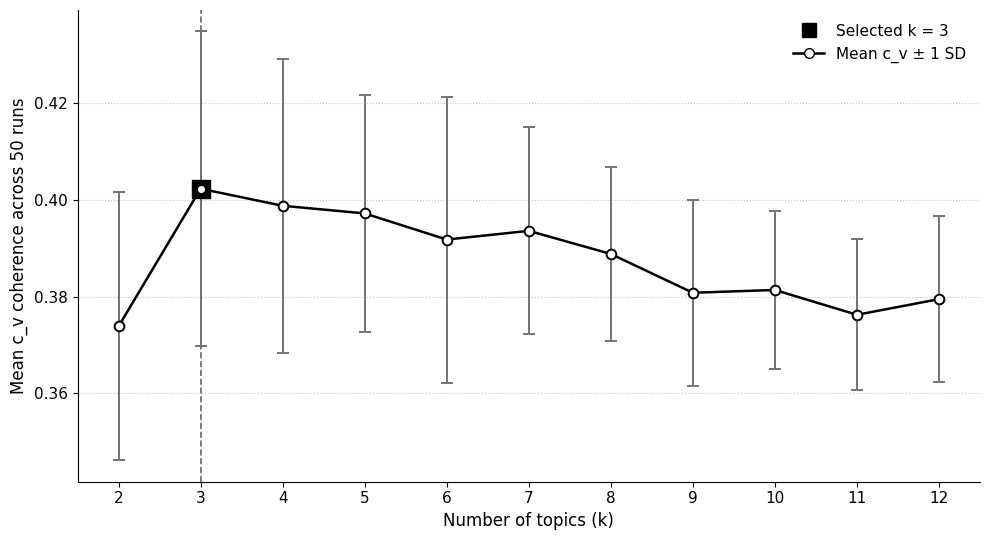

Saved Figure: output/figure2_lda_grayscale.png
Selected k: 3
Mean c_v: 0.402252
SD: 0.032462


In [68]:
# ============================================================
# H3 — FIGURE:
# MULTI-SEED LDA TOPIC-COUNT SELECTION
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Use the final k=2–12 diagnostic dataframe created above
plot_df = (
    h3_topic_count_diagnostics[
        [
            "k",
            "mean_coherence_cv",
            "sd_coherence_cv",
        ]
    ]
    .sort_values("k")
    .reset_index(drop=True)
)

# Use the selected k already determined by the lower-bound check
selected_k = H3_SELECTED_K

selected_row = plot_df.loc[
    plot_df["k"] == selected_k
].iloc[0]


# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.errorbar(
    plot_df["k"],
    plot_df["mean_coherence_cv"],
    yerr=plot_df["sd_coherence_cv"],
    fmt="o-",
    linewidth=1.8,
    markersize=7,
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.4,
    color="black",
    ecolor="0.45",
    elinewidth=1.4,
    capsize=4,
    zorder=2,
)

# Highlight selected k
ax.scatter(
    selected_k,
    selected_row["mean_coherence_cv"],
    marker="s",
    s=150,
    facecolor="black",
    edgecolor="black",
    zorder=3,
)

ax.scatter(
    selected_k,
    selected_row["mean_coherence_cv"],
    marker="o",
    s=38,
    facecolor="white",
    edgecolor="black",
    linewidth=1.1,
    zorder=4,
)

ax.axvline(
    selected_k,
    linestyle="--",
    linewidth=1.2,
    color="0.40",
    zorder=1,
)

ax.set_xlabel("Number of topics (k)", fontsize=12)

ax.set_ylabel(
    "Mean c_v coherence across 50 runs",
    fontsize=12,
)

ax.set_xticks(plot_df["k"].astype(int))

ax.tick_params(
    axis="both",
    labelsize=11,
)

ax.grid(
    axis="y",
    linestyle=":",
    linewidth=0.8,
    color="0.78",
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


legend_handles = [
    Line2D(
        [0],
        [0],
        marker="s",
        linestyle="None",
        markerfacecolor="black",
        markeredgecolor="black",
        markersize=10,
        label=f"Selected k = {selected_k}",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="black",
        markerfacecolor="white",
        markeredgecolor="black",
        linewidth=1.8,
        markersize=7,
        label="Mean c_v ± 1 SD",
    ),
]

ax.legend(
    handles=legend_handles,
    loc="upper right",
    frameon=False,
    fontsize=11,
)

fig.tight_layout()


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

figure2_path = f"{OUT_DIR}/figure2_lda_grayscale.png"

fig.savefig(
    figure2_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Saved Figure: {figure2_path}")
print(f"Selected k: {selected_k}")
print(
    f"Mean c_v: "
    f"{selected_row['mean_coherence_cv']:.6f}"
)
print(
    f"SD: "
    f"{selected_row['sd_coherence_cv']:.6f}"
)